<a href="https://colab.research.google.com/github/CodeHunterOfficial/ArabovMKDeep/blob/main/MLF-2026/%D0%A2%D0%B5%D0%BC%D0%B0_1_%D0%92%D0%B2%D0%B5%D0%B4%D0%B5%D0%BD%D0%B8%D0%B5_%D0%B2_%D0%B0%D0%BD%D0%B0%D0%BB%D0%B8%D0%B7_%D0%B2%D1%80%D0%B5%D0%BC%D0%B5%D0%BD%D0%BD%D1%8B%D1%85_%D1%80%D1%8F%D0%B4%D0%BE%D0%B2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Тема 1. Введение в анализ временных рядов

## 1.1. Определение и основные понятия временных рядов

**Определение 1.1.** *Временным рядом* называется упорядоченная по времени последовательность наблюдений некоторой величины, каждое из которых приурочено к определённому моменту (или интервалу) времени:

$$\{y_t\}_{t \in \mathcal{T}}, \qquad \mathcal{T} \subseteq \mathbb{R} \text{ или } \mathbb{Z},$$

где $t$ — индекс времени, $y_t$ — значение исследуемого показателя в момент $t$, $\mathcal{T}$ — множество моментов наблюдения.

Временные ряды представляют собой один из наиболее распространённых типов данных в современной аналитике. Они лежат в основе изучения и прогнозирования процессов самой разной природы — экономических, метеорологических, финансовых, социальных, промышленных и биомедицинских. В отличие от случайной выборки, где порядок наблюдений несуществен, во временном ряду порядок **принципиален**: перестановка значений разрушает информацию о динамике процесса. Именно поэтому методы классической статистики, предполагающие независимость наблюдений, не применимы к временным рядам «напрямую».

Каждое наблюдение представляет собой одну реализацию случайной величины $Y_t$, распределение которой, вообще говоря, зависит от момента времени $t$. Совокупность случайных величин $\{Y_t\}_{t \in \mathcal{T}}$ называется *случайным процессом*, а конкретный временной ряд $\{y_t\}$ — одной из его реализаций (траекторий). Это фундаментальное отличие анализа временных рядов от классической статистики: мы располагаем единственной траекторией и по ней должны делать выводы о свойствах всего процесса.


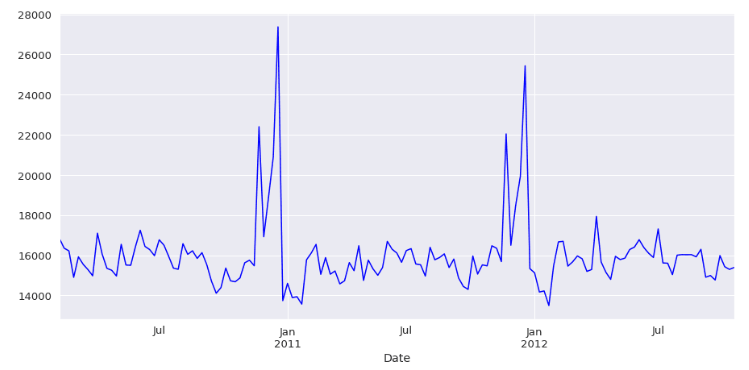


Ниже перечислены основные понятия, используемые при работе с временными рядами.

### 1.1.1. Наблюдение

**Определение 1.2.** *Наблюдением* называется зафиксированное значение исследуемого показателя в конкретный момент времени. Например, для ряда ежедневной температуры:

| Дата | Наблюдение $y_t$ |
|---|---|
| 1 января 2023 г. | 5 °C |
| 2 января 2023 г. | 4 °C |
| 3 января 2023 г. | 6 °C |

Каждое наблюдение фиксируется в определённый момент времени и представляет собой результат измерения или регистрации исследуемой величины. Совокупность всех наблюдений за рассматриваемый период образует временной ряд.

### 1.1.2. Временной промежуток

**Определение 1.3.** *Временным промежутком* (или *шагом дискретизации*) называется интервал между двумя последовательными наблюдениями:

$$\Delta t = t_{i+1} - t_i.$$

В приведённом примере шаг дискретизации равен одному дню: разница между 1 и 2 января — один день, между 2 и 3 января — также один день. Величина, обратная шагу, называется *частотой дискретизации*. Она определяет **разрешение ряда по времени**: чем меньше шаг, тем детальнее видна динамика процесса, но тем больше данных необходимо хранить и обрабатывать.

**Замечание 1.1.** Шаг дискретизации накладывает фундаментальное ограничение на возможный анализ. Согласно **теореме Котельникова–Найквиста**, для корректного восстановления колебаний с периодом $T$ необходимо, чтобы шаг дискретизации был строго меньше $T/2$. Иными словами, если наблюдения производятся раз в сутки, никакой метод не позволит обнаружить закономерность с периодом менее двух суток. Это обстоятельство следует учитывать при планировании сбора данных.

### 1.1.3. Лаг

**Определение 1.4.** *Лагом* называется сдвиг между двумя сравниваемыми моментами времени. Лаг порядка $k$ означает сопоставление значения $y_{t+k}$ со значением $y_t$.

Так, лаг в один день означает сравнение значений сегодняшнего и вчерашнего дня; лаг в семь дней — сопоставление значений, разделённых неделей. Понятие лага лежит в основе анализа автокорреляционной структуры ряда и построения регрессионных признаков.

### 1.1.4. Автокорреляция

**Определение 1.5.** *Автокорреляцией* временного ряда называется корреляционная зависимость между его значениями, сдвинутыми друг относительно друга на $k$ шагов:

$$\rho(k) = \frac{\mathrm{Cov}(y_t,\, y_{t+k})}{\sqrt{\mathrm{Var}(y_t)\,\mathrm{Var}(y_{t+k})}}, \qquad k = 0, 1, 2, \ldots$$

Величина $\rho(k)$ называется *коэффициентом автокорреляции порядка $k$*. При $k = 0$ по определению $\rho(0) = 1$. В приведённом примере с температурой автокорреляция с лагом в один день показывает, насколько сильно температура сегодняшнего дня связана с температурой вчерашнего.

**Замечание 1.2.** Автокорреляция — это мера «памяти» ряда: она характеризует, насколько значение в момент $t$ определяется значением в момент $t - k$. Для сезонных рядов автокорреляционная функция имеет характерные периодические всплески на лагах, кратных периоду сезонности; этот признак широко используется для диагностики сезонности.

---

## 1.2. Типология временных рядов

Временные ряды классифицируются по нескольким **независимым признакам**, каждый из которых отражает определённый аспект их структуры и, соответственно, влияет на выбор методов анализа. Ниже рассмотрены четыре основных признака классификации: по характеру времени, по числу измерений, по регулярности и по статистическим свойствам. Эти признаки **ортогональны**: один и тот же ряд может быть, например, дискретным, одномерным, регулярным и нестационарным одновременно.

Понимание типологии ряда необходимо для **корректного выбора инструментов**: не всякий метод применим к любому типу ряда. Например, спектральный анализ предполагает регулярность; модели ARIMA — стационарность (или возможность её достижения дифференцированием); классические тесты на стационарность плохо работают с многомерными рядами.

### 1.2.1. По характеру времени

**Дискретные ряды.** *Дискретным* называется временной ряд, наблюдения которого фиксируются в **отдельные моменты** времени, как правило, с постоянным шагом. Формально:

$$t_i \in \{t_0 + i \Delta t : i = 0, 1, 2, \ldots\},$$

где $t_0$ — начальный момент наблюдения, $\Delta t$ — шаг дискретизации.

**Примеры:** ежедневная температура воздуха в городе; ежемесячные продажи продукции; квартальные данные о ВВП; почасовое энергопотребление.

Дискретные ряды — **наиболее распространённый** тип данных на практике. С ними работают все классические методы анализа временных рядов: ARIMA, экспоненциальное сглаживание, спектральный анализ, сезонная декомпозиция.

**Непрерывные ряды.** *Непрерывным* называется временной ряд, значения которого определены в **каждый момент** времени:

$$y(t), \quad t \in \mathbb{R}.$$

**Примеры:** сигнал с аналогового датчика температуры; напряжение в электрической сети; звуковой сигнал с микрофона.

**Замечание 1.3.** На компьютере непрерывные ряды **не могут быть представлены напрямую** — они существуют только как математическая абстракция. На практике непрерывный сигнал **дискретизируется**: значения фиксируются через равные интервалы $\Delta t$, образуя дискретный ряд. Согласно **теореме Котельникова–Найквиста**, для корректного восстановления исходного сигнала необходимо, чтобы шаг дискретизации удовлетворял условию:

$$\Delta t < \frac{1}{2 f_{\max}},$$

где $f_{\max}$ — максимальная частота в спектре сигнала. Если это условие нарушено, возникает **наложение частот (aliasing)** — эффект, при котором высокочастотные компоненты маскируются под низкочастотные и безвозвратно искажают ряд.

### 1.2.2. По числу измерений

**Одномерные ряды.** *Одномерным* называется временной ряд, в каждый момент времени которого фиксируется **одно скалярное значение**:

$$\{y_t\}_{t \in \mathcal{T}}, \quad y_t \in \mathbb{R}.$$

Одномерные ряды — базовый объект классической теории временных рядов. Примеры: ежедневная температура, курс доллара к рублю, объём продаж одного товара.

**Многомерные ряды.** *Многомерным* называется временной ряд, в каждый момент времени которого фиксируется **вектор значений**:

$$\{\mathbf{y}_t\}_{t \in \mathcal{T}}, \quad \mathbf{y}_t = (y_t^{(1)}, y_t^{(2)}, \ldots, y_t^{(m)}) \in \mathbb{R}^m,$$

где $m$ — размерность вектора (число компонент), $y_t^{(j)}$ — значение $j$-й компоненты в момент $t$.

**Примеры:** погодная станция, регистрирующая температуру, влажность, давление и скорость ветра одновременно ($m = 4$); многоканальная ЭЭГ-запись; данные о продажах нескольких товаров в одном магазине; показатели одного предприятия: выручка, издержки, число сотрудников.

**Замечание 1.4.** Многомерные ряды обладают **дополнительной структурой**, недоступной одномерному анализу: между компонентами могут существовать **взаимные корреляции** (cross-correlations), позволяющие строить более точные прогнозы. Для анализа многомерных рядов используются:

- **VAR** (Vector Autoregression) — векторная авторегрессия;
- **VECM** (Vector Error Correction Model) — модель коррекции ошибок (для коинтегрированных рядов);
- **State-space models** — модели в пространстве состояний;
- **нейронные сети** с несколькими входами и выходами.

При этом важно различать **многомерный ряд** (вектор значений в каждый момент) и **многоканальный ряд** (несколько независимых одномерных рядов, анализируемых параллельно). В первом случае компоненты **связаны единым процессом**; во втором — могут быть независимы.

### 1.2.3. По регулярности

**Регулярные ряды.** *Регулярным* называется временной ряд, интервалы между последовательными наблюдениями которого **постоянны**:

$$t_{i+1} - t_i = \Delta t = \mathrm{const}, \quad \forall i.$$

Классический случай: ежедневные, ежемесячные, квартальные данные с фиксированным шагом.

**Нерегулярные ряды.** *Нерегулярным* называется временной ряд, интервалы между последовательными наблюдениями которого **различны**:

$$t_{i+1} - t_i \neq \mathrm{const}.$$

**Примеры:** поток заявок в службу поддержки (заявки приходят в случайные моменты); сделки на бирже (фиксируются по факту совершения); данные с датчиков, передающих показания при изменении значения (event-driven telemetry).

**Замечание 1.5.** Большинство классических методов анализа временных рядов (ARIMA, экспоненциальное сглаживание, спектральный анализ) **предполагают регулярность** ряда. Для нерегулярных рядов применяются два подхода:

1. **Агрегация к регулярному виду.** Данные группируются по фиксированным интервалам (час, день, неделя); значения в интервале суммируются, усредняются или берётся последнее известное. Например, поток заявок можно превратить в ряд «число заявок за час».

2. **Методы для непрерывного времени.** Используются точечные процессы (Poisson, Hawkes) и модели в непрерывном времени, которые не требуют регулярности.

**Замечание 1.6.** Агрегация нерегулярного ряда к регулярному **приводит к потере информации** о точных моментах наблюдений. Например, если 100 заявок пришло в течение часа, ряд «100 заявок за час» не различает случаи «100 заявок равномерно по часу» и «100 заявок в первые 5 минут». Если точное время важно — агрегация недопустима, и следует применять методы непрерывного времени.

### 1.2.4. По статистическим свойствам

**Стационарные ряды.** Временной ряд $\{y_t\}$ называется *(слабо) стационарным*, если его первые два момента не зависят от времени:

$$\mathbb{E}[y_t] = \mu = \mathrm{const}, \qquad \mathrm{Var}(y_t) = \sigma^2 = \mathrm{const}, \qquad \mathrm{Cov}(y_t, y_{t+k}) = \gamma(k).$$

Иначе говоря:

1. **среднее** ряда постоянно во времени;
2. **дисперсия** постоянна во времени;
3. **автоковариация** зависит только от **разности моментов** (лага $k$), но не от самих моментов.

**Замечание 1.7.** Различают два уровня стационарности:

- **Слабая (в широком смысле)** — постоянны первые два момента. Именно это определение используется в подавляющем большинстве прикладных задач.
- **Строгая (в узком смысле)** — совместное распределение $(y_{t_1}, \ldots, y_{t_k})$ инвариантно относительно сдвига по времени. Это более сильное требование, на практике проверяется редко.

**Нестационарные ряды.** Ряд называется *нестационарным*, если хотя бы одно из условий стационарности нарушено.

**Замечание 1.8.** Большинство **реальных** временных рядов нестационарны. Основные источники нестационарности:

- **тренд** — систематическое изменение среднего уровня (например, рост ВВП, глобальное потепление);
- **сезонность** — периодические колебания (например, годовой цикл температуры);
- **сдвиги уровня** — резкие изменения среднего (например, после смены тарифов, регуляторных решений);
- **гетероскедастичность** — изменение дисперсии во времени (например, кластеры волатильности на финансовых рынках).

**Замечание 1.9.** Стационарность — **ключевое предположение** большинства моделей временных рядов: ARMA, ARIMA (после дифференцирования), спектральный анализ, тесты на единичный корень. Если ряд нестационарен, перед моделированием его **приводят к стационарному виду** одним из способов:

| Тип нестационарности | Метод приведения |
|---|---|
| Тренд | Дифференцирование ($y_t - y_{t-1}$) или вычитание тренда |
| Сезонность | Сезонное дифференцирование ($y_t - y_{t-s}$) |
| Гетероскедастичность | Логарифмирование, преобразование Бокса–Коула |
| Сдвиг уровня | Модели с фиктивными переменными, интервенционный анализ |

**Замечание 1.10.** Интуитивный смысл требования стационарности: если статистические свойства ряда «сдвигаются» во времени, **никакая фиксированная модель не сможет их описать**. Модель, обученная на одном участке ряда, окажется неприменимой на другом. Приведение к стационарному виду «выравнивает» статистические свойства, делая ряд однородным во времени.

**Замечание 1.11.** Различают два принципиально разных типа нестационарности, требующих **разных** методов обработки:

- **DS-ряд** (Difference Stationary) — нестационарен из-за **стохастического тренда** (единичного корня). Приводится к стационарному **дифференцированием**. Типичный пример — курс акции.
- **TS-ряд** (Trend Stationary) — нестационарен из-за **детерминированного тренда**. Приводится к стационарному **вычитанием тренда** (например, регрессией на $t$). Типичный пример — выпуск продукции с устойчивым ростом.

Различение этих двух типов — **отдельная задача**, решаемая тестами Дики–Фуллера и KPSS (см. раздел «Предварительный анализ»). Неправильный выбор метода обработки приводит к **ошибочным прогнозам**.

**Пример 1.2.** Проиллюстрируем различие между стационарным и нестационарным рядами:



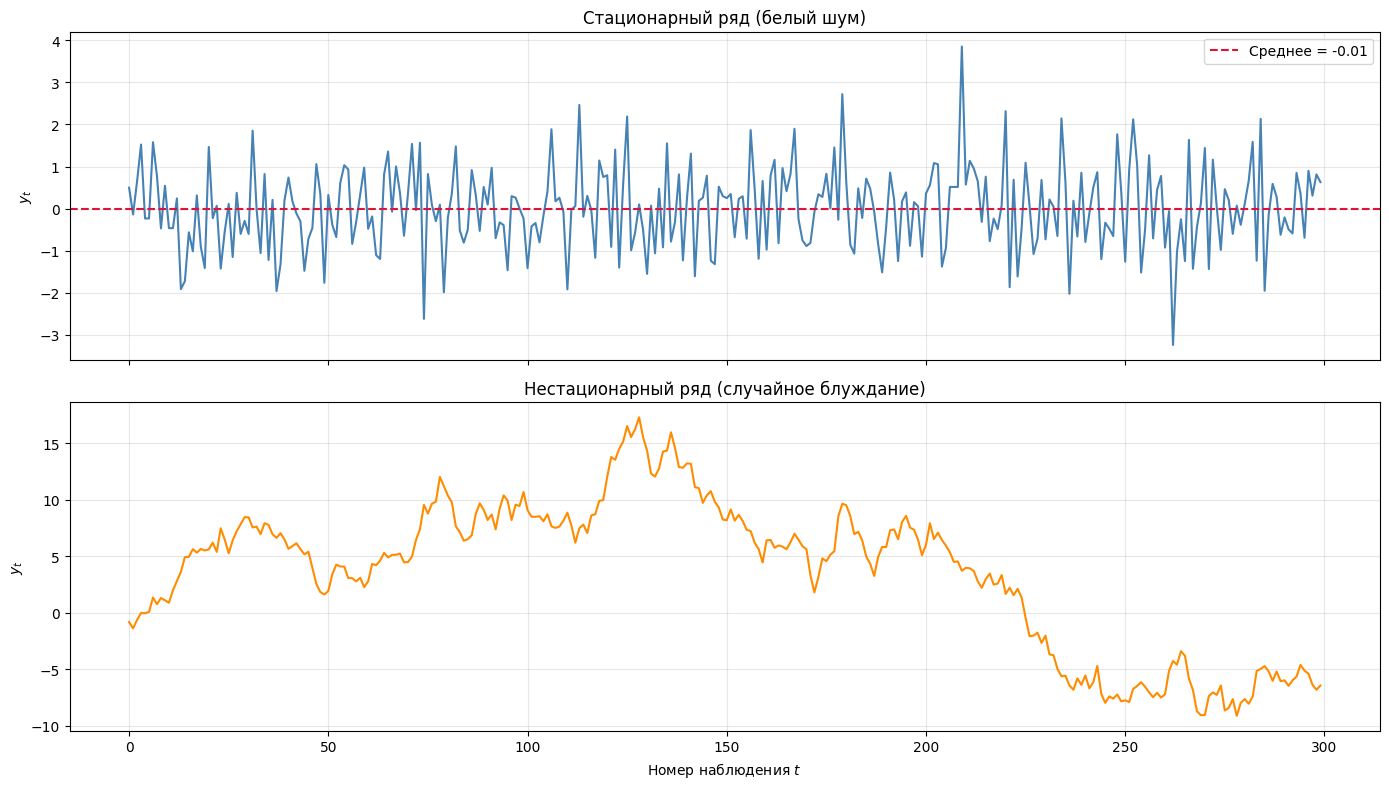

In [64]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
n = 300

# Стационарный ряд: белый шум
stationary = np.random.normal(loc=0, scale=1, size=n)

# Нестационарный ряд: случайное блуждание (единичный корень)
nonstationary = np.cumsum(np.random.normal(loc=0, scale=1, size=n))

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(stationary, color='steelblue')
axes[0].axhline(stationary.mean(), color='crimson',
                linestyle='--', label=f'Среднее = {stationary.mean():.2f}')
axes[0].set_title('Стационарный ряд (белый шум)')
axes[0].set_ylabel('$y_t$')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(nonstationary, color='darkorange')
axes[1].set_title('Нестационарный ряд (случайное блуждание)')
axes[1].set_ylabel('$y_t$')
axes[1].set_xlabel('Номер наблюдения $t$')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


**Интерпретация.** На верхнем графике ряд колеблется вокруг постоянного уровня — это визуальный признак стационарности. На нижнем графике уровень ряда **систематически смещается**: ряд «блуждает» вверх-вниз без якоря. Такой ряд **нестационарен** и требует дифференцирования перед моделированием.

### 1.2.5. Сводная таблица типологии

**Таблица 1.1.** Типология временных рядов по четырём признакам

| Признак | Категория | Пример | Методы анализа |
|---|---|---|---|
| **Характер времени** | Дискретный | Ежедневная температура | ARIMA, SARIMA, спектр |
| | Непрерывный | Аналоговый сигнал | Требует дискретизации |
| **Число измерений** | Одномерный | Курс валюты | ARIMA, экспоненциальное сглаживание |
| | Многомерный | Погодная станция ($T$, $H$, $P$) | VAR, VECM, state-space |
| **Регулярность** | Регулярный | Ежемесячные продажи | Классические методы |
| | Нерегулярный | Поток заявок | Точечные процессы, агрегация |
| **Статистические свойства** | Стационарный | Белый шум | ARMA, спектр |
| | Нестационарный | Курс акции | ARIMA, дифференцирование |

**Замечание 1.12.** Типология **не является жёсткой**: один и тот же ряд может быть отнесён к разным категориям в зависимости от задачи. Например, поток заявок (нерегулярный) может быть **агрегирован** до регулярного ряда «число заявок в час»; многомерный ряд может быть **проанализирован покомпонентно** как набор одномерных (с потерей информации о взаимных связях). Выбор уровня абстракции определяется **целью анализа**.

### 1.2.6. Практическая значимость типологии

Типология временных рядов — не формальная классификация, а **инструмент выбора методов анализа**. Приступая к работе с новым рядом, аналитик должен ответить на четыре вопроса:

1. **Дискретный или непрерывный?** — если непрерывный, нужна дискретизация; выбор шага критичен (теорема Котельникова–Найквиста).
2. **Одномерный или многомерный?** — если многомерный, следует рассмотреть возможность использования взаимных корреляций (VAR, state-space).
3. **Регулярный или нерегулярный?** — если нерегулярный, необходимо решить: агрегировать или применять методы непрерывного времени.
4. **Стационарный или нестационарный?** — если нестационарный, требуется предварительная обработка (дифференцирование, вычитание тренда, логарифмирование).

Ответы на эти вопросы **сужают класс применимых моделей** и предотвращают типичные ошибки: попытки применить ARIMA к нерегулярному ряду, спектральный анализ к нестационарному, или классические тесты к многомерным рядам без учёта взаимных корреляций.

---

## 1.3. Компоненты временных рядов

Любой временной ряд может быть представлен в виде совокупности нескольких компонент, отражающих разные по природе механизмы формирования значений. Разложение на компоненты позволяет упростить анализ, выделить содержательные закономерности и построить более эффективные прогнозные модели.

### 1.3.1. Тренд

**Определение 1.18.** *Трендом* $T_t$ называется плавное долговременное изменение среднего уровня ряда, не связанное с сезонными или циклическими колебаниями.

Типичный пример тренда — устойчивый рост средней температуры на планете за десятилетия, увеличение ВВП страны год от года или снижение стоимости электроники по мере технологического развития. Тренд может быть **линейным** ($T_t = a + bt$), **полиномиальным** ($T_t = a + bt + ct^2$) или **нелинейным** более сложной формы. Наличие тренда делает ряд нестационарным, что требует специальной обработки перед применением большинства статистических методов.

### 1.3.2. Сезонность

**Определение 1.19.** *Сезонностью* $S_t$ называются регулярные колебания ряда с фиксированным периодом $s$, повторяющиеся из цикла в цикл.

Типичные примеры: увеличение продаж перед новогодними праздниками, рост потребления электроэнергии в вечерние часы, сезонный характер заболеваемости гриппом. Период сезонности $s$ определяется природой процесса и может составлять сутки, неделю, месяц, квартал или год. Ряды с несколькими наложенными сезонными компонентами называются рядами с **многократной сезонностью** (например, потребление электроэнергии одновременно имеет суточную, недельную и годовую сезонность).

### 1.3.3. Циклы

**Определение 1.20.** *Циклами* называются нерегулярные колебания ряда с переменной амплитудой и переменным периодом, обусловленные внешними по отношению к ряду причинами.

Примерами служат экономические циклы (кризис — рост — рецессия — оживление), технологические циклы (появление новой технологии, её распространение, насыщение рынка), политические циклы. В отличие от сезонности, циклы не имеют фиксированного периода и, как правило, хуже прогнозируемы.

**Замечание 1.13.** Принципиальное отличие сезонности от циклов заключается в следующем: сезонность имеет строго фиксированный период и повторяется из года в год, тогда как циклы — нерегулярны и связаны с внешними обстоятельствами. Сезонность может быть надёжно экстраполирована на будущее, циклы — лишь частично.

### 1.3.4. Случайная компонента

**Определение 1.21.** *Случайной (нерегулярной) компонентой* $R_t$ называется часть ряда, которая не может быть объяснена трендом, сезонностью или циклами.

Это шумовая составляющая ряда, обусловленная множеством мелких факторов: влияние стихийных бедствий на погоду, случайные колебания спроса, погрешности измерений. Случайная компонента может содержать слабую автокорреляцию; полностью непредсказуемая её часть называется *«белым шумом»* и служит эталоном качества прогнозной модели: хорошая модель должна оставлять в остатках именно белый шум.

### 1.3.5. Формы декомпозиции

Совокупность компонент может быть объединена в единую модель двумя способами:

- **аддитивная модель:** $y_t = T_t + S_t + R_t$;
- **мультипликативная модель:** $y_t = T_t \times S_t \times R_t$.

Аддитивная форма используется, когда амплитуда сезонных колебаний приблизительно постоянна; мультипликативная — когда амплитуда пропорциональна уровню ряда (типично для продаж). Мультипликативную модель можно свести к аддитивной логарифмированием:

$$\log y_t = \log T_t + \log S_t + \log R_t.$$

---

## 1.4. Источники данных временных рядов

Источники временных рядов чрезвычайно разнообразны. Ниже приведена их классификация по областям применения.

### 1.4.1. Экономические и финансовые данные

Данные этой категории включают макроэкономические показатели (ВВП, инфляция, уровень безработицы), финансовые индикаторы (курсы валют, индексы фондовых рынков, доходности облигаций) и микроэкономические показатели (продажи, издержки, объёмы заказов). Пример квартального ряда ВВП:

| Период | ВВП, млрд долл. |
|---|---|
| Q1 2023 | 1200 |
| Q2 2023 | 1250 |
| Q3 2023 | 1230 |

Финансовые ряды характеризуются высокой волатильностью и нестабильной дисперсией, что требует применения специализированных моделей (GARCH и их модификации).

### 1.4.2. Метеорологические данные

К этой категории относятся ряды температуры, осадков, скорости ветра, атмосферного давления. Пример месячных осадков:

| Месяц | Осадки, мм |
|---|---|
| Январь 2023 | 50 |
| Февраль 2023 | 40 |
| Март 2023 | 60 |

Метеорологические ряды часто обладают многократной сезонностью (суточной, недельной, годовой), содержат выраженные выбросы, связанные с экстремальными погодными явлениями, и долговременные тренды (например, глобальное потепление).

### 1.4.3. Социальные данные

Социальные ряды описывают демографические и общественные процессы: уровень безработицы, рождаемость, смертность, миграцию, рейтинги, индексы потребительского доверия. Пример уровня безработицы:

| Месяц | Безработица, % |
|---|---|
| Январь 2023 | 5,0 |
| Февраль 2023 | 4,8 |
| Март 2023 | 5,2 |

Для таких рядов характерны медленные тренды и умеренная сезонность, связанная с календарными циклами занятости.

### 1.4.4. Промышленные данные

Промышленные ряды включают объёмы производства, продаж, запасов, а также данные телеметрии оборудования (температура, вибрация, давление). Пример производства автомобилей:

| Месяц | Автомобилей, шт. |
|---|---|
| Январь 2023 | 10 000 |
| Февраль 2023 | 10 500 |
| Март 2023 | 11 000 |

Промышленные ряды часто имеют высокую частоту дискретизации (секунды, миллисекунды) и требуют специализированных средств хранения и обработки (InfluxDB, TimescaleDB, потоковые вычислительные системы).

---

## 1.5. Примеры временных рядов

Рассмотрим два классических примера, широко используемых в учебной литературе и иллюстрирующих основные типы структур временных рядов.

### 1.5.1. Пример 1. Ежемесячные продажи антидиабетических лекарств в Австралии

**Описание.** Временной ряд содержит данные о ежемесячных продажах антидиабетических препаратов в Австралии за период с июля 1991 года по июнь 2008 года (источник — открытый датасет `AusAntidiabeticDrug`, входящий в состав библиотеки `statsmodels`).

**Основные характеристики ряда:**

| Параметр | Значение |
|---|---|
| Предметная область | Фармацевтика |
| Показатель | Продажи, млн австралийских долларов |
| Частота дискретизации | Ежемесячная |
| Длина ряда | 204 наблюдения (17 лет) |

**Структурные особенности.** На графике ряда отчётливо наблюдаются две систематические компоненты:

1. **Возрастающий нелинейный тренд.** Средний уровень продаж устойчиво растёт с течением времени, что объясняется ростом распространённости диабета, старением населения и расширением государственных программ медицинской помощи. Нелинейность тренда свидетельствует о постепенном замедлении темпов роста по мере насыщения рынка.

2. **Годовая сезонность** с периодом $s = 12$ месяцев. Пики продаж приходятся на определённые месяцы и повторяются из года в год. При этом **амплитуда сезонных колебаний растёт вместе с уровнем ряда**, что указывает на необходимость использования **мультипликативной формы декомпозиции**:

$$y_t = T_t \times S_t \times R_t.$$

Случайная компонента $R_t$ присутствует, но её вклад невелик по сравнению с трендом и сезонностью; это означает, что ряд обладает высокой прогнозируемостью.

**Методологическое значение примера.** Данный ряд служит эталонной иллюстрацией тренд-сезонной структуры и мультипликативности. На нём удобно демонстрировать преимущества логарифмического преобразования: после перехода к $z_t = \log y_t$ амплитуда сезонных колебаний становится приблизительно постоянной, что позволяет применять аддитивные модели (STL, SARIMA на логарифмах). Рекомендуемые классы моделей для данного ряда — SARIMA, модель Хольта–Уинтерса, Prophet.


Text(0.5, 1.0, 'AntiDiabetic Drug Sales in Australia')

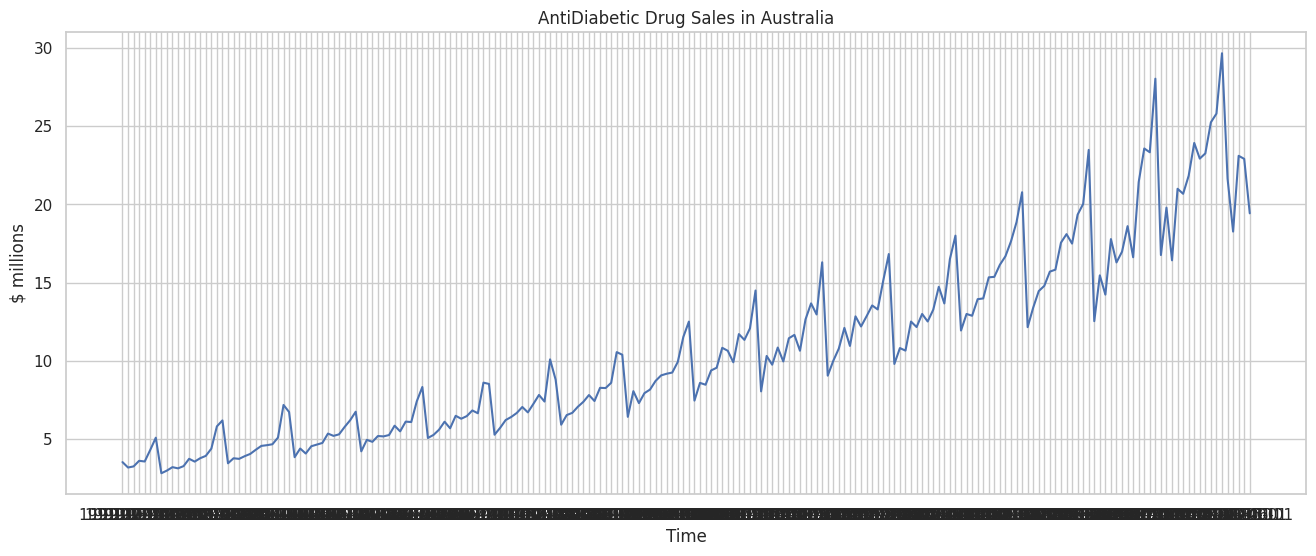

In [ ]:
#Basic importation
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rc('xtick', labelsize=40)
matplotlib.rc('ytick', labelsize=40)

import seaborn as sns
sns.set(style="whitegrid", color_codes=True)
%matplotlib inline
ts= pd.read_csv('/content/AusAntidiabeticDrug.csv')

plt.figure(figsize=(16,6))
plt.plot(ts["ds"],ts["y"])
plt.xlabel("Time")
plt.ylabel("$ millions")
plt.title("AntiDiabetic Drug Sales in Australia")


### 1.5.2. Пример 2. Максимальный спрос на электроэнергию в штате Виктория

**Описание.** Второй пример — ряд максимального спроса на электроэнергию в штате Виктория (Австралия), регистрируемый с 30-минутными интервалами начиная с 10 января 2000 года в течение 115 дней.

**Основные характеристики ряда:**

| Параметр | Значение |
|---|---|
| Предметная область | Энергетика |
| Показатель | Спрос на электроэнергию, МВт |
| Частота дискретизации | 30 минут |
| Длина ряда | 5520 наблюдений (115 дней) |

**Структурные особенности.** На графике отчётливо видны две наложенные сезонные компоненты:

1. **Суточная сезонность** с периодом $s_1 = 48$ получасовых интервалов (24 часа). Потребление минимально в ночные часы и максимально днём и вечером, что обусловлено суточным ритмом жизнедеятельности человека.

2. **Недельная сезонность** с периодом $s_2 = 336$ получасовых интервалов (7 суток). Потребление систематически выше по будням (промышленность, офисы) и ниже в выходные.

Поскольку ряд охватывает лишь 115 дней, годовая сезонность в нём не проявляется. При анализе данных за несколько лет обнаружилась бы **третья сезонная компонента** с периодом $s_3 = 365 \times 48 = 17\,520$ интервалов, связанная с сезонным использованием кондиционеров и систем отопления.

**Методологическое значение примера.** Данный ряд демонстрирует **многократную сезонность** — ситуацию, при которой в ряде одновременно присутствуют сезонные компоненты разных порядков. Стандартные методы (ARIMA, SARIMA с единственным сезонным периодом) не справляются с такой структурой; требуются модели с многократной сезонностью: MSTL, TBATS, Prophet с несколькими сезонными компонентами. Кроме того, спрос на электроэнергию существенно зависит от экзогенных факторов (температуры, осадков), что делает данный ряд естественным примером для моделей с внешними регрессорами (ARIMAX, SARIMAX).

**Практическая значимость.** Задача краткосрочного прогнозирования нагрузки энергосистем — одна из наиболее востребованных прикладных задач анализа временных рядов. На её основе решаются задачи планирования генерации, оптимизации закупок на оптовом рынке, управления нагрузкой (demand response).

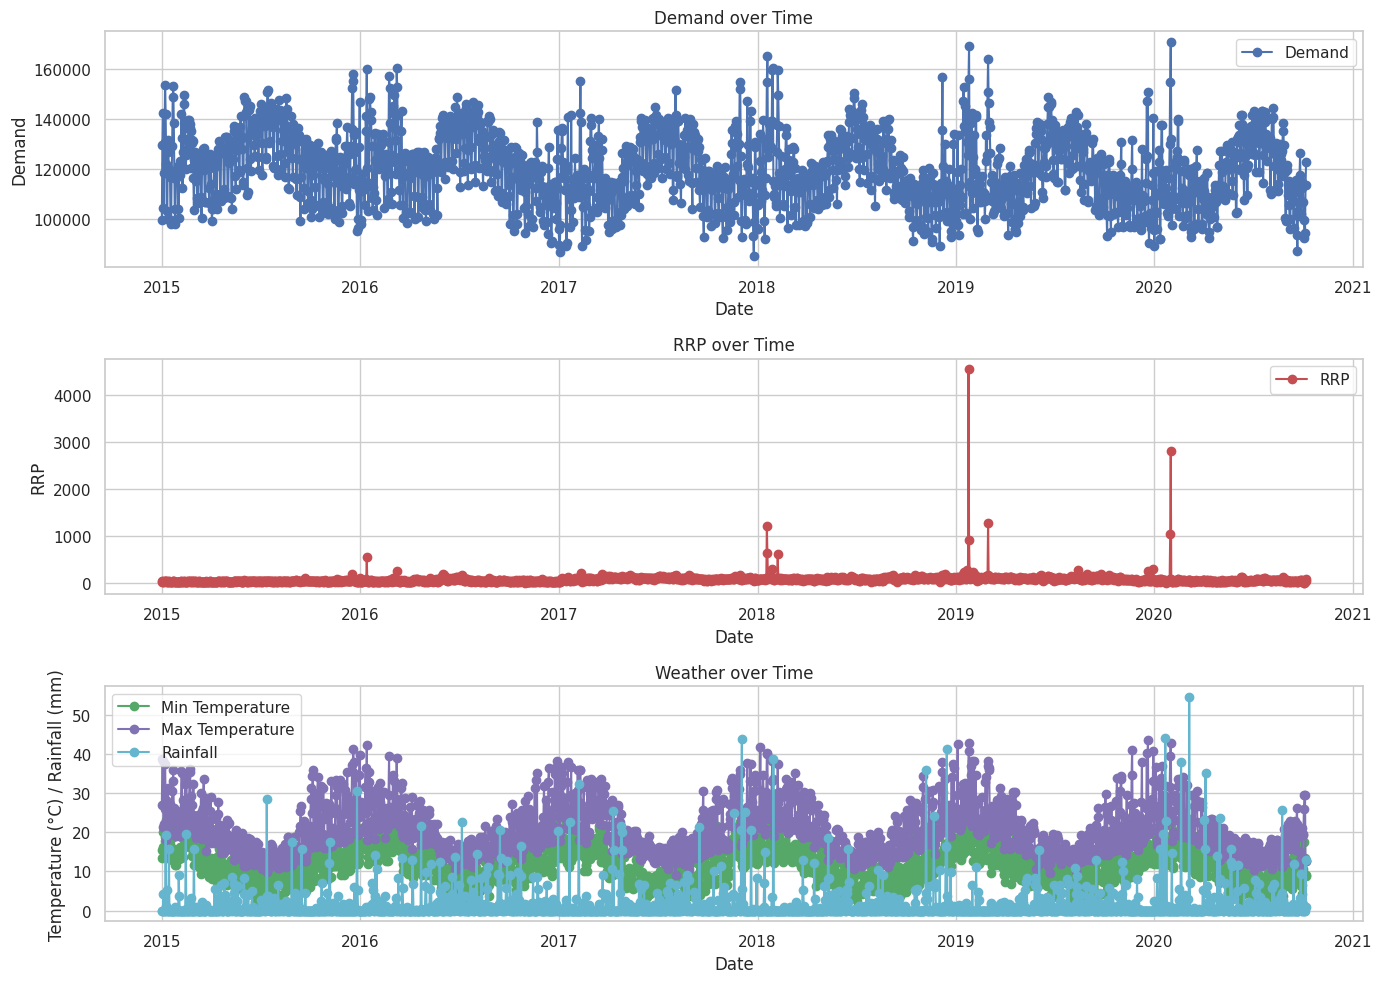

In [ ]:
df = pd.read_csv('/content/complete_dataset.csv')

df['date'] = pd.to_datetime(df['date'])  # Convert date column to datetime format

# Plotting
plt.figure(figsize=(14, 10))

# Plot demand
plt.subplot(3, 1, 1)
plt.plot(df['date'], df['demand'], marker='o', linestyle='-', color='b', label='Demand')
plt.title('Demand over Time')
plt.xlabel('Date')
plt.ylabel('Demand')
plt.grid(True)
plt.legend()

# Plot RRP
plt.subplot(3, 1, 2)
plt.plot(df['date'], df['RRP'], marker='o', linestyle='-', color='r', label='RRP')
plt.title('RRP over Time')
plt.xlabel('Date')
plt.ylabel('RRP')
plt.grid(True)
plt.legend()

# Plot temperatures and rainfall
plt.subplot(3, 1, 3)
plt.plot(df['date'], df['min_temperature'], marker='o', linestyle='-', color='g', label='Min Temperature')
plt.plot(df['date'], df['max_temperature'], marker='o', linestyle='-', color='m', label='Max Temperature')
plt.plot(df['date'], df['rainfall'], marker='o', linestyle='-', color='c', label='Rainfall')
plt.title('Weather over Time')
plt.xlabel('Date')
plt.ylabel('Temperature (°C) / Rainfall (mm)')
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

# 1.6. Хранение временных рядов

## 1.6.1. Введение

Хранение данных временных рядов играет **ключевую роль** в их анализе, прогнозировании и использовании для принятия решений в самых разных областях: финансах, метеорологии, здравоохранении, промышленности, энергетике и технологиях. В отличие от хранения статических табличных данных, хранение временных рядов имеет ряд **специфических особенностей**, обусловленных следующими факторами:

1. **Большой объём.** Ряды с секундной или миллисекундной дискретизацией могут содержать миллиарды наблюдений. Например, данные с одного IoT-датчика, опрашиваемого 100 раз в секунду, дают около 8,6 млн записей в сутки.
2. **Упорядоченность по времени.** Каждая запись привязана к моменту времени, и порядок записей принципиален.
3. **Преимущественно последовательный доступ.** Аналитик чаще всего запрашивает **непрерывные интервалы** ряда (например, «все данные за март»), а не произвольные строки.
4. **Высокая скорость поступления.** В задачах мониторинга данные поступают непрерывно; задержка записи недопустима.
5. **Необходимость агрегации.** Часто требуется хранить не только «сырые» данные, но и агрегаты (средние за час, максимумы за день).

В настоящем разделе рассмотрены основные аспекты хранения временных рядов: формат данных, структура таблиц, частота наблюдений, учёт временны́х зон, сжатие, индексация, безопасность, а также задача приведения рядов из разных временны́х зон к единой шкале.

---

## 1.6.2. Формат данных временных рядов

### 1.6.2.1. Базовая структура «время — значение»

**Определение 1.22.** Временной ряд в хранилище представляется в виде **упорядоченной по времени совокупности пар** $(t_i, y_i)$, где $t_i$ — временна́я метка (timestamp), а $y_i$ — соответствующее значение ряда.

Простейший формат хранения — плоская таблица:

| Время | Температура, °C |
|---|---|
| 2023-01-01 00:00 | 5 |
| 2023-01-01 01:00 | 4 |
| 2023-01-01 02:00 | 6 |
| … | … |

Такой формат:

- **универсален** — применим к любому временному ряду;
- **прост** для чтения и записи;
- **естественно поддерживает** последовательный доступ к интервалам;
- **легко агрегируется** — сгруппировать по часу, дню, месяцу можно стандартными SQL-запросами.

### 1.6.2.2. Расширенные форматы

На практике «плоский» формат часто дополняется дополнительными столбцами:

- **идентификатор объекта** — например, `sensor_id` или `city_id`, если в одной таблице хранятся ряды нескольких объектов;
- **атрибуты наблюдения** — точность измерения, флаг качества, источник данных;
- **метаданные** — единицы измерения, описание, ответственный за сбор.

**Пример 1.3.** Расширенная таблица для хранения данных с нескольких метеостанций:

| timestamp | station_id | temperature | humidity | pressure | quality |
|---|---|---|---|---|---|
| 2023-01-01 00:00 | MSK-01 | 5.0 | 80 | 1013 | OK |
| 2023-01-01 00:00 | SPB-01 | 2.5 | 85 | 1010 | OK |
| 2023-01-01 01:00 | MSK-01 | 4.5 | 81 | 1013 | OK |
| 2023-01-01 01:00 | SPB-01 | 2.0 | 87 | 1009 | WARN |

Такой формат называется **«длинным» (long format)**: каждое наблюдение — отдельная строка. Он удобен для хранения, но менее удобен для анализа, где чаще нужен **«широкий» формат** (wide format), в котором каждая компонента ряда — отдельный столбец.

### 1.6.2.3. Форматы файлов

Для хранения на диске используются различные форматы:

| Формат | Особенности | Применение |
|---|---|---|
| **CSV** | Текстовый, универсальный, но объёмный | Небольшие ряды, обмен данными |
| **Parquet** | Колоночный, сжатие, поддерживает типы | Аналитические задачи, большие ряды |
| **HDF5** | Иерархический, поддерживает метаданные | Научные вычисления, многомерные данные |
| **Feather** | Быстрый обмен с pandas/R | Промежуточное хранение |
| **ORC** | Колоночный, оптимизирован для Hadoop | Big Data |

**Замечание 1.14.** Для временных рядов **колоночные форматы** (Parquet, ORC) предпочтительнее, поскольку аналитические запросы обычно обращаются к **нескольким столбцам** (время, значение) на **большом интервале времени**. Колоночное хранение позволяет читать только нужные столбцы и эффективно сжимать монотонные последовательности меток времени.

---

## 1.6.3. Структура данных и таблицы

### 1.6.3.1. Реляционная модель

В классических реляционных СУБД временной ряд хранится в таблице, каждая строка которой — отдельное наблюдение:

```sql
CREATE TABLE temperature (
    timestamp   TIMESTAMP   NOT NULL,
    station_id  VARCHAR(32) NOT NULL,
    temperature FLOAT,
    PRIMARY KEY (station_id, timestamp)
);
```

**Пояснения к структуре:**

- `timestamp` — временна́я метка (без учёта временно́й зоны или с учётом — см. раздел 1.6.4);
- `station_id` — идентификатор объекта (если хранятся ряды нескольких объектов);
- `temperature` — значение ряда;
- `PRIMARY KEY (station_id, timestamp)` — составной первичный ключ, обеспечивающий **уникальность** наблюдения в рамках объекта и ускоряющий выборку по времени.

### 1.6.3.2. Специализированные СУБД для временных рядов

Классические реляционные СУБД (PostgreSQL, MySQL) **справляются** с хранением временных рядов, но при больших объёмах становятся неэффективными. Для таких случаев разработаны **специализированные time-series СУБД**:

| СУБД | Особенности | Применение |
|---|---|---|
| **InfluxDB** | Собственный язык запросов (Flux), агрегация «на лету» | Мониторинг, IoT |
| **TimescaleDB** | Расширение PostgreSQL, поддержка SQL | Промышленная аналитика |
| **Prometheus** | Pull-модель сбора, язык PromQL | Мониторинг микросервисов |
| **ClickHouse** | Колоночная СУБД, высокая скорость агрегации | Аналитика больших данных |
| **QuestDB** | Высокая скорость записи, SQL | Финансы, трейдинг |

**Замечание 1.15.** Ключевые особенности time-series СУБД:

1. **Автоматическое партиционирование по времени** — данные разбиваются на «чанки» (например, по месяцам), что ускоряет запросы к конкретным интервалам.
2. **Сжатие по столбцам** — временны́е метки и значения сжимаются отдельно, часто с потерями, но с сохранением точности агрегатов.
3. **Continuous aggregates (непрерывные агрегаты)** — автоматически поддерживаемые материализованные представления (среднее за час, максимум за день).
4. **Политики хранения (retention policies)** — автоматическое удаление старых данных по истечении срока хранения.

### 1.6.3.3. Нормализация и денормализация

**Нормализованная схема** — каждая компонента ряда хранится в отдельной таблице, метаданные — в справочниках. Это уменьшает дублирование, но увеличивает число соединений.

**Денормализованная схема** — все данные хранятся в одной «широкой» таблице. Это увеличивает скорость чтения, но требует больше места.

Для временных рядов часто применяют **гибридный** подход: справочник объектов отдельно, данные — в широкой таблице с идентификатором объекта.

---

## 1.6.4. Частота наблюдений

**Определение 1.23.** *Частотой наблюдений* (или *частотой дискретизации*) называется величина, обратная шагу дискретизации $f_s = 1/\Delta t$.

Частота наблюдений определяется **природой процесса** и **задачами анализа**:

| Частота | Шаг | Типичные применения |
|---|---|---|
| Высокая (кГц, МГц) | мкс, мс | Сейсмология, аудио, телеметрия оборудования |
| Средняя (Гц) | с | Мониторинг серверов, IoT-датчики |
| Низкая (мин, ч) | мин, ч | Энергетика, финансы, метеорология |
| Дневная | сутки | Розничные продажи, метеоданные |
| Месячная | месяц | Макроэкономика, отчётность |
| Квартальная, годовая | квартал, год | ВВП, демография |

**Замечание 1.16.** Выбор частоты наблюдений — **компромисс** между:

- **детализацией** (чем чаще, тем больше информации);
- **объёмом хранилища** (объём данных растёт линейно с частотой);
- **скоростью обработки** (анализ высокочастотных рядов требует больше вычислительных ресурсов);
- **теоремой Котельникова–Найквиста** (шаг должен быть меньше половины минимального периода исследуемых колебаний).

**Замечание 1.17.** Один и тот же процесс может храниться с **несколькими частотами одновременно**:

- **«сырые» данные** — с максимальной частотой (для детального анализа и аудита);
- **агрегированные данные** — с часовой, дневной, месячной частотой (для быстрого анализа).

Такая многоуровневая архитектура называется **иерархией агрегации** и реализуется либо вручную, либо средствами time-series СУБД (continuous aggregates).

---

## 1.6.5. Учёт временных зон и дополнительных атрибутов

### 1.6.5.1. Временны́е зоны

**Замечание 1.18.** Если данные поступают из **разных временны́х зон**, хранение метки времени без указания зоны приводит к **неоднозначности**. Например, метка `2023-01-01 12:00` может означать:

- 12:00 по Москве (UTC+3);
- 12:00 по Нью-Йорку (UTC−5);
- 12:00 по Токио (UTC+9).

Разница между этими моментами — **до 14 часов**, что критично для многих задач (например, при анализе потоков данных в реальном времени).

**Определение 1.24.** Временна́я метка называется *zone-aware* (с информацией о зоне), если она хранится вместе с указанием временно́й зоны или смещения от UTC. В противном случае метка называется *naive* (наивной).

**Замечание 1.19.** Рекомендуемая практика:

1. **Хранить** все метки времени в **UTC** (zone-aware или приведённые к UTC).
2. **Преобразовывать** в локальное время **только при отображении** пользователю.
3. **Хранить** исходную временну́ю зону **отдельно** — как атрибут объекта (например, столбец `timezone` в справочнике станций).

Такой подход исключает неоднозначность и упрощает сравнение рядов из разных регионов.

### 1.6.5.2. Дополнительные атрибуты

Помимо временно́й зоны, с каждым наблюдением могут быть связаны **дополнительные атрибуты**:

- **географические координаты** — широта, долгота места измерения;
- **погодные условия** — температура воздуха, осадки в момент измерения;
- **состояние объекта** — режим работы, номер партии, тип операции;
- **качество данных** — флаг «достоверно/недостоверно», код ошибки датчика.

**Замечание 1.20.** Эти атрибуты следует хранить в **отдельных столбцах** или в **справочниках**, а не «зашивать» в значение ряда. Иначе анализ усложнится: например, чтобы отфильтровать только достоверные наблюдения, придётся парсить текстовое поле.

---

## 1.6.6. Сжатие и оптимизация хранения

**Замечание 1.21.** Объём данных временных рядов может достигать **терабайт и петабайт**, что делает эффективное сжатие **критически важным**. Применяются следующие методы.

### 1.6.6.1. Сжатие без потерь

Сохраняет все значения без искажений:

- **RLE (Run-Length Encoding)** — сжатие повторяющихся значений. Эффективно для данных с постоянными интервалами (например, флаги качества);
- **Delta-encoding** — хранение **разностей** между последовательными значениями. Временны́е метки часто монотонно возрастают, и их разности малы;
- **Словарное сжатие** — для категориальных столбцов (например, `station_id`);
- **Gorilla** (Facebook) — специализированный алгоритм для временных рядов, сжимающий значения и метки по-разному.

### 1.6.6.2. Сжатие с потерями

Отбрасывает часть информации для радикального уменьшения объёма:

- **Прореживание (downsampling)** — сохранение каждого $k$-го наблюдения;
- **Аппроксимация** — сохранение агрегатов вместо «сырых» значений (среднее за минуту вместо 60 секундных замеров);
- **Квантование значений** — округление до меньшего числа значащих цифр;
- **Piecewise approximation** — аппроксимация участков ряда простыми функциями (линиями, полиномами).

**Замечание 1.22.** Выбор между сжатием с потерями и без потерь определяется задачей:

- для **аудита и точных расчётов** необходимо сжатие без потерь;
- для **визуализации и аналитики** часто достаточно сжатия с потерями.

Time-series СУБД обычно поддерживают **оба режима** и позволяют настраивать их **на уровне таблиц**.

---

## 1.6.7. Индексация для быстрого доступа

**Замечание 1.23.** Индексация — ключевой инструмент ускорения запросов к временным рядам. Основные типы индексов.

### 1.6.7.1. Индекс по времени

**B-tree индекс** по столбцу `timestamp` — стандартный инструмент реляционных СУБД. Ускоряет:

- выборки по интервалу (`WHERE timestamp BETWEEN ... AND ...`);
- сортировки по времени;
- соединения по времени.

### 1.6.7.2. Составные индексы

Для таблиц с несколькими объектами применяется **составной индекс** `(station_id, timestamp)`. Он ускоряет:

- выборку по конкретному объекту за интервал времени;
- агрегацию по объектам.

### 1.6.7.3. Партиционирование

**Партиционирование по времени** (например, по месяцам) физически разделяет данные на независимые таблицы. Это:

- ускоряет запросы (СУБД читает только нужные партиции);
- упрощает удаление старых данных (drop партиции вместо массового delete);
- позволяет хранить «горячие» и «холодные» партиции на разных носителях.

### 1.6.7.4. BRIN-индексы

**BRIN (Block Range Index)** — компактный индекс для монотонных столбцов (время). Хранит минимальное и максимальное значения для каждого блока данных. Эффективен при больших таблицах, где данные физически упорядочены по времени.

---

## 1.6.8. Резервное копирование и безопасность

**Замечание 1.24.** Данные временных рядов часто имеют **стратегическое значение**:

- в финансах — для аудита сделок и регуляторной отчётности;
- в промышленности — для расследования аварий;
- в медицине — для постановки диагноза и юридической защиты.

### 1.6.8.1. Резервное копирование

Применяются стандартные стратегии:

- **полные бэкапы** — периодически (раз в сутки/неделю);
- **инкрементальные бэкапы** — только изменённые данные (раз в час);
- **непрерывное архивирование (WAL)** — журнал транзакций для восстановления на любой момент времени.

**Замечание 1.25.** Для временных рядов часто применяется **«дельта-бэкап по времени»**: сохраняются только новые записи (за последние сутки), поскольку старые **не изменяются**. Это значительно уменьшает объём бэкапов.

### 1.6.8.2. Безопасность

Основные меры:

- **шифрование** при передаче (TLS) и хранении (at-rest encryption);
- **разграничение доступа** — роли «чтение», «запись», «администратор»;
- **аудит** — журнал всех запросов к данным;
- **маскирование** — сокрытие чувствительных полей (например, GPS-координат) для отдельных категорий пользователей.

---

## 1.6.9. Приведение временных рядов из разных временны́х зон к единой

**Замечание 1.26.** Приведение временны́х рядов из разных временны́х зон к единой шкале — **обязательный шаг** при анализе данных из глобальных источников. Без этого шага сравнение, агрегация и моделирование невозможны: события, происходящие одновременно в реальности, окажутся «сдвинутыми» на графике.

Рассмотрим три основных подхода.

### 1.6.9.1. Приведение к общей временно́й зоне

**Идея.** Все временны́е метки приводятся к **единой** временно́й зоне — как правило, к **UTC** (Coordinated Universal Time).

**Алгоритм:**

1. **Локализовать** каждую метку — указать, в какой зоне она изначально задана.
2. **Конвертировать** в UTC — с учётом перехода на летнее время и исторических изменений.
3. **Опционально** — «отвязать» от зоны, оставив «наивное» значение UTC.

**Пример 1.4.**




In [65]:
import pandas as pd

# Пример данных с разными временными зонами
data = {
    'timestamp': ['2023-01-01 00:00:00',
                  '2023-01-01 01:00:00',
                  '2023-01-01 02:00:00'],
    'temperature': [5, 4, 6],
    'timezone': ['Europe/Moscow', 'America/New_York', 'Asia/Tokyo']
}
df = pd.DataFrame(data)

# Приведение временных меток к UTC
df['timestamp'] = pd.to_datetime(df['timestamp'])
for i, tz in enumerate(df['timezone']):
    df.loc[i, 'timestamp'] = (df.loc[i, 'timestamp']
                              .tz_localize(tz)
                              .tz_convert('UTC')
                              .tz_localize(None))

print(df)

            timestamp  temperature          timezone
0 2022-12-31 21:00:00            5     Europe/Moscow
1 2023-01-01 06:00:00            4  America/New_York
2 2022-12-31 17:00:00            6        Asia/Tokyo




**Разбор кода:**

| Шаг | Что делает |
|---|---|
| `pd.to_datetime(df['timestamp'])` | Преобразует строки в наивные метки |
| `.tz_localize(tz)` | Присваивает метке указанную зону |
| `.tz_convert('UTC')` | Конвертирует в UTC |
| `.tz_localize(None)` | Снимает информацию о зоне, оставляя «наивное» UTC |

**Замечание 1.27.** Метод `tz_localize` **не переводит** время, а **присваивает** зону: `2023-01-01 00:00` в Москве — это не то же самое, что `2023-01-01 00:00` в Нью-Йорке, но после `tz_localize` метки получают правильные зоны. Метод `tz_convert` **переводит** время из одной зоны в другую.

### 1.6.9.2. Использование временны́х смещений

**Идея.** Если для каждой метки известно **смещение** от UTC (в часах), можно сдвинуть метки арифметически.

**Пример 1.5.**




In [66]:
import pandas as pd
from datetime import timedelta

data = {
    'timestamp': ['2023-01-01 00:00:00',
                  '2023-01-01 01:00:00',
                  '2023-01-01 02:00:00'],
    'temperature': [5, 4, 6],
    'timezone_offset': [3, -5, 9]  # смещения в часах
}
df = pd.DataFrame(data)

# Приведение временных меток к UTC
df['timestamp'] = pd.to_datetime(df['timestamp'])
df['timestamp'] = df['timestamp'] + df['timezone_offset'].apply(
    lambda x: timedelta(hours=-x))   # вычитаем смещение

print(df)

            timestamp  temperature  timezone_offset
0 2022-12-31 21:00:00            5                3
1 2023-01-01 06:00:00            4               -5
2 2022-12-31 17:00:00            6                9



**Замечание 1.28.** Этот подход **проще** предыдущего, но требует **аккуратности**:

- смещения могут меняться (переход на летнее/зимнее время);
- для исторических данных смещения могут отличаться от современных;
- вычитание смещения даёт то же, что и `tz_convert`, но **без учёта** правил перехода.

Поэтому подход со смещениями применим к **современным и стабильным** данным. Для исторических рядов лучше использовать полноценные библиотеки временны́х зон (`pytz`, `zoneinfo`).

### 1.6.9.3. Использование стандартов передачи данных

**Идея.** Некоторые стандарты (в частности, **ISO 8601**) поддерживают **явное указание** временно́й зоны прямо в строке метки.

**Пример 1.6.**




In [67]:
import pandas as pd

data = {
    'timestamp': ['2023-01-01T00:00:00+03:00',
                  '2023-01-01T01:00:00-05:00',
                  '2023-01-01T02:00:00+09:00'],
    'temperature': [5, 4, 6]
}
df = pd.DataFrame(data)

# Приведение временных меток к UTC
df['timestamp'] = pd.to_datetime(df['timestamp'], utc=True)

print(df)
print(df.dtypes)

                  timestamp  temperature
0 2022-12-31 21:00:00+00:00            5
1 2023-01-01 06:00:00+00:00            4
2 2022-12-31 17:00:00+00:00            6
timestamp      datetime64[ns, UTC]
temperature                  int64
dtype: object





**Разбор кода.** Параметр `utc=True` **автоматически** приводит все метки к UTC, поскольку они содержат информацию о смещении в строке (`+03:00`, `-05:00`, `+09:00`).

**Замечание 1.29.** Стандарт **ISO 8601** рекомендует следующий формат метки:

```
YYYY-MM-DDThh:mm:ss±hh:mm
```

где:

- `T` — разделитель между датой и временем;
- `±hh:mm` — смещение от UTC (например, `+03:00` для Москвы).

Применение ISO 8601 **устраняет неоднозначность** и делает данные **самодостаточными** — при передаче между системами не нужно отдельно указывать зону.

### 1.6.9.4. Сравнение подходов

**Таблица 1.2.** Сравнение методов приведения временны́х зон

| Подход | Точность | Учёт DST | Сложность | Применимость |
|---|---|---|---|---|
| Приведение к UTC | высокая | да | средняя | Универсальный |
| Временны́е смещения | средняя | нет | низкая | Современные стабильные данные |
| ISO 8601 | высокая | да | низкая | Обмен данными между системами |

**Замечание 1.30.** На практике рекомендуется **комбинировать** подходы:

1. **Хранить** метки времени в формате ISO 8601 (с явным смещением).
2. **Приводить** к UTC при загрузке в аналитическую систему.
3. **Хранить** исходную зону отдельно — как атрибут объекта.

Это обеспечивает **корректность** анализа и **гибкость** при отображении данных пользователям из разных регионов.

---

## 1.6.10. Выводы по разделу

В настоящем разделе:

1. рассмотрено **назначение** хранения временных рядов и его специфика по сравнению с хранением статических данных;
2. описаны **форматы** хранения: базовая структура «время — значение», расширенные форматы, файловые форматы (CSV, Parquet, HDF5);
3. рассмотрены **структуры таблиц** и специализированные time-series СУБД (InfluxDB, TimescaleDB, ClickHouse, QuestDB);
4. обсуждён выбор **частоты наблюдений** и архитектура **иерархической агрегации**;
5. описаны приёмы **учёта временны́х зон** и дополнительных атрибутов;
6. рассмотрены методы **сжатия**: без потерь (RLE, delta-encoding, Gorilla) и с потерями (прореживание, квантование);
7. описаны **индексы** и **партиционирование** для ускорения доступа;
8. обсуждены вопросы **резервного копирования и безопасности**;
9. детально рассмотрена задача **приведения временны́х зон к единой шкале**: через UTC, через смещения, через ISO 8601.

**Замечание 1.31.** Хранение временных рядов — **фундамент** всей последующей аналитики. Ошибки на этом этапе (неверная временна́я зона, потеря точности при сжатии, отсутствие индексов) **не компенсируются** никакими методами анализа. Поэтому проектирование хранилища временны́х рядов требует **внимательного учёта** предметной области, объёмов данных, требований к скорости доступа и политик безопасности. Именно поэтому в настоящем курсе этот раздел предшествует разделам о визуализации и предварительном анализе.

# Визуализация и предварительный анализ временных рядов

## 1. Роль визуализации в анализе временных рядов

Визуализация данных временных рядов является **первым шагом в их анализе**. Прежде чем применять статистические тесты, строить прогнозные модели или проверять гипотезы, аналитик должен «увидеть» данные — оценить их структуру, наличие тренда, сезонности, выбросов и аномалий.

Основные задачи визуального анализа временного ряда:

1. **Выявление общей динамики** — растёт показатель, падает или колеблется около постоянного уровня.
2. **Обнаружение тренда** — долговременной тенденции изменения значений.
3. **Обнаружение сезонности** — периодических колебаний с фиксированным периодом (сутки, неделя, год).
4. **Поиск выбросов и аномалий** — резких отклонений от общего поведения ряда.
5. **Оценка стационарности** — постоянства статистических характеристик во времени.

Основным инструментом визуализации временных рядов является **линейный график (line plot)** — графическое представление временного ряда, на котором по оси абсцисс откладывается время, а по оси ординат — значения исследуемого показателя. Например, линейный график температуры в течение года сразу показывает сезонные колебания и общий характер динамики.

---

## 2. Генерация учебного временного ряда

Для примера возьмём случайный временной ряд, представляющий **сезонные колебания с добавлением шума**. Математически он описывается формулой:

$$T(t) = A \cdot \sin\!\left(\frac{2\pi t}{P}\right) + \varepsilon_t, \qquad \varepsilon_t \sim \mathcal{N}(0, 1)$$

где:

- $A = 10$ — амплитуда сезонных колебаний (в градусах);
- $P = 365$ — период сезонности (дней в году);
- $t$ — номер дня;
- $\varepsilon_t$ — случайный шум (погодные флуктуации), нормально распределённый с нулевым средним и единичной дисперсией.



In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Генерация случайного временного ряда
np.random.seed(0)
dates = pd.date_range(start='2023-01-01', end='2023-12-31', freq='D')
temperature = np.sin(np.arange(len(dates)) * (2 * np.pi / 365)) * 10 + np.random.normal(size=len(dates))

# Создание DataFrame
df = pd.DataFrame({'Date': dates, 'Temperature': temperature})
df.set_index('Date', inplace=True)

# Сохранение DataFrame в файл
df.to_csv('temperature_data.csv', index=True)


Данный код на языке Python предназначен для генерации и сохранения случайного временного ряда, представляющего собой данные о температуре в течение года. Рассмотрим его поэтапно.

### 2.1. Импорт библиотек

```python
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
```

В этом фрагменте кода осуществляется импорт трёх ключевых библиотек:

- `pandas` — используется для работы с табличными данными и временными рядами;
- `numpy` — предоставляет функции для выполнения числовых операций, включая генерацию случайных чисел;
- `matplotlib.pyplot` — предназначена для визуализации данных (используется в разделе 3).

### 2.2. Генерация случайного временного ряда

```python
np.random.seed(0)
dates = pd.date_range(start='2023-01-01', end='2023-12-31', freq='D')
temperature = np.sin(np.arange(len(dates)) * (2 * np.pi / 365)) * 10 + np.random.normal(size=len(dates))
```

- `np.random.seed(0)` — устанавливает начальное значение для генератора случайных чисел, что позволяет **воспроизводить** результаты при каждом запуске кода.
- `pd.date_range(...)` — создаёт диапазон дат с 1 января 2023 года по 31 декабря 2023 года с частотой один день (`freq='D'`).
- `temperature` — вычисляет значения температуры, используя синусоидальную функцию, которая моделирует сезонные изменения температуры в течение года. К результату добавляется нормально распределённый шум, что делает данные более реалистичными.

### 2.3. Создание DataFrame

```python
df = pd.DataFrame({'Date': dates, 'Temperature': temperature})
df.set_index('Date', inplace=True)
```

- Здесь создаётся объект `DataFrame` — табличная структура данных с двумя столбцами: `'Date'` и `'Temperature'`.
- `df.set_index('Date', inplace=True)` — устанавливает столбец `'Date'` в качестве индекса `DataFrame`, что позволяет удобно обращаться к данным по датам. Это стандартный приём при работе с временными рядами.

### 2.4. Сохранение DataFrame в файл

```python
df.to_csv('temperature_data.csv', index=True)
```

- Этот фрагмент кода сохраняет созданный `DataFrame` в файл формата CSV с именем `temperature_data.csv`. Параметр `index=True` указывает на то, что индекс (в данном случае даты) также должен быть сохранён в файл.

---

## 3. Построение и чтение линейного графика

Теперь визуализируем полученный ряд — это и есть основной шаг предварительного анализа.

```python
# Чтение данных из файла
df = pd.read_csv('temperature_data.csv', parse_dates=['Date'], index_col='Date')

# Построение линейного графика
plt.figure(figsize=(12, 4))
plt.plot(df.index, df['Temperature'], color='steelblue', linewidth=1.2)
plt.title('Смоделированный временной ряд температуры (2023 г.)')
plt.xlabel('Дата')
plt.ylabel('Температура, °C')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
```

### Что можно наблюдать на графике

1. **Плавная синусоида** — сезонная компонента: зимой значения отрицательные, летом — положительные. Это подтверждает наличие **годовой сезонности** с периодом 365 дней.
2. **«Дрожание» линии** — шумовая компонента: случайные ежедневные колебания. По их амплитуде можно приблизительно судить о **дисперсии шума**.
3. **Отсутствие долгосрочного тренда** — средний уровень ряда примерно постоянен: зимние и летние колебания симметричны относительно нуля.
4. **Отсутствие выбросов** — резких одиночных скачков на графике не видно. Если бы они присутствовали, их следовало бы обработать отдельно (например, заменить или удалить).

Именно такое сочетание «**тренд + сезонность + шум**» типично для большинства реальных временных рядов: продаж, трафика, потребления электроэнергии, курсов валют. Поэтому умение «читать» такой график — базовый навык аналитика.

---

## 4. Вывод

Таким образом, данный код иллюстрирует процесс **генерации, обработки и сохранения временного ряда данных**, а построение линейного графика демонстрирует **первый шаг предварительного анализа** — визуальную оценку структуры ряда. Именно на этом шаге формулируются гипотезы о наличии тренда, сезонности и выбросов, которые в дальнейшем проверяются статистическими методами и учитываются при выборе прогнозной модели.

# 3. Линейные графики (Line Plots)

## 3.1. Определение и назначение

**Определение 3.1.** *Линейным графиком временного ряда* называется графическое представление последовательности наблюдений $\{y_t\}_{t=1}^{n}$, в котором по оси абсцисс откладывается время $t$, а по оси ординат — значения исследуемого показателя $y_t$, при этом соседние точки соединяются отрезками прямых.

Линейный график является основным и исторически первым инструментом визуального анализа временных рядов. Его применение позволяет решить следующие задачи:

1. **идентификация общей динамики** — установить, возрастает показатель, убывает или колеблется относительно постоянного уровня;
2. **обнаружение тренда** — выявить долговременную тенденцию изменения значений;
3. **обнаружение сезонности** — зафиксировать периодические колебания с постоянным периодом;
4. **выявление выбросов и аномалий** — обнаружить наблюдения, резко отклоняющиеся от общего поведения ряда;
5. **первичная оценка стационарности** — оценить постоянство среднего уровня и дисперсии во времени.

**Замечание 3.1.** Построение линейного графика предшествует любым статистическим процедурам анализа, поскольку позволяет аналитику сформулировать содержательные гипотезы о структуре ряда до применения формальных тестов.

## 3.2. Построение графика ранее сгенерированного ряда

**Пример 3.1.** Воспользуемся синтетическим временным рядом температуры, сгенерированным в разделе 2 и сохранённым в файл `temperature_data.csv`. Построим линейный график этого ряда.




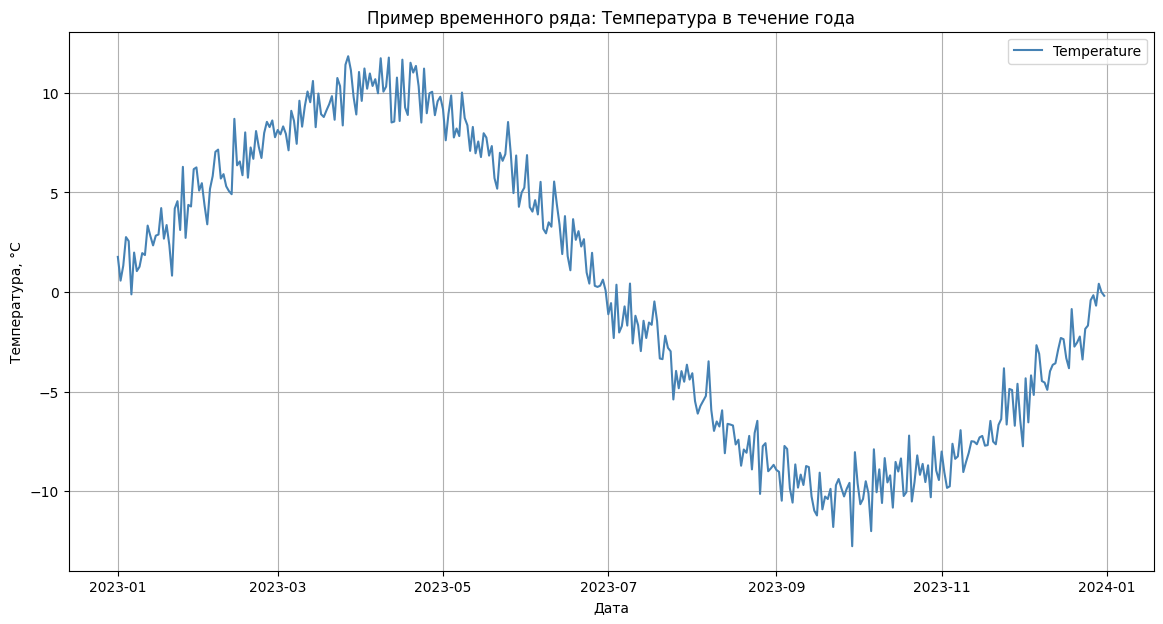

In [4]:
# Чтение DataFrame из файла
df_read = pd.read_csv('temperature_data.csv',
                      index_col='Date',
                      parse_dates=['Date'])

# Визуализация исходного временного ряда
plt.figure(figsize=(14, 7))
plt.plot(df_read.index, df_read['Temperature'],
         label='Temperature', color='steelblue')
plt.title('Пример временного ряда: Температура в течение года')
plt.xlabel('Дата')
plt.ylabel('Температура, °C')
plt.legend(loc='upper right')
plt.grid(True)
plt.show()


**Разбор кода.** Назначение основных инструкций приведено в таблице 3.1.

**Таблица 3.1.** Назначение инструкций построения линейного графика

| Инструкция | Назначение |
|---|---|
| `pd.read_csv(..., index_col='Date', parse_dates=['Date'])` | Чтение CSV-файла с одновременным назначением столбца `Date` индексом и его парсингом как дат |
| `plt.figure(figsize=(14, 7))` | Создание области рисования размером 14 × 7 дюймов |
| `plt.plot(df_read.index, df_read['Temperature'], ...)` | Построение линейного графика: по оси X — даты, по оси Y — значения температуры |
| `plt.title(...)`, `plt.xlabel(...)`, `plt.ylabel(...)` | Оформление заголовка и подписей осей |
| `plt.legend(loc='upper right')` | Вывод легенды в правом верхнем углу |
| `plt.grid(True)` | Включение координатной сетки |
| `plt.show()` | Отображение построенного графика |

**Замечание 3.2.** В исходном фрагменте кода использовалась переменная `df.index`, хотя данные читаются в переменную `df_read`. Корректным является обращение `df_read.index`, поскольку именно эта переменная содержит загруженный временной ряд.

## 3.3. Интерпретация графика

На построенном графике (пример 3.1) отчётливо наблюдаются следующие структурные особенности ряда.

1. **Сезонная компонента.** График имеет форму плавной синусоиды: зимой (январь, декабрь) значения температуры отрицательны, летом (июнь–август) — положительны. Это свидетельствует о наличии годовой сезонности с периодом $P = 365$ дней и амплитудой около 10 °C.

2. **Шумовая компонента.** Вокруг синусоиды наблюдается «дрожание» линии, обусловленное случайными ежедневными колебаниями. Амплитуда этих отклонений позволяет приближённо оценить дисперсию шума $\sigma^2_\varepsilon$.

3. **Отсутствие тренда.** Средний уровень ряда приблизительно постоянен: положительные и отрицательные отклонения симметричны относительно нуля, систематического роста или падения не наблюдается.

4. **Отсутствие выбросов.** Резких одиночных скачков значений на графике не зафиксировано.

**Замечание 3.3.** Сочетание «сезонность + шум при отсутствии тренда» характерно для многих реальных временных рядов: суточного профиля потребления электроэнергии, недельной динамики продаж, годовых колебаний температуры. Форма графика непосредственно влияет на выбор класса прогнозных моделей: для таких рядов применяются модели с сезонной компонентой (SARIMA, Prophet), тогда как для рядов с трендом — модели с дифференцированием (ARIMA).

## 3.4. Сравнительный пример: ряд с линейным трендом

**Пример 3.2.** Для сопоставления рассмотрим синтетический ряд с выраженным линейным трендом и без сезонности.


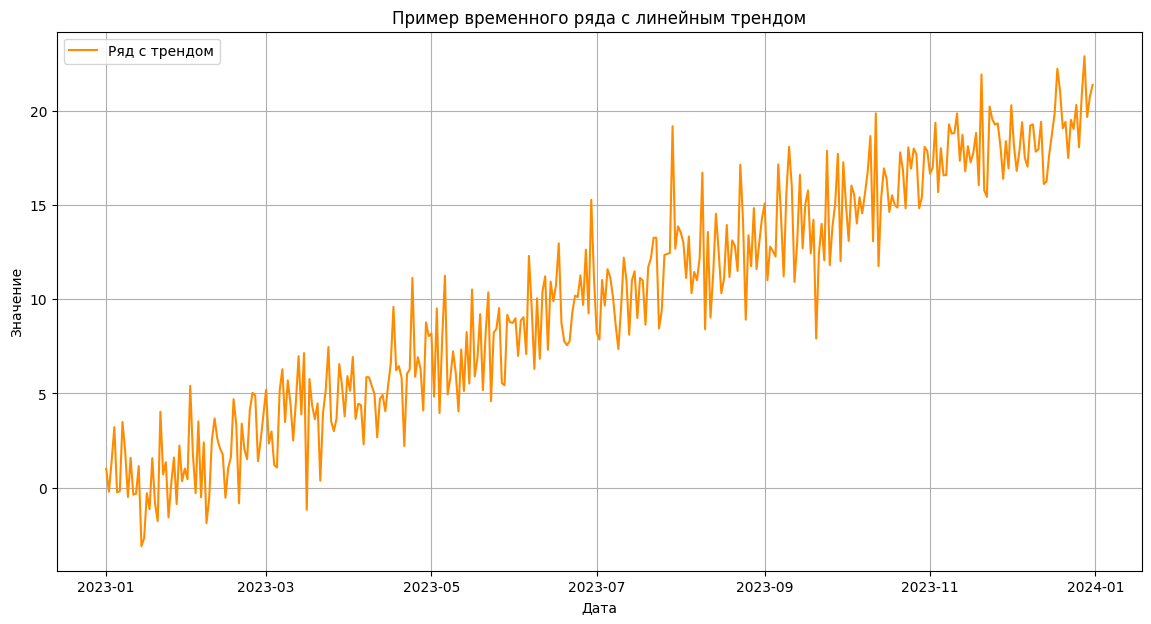

In [5]:
# Генерация ряда с линейным трендом и шумом
np.random.seed(42)
dates2 = pd.date_range(start='2023-01-01', periods=365, freq='D')
trend = np.linspace(0, 20, len(dates2))              # линейный рост
noise = np.random.normal(scale=2, size=len(dates2))  # шум
series_trend = trend + noise

df_trend = pd.DataFrame({'Date': dates2, 'Value': series_trend})
df_trend.set_index('Date', inplace=True)

# Визуализация
plt.figure(figsize=(14, 7))
plt.plot(df_trend.index, df_trend['Value'],
         color='darkorange', label='Ряд с трендом')
plt.title('Пример временного ряда с линейным трендом')
plt.xlabel('Дата')
plt.ylabel('Значение')
plt.legend(loc='upper left')
plt.grid(True)
plt.show()


**Сравнительный анализ.** Сопоставление двух рассмотренных рядов приведено в таблице 3.2.

**Таблица 3.2.** Сравнительная характеристика двух типов временных рядов

| Признак | Ряд температуры (пример 3.1) | Ряд с трендом (пример 3.2) |
|---|---|---|
| Тренд | отсутствует | выраженный, линейный |
| Сезонность | ярко выражена, $P = 365$ | отсутствует |
| Шум | малый, наложен на синусоиду | заметный, наложен на прямую |
| Рекомендуемый класс моделей | SARIMA, Prophet | ARIMA с дифференцированием |

Данное сопоставление иллюстрирует основной принцип предварительного анализа: **форма графика непосредственно подсказывает, какие методы моделирования будут адекватны структуре ряда**.

## 3.5. Выводы по разделу

В настоящем разделе:

1. дано определение линейного графика временного ряда и перечислены решаемые с его помощью задачи;
2. построен линейный график ранее сгенерированного ряда температуры и разобрано назначение каждой инструкции;
3. проведена интерпретация графика — установлено наличие сезонности, шума, отсутствие тренда и выбросов;
4. выполнено сравнение двух типов рядов (сезонного и трендового), демонстрирующее влияние формы графика на выбор дальнейших методов анализа.

Линейный график составляет минимально необходимый набор визуализаций временного ряда. На последующих шагах он, как правило, дополняется скользящим средним, сезонной декомпозицией и гистограммой распределения, что позволяет получить более полное представление о структуре данных.

# 4. Гистограммы (Histograms)

## 4.1. Определение и назначение

**Определение 4.1.** *Гистограммой* называется графическое представление эмпирического распределения значений временного ряда, в котором область определения показателя разбивается на интервалы (бины), а высота каждого столбца пропорциональна числу наблюдений, попавших в соответствующий интервал.

Если линейный график (раздел 3) отвечает на вопрос «**как значения меняются во времени**», то гистограмма отвечает на принципиально иной вопрос — «**как значения распределены по величине**», полностью абстрагируясь от порядка их появления.

Применение гистограмм в анализе временных рядов позволяет решить следующие задачи:

1. **оценка формы распределения** — симметрично ли оно, скошено влево или вправо, имеет ли несколько мод;
2. **выявление многомодальности** — наличие нескольких пиков может указывать на смешение режимов (например, зимний и летний периоды);
3. **проверка гипотезы о нормальности** — многие статистические методы (ARIMA, тесты на стационарность) предполагают нормальность остатков;
4. **обнаружение выбросов** — наблюдения, лежащие далеко от основной массы значений, видны как изолированные столбцы на краях распределения;
5. **оценка диапазона и типичных значений** — минимальное, максимальное и наиболее частые значения показателя.

**Замечание 4.1.** В отличие от линейного графика, гистограмма **не учитывает временной порядок** наблюдений. Два временных ряда с совершенно разной динамикой (например, плавно колеблющийся и хаотичный) могут иметь идентичные гистограммы. Поэтому гистограмму следует применять **в дополнение** к линейному графику, а не вместо него.

## 4.2. Построение гистограммы ранее сгенерированного ряда

**Пример 4.1.** Построим гистограмму распределения значений температуры для синтетического ряда, сгенерированного в разделе 2.



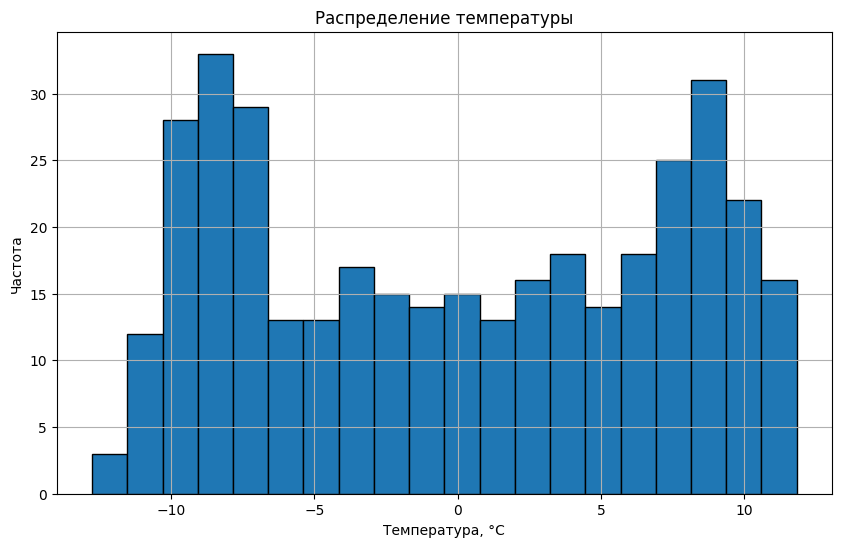

In [6]:
plt.figure(figsize=(10, 6))
plt.hist(df['Temperature'], bins=20, edgecolor='black')
plt.title('Распределение температуры')
plt.xlabel('Температура, °C')
plt.ylabel('Частота')
plt.grid(True)
plt.show()



**Разбор кода.** Назначение основных инструкций приведено в таблице 4.1.

**Таблица 4.1.** Назначение инструкций построения гистограммы

| Инструкция | Назначение |
|---|---|
| `plt.figure(figsize=(10, 6))` | Создание области рисования размером 10 × 6 дюймов |
| `plt.hist(df['Temperature'], bins=20, edgecolor='black')` | Построение гистограммы: `bins=20` задаёт число интервалов разбиения, `edgecolor` — цвет границ столбцов |
| `plt.title(...)`, `plt.xlabel(...)`, `plt.ylabel(...)` | Оформление заголовка и подписей осей |
| `plt.grid(True)` | Включение координатной сетки |
| `plt.show()` | Отображение построенного графика |

**Замечание 4.2.** Параметр `bins` играет ключевую роль: слишком малое число интервалов огрубляет распределение, слишком большое — делает его изрезанным и вносит визуальный шум. При объёме выборки $n$ эмпирически приемлемым считается число бинов порядка $\sqrt{n}$ или вычисленное по правилу Стёрджеса:

$$k = \lceil \log_2 n \rceil + 1.$$

Для $n = 365$ это даёт $k \approx 10$; значение `bins=20` выбрано для большей детализации.

## 4.3. Интерпретация гистограммы

Для рассматриваемого ряда температуры гистограмма имеет характерную **двугорбую (бимодальную) форму** с двумя выраженными пиками:

1. **Левый пик** соответствует отрицательным значениям температуры — это наблюдения зимнего периода (январь, декабрь).
2. **Правый пик** соответствует положительным значениям — наблюдения летнего периода (июнь–август).
3. **Провал между пиками** приходится на значения, близкие к нулю, — это переходные периоды весны и осени, когда температура проходит через нулевую отметку.

**Замечание 4.3.** Бимодальность является **прямым следствием годовой сезонности**: за один год температура дважды проходит полный цикл роста и падения, поэтому значения концентрируются у двух крайних точек — минимума (зима) и максимума (лето).

Среднее значение ряда близко к нулю, а распределение приблизительно симметрично относительно него. Крайние значения (порядка ±12 °C) встречаются редко — это соответствует редким аномально холодным или тёплым дням.

**Замечание 4.4.** Если бы исходный ряд не содержал сезонной компоненты, а представлял собой «белый шум» с нормально распределёнными значениями, гистограмма имела бы вид **колоколообразной кривой** с единственным максимумом в центре. Сравнение этих двух форм — удобный диагностический приём: **наличие бимодальности в остатках модели обычно свидетельствует о недоучтённой сезонности**.

## 4.4. Наложение теоретической кривой плотности

**Пример 4.2.** Для количественной оценки соответствия эмпирического распределения теоретическому удобно наложить на гистограмму график плотности нормального распределения.



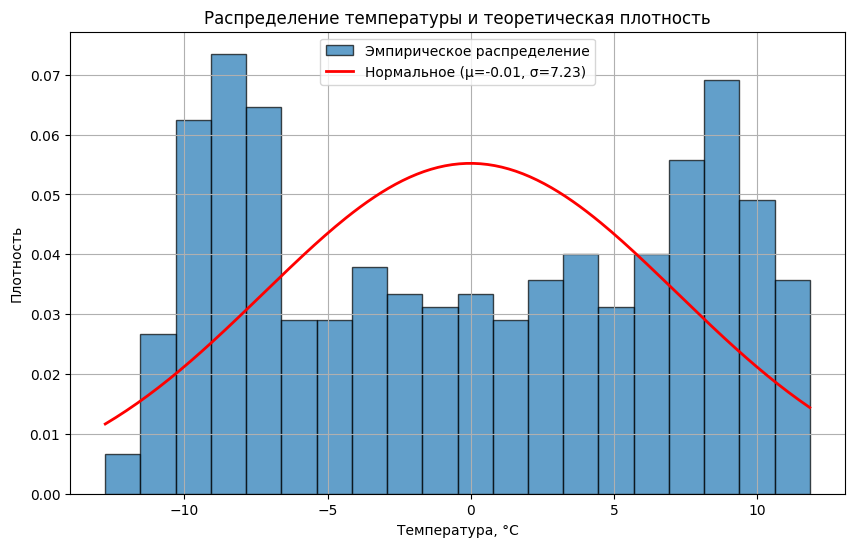

In [7]:
from scipy.stats import norm

plt.figure(figsize=(10, 6))
plt.hist(df['Temperature'], bins=20, density=True,
         edgecolor='black', alpha=0.7, label='Эмпирическое распределение')

# Подгонка нормального распределения
mu, sigma = df['Temperature'].mean(), df['Temperature'].std()
x = np.linspace(df['Temperature'].min(), df['Temperature'].max(), 200)
plt.plot(x, norm.pdf(x, mu, sigma),
         color='red', linewidth=2, label=f'Нормальное (μ={mu:.2f}, σ={sigma:.2f})')

plt.title('Распределение температуры и теоретическая плотность')
plt.xlabel('Температура, °C')
plt.ylabel('Плотность')
plt.legend()
plt.grid(True)
plt.show()


**Разбор кода.** При построении гистограммы с параметром `density=True` высота столбцов нормируется так, что их суммарная площадь равна единице. Это позволяет сравнивать гистограмму напрямую с кривой плотности вероятности. Параметры $\mu$ и $\sigma$ оцениваются по выборке методом моментов.

**Интерпретация.** Красная кривая нормального распределения будет заметно **хуже описывать** бимодальную эмпирическую гистограмму: она имеет один максимум в центре, тогда как данные имеют два. Это наглядно демонстрирует, что **гипотеза о нормальности для ряда с сезонностью не выполняется** — важный диагностический вывод, влияющий на выбор дальнейших методов анализа.

## 4.5. Гистограмма осадков по месяцам (альтернативный пример)

**Пример 4.3.** В задачах климатологии гистограммы часто применяют не к отдельным наблюдениям, а к **агрегированным по месяцам** значениям. Рассмотрим условный пример гистограммы месячных сумм осадков.




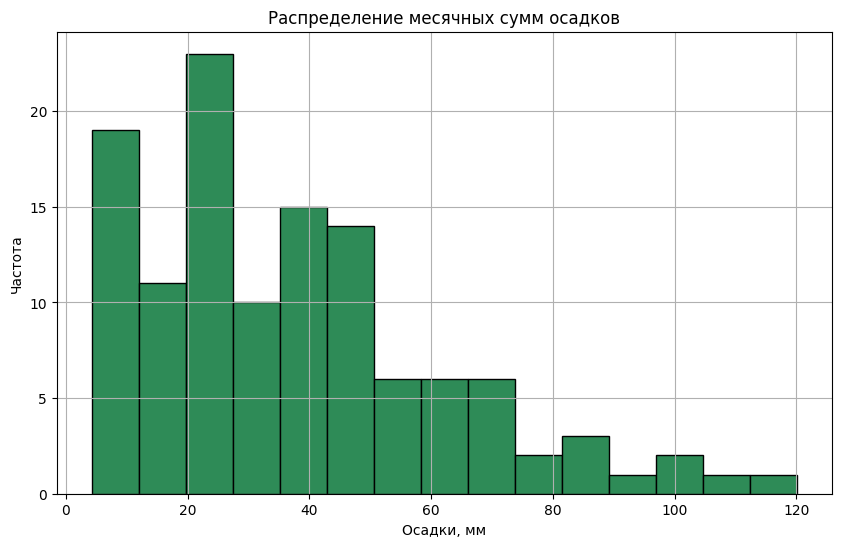

In [8]:
# Синтетические данные: сумма осадков по месяцам за 10 лет
np.random.seed(7)
months = np.tile(np.arange(1, 13), 10)
precipitation = np.abs(np.random.gamma(shape=2, scale=20, size=len(months)))

df_precip = pd.DataFrame({'Month': months, 'Precipitation': precipitation})

# Гистограмма распределения осадков
plt.figure(figsize=(10, 6))
plt.hist(df_precip['Precipitation'], bins=15, edgecolor='black', color='seagreen')
plt.title('Распределение месячных сумм осадков')
plt.xlabel('Осадки, мм')
plt.ylabel('Частота')
plt.grid(True)
plt.show()



**Интерпретация.** Распределение осадков имеет ярко выраженную **правостороннюю асимметрию** (положительный скос): большинство месяцев характеризуется небольшими значениями, но изредка встречаются месяцы с аномально высокими суммами. Такая форма типична для климатологических величин и указывает на **необходимость логарифмического преобразования** перед применением методов, предполагающих нормальность.

## 4.6. Выводы по разделу

В настоящем разделе:

1. дано определение гистограммы временного ряда и перечислены решаемые с её помощью задачи;
2. построена гистограмма распределения температуры и разобрано назначение каждой инструкции;
3. проведена интерпретация — установлена бимодальная форма распределения, обусловленная годовой сезонностью;
4. выполнено сопоставление эмпирического распределения с теоретическим нормальным;
5. рассмотрен альтернативный пример — гистограмма осадков с правосторонней асимметрией.

**Сравнительная характеристика двух инструментов визуализации** приведена в таблице 4.2.

**Таблица 4.2.** Линейный график и гистограмма: сопоставление

| Характеристика | Линейный график | Гистограмма |
|---|---|---|
| По оси X | время | значение показателя |
| По оси Y | значение показателя | частота (или плотность) |
| Учитывает порядок наблюдений | да | нет |
| Основная задача | динамика, тренд, сезонность | форма распределения |
| Применение | первичный анализ структуры | проверка гипотез, оценка выбросов |

Оба инструмента **взаимодополняют друг друга**: линейный график показывает, *как* меняется показатель во времени, а гистограмма — *как* распределены его значения. Совместное применение этих двух визуализаций даёт аналитику полноценное представление о структуре временного ряда до перехода к формальным статистическим методам.

# 5. Корреляционные графики (Autocorrelation Plots)

## 5.1. Определение и назначение

**Определение 5.1.** *Автокорреляцией* временного ряда $\{y_t\}_{t=1}^{n}$ называется корреляционная зависимость между значениями этого ряда, сдвинутыми друг относительно друга на некоторое число шагов (лагов).

Если линейный график (раздел 3) показывает динамику ряда, а гистограмма (раздел 4) — форму его распределения, то **корреляционный (автокорреляционный) график** отвечает на качественно иной вопрос: **«насколько значения ряда зависят от своих же предыдущих значений?»**

**Определение 5.2.** *Автокорреляционная функцией (АКФ)* временного ряда называется функция

$$\rho(k) = \frac{\mathrm{Cov}(y_t,\ y_{t+k})}{\sqrt{\mathrm{Var}(y_t)\,\mathrm{Var}(y_{t+k})}}, \qquad k = 0, 1, 2, \ldots$$

где $k$ — величина лага (сдвига). Величина $\rho(k)$ называется *коэффициентом автокорреляции порядка $k$*. При $k = 0$ всегда $\rho(0) = 1$.

**Определение 5.3.** *Корреляционным графиком (autocorrelation plot, коррелограммой)* называется график зависимости коэффициента автокорреляции $\rho(k)$ от величины лага $k$, дополненный доверительными границами, позволяющими судить о статистической значимости полученных значений.

Применение корреляционных графиков позволяет решить следующие задачи:

1. **оценка «памяти» ряда** — на сколько шагов назад значения ряда оказывают влияние на текущее;
2. **обнаружение сезонности** — периодические всплески АКФ на лагах, кратных периоду сезонности;
3. **идентификация порядка модели** — выбор параметров $p$ и $q$ для моделей AR, MA и ARIMA;
4. **проверка стационарности** — медленное убывание АКФ свидетельствует о нестационарности;
5. **диагностика остатков** — проверка адекватности построенной модели (остатки должны быть «белым шумом» с АКФ, близкой к нулю при всех $k > 0$).

**Замечание 5.1.** Автокорреляционный анализ является связующим звеном между визуальным предварительным анализом и формальным моделированием временных рядов. Именно по виду коррелограммы аналитик делает первые предположения о классе подходящей модели.

## 5.2. Построение корреляционного графика для ряда температуры

**Пример 5.1.** Построим коррелограмму для синтетического ряда температуры, сгенерированного в разделе 2.




<Figure size 1200x500 with 0 Axes>

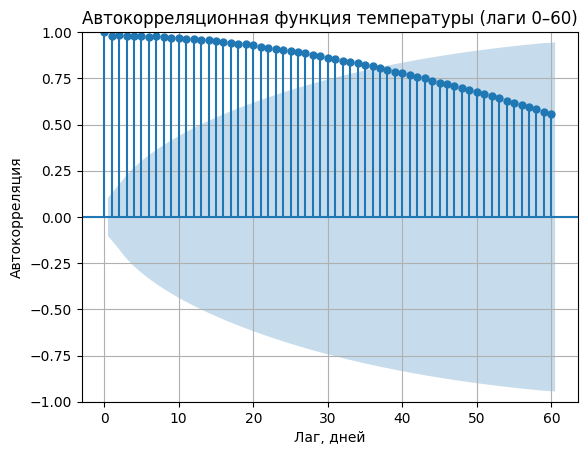

In [9]:
from statsmodels.graphics.tsaplots import plot_acf

plt.figure(figsize=(12, 5))
plot_acf(df['Temperature'], lags=60, alpha=0.05)
plt.title('Автокорреляционная функция температуры (лаги 0–60)')
plt.xlabel('Лаг, дней')
plt.ylabel('Автокорреляция')
plt.grid(True)
plt.show()


**Разбор кода.** Назначение основных инструкций приведено в таблице 5.1.

**Таблица 5.1.** Назначение инструкций построения коррелограммы

| Инструкция | Назначение |
|---|---|
| `from statsmodels.graphics.tsaplots import plot_acf` | Импорт функции построения АКФ из библиотеки `statsmodels` |
| `plot_acf(df['Temperature'], lags=60, alpha=0.05)` | Построение коррелограммы: `lags=60` — число отображаемых лагов, `alpha=0.05` — уровень значимости доверительных границ |
| `plt.title(...)`, `plt.xlabel(...)`, `plt.ylabel(...)` | Оформление заголовка и подписей осей |
| `plt.grid(True)` | Включение координатной сетки |
| `plt.show()` | Отображение построенного графика |

**Замечание 5.2.** Горизонтальные пунктирные линии на коррелограмме соответствуют **доверительным границам** $\pm z_{1-\alpha/2} / \sqrt{n}$. Столбцы (лаги), выходящие за эти границы, считаются **статистически значимыми** при заданном уровне значимости $\alpha$ (по умолчанию $\alpha = 0{,}05$, что соответствует 95 %-й доверительной вероятности).

## 5.3. Интерпретация коррелограммы температуры

Для рассматриваемого ряда температуры коррелограмма имеет ярко выраженный **периодический характер**, что отражает наличие годовой сезонности.

1. **Лаг 0** — коэффициент автокорреляции равен единице по определению.
2. **Малые лаги (1–30 дней)** — АКФ медленно убывает, оставаясь положительной. Это означает, что температура соседних дней сильно коррелирована: чем ближе дни друг к другу, тем ближе их значения.
3. **Лаг ~90 дней** — АКФ пересекает нулевую отметку. Это соответствует переходу от зимы к весне или от лета к осени, когда температура «отрывается» от своих начальных значений.
4. **Лаг ~180 дней** — АКФ достигает **минимума, близкого к −1**. Это означает **сильную отрицательную корреляцию**: температура через полгода обычно противоположна по знаку текущей (если сейчас зима — через полгода лето, и наоборот).
5. **Лаг ~365 дней** — АКФ вновь приближается к **максимуму, близкому к +1**. Это главное свидетельство **годовой сезонности**: значения ряда повторяются с периодом в один год.

**Замечание 5.3.** Периодическая структура коррелограммы — визуально самый простой и надёжный способ обнаружить сезонность до применения формальных тестов (например, теста на сезонную единичную компоненту). Пики АКФ на лагах, кратных периоду $P$, однозначно указывают на наличие сезонной компоненты.

## 5.4. Сравнение: коррелограммы для разных типов рядов

Для сопоставления полезно рассмотреть коррелограммы нескольких качественно различных временных рядов. Это позволяет выработать «насмотренность» на характерные формы АКФ.

**Пример 5.2.** Построим коррелограммы для трёх типов рядов: «белый шум», ряд с трендом и сезонный ряд.



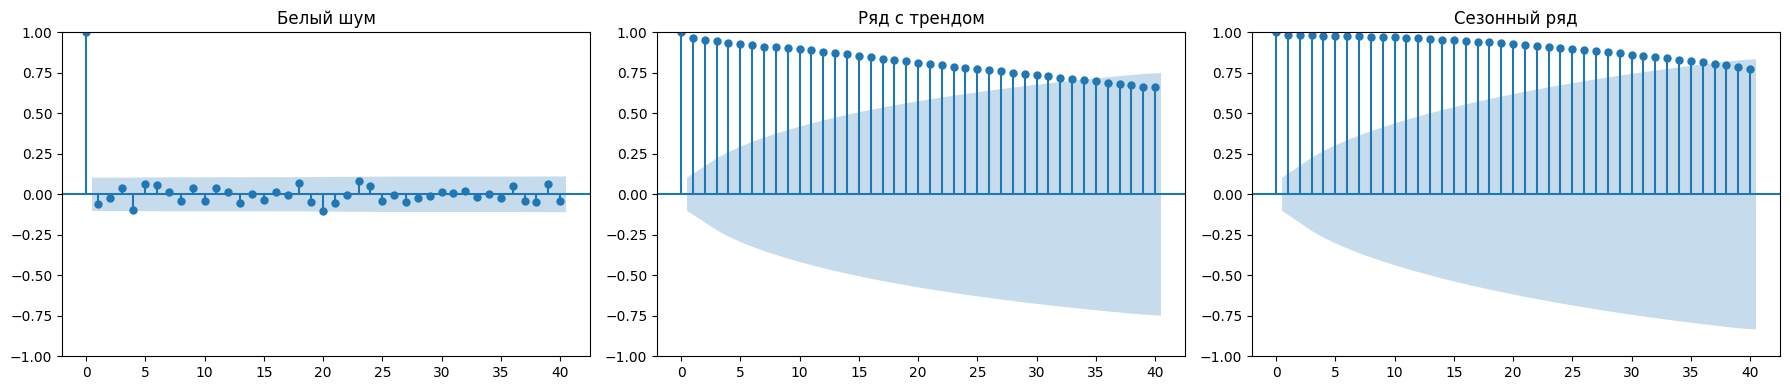

In [10]:
from statsmodels.graphics.tsaplots import plot_acf

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

# 1. Белый шум
np.random.seed(42)
white_noise = np.random.normal(size=365)
plot_acf(white_noise, lags=40, ax=axes[0])
axes[0].set_title('Белый шум')

# 2. Ряд с линейным трендом
trend_series = np.linspace(0, 20, 365) + np.random.normal(size=365)
plot_acf(trend_series, lags=40, ax=axes[1])
axes[1].set_title('Ряд с трендом')

# 3. Сезонный ряд (температура)
plot_acf(df['Temperature'], lags=40, ax=axes[2])
axes[2].set_title('Сезонный ряд')

plt.tight_layout()
plt.show()


**Сравнительная характеристика** приведена в таблице 5.2.

**Таблица 5.2.** Типовые формы автокорреляционных функций

| Тип ряда | Характерная форма АКФ | Интерпретация |
|---|---|---|
| **Белый шум** | Все коэффициенты, кроме $\rho(0)$, лежат внутри доверительных границ | Значения ряда взаимно независимы, «памяти» нет |
| **Ряд с трендом** | АКФ убывает очень медленно, остаётся положительной на десятках лагов | Ряд нестационарен, требуется дифференцирование |
| **Сезонный ряд** | Ярко выраженные периодические пики на лагах, кратных периоду сезонности | Ряд содержит сезонную компоненту с известным периодом |

**Замечание 5.4.** Приведённое сопоставление демонстрирует **диагностическую роль коррелограммы**. Уже по одному виду АКФ можно сделать важные выводы:

- если все столбцы в пределах границ — ряд, скорее всего, представляет собой шум, моделирование не требуется;
- если АКФ убывает медленно — ряд нестационарен, перед моделированием необходимо применить дифференцирование (модель ARIMA);
- если видны периодические всплески — необходима модель с сезонной компонентой (SARIMA);
- если АКФ резко обрывается после лага $q$ — уместна модель скользящего среднего MA($q$);
- если АКФ убывает по экспоненте или затухающей синусоиде — уместна авторегрессионная модель AR($p$).

## 5.5. Частная автокорреляционная функция (PACF)

**Определение 5.4.** *Частной автокорреляционной функцией (ЧАКФ, PACF)* называется функция $\phi(k)$, описывающая корреляцию между $y_t$ и $y_{t+k}$ **при исключённом влиянии промежуточных значений** $y_{t+1}, \ldots, y_{t+k-1}$.

Формально $\phi(k)$ равна последнему коэффициенту в линейной регрессии $y_t$ на $y_{t-1}, \ldots, y_{t-k}$.

**Замечание 5.5.** Совместный анализ АКФ и ЧАКФ является стандартной процедурой идентификации порядка модели ARIMA (метод Бокса–Дженкинса).

**Таблица 5.3.** Диагностические признаки АКФ и ЧАКФ для выбора модели

| Модель | АКФ (ACF) | ЧАКФ (PACF) |
|---|---|---|
| AR($p$) | убывает плавно | обрывается после лага $p$ |
| MA($q$) | обрывается после лага $q$ | убывает плавно |
| ARMA($p, q$) | убывает плавно | убывает плавно |

**Пример 5.3.** Совместное построение АКФ и ЧАКФ для ряда температуры.



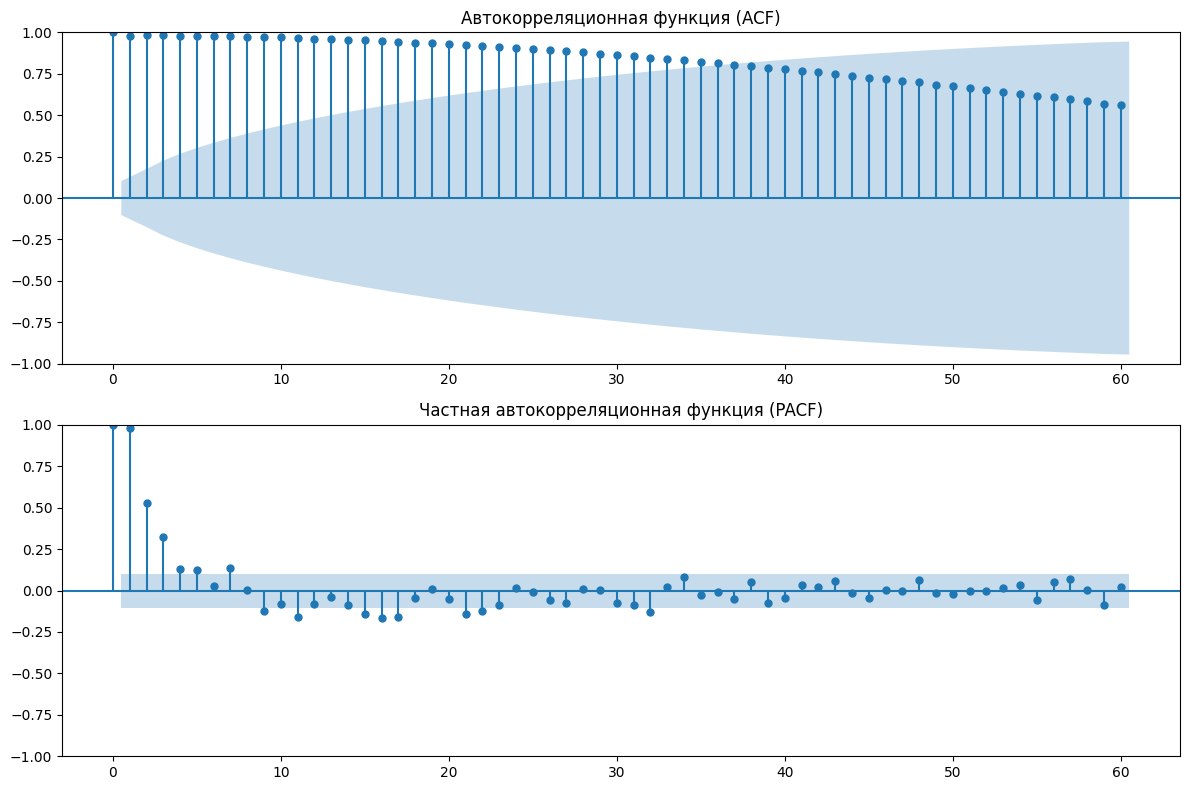

In [11]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

plot_acf(df['Temperature'], lags=60, ax=axes[0])
axes[0].set_title('Автокорреляционная функция (ACF)')

plot_pacf(df['Temperature'], lags=60, ax=axes[1], method='ywm')
axes[1].set_title('Частная автокорреляционная функция (PACF)')

plt.tight_layout()
plt.show()


```

**Интерпретация.** Для сезонного ряда температуры обе функции демонстрируют периодическую структуру с пиками на лагах, кратных 365. Это указывает на необходимость использования **сезонной модели SARIMA** с периодом сезонности $s = 365$.

## 5.6. Выводы по разделу

В настоящем разделе:

1. дано определение автокорреляции, автокорреляционной функции и коррелограммы;
2. перечислены задачи, решаемые с помощью корреляционного анализа временного ряда;
3. построена коррелограмма для синтетического ряда температуры и разобрано назначение каждой инструкции;
4. проведена интерпретация коррелограммы — установлена периодическая структура АКФ, подтверждающая наличие годовой сезонности;
5. выполнено сравнение коррелограмм трёх типов рядов («белый шум», тренд, сезонность);
6. рассмотрена частная автокорреляционная функция и её роль в идентификации порядка модели ARIMA.

**Сравнительная характеристика трёх инструментов визуализации** приведена в таблице 5.4.

**Таблица 5.4.** Три инструмента предварительного анализа временного ряда

| Характеристика | Линейный график | Гистограмма | Коррелограмма |
|---|---|---|---|
| По оси X | время | значение показателя | лаг |
| По оси Y | значение показателя | частота (плотность) | коэффициент автокорреляции |
| Отвечает на вопрос | *как меняется во времени?* | *как распределены значения?* | *насколько ряд «помнит» себя?* |
| Обнаруживает | тренд, сезонность, выбросы | форму распределения, асимметрию | «память», сезонность, стационарность |
| Роль в моделировании | первичный анализ | проверка гипотез о распределении | выбор порядка модели ARIMA/SARIMA |

Все три инструмента **взаимодополняют друг друга**. Полноценный предварительный анализ временного ряда предполагает последовательное применение всех трёх визуализаций: сначала линейный график позволяет оценить структуру ряда во времени, затем гистограмма — форму распределения его значений, и, наконец, коррелограмма — внутреннюю корреляционную структуру, непосредственно определяющую выбор класса прогнозной модели.

# 6. Сезонные графики (Seasonal Plots)

## 6.1. Определение и назначение

**Определение 6.1.** *Сезонным графиком* называется графическое представление временного ряда, в котором наблюдения группируются по **фазе сезонного цикла** (например, по месяцу года, дню недели или часу суток) с целью визуального выявления и сопоставления повторяющихся колебаний.

Если линейный график (раздел 3) показывает изменение ряда во времени, гистограмма (раздел 4) — форму его распределения, а коррелограмма (раздел 5) — корреляционную структуру, то **сезонный график** отвечает на специфический вопрос: **«как выглядит типичный сезонный профиль ряда и как он воспроизводится из года в год?»**

Применение сезонных графиков позволяет решить следующие задачи:

1. **идентификация сезонного профиля** — определение типичной формы колебаний внутри сезонного цикла (например, «продажи максимальны в декабре»);
2. **оценка амплитуды сезонности** — насколько велика разница между максимумом и минимумом внутри одного цикла;
3. **сравнение сезонов между годами** — устойчив ли сезонный профиль или меняется от года к году;
4. **обнаружение сдвигов фазы** — смещаются ли пики сезонности во времени;
5. **выявление аномалий внутри сезона** — отклонения отдельных наблюдений от типичного профиля.

**Замечание 6.1.** В отличие от коррелограммы, которая лишь **обнаруживает наличие сезонности** (через периодические пики АКФ), сезонный график позволяет **увидеть форму сезонного профиля** и оценить его устойчивость. Оба инструмента дополняют друг друга.

## 6.2. Построение сезонного графика температуры

**Пример 6.1.** Построим сезонный график для синтетического ряда температуры, сгенерированного в разделе 2. Для этого добавим к `DataFrame` столбец с номером месяца и изобразим зависимость температуры от месяца.



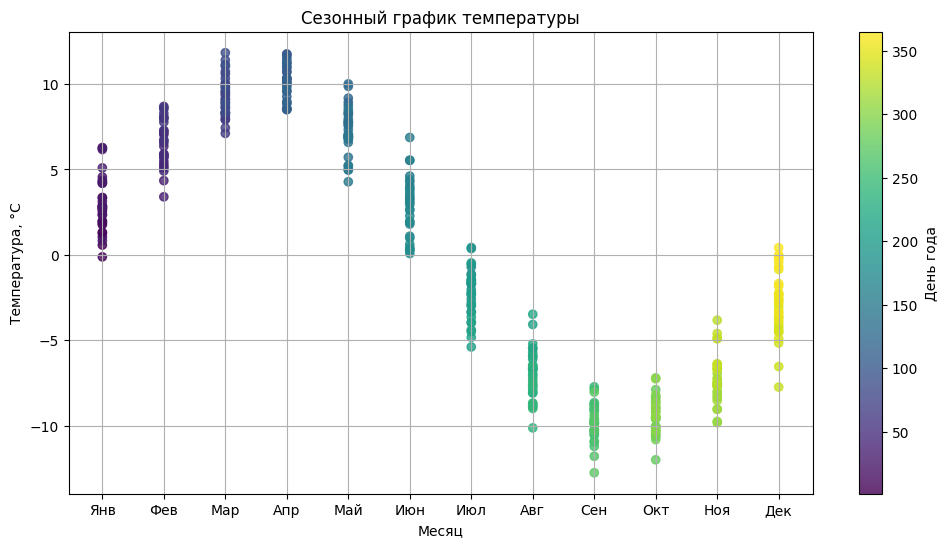

In [12]:
# Добавим столбец с месяцем
df['Month'] = df.index.month

# Построим сезонный график
plt.figure(figsize=(12, 6))
plt.scatter(df['Month'], df['Temperature'],
            alpha=0.8, c=df.index.dayofyear, cmap='viridis')
plt.colorbar(label='День года')
plt.title('Сезонный график температуры')
plt.xlabel('Месяц')
plt.ylabel('Температура, °C')
plt.xticks(range(1, 13),
           ['Янв', 'Фев', 'Мар', 'Апр', 'Май', 'Июн',
            'Июл', 'Авг', 'Сен', 'Окт', 'Ноя', 'Дек'])
plt.grid(True)
plt.show()



**Разбор кода.** Назначение основных инструкций приведено в таблице 6.1.

**Таблица 6.1.** Назначение инструкций построения сезонного графика

| Инструкция | Назначение |
|---|---|
| `df['Month'] = df.index.month` | Создание нового столбца с номером месяца, извлечённым из индекса дат (1 — январь, 12 — декабрь) |
| `plt.scatter(df['Month'], df['Temperature'], ...)` | Построение диаграммы рассеяния: по оси X — месяц, по оси Y — температура |
| `alpha=0.8` | Задание прозрачности точек (устраняет эффект «наложения») |
| `c=df.index.dayofyear, cmap='viridis'` | Раскраска точек по дню года с использованием цветовой карты `viridis` |
| `plt.colorbar(label='День года')` | Добавление цветовой шкалы с подписью |
| `plt.xticks(range(1, 13), [...])` | Замена числовых подписей месяцев на текстовые аббревиатуры |
| `plt.grid(True)` | Включение координатной сетки |

**Замечание 6.2.** Использование **диаграммы рассеяния (scatter plot)** вместо линейного графика принципиально: в сезонном графике наблюдения одного и того же месяца разных лет **накладываются друг на друга**, что позволяет сразу оценить как типичный уровень, так и разброс значений внутри сезона. Если бы мы использовали линейный график, связь между январем одного года и январем следующего года была бы визуально ложной.

## 6.3. Интерпретация сезонного графика температуры

Для рассматриваемого ряда температуры сезонный график имеет характерную **синусоидальную форму облака точек**, отражающую годовую сезонность.

1. **Форма профиля.** Температура плавно возрастает от января (минимум около −10 °C) к июлю (максимум около +10 °C), а затем симметрично убывает к декабрю. График имеет выраженную **U-образную (точнее, перевёрнутую U-образную) форму**.

2. **Амплитуда сезонности.** Размах между летним максимумом и зимним минимумом составляет около 20 °C — это **амплитуда сезонной компоненты** $2A = 20$, что соответствует параметру $A = 10$, заданному при генерации ряда.

3. **Разброс внутри месяца.** В каждом месяце точки образуют вертикальный «столбик», высота которого отражает **случайную (шумовую) компоненту**. Разброс внутри месяца заметно меньше размаха между зимой и летом, что подтверждает доминирование сезонной составляющей над шумовой.

4. **Цветовая градация.** Раскраска по дню года показывает **последовательность движения вдоль кривой**: цвета плавно меняются от тёмно-фиолетового (начало года) к жёлтому (середина года) и обратно. Это визуально подтверждает, что перед нами — **единый непрерывный сезонный цикл**, а не набор независимых наблюдений.

5. **Отсутствие аномалий.** Все точки хорошо ложатся на общую закономерность; резких выбросов, выпадающих из «синусоидальной» картины, не наблюдается.

**Замечание 6.3.** Если бы ряд содержал **несколько лет наблюдений**, точки одного месяца разных лет наложились бы друг на друга, и можно было бы оценить **устойчивость сезонного профиля**. Например, если бы январь каждого года давал близкие значения — сезонность считалась бы стабильной; если бы точки января одного года попадали в область летних температур, это сигнализировало бы о сдвиге сезонного цикла или аномалии.

## 6.4. Сравнение: сезонные графики для разных типов рядов

Для сопоставления рассмотрим сезонные графики двух качественно различных рядов: ряда с **годовой сезонностью** (температура) и ряда с **недельной сезонностью** (например, продажи).

**Пример 6.2.** Построим сезонный график продаж в зависимости от дня недели.



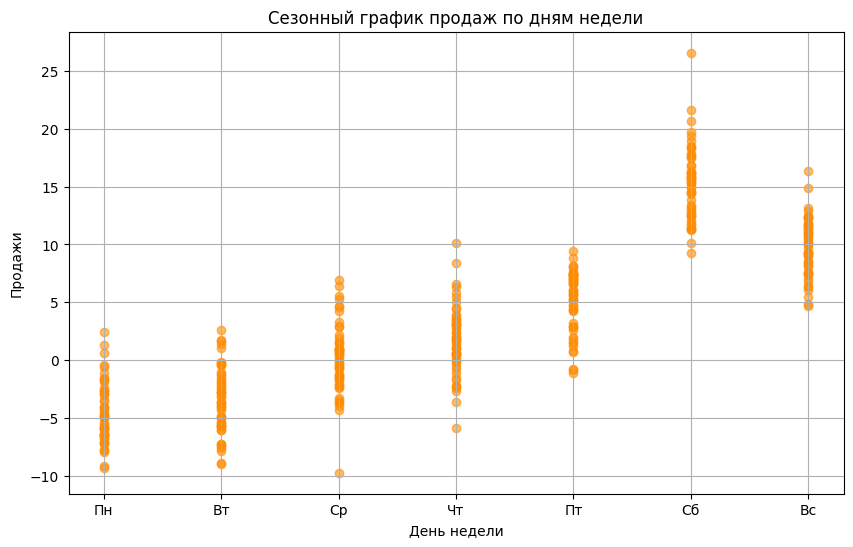

In [13]:
# Синтетический ряд недельной сезонности
np.random.seed(42)
dates_sales = pd.date_range(start='2023-01-01', periods=364, freq='D')
weekday_effect = np.array([-5, -3, 0, 2, 5, 15, 10])  # эффект дня недели
sales = weekday_effect[dates_sales.dayofweek] + np.random.normal(scale=3, size=len(dates_sales))

df_sales = pd.DataFrame({'Date': dates_sales, 'Sales': sales})
df_sales.set_index('Date', inplace=True)
df_sales['Weekday'] = df_sales.index.dayofweek

# Сезонный график по дням недели
plt.figure(figsize=(10, 6))
plt.scatter(df_sales['Weekday'], df_sales['Sales'], alpha=0.6, color='darkorange')
plt.title('Сезонный график продаж по дням недели')
plt.xlabel('День недели')
plt.ylabel('Продажи')
plt.xticks(range(7), ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс'])
plt.grid(True)
plt.show()



**Сравнительная характеристика** приведена в таблице 6.2.

**Таблица 6.2.** Сопоставление сезонных графиков с разными периодами

| Характеристика | Температура (год) | Продажи (неделя) |
|---|---|---|
| Период сезонности | 365 дней | 7 дней |
| Фаза (ось X) | месяц года (1–12) | день недели (0–6) |
| Форма профиля | плавная синусоида | ступенчатая (пики — выходные) |
| Амплитуда | ~20 °C | ~20 ед. |
| Число циклов в данных | 1 | 52 |
| Устойчивость профиля | не оценивается (один цикл) | высокая (много циклов) |

**Замечание 6.4.** Чем больше циклов содержится в данных, тем надёжнее оценивается сезонный профиль. Для ряда температуры, охватывающего один год, точки каждого месяца представлены всего 30 наблюдениями; для ряда продаж, охватывающего 52 недели, — уже 52 наблюдениями на каждый день недели. Это важно учитывать при выборе метода оценки сезонной компоненты: чем меньше циклов, тем осторожнее следует интерпретировать форму профиля.

## 6.5. Комбинированный подход: сезонный график + boxplot

**Пример 6.3.** Для количественной оценки разброса внутри каждого месяца сезонный график удобно дополнить **диаграммой размахов (boxplot)**.



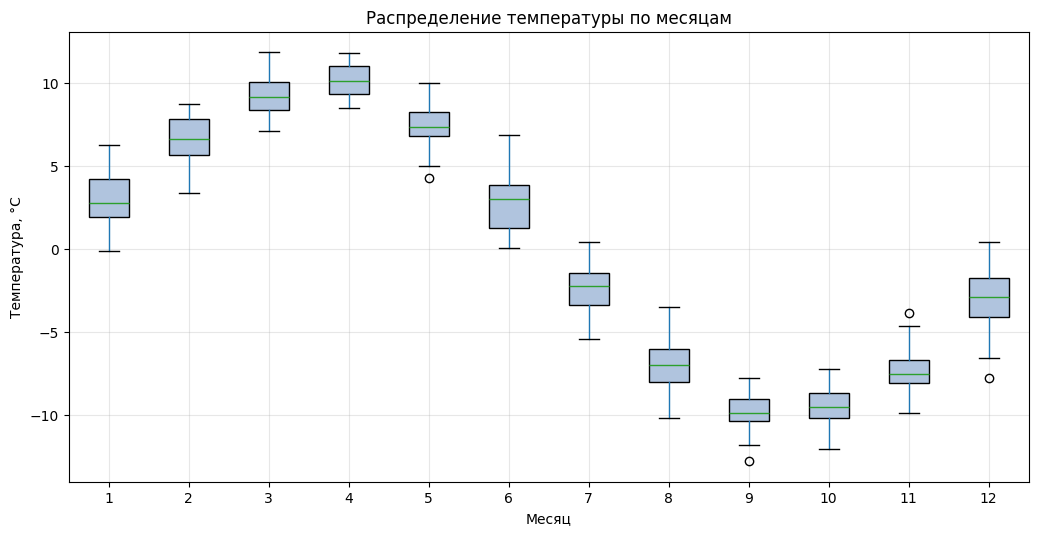

In [14]:
fig, ax = plt.subplots(figsize=(12, 6))
df.boxplot(column='Temperature', by='Month', ax=ax,
           grid=False, patch_artist=True,
           boxprops=dict(facecolor='lightsteelblue'))
ax.set_title('Распределение температуры по месяцам')
ax.set_xlabel('Месяц')
ax.set_ylabel('Температура, °C')
plt.suptitle('')  # убираем автоматический заголовок
plt.grid(True, alpha=0.3)
plt.show()



```

**Интерпретация.** На диаграмме размахов для каждого месяца отображаются:

- **медиана** (горизонтальная линия внутри ящика) — типичное значение температуры в данном месяце;
- **межквартильный размах** (границы ящика) — центральные 50 % наблюдений;
- **усы** — диапазон значений без выбросов;
- **точки за усами** — потенциальные выбросы.

Такое представление позволяет одновременно оценить **сезонный профиль** (изменение медиан от месяца к месяцу) и **внутреннюю вариабельность** (высоту ящиков), что в сочетании с сезонным графиком даёт более полную картину структуры ряда.

## 6.6. Выводы по разделу

В настоящем разделе:

1. дано определение сезонного графика и перечислены решаемые с его помощью задачи;
2. построен сезонный график температуры и разобрано назначение каждой инструкции;
3. проведена интерпретация — установлены форма профиля, амплитуда и разброс внутри месяцев;
4. выполнено сравнение сезонных графиков для годовой и недельной сезонности;
5. рассмотрен комбинированный подход с диаграммой размахов для количественной оценки сезонной вариабельности.

**Сравнительная характеристика четырёх инструментов визуализации** приведена в таблице 6.3.

**Таблица 6.3.** Четыре инструмента предварительного анализа временного ряда

| Характеристика | Линейный график | Гистограмма | Коррелограмма | Сезонный график |
|---|---|---|---|---|
| По оси X | время | значение показателя | лаг | фаза сезона |
| По оси Y | значение показателя | частота (плотность) | автокорреляция | значение показателя |
| Отвечает на вопрос | *как меняется во времени?* | *как распределены значения?* | *насколько ряд «помнит» себя?* | *какова форма сезонного профиля?* |
| Обнаруживает | тренд, сезонность, выбросы | форму распределения, асимметрию | «память», стационарность | профиль сезонности, амплитуду |
| Роль в моделировании | первичный анализ | проверка гипотез | выбор порядка ARIMA/SARIMA | оценка сезонной компоненты |

Все четыре инструмента образуют **взаимодополняющий комплекс** методов предварительного анализа. Последовательное применение:

1. **линейного графика** — для оценки общей динамики;
2. **гистограммы** — для анализа формы распределения;
3. **коррелограммы** — для выявления корреляционной структуры;
4. **сезонного графика** — для оценки формы и устойчивости сезонного профиля

позволяет аналитику получить **исчерпывающее представление о структуре временного ряда** до перехода к формальному статистическому моделированию. Именно на основе результатов этих четырёх визуализаций выбирается класс прогнозной модели (ARIMA, SARIMA, Prophet, экспоненциальное сглаживание), формулируются гипотезы о наличии тренда и сезонности, а также принимаются решения о необходимой предварительной обработке данных (дифференцирование, логарифмирование, удаление выбросов).

# 7. Точечные графики (Scatter Plots)

## 7.1. Определение и назначение

**Определение 7.1.** *Точечным графиком (диаграммой рассеяния, scatter plot)* называется графическое представление совокупности пар наблюдений $(x_i, y_i)$ в виде точек на плоскости, где $x_i$ — значение одной переменной, а $y_i$ — значение другой переменной, соответствующие одному и тому же моменту времени или одному и тому же объекту наблюдения.

Если ранее рассмотренные инструменты (разделы 3–6) применялись к **одному** временному ряду, то точечный график предназначен для анализа **совместного поведения двух рядов**. Он отвечает на вопрос: **«существует ли связь между двумя переменными и какова её форма?»**

Применение точечных графиков в анализе временных рядов позволяет решить следующие задачи:

1. **визуальная оценка взаимосвязи** — установить, изменяются ли две переменные согласованно (положительная связь), в противоположных направлениях (отрицательная связь) или независимо;
2. **выявление формы зависимости** — линейная она или нелинейная, монотонная или немонотонная;
3. **обнаружение кластеров и групп** — выделение подмножеств наблюдений со схожими характеристиками;
4. **выявление выбросов** — точки, резко выделяющиеся из общего облака, могут сигнализировать об аномалиях или ошибках данных;
5. **предварительная оценка силы связи** — визуальное суждение о том, насколько тесно связаны переменные.

**Замечание 7.1.** Важное отличие точечного графика от линейного состоит в том, что точки **не соединяются линиями**. Это принципиально: соединение точек предполагало бы наличие непрерывной траектории между наблюдениями, тогда как при сравнении двух рядов такой траектории может и не быть.

## 7.2. Точечный график для двух временных рядов

**Пример 7.1.** Рассмотрим сравнение двух синтетических временных рядов: температуры и числа продаж мороженого. Предположим, что между ними существует содержательная причинно-следственная связь — чем жарче погода, тем больше мороженого продаётся.




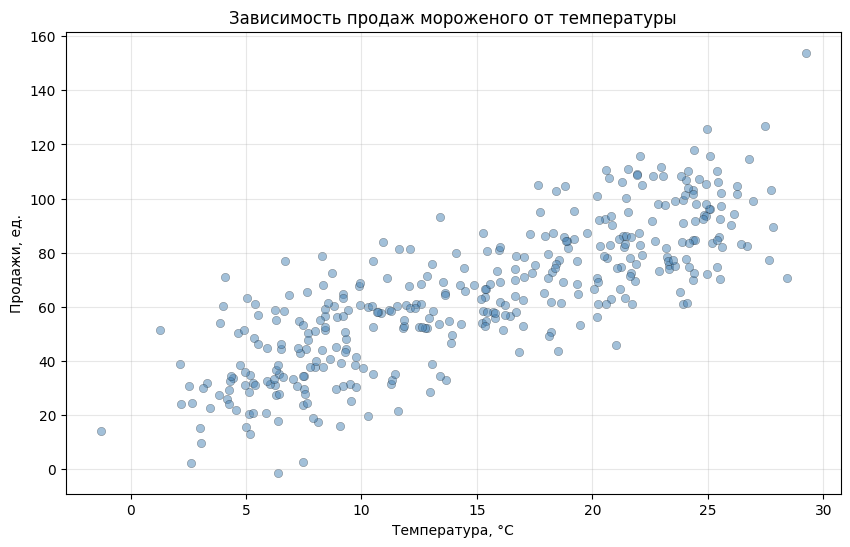

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Генерация двух связанных временных рядов
np.random.seed(42)
dates = pd.date_range(start='2023-01-01', periods=365, freq='D')

# Температура: сезонная синусоида + шум
temperature = 15 + 10 * np.sin(np.arange(365) * 2 * np.pi / 365) + np.random.normal(scale=2, size=365)

# Продажи: линейно зависят от температуры + шум
sales = 3 * temperature + 20 + np.random.normal(scale=15, size=365)

df = pd.DataFrame({'Date': dates, 'Temperature': temperature, 'Sales': sales})
df.set_index('Date', inplace=True)

# Построение точечного графика
plt.figure(figsize=(10, 6))
plt.scatter(df['Temperature'], df['Sales'],
            alpha=0.5, color='steelblue', edgecolor='k', linewidth=0.3)
plt.title('Зависимость продаж мороженого от температуры')
plt.xlabel('Температура, °C')
plt.ylabel('Продажи, ед.')
plt.grid(True, alpha=0.3)
plt.show()



**Разбор кода.** Назначение основных инструкций приведено в таблице 7.1.

**Таблица 7.1.** Назначение инструкций построения точечного графика

| Инструкция | Назначение |
|---|---|
| `np.random.seed(42)` | Фиксация генератора случайных чисел для воспроизводимости |
| `temperature = 15 + 10 * np.sin(...)` | Моделирование температуры как сезонной синусоиды с шумом |
| `sales = 3 * temperature + 20 + ...` | Моделирование продаж как линейной функции температуры с шумом |
| `plt.scatter(df['Temperature'], df['Sales'], ...)` | Построение диаграммы рассеяния: по X — температура, по Y — продажи |
| `alpha=0.5` | Прозрачность точек для визуализации плотности |
| `edgecolor='k', linewidth=0.3` | Тонкая чёрная обводка вокруг точек для чёткости |

**Замечание 7.2.** Параметр `alpha` (прозрачность) играет в точечных графиках особую роль: при большом числе наблюдений точки накладываются друг на друга, и без прозрачности график превращается в сплошное пятно. Полупрозрачные точки позволяют оценить **локальную плотность** наблюдений.

## 7.3. Интерпретация точечного графика

На построенном графике (пример 7.1) наблюдается следующая картина.

1. **Форма облака точек.** Точки образуют вытянутое облако, ориентированное **снизу слева вверх направо**. Это указывает на **положительную связь**: с ростом температуры продажи в среднем возрастают.

2. **Линейность зависимости.** Облако точек имеет приблизительно **линейную форму** — нет выраженной кривизны, нет «насыщения» на краях. Это подтверждает предположение о линейной связи между переменными.

3. **Сила связи.** Облако точек **достаточно плотное**, но не вытянуто в идеальную линию. Это означает, что связь сильная, но не детерминированная: часть разброса продаж объясняется другими факторами (реклама, выходные, случайность).

4. **Разброс.** Ширина облака примерно постоянна вдоль всей оси X — дисперсия продаж **не зависит** от уровня температуры (явление гомоскедастичности).

5. **Отсутствие выбросов.** Точек, сильно удалённых от основной массы, не наблюдается.

**Замечание 7.3.** Точечный график позволяет судить о **направлении и форме связи**, но **не даёт** количественной меры её силы. Для численной оценки используют **коэффициент корреляции Пирсона** $r$ (для линейной связи) или **коэффициент корреляции Спирмена** $\rho$ (для монотонной нелинейной связи). Визуальный анализ и расчёт коэффициента взаимно дополняют друг друга.

## 7.4. Типовые формы точечных диаграмм

Различным типам взаимосвязи между переменными соответствуют характерные формы облака точек. Их распознавание — ключевой навык интерпретации точечных графиков.

**Таблица 7.2.** Типовые формы точечных диаграмм и их интерпретация

| Форма облака | Тип связи | Коэффициент корреляции |
|---|---|---|
| Вытянуто вправо-вверх | сильная положительная линейная | $r \approx +1$ |
| Вытянуто вправо-вниз | сильная отрицательная линейная | $r \approx -1$ |
| Круглое, без ориентации | отсутствие линейной связи | $r \approx 0$ |
| Форма параболы | нелинейная (квадратичная) | $r \approx 0$, но связь есть |
| Две отдельные группы | смешанная популяция | зависит от групп |

**Замечание 7.4.** Важный контрпример: **нелинейная зависимость может давать нулевой коэффициент корреляции**. Например, если $y = x^2$, а $x$ симметрично распределена относительно нуля, то $r = 0$, хотя связь между переменными строго детерминирована. Точечный график **обязателен** перед расчётом корреляции, иначе можно сделать ложный вывод об отсутствии связи.

**Пример 7.2.** Иллюстрация четырёх типов связи.



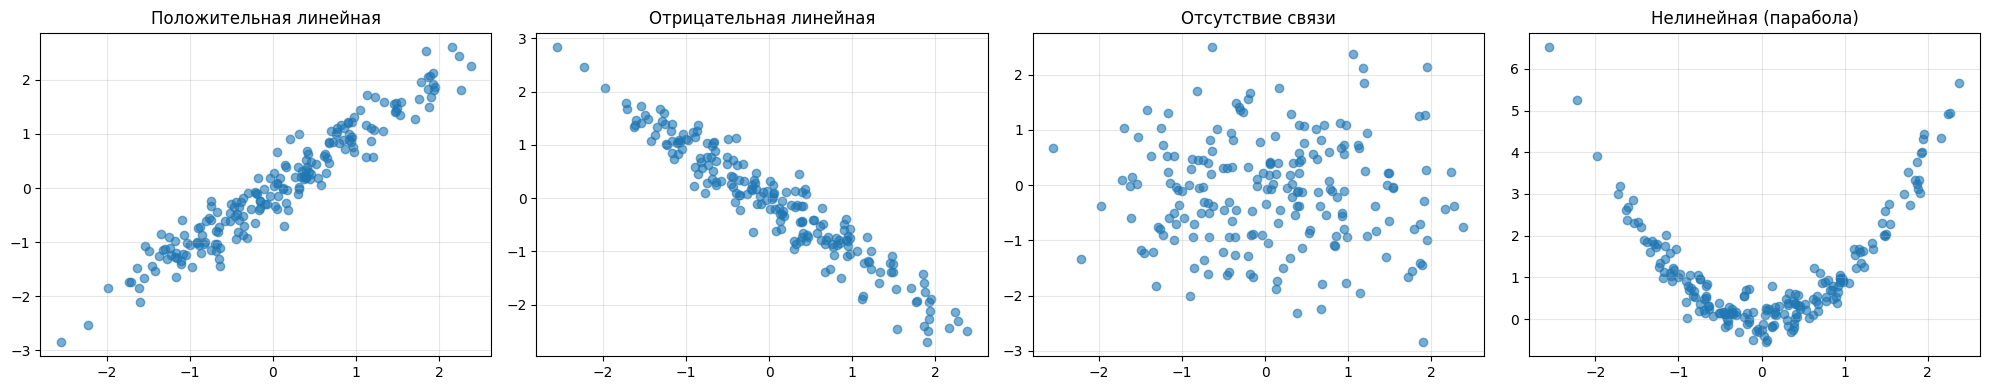

In [16]:
np.random.seed(0)
n = 200

fig, axes = plt.subplots(1, 4, figsize=(20, 4))

# 1. Сильная положительная связь
x1 = np.random.normal(size=n)
axes[0].scatter(x1, x1 + np.random.normal(scale=0.3, size=n), alpha=0.6)
axes[0].set_title('Положительная линейная')

# 2. Сильная отрицательная связь
axes[1].scatter(x1, -x1 + np.random.normal(scale=0.3, size=n), alpha=0.6)
axes[1].set_title('Отрицательная линейная')

# 3. Отсутствие связи
axes[2].scatter(x1, np.random.normal(size=n), alpha=0.6)
axes[2].set_title('Отсутствие связи')

# 4. Нелинейная (квадратичная) связь
axes[3].scatter(x1, x1**2 + np.random.normal(scale=0.3, size=n), alpha=0.6)
axes[3].set_title('Нелинейная (парабола)')

for ax in axes:
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



**Интерпретация.** Первые два графика демонстрируют классические линейные связи. Третий — отсутствие связи. Четвёртый — параболическую зависимость: коэффициент корреляции здесь близок к нулю, но связь очевидна визуально.

## 7.5. Соединение точечного графика с линейной регрессией

**Пример 7.3.** Для количественной оценки связи на точечный график удобно наложить **линию регрессии**.



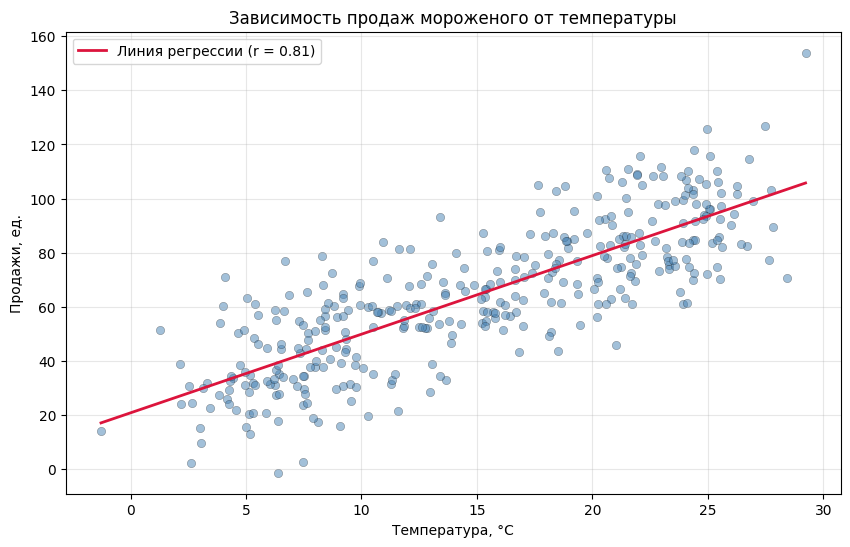

In [17]:
from numpy.polynomial import polynomial as P

# Оценка линейной регрессии методом наименьших квадратов
coeffs = np.polyfit(df['Temperature'], df['Sales'], deg=1)
x_line = np.linspace(df['Temperature'].min(), df['Temperature'].max(), 100)
y_line = np.polyval(coeffs, x_line)

# Коэффициент корреляции Пирсона
r = df['Temperature'].corr(df['Sales'])

plt.figure(figsize=(10, 6))
plt.scatter(df['Temperature'], df['Sales'],
            alpha=0.5, color='steelblue', edgecolor='k', linewidth=0.3)
plt.plot(x_line, y_line, color='crimson', linewidth=2,
         label=f'Линия регрессии (r = {r:.2f})')
plt.title('Зависимость продаж мороженого от температуры')
plt.xlabel('Температура, °C')
plt.ylabel('Продажи, ед.')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


**Разбор кода.** Функция `np.polyfit` оценивает коэффициенты линейной регрессии методом наименьших квадратов; `np.polyval` вычисляет предсказанные значения на заданной сетке. Коэффициент корреляции Пирсона `r` вычисляется методом `corr()`.

**Интерпретация.** Линия регрессии «проходит через центр» облака точек, наклон линии отражает силу и направление связи, а значение $r$ даёт количественную оценку тесноты линейной зависимости.

## 7.6. Сравнение с ранее рассмотренными инструментами

**Таблица 7.3.** Точечный график в системе инструментов визуализации

| Характеристика | Линейный | Гистограмма | Коррелограмма | Сезонный | Точечный |
|---|---|---|---|---|---|
| По оси X | время | значение | лаг | фаза сезона | значение $X$ |
| По оси Y | значение | частота | автокорреляция | значение | значение $Y$ |
| Число рядов | один | один | один | один | **два** |
| Отвечает на вопрос | как меняется во времени? | как распределено? | насколько «помнит» себя? | какова форма сезона? | как связаны $X$ и $Y$? |
| Соединение точек | линия | столбцы | столбцы | точки | точки |

**Замечание 7.5.** Точечный график — первый инструмент в нашем обзоре, который переходит от **одномерного** анализа (один временной ряд) к **двумерному** (совместное поведение двух рядов). Это открывает путь к построению регрессионных моделей и анализу причинно-следственных связей.

## 7.7. Выводы по разделу

В настоящем разделе:

1. дано определение точечного графика и перечислены решаемые с его помощью задачи;
2. построен точечный график зависимости продаж от температуры и разобрано назначение каждой инструкции;
3. проведена интерпретация — установлена сильная положительная линейная связь;
4. рассмотрены типовые формы точечных диаграмм и их связь с коэффициентом корреляции;
5. показано соединение точечного графика с линией регрессии;
6. выполнено сравнение с ранее рассмотренными инструментами визуализации.

Точечный график — **ключевой инструмент перехода от анализа одного временного ряда к анализу нескольких взаимосвязанных рядов**. Его применение обязательно перед расчётом корреляций и построением регрессионных моделей, поскольку только визуальный анализ позволяет надёжно отличить линейную связь от нелинейной и своевременно обнаружить кластеры и выбросы.

---

## 8. Общий обзор рассмотренных инструментов визуализации

**Таблица 8.1.** Сводная характеристика пяти инструментов визуализации временных рядов

| Инструмент | Размерность | Основная задача | Ключевой вывод |
|---|---|---|---|
| **Линейный график** | 1 | Динамика во времени | Тренд, сезонность, выбросы |
| **Гистограмма** | 1 | Распределение значений | Форма, асимметрия, модальность |
| **Коррелограмма** | 1 | Корреляционная структура | «Память» ряда, стационарность |
| **Сезонный график** | 1 | Форма сезонного профиля | Амплитуда и устойчивость сезонности |
| **Точечный график** | 2 | Взаимосвязь двух рядов | Направление, форма, сила связи |

Все пять инструментов образуют **взаимодополняющий комплекс** методов предварительного анализа временных рядов. Последовательное применение линейного графика, гистограммы, коррелограммы, сезонного графика и — при наличии нескольких рядов — точечного графика даёт аналитику полное представление о структуре данных и служит надёжной основой для выбора адекватной прогнозной модели.

# 8. Сглаживание (Smoothing Plots)

## 8.1. Определение и назначение

**Определение 8.1.** *Сглаживанием временного ряда* называется процедура преобразования исходного ряда $\{y_t\}$ в новый ряд $\{\hat{y}_t\}$, в котором случайные (шумовые) колебания ослаблены, а систематическая составляющая — **тренд и медленные сезонные волны** — сохранена.

**Определение 8.2.** *Графиком сглаживания (smoothing plot)* называется совместное изображение исходного временного ряда и одного или нескольких сглаженных рядов, построенных с помощью различных методов (скользящего среднего, экспоненциального сглаживания и др.).

Если линейный график (раздел 3) показывает ряд «как есть», включая весь шум, то сглаживание отвечает на вопрос: **«какова долговременная тенденция ряда, если абстрагироваться от ежедневных случайных колебаний?»**

Применение сглаживания в анализе временных рядов позволяет решить следующие задачи:

1. **выявление тренда** — сделать долговременную тенденцию видимой, «устранив» высокочастотный шум;
2. **обнаружение смены режима** — увидеть моменты, когда ряд меняет направление движения;
3. **выделение сезонной волны** — при большом окне сглаживания сезонные колебания тоже подавляются, остаётся только тренд;
4. **подготовка данных** — сглаженные значения часто используются как входные признаки для моделей машинного обучения;
5. **диагностика качества модели** — сравнение прогноза со сглаженным рядом помогает оценить, улавливает ли модель систематическую компоненту.

**Замечание 8.1.** Сглаживание **не является** моделью прогнозирования в строгом смысле. Это инструмент визуального анализа и подготовки данных. Тем не менее методы сглаживания (экспоненциальное сглаживание, метод Хольта–Уинтерса) лежат в основе целого класса прогнозных моделей.

## 8.2. Скользящее среднее (Rolling Mean)

**Определение 8.3.** *Скользящим средним* порядка $m$ (окно $m$) называется временной ряд

$$\hat{y}_t^{(m)} = \frac{1}{m} \sum_{i=0}^{m-1} y_{t-i}, \qquad t = m, m+1, \ldots, n.$$

Иными словами, каждое сглаженное значение — это среднее арифметическое $m$ последних наблюдений исходного ряда.

**Замечание 8.2.** Параметр $m$ (размер окна) управляет **компромиссом между гладкостью и точностью**:

- **малое окно** ($m = 7$) — сглаженный ряд близок к исходному, шум подавлен слабо, но детали сохранены;
- **большое окно** ($m = 30$ или $m = 90$) — линия становится очень гладкой, но реагирует на изменения с запаздыванием.

Эмпирическое правило: размер окна должен быть сопоставим с **периодом сезонности** (для недельной сезонности $m = 7$, для месячной $m = 30$, для годовой $m = 365$) либо заметно меньше него, если цель — сохранить сезонную волну.

**Пример 8.1.** Построим график сглаживания для синтетического ряда температуры, сгенерированного в разделе 2.



/usr/local/lib/python3.13/dist-packages/pandas/plotting/_matplotlib/core.py:981: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  return ax.plot(*args, **kwds)


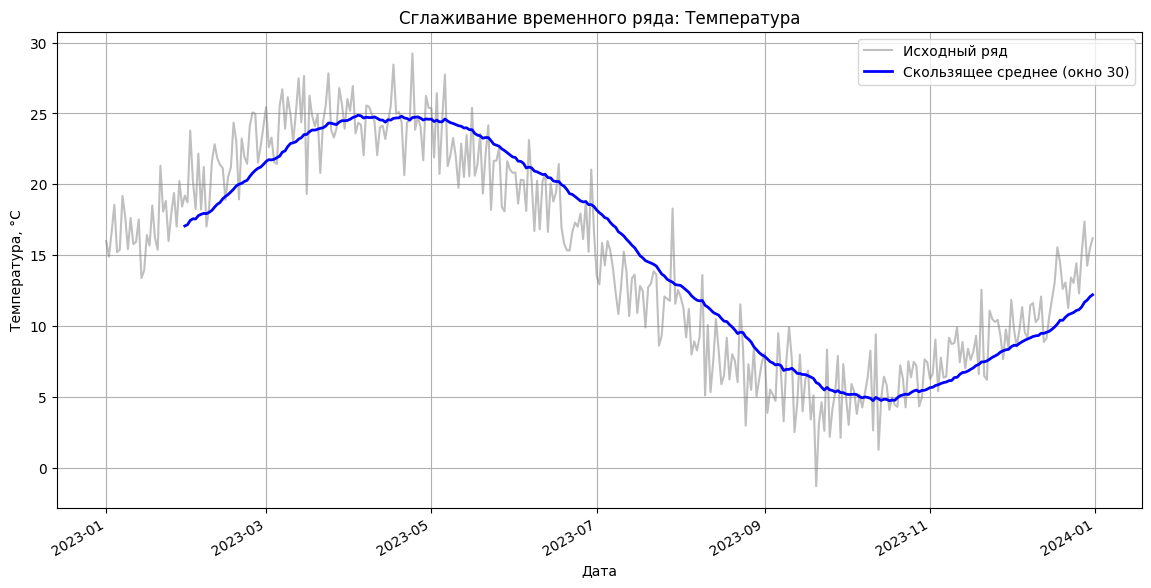

In [18]:
# Построение сглаженного графика
plt.figure(figsize=(14, 7))

# Исходный ряд (полупрозрачный серый)
plt.plot(df['Temperature'], color='gray', alpha=0.5, label='Исходный ряд')

# Скользящее среднее с окном 30 дней
df['Temperature'].rolling(window=30).mean().plot(
    color='blue', linewidth=2, label='Скользящее среднее (окно 30)')

plt.title('Сглаживание временного ряда: Температура')
plt.xlabel('Дата')
plt.ylabel('Температура, °C')
plt.legend()
plt.grid(True)
plt.show()



**Разбор кода.** Назначение основных инструкций приведено в таблице 8.1.

**Таблица 8.1.** Назначение инструкций построения графика сглаживания

| Инструкция | Назначение |
|---|---|
| `plt.plot(df['Temperature'], color='gray', alpha=0.5, ...)` | Отображение исходного ряда полупрозрачным серым цветом |
| `df['Temperature'].rolling(window=30).mean()` | Вычисление скользящего среднего с окном 30 дней |
| `.plot(color='blue', linewidth=2, ...)` | Построение сглаженного ряда толстой синей линией |
| `plt.legend()` | Вывод легенды с названиями обоих рядов |
| `plt.grid(True)` | Включение координатной сетки |

**Замечание 8.3.** Метод `rolling(window=30)` по умолчанию создаёт окно, «смотрящее назад»: значение в момент $t$ усредняет наблюдения $y_{t-29}, \ldots, y_t$. Первые 29 значений сглаженного ряда будут `NaN` — они автоматически не отображаются на графике.

## 8.3. Интерпретация графика сглаживания

На построенном графике (пример 8.1) наблюдаются следующие особенности.

1. **Исходный ряд (серый)** — «дрожащая» синусоида. Ежедневные случайные колебания создают визуальный шум, затрудняющий оценку медленной динамики.

2. **Сглаженный ряд (синий)** — плавная волна. Скользящее среднее с окном 30 дней подавило дневной шум, но сохранило **годовую сезонную компоненту**. Видно, что зимой сглаженный ряд уходит в отрицательную область, летом — в положительную.

3. **Запаздывание (lag).** Синяя линия отстаёт от серой примерно на половину окна: пик сглаженного ряда наступает позже, чем пик исходного. Это **принципиальное свойство скользящего среднего** — плата за сглаживание.

4. **Уменьшение амплитуды.** Размах колебаний синей линии меньше, чем у серой. Чем больше окно, тем сильнее «сжимается» амплитуда. При $m = 365$ сглаженный ряд выродился бы почти в горизонтальную линию.

**Замечание 8.4.** На графике сглаживания **не следует ожидать, что сглаженный ряд совпадёт с истинной сезонной компонентой**. Скользящее среднее — это инструмент визуального анализа, а не декомпозиции. Для строгого выделения компонент используют методы STL-декомпозиции или модель Хольта–Уинтерса.

## 8.4. Влияние размера окна

Различные окна сглаживания дают разные компромиссы между гладкостью и реактивностью. Для иллюстрации построим три сглаженных ряда с окнами 7, 30 и 90 дней.



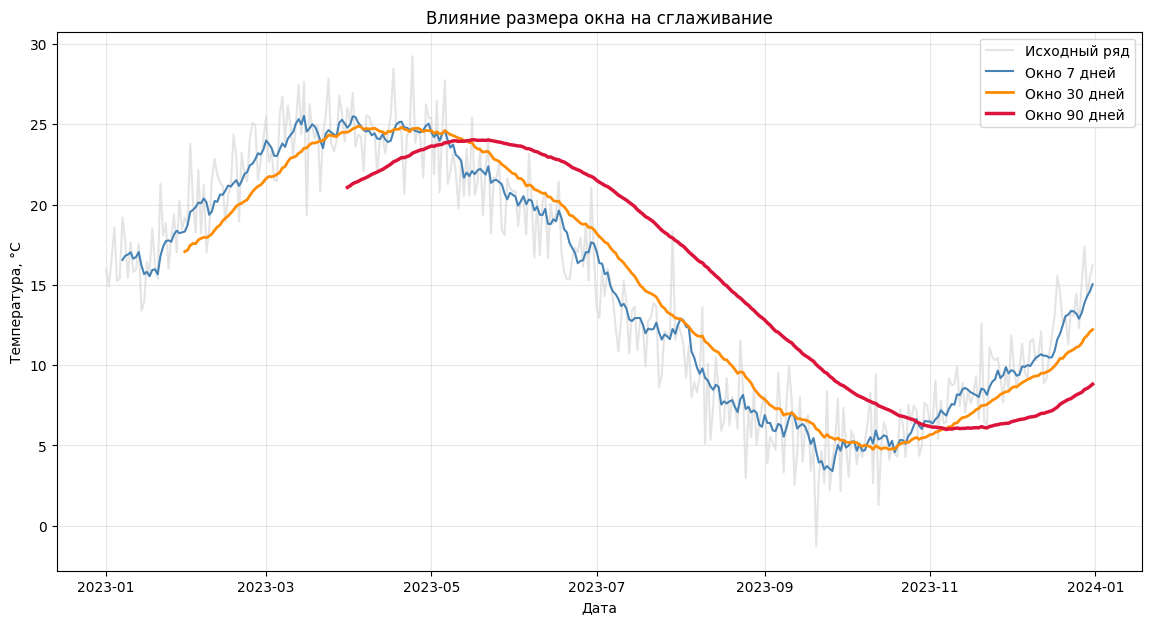

In [19]:
plt.figure(figsize=(14, 7))

plt.plot(df['Temperature'], color='lightgray', alpha=0.6, label='Исходный ряд')
plt.plot(df['Temperature'].rolling(7).mean(),  color='steelblue',
         linewidth=1.5, label='Окно 7 дней')
plt.plot(df['Temperature'].rolling(30).mean(), color='darkorange',
         linewidth=2,   label='Окно 30 дней')
plt.plot(df['Temperature'].rolling(90).mean(), color='crimson',
         linewidth=2.5, label='Окно 90 дней')

plt.title('Влияние размера окна на сглаживание')
plt.xlabel('Дата')
plt.ylabel('Температура, °C')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


**Таблица 8.2.** Сравнение размеров окна сглаживания

| Окно | Характер линии | Что сохраняет | Что подавляет |
|---|---|---|---|
| 7 дней | почти повторяет исходный ряд | дневные детали | очень высокочастотный шум |
| 30 дней | умеренно гладкая | месячные тенденции | дневной шум |
| 90 дней | очень гладкая | сезонную волну | дневной и недельный шум |
| 365 дней | почти горизонталь | только годовой тренд | всю сезонность |

**Замечание 8.5.** Выбор окна определяется **целью анализа**. Если цель — визуально оценить общий тренд, выбирают большое окно. Если нужно увидеть, как ряд вёл себя в конкретные периоды, — малое. Универсального «правильного» значения не существует.

## 8.5. Экспоненциальное сглаживание (Exponential Smoothing)

**Определение 8.4.** *Простым экспоненциальным сглаживанием* называется рекуррентная процедура

$$\hat{y}_t = \alpha y_t + (1 - \alpha)\hat{y}_{t-1}, \qquad 0 < \alpha < 1,$$

где $\alpha$ — *параметр сглаживания*, определяющий вес последнего наблюдения.

Раскрывая рекурсию, получаем эквивалентное представление:

$$\hat{y}_t = \alpha \sum_{i=0}^{\infty} (1 - \alpha)^i y_{t-i},$$

то есть сглаженное значение есть **взвешенное среднее всех прошлых наблюдений** с экспоненциально убывающими весами. В отличие от скользящего среднего, где окно конечно, здесь учитываются **все** прошлые значения, но старым наблюдениям придаётся всё меньший вес.

**Замечание 8.6.** Ключевое отличие от скользящего среднего:

- **скользящее среднее** — веса одинаковы для всех $m$ последних точек и равны нулю для более старых;
- **экспоненциальное сглаживание** — веса монотонно убывают, но никогда не обращаются в ноль.

**Пример 8.2.** Построим график экспоненциального сглаживания с различными $\alpha$.



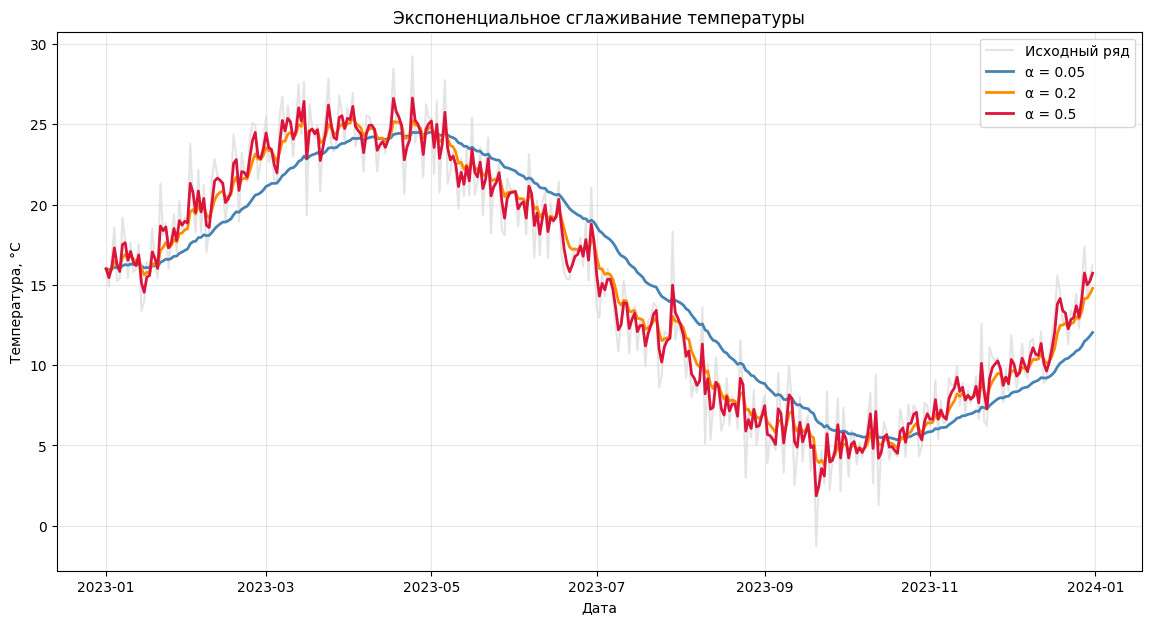

In [20]:
plt.figure(figsize=(14, 7))

plt.plot(df['Temperature'], color='lightgray', alpha=0.6, label='Исходный ряд')

# Различные значения параметра alpha
for alpha, color in [(0.05, 'steelblue'),
                     (0.2,  'darkorange'),
                     (0.5,  'crimson')]:
    smoothed = df['Temperature'].ewm(alpha=alpha, adjust=False).mean()
    plt.plot(smoothed, color=color, linewidth=2, label=f'α = {alpha}')

plt.title('Экспоненциальное сглаживание температуры')
plt.xlabel('Дата')
plt.ylabel('Температура, °C')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()



**Разбор кода.** Метод `ewm(alpha=alpha, adjust=False).mean()` реализует экспоненциально взвешенное среднее: параметр `adjust=False` обеспечивает рекуррентную формулу из определения 8.4.

**Интерпретация.** Параметр $\alpha$ управляет «памятью» сглаживания:

- **$\alpha = 0{,}05$** — сглаженный ряд почти не реагирует на отдельные точки, «помнит» далёкое прошлое, сильно запаздывает;
- **$\alpha = 0{,}2$** — компромиссное значение: сохраняется общая динамика, шум подавлен умеренно;
- **$\alpha = 0{,}5$** — сглаженный ряд почти повторяет исходный, реагирует быстро, но шум подавлен слабо.

**Таблица 8.3.** Влияние параметра $\alpha$ на сглаживание

| $\alpha$ | «Память» | Реакция на изменения | Степень сглаживания |
|---|---|---|---|
| Близко к 0 | длинная | медленная | сильная |
| Близко к 1 | короткая | быстрая | слабая |

**Замечание 8.7.** Оптимальное значение $\alpha$ в прогнозных моделях подбирается **минимизацией ошибки прогноза** (например, MSE или MAPE) на исторических данных. В задачах визуального анализа значение $\alpha$ выбирается эмпирически, исходя из желаемой гладкости.

## 8.6. Сравнение методов сглаживания

**Таблица 8.4.** Скользящее среднее и экспоненциальное сглаживание: сопоставление

| Характеристика | Скользящее среднее | Экспоненциальное сглаживание |
|---|---|---|
| Параметр | размер окна $m$ | коэффициент $\alpha$ |
| Учёт прошлых значений | только $m$ последних | все прошлые |
| Веса | одинаковые | экспоненциально убывающие |
| Краевые эффекты | первые $m-1$ значений отсутствуют | ряд определён на всём интервале |
| Вычислительная сложность | $O(n \cdot m)$ | $O(n)$ |
| Чувствительность к выбросам | умеренная | сильная при больших $\alpha$ |

**Замечание 8.8.** На практике оба метода применяются **совместно**: скользящее среднее даёт «нейтральную» оценку тренда, не чувствительную к выбору начала ряда, а экспоненциальное сглаживание лучше адаптируется к свежим данным. Сравнение нескольких сглаженных рядов на одном графике (как в примерах 8.1 и 8.2) позволяет выбрать наиболее содержательный вариант для конкретной задачи.

## 8.7. Место сглаживания в предварительном анализе

**Таблица 8.5.** Сглаживание в системе инструментов визуализации

| Характеристика | Линейный | Гистограмма | Коррелограмма | Сезонный | Точечный | Сглаживание |
|---|---|---|---|---|---|---|
| По оси X | время | значение | лаг | фаза сезона | значение $X$ | время |
| Число рядов | один | один | один | один | два | один (несколько версий) |
| Основная задача | динамика | распределение | корреляция | сезонный профиль | связь $X$–$Y$ | выделение тренда |

**Замечание 8.9.** Сглаживание **не заменяет** другие инструменты, а **дополняет** их:

- **линейный график** показывает ряд во всех деталях, включая шум;
- **сглаживание** помогает «увидеть» тренд за шумом;
- **коррелограмма** объясняет, почему сглаживание эффективно (если АКФ быстро убывает, шум доминирует);
- **сезонный график** уточняет, какую часть колебаний следует считать систематической, а какую — случайной.

## 8.8. Выводы по разделу

В настоящем разделе:

1. дано определение сглаживания временного ряда и графика сглаживания;
2. перечислены задачи, решаемые с помощью сглаживания;
3. рассмотрено скользящее среднее как базовый метод сглаживания и разобрано назначение каждой инструкции построения графика;
4. проведена интерпретация — установлены эффекты **запаздывания** и **уменьшения амплитуды**;
5. исследовано влияние размера окна на степень сглаживания;
6. рассмотрено экспоненциальное сглаживание и влияние параметра $\alpha$;
7. выполнено сравнение двух методов сглаживания;
8. определено место сглаживания в общей системе инструментов визуализации.

Сглаживание — **завершающий этап визуального предварительного анализа** временного ряда. Если линейный график, гистограмма, коррелограмма, сезонный и точечный графики позволяют описать **структуру** ряда, то сглаживание — сформулировать **содержательные гипотезы о его тренде**, которые затем проверяются статистическими методами (тест Дики–Фуллера на стационарность, тест Манна–Кендалла на тренд) и учитываются при выборе прогнозной модели.

# 9. Контурные графики (Contour Plots)

## 9.1. Определение и назначение

**Определение 9.1.** *Контурным графиком* (или *графиком уровней*) называется графическое представление скалярной функции двух переменных $z = f(x, y)$, на котором линии постоянного значения $z = c$ (называемые *линиями уровня* или *изолиниями*) изображены на плоскости $(x, y)$.

**Определение 9.2.** *Залитым контурным графиком (filled contour plot)* называется контурный график, в котором области между соседними линиями уровня закрашены цветом, соответствующим значению $z$. Залитый контурный график эквивалентен **тепловой карте (heatmap)**.

**Замечание 9.1.** Контурный график — первый инструмент в настоящем обзоре, предназначенный для визуализации **трёхмерных** данных. Если ранее ось времени откладывалась только по оси абсцисс, то теперь появляется возможность отобразить **две независимые временны́е шкалы одновременно** (например, час суток и день года), а значение показателя — цветом.

Применение контурных графиков в анализе временных рядов позволяет решить следующие задачи:

1. **визуализация двумерной сезонности** — одновременный учёт двух циклических факторов (например, часа суток и сезона года);
2. **выявление совместных закономерностей** — как взаимодействуют две временны́е шкалы при формировании значения показателя;
3. **обнаружение аномалий в двумерном пространстве** — области с необычно высокими или низкими значениями;
4. **компактное представление больших объёмов данных** — на одном графике помещаются десятки тысяч наблюдений;
5. **сравнение режимов** — сопоставление нескольких периодов (например, разных лет) в единой системе координат.

**Замечание 9.2.** Контурный график особенно полезен в задачах **энергетики** (потребление электроэнергии в зависимости от часа суток и сезона), **метеорологии** (температура в зависимости от часа и дня года), **транспорта** (интенсивность трафика в зависимости от часа и дня недели), **ритейла** (продажи в зависимости от дня недели и месяца).

## 9.2. Математическая основа

Контурный график строится для функции двух переменных $z = f(x, y)$. Наблюдения временного ряда можно представить в такой форме, если ввести две временны́е координаты:

$$z_{i,j} = f(x_i, y_j), \qquad i = 1, \ldots, n_x, \quad j = 1, \ldots, n_y,$$

где $x_i$ и $y_j$ — значения двух временны́х шкал (например, $x$ — час суток, $y$ — день года), а $z_{i,j}$ — значение показателя в соответствующей точке.

**Определение 9.3.** *Линией уровня* функции $f$ для значения $c$ называется множество точек

$$L_c = \{(x, y) : f(x, y) = c\}.$$

Совокупность линий уровня $\{L_{c_1}, L_{c_2}, \ldots\}$ для возрастающих значений $c_1 < c_2 < \ldots$ полностью характеризует функцию $f$ и называется её **контурным графиком**.

**Замечание 9.3.** В отличие от линейного графика, на контурном графике **нет явной оси ординат для значения $z$**: величина показателя закодирована цветом (или расстоянием между линиями уровня). Поэтому к контурному графику всегда прилагается **цветовая шкала (colorbar)**, сопоставляющая цвет значениям.

## 9.3. Построение контурного графика двумерной сезонности

**Пример 9.1.** Рассмотрим синтетический пример: суточное потребление электроэнергии, зависящее одновременно от **часа суток** и **дня года**. Предположим, что потребление максимально зимой в вечерние часы (отопление и освещение) и минимально летом ночью.

### 9.3.1. Генерация данных



In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Сетка: 24 часа × 365 дней
hours = np.arange(24)
days = np.arange(365)

# Формируем сетку двумерных координат
H, D = np.meshgrid(hours, days)

# Модель потребления: суточный профиль + годовой профиль + шум
daily_profile = 20 + 15 * np.cos((H - 19) * 2 * np.pi / 24)   # вечерний пик
yearly_profile = 5 * np.cos((D - 0) * 2 * np.pi / 365)          # зимний пик
noise = np.random.normal(scale=1.5, size=H.shape)

consumption = 100 + daily_profile * (1 + 0.3 * yearly_profile / 5) + noise



**Разбор кода.** Назначение основных инструкций приведено в таблице 9.1.

**Таблица 9.1.** Назначение инструкций подготовки данных

| Инструкция | Назначение |
|---|---|
| `hours = np.arange(24)`, `days = np.arange(365)` | Задание двух временны́х шкал — часа суток и дня года |
| `H, D = np.meshgrid(hours, days)` | Построение двумерной сетки координат $(H, D)$ для всех комбинаций |
| `daily_profile = 20 + 15 * np.cos(...)` | Модель суточного профиля с максимумом около 19:00 |
| `yearly_profile = 5 * np.cos(...)` | Модель годового профиля с максимумом зимой |
| `consumption = ...` | Итоговая модель: суточный профиль, модулированный годовым, с шумом |

**Замечание 9.4.** Функция `np.meshgrid` — ключевой инструмент для работы с двумерными данными. Она строит **полную сетку** всех пар $(H, D)$, что позволяет вычислить значение функции сразу во всех точках.

### 9.3.2. Сглаживание данных

**Замечание 9.5.** «Сырые» данные содержат случайный шум, из-за чего линии уровня на контурном графике получаются «рваными» и нечитаемыми. Поэтому перед построением графика данные необходимо **сгладить** — усреднить по соседним точкам вдоль одной из осей.



In [28]:

# Сглаживание по дням: скользящее среднее с окном 15 дней
consumption_smooth = (
    pd.DataFrame(consumption).T
    .rolling(window=15, center=True, min_periods=1)
    .mean()
    .T
    .values
)
# Диагностика: убедимся, что NaN не осталось
print("NaN в массиве:", np.isnan(consumption_smooth).sum())
print("Диапазон значений:", consumption_smooth.min(), "—", consumption_smooth.max())

NaN в массиве: 0
Диапазон значений: 106.96658501096425 — 142.74762202720586






**Замечание 9.6.** Параметр `min_periods=1` принципиально важен. Без него метод `rolling` оставляет `NaN` в первых и последних 7 днях (там, где полное окно не помещается), и функция `plt.contourf` завершается ошибкой `ValueError: lower_level and upper_level cannot be NaN`. Установка `min_periods=1` разрешает вычислять среднее по неполному окну — края ряда остаются заполненными.

### 9.3.3. Построение залитого контурного графика с линиями уровня

Для наглядного представления структуры данных применяют **комбинированный подход**: заливка (`contourf`) показывает общую картину, а линии уровня (`contour`) с подписями (`clabel`) — точные значения.




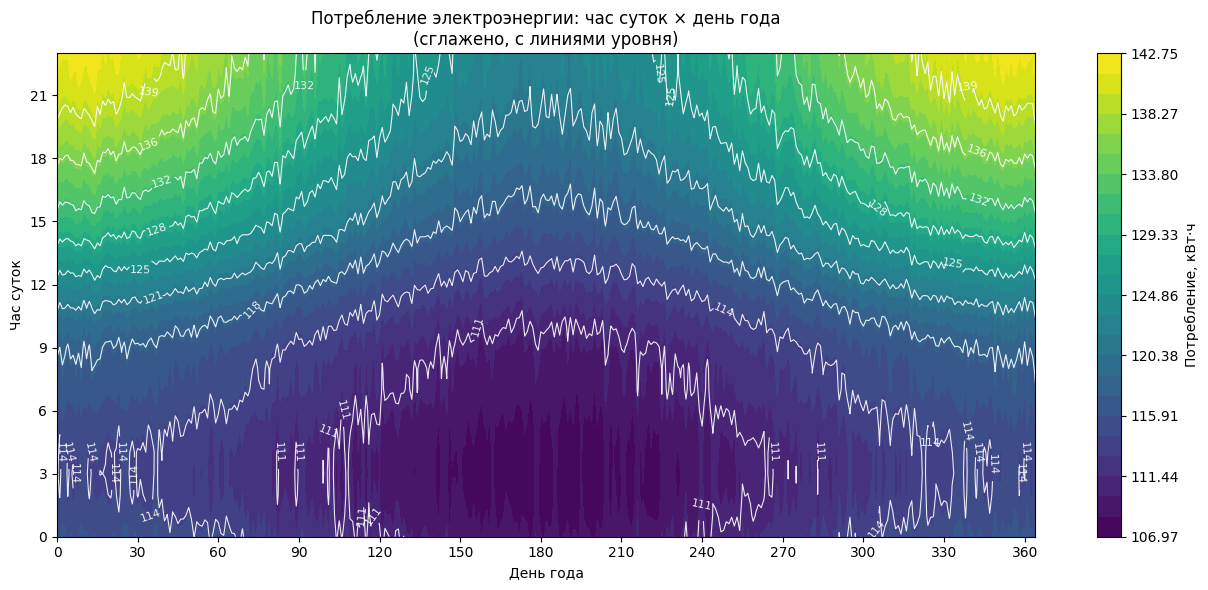

In [29]:
# Построение графика
fig, ax = plt.subplots(figsize=(13, 6))

# 1. Залитый контурный график
levels_fill = np.linspace(consumption_smooth.min(),
                          consumption_smooth.max(), 25)
cf = ax.contourf(D, H, consumption_smooth,
                 levels=levels_fill, cmap='viridis')

# 2. Линии уровня поверх заливки
levels_lines = np.linspace(consumption_smooth.min(),
                           consumption_smooth.max(), 11)
cs = ax.contour(D, H, consumption_smooth,
                levels=levels_lines,
                colors='white', linewidths=0.8, alpha=0.9)

# 3. Подписи значений на линиях уровня
ax.clabel(cs, inline=True, fontsize=8, fmt='%.0f', colors='white')

# 4. Цветовая шкала
plt.colorbar(cf, ax=ax, label='Потребление, кВт·ч')

# 5. Оформление
ax.set_title('Потребление электроэнергии: час суток × день года\n'
             '(сглажено, с линиями уровня)')
ax.set_xlabel('День года')
ax.set_ylabel('Час суток')
ax.set_xticks(np.arange(0, 366, 30))
ax.set_yticks(np.arange(0, 24, 3))

plt.tight_layout()
plt.show()



**Разбор кода.** Назначение основных инструкций приведено в таблице 9.2.

**Таблица 9.2.** Назначение инструкций построения контурного графика

| Инструкция | Назначение |
|---|---|
| `plt.contourf(D, H, consumption_smooth, ...)` | Построение залитого контурного графика с 25 уровнями заливки |
| `plt.contour(D, H, consumption_smooth, ...)` | Построение линий уровня поверх заливки (11 линий) |
| `ax.clabel(cs, inline=True, fmt='%.0f', ...)` | Подписи значений на линиях уровня; `inline=True` разрывает линию под текстом |
| `plt.colorbar(cf, ...)` | Добавление цветовой шкалы с подписью |
| `ax.set_xticks(np.arange(0, 366, 30))` | Регулировка шага подписей по оси X (каждые 30 дней) |
| `ax.set_yticks(np.arange(0, 24, 3))` | Регулировка шага подписей по оси Y (каждые 3 часа) |

**Замечание 9.7.** Ключевой приём — **комбинирование заливки и линий**. Одна только заливка (как на тепловой карте) даёт представление о структуре, но не позволяет считать точные значения. Один только `contour` без заливки читается легко, но не даёт общей картины. Совместное применение обоих методов с подписями `clabel` — оптимальный вариант.

**Замечание 9.8.** Выбор **белого цвета** для линий уровня на тёмной палитре `viridis` обеспечивает максимальный контраст. Число линий (11) выбрано так, чтобы они не сливались: при 20+ линиях картинка становится «шумной».

## 9.4. Интерпретация контурного графика

На построенном графике (пример 9.1) наблюдаются следующие особенности двумерной структуры потребления.

1. **Горизонтальные полосы** — **суточная сезонность**. В каждом дне года потребление имеет характерный профиль: минимум в ночные часы (около 3:00), резкий рост к вечернему пику (около 19:00). Горизонтальные полосы одинаковой высоты повторяются на всех днях — это визуальное проявление суточного цикла.

2. **Вертикальные полосы** — **годовая сезонность**. Потребление систематически выше зимой (левая и правая части графика) и ниже летом (центральная часть). Вертикальные полосы, «проходящие» через все часы суток, отражают годовой цикл.

3. **Взаимодействие двух циклов.** На пересечении суточного и годового профилей образуются **«горячие точки»** (жёлто-оранжевые области) в зимние вечерние часы и **«холодные точки»** (сине-фиолетовые) в летние ночные часы. Именно области пересечения двух циклов дают экстремальные значения.

4. **Линии уровня.** Изолинии имеют ярко выраженную **горизонтальную ориентацию** в областях суточного пика и **замкнутую форму** в точках экстремума. Подписи на линиях (например, «130», «135», «140») позволяют считывать конкретные значения прямо с графика.

5. **Смещение пиков.** Вечерний пик зимой **выше**, чем летом, — это результат модуляции суточного профиля годовой амплитудой. Такое взаимодействие двух факторов (мультипликативный эффект) невозможно увидеть на одномерных графиках.

**Замечание 9.9.** Контурный график позволяет **одновременно** обнаружить два типа сезонности и оценить их взаимодействие. Никакой из ранее рассмотренных инструментов (линейный график, гистограмма, коррелограмма, сезонный график, сглаживание) не справляется с этой задачей столь же наглядно.

## 9.5. Сравнение с тепловой картой

**Замечание 9.10.** Понятия «залитый контурный график» и «тепловая карта» **эквивалентны** с точки зрения передаваемой информации. Различие — в способе построения:

- **контурный график** (`contour` / `contourf`) интерполирует значения между узлами сетки и строит уровни;
- **тепловая карта** (`pcolormesh` / `imshow`) отображает каждый узел сетки отдельным прямоугольником.

Для регулярной плотной сетки (как в примере 9.1: 24 × 365 узлов) результаты визуально почти неотличимы. Однако **контурный график предпочтительнее**, если нужно:

1. **видеть линии уровня** — границы областей с равным значением;
2. **считывать точные значения** — подписи на линиях;
3. **плавнее передавать структуру** — интерполяция сглаживает границы ячеек.



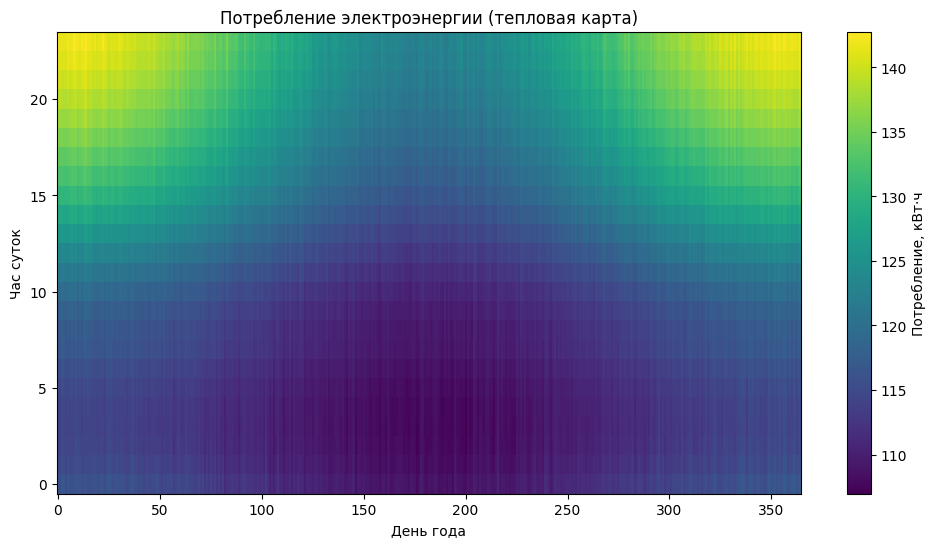

In [30]:
# Альтернатива: тепловая карта через pcolormesh
plt.figure(figsize=(12, 6))
pm = plt.pcolormesh(D, H, consumption_smooth, cmap='viridis', shading='auto')
plt.colorbar(pm, label='Потребление, кВт·ч')
plt.title('Потребление электроэнергии (тепловая карта)')
plt.xlabel('День года')
plt.ylabel('Час суток')
plt.show()



**Разбор кода.** Функция `plt.pcolormesh` строит псевдоцветовое изображение, где цвет каждой ячейки определяется соответствующим значением. Параметр `shading='auto'` автоматически подбирает способ закраски в зависимости от размеров сетки. Линии уровня в этом варианте **отсутствуют** — тепловая карта показывает только заливку.

## 9.6. Пример: температура как функция часа и дня года

**Пример 9.2.** Рассмотрим контурный график температуры за один год, где по осям откладываются **час суток** и **день года**.



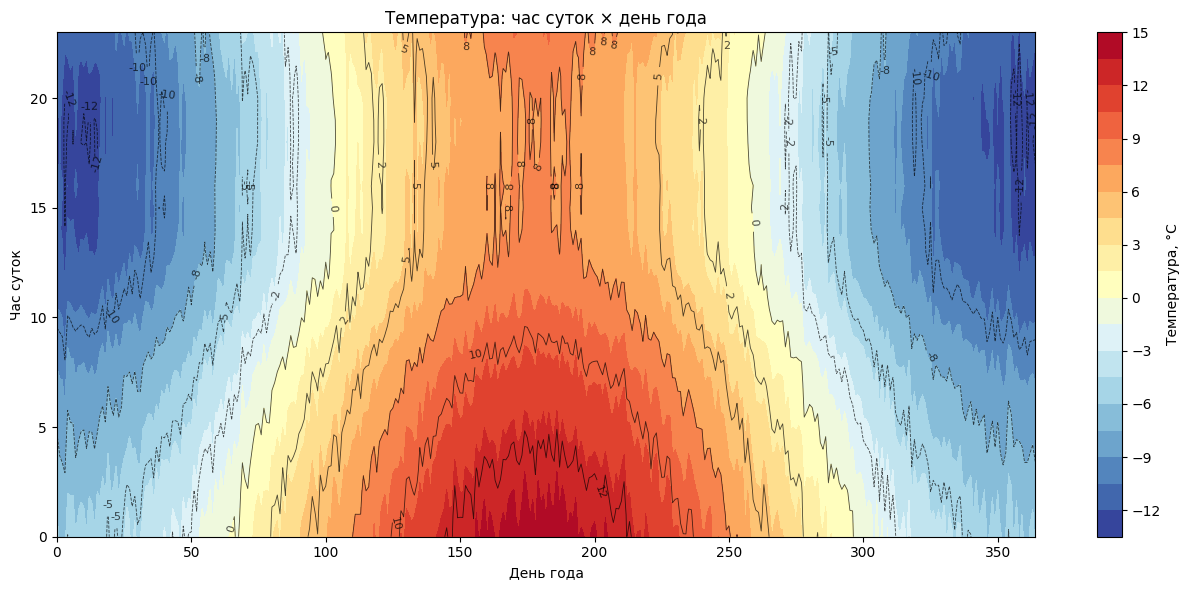

In [31]:
# Сетка 24 × 365
hours = np.arange(24)
days = np.arange(365)
H, D = np.meshgrid(hours, days)

# Модель температуры:
#  - годовой цикл (холодно зимой, тепло летом)
#  - суточный цикл (холодно ночью, тепло днём)
temperature_2d = (
    10 * np.cos((D - 180) * 2 * np.pi / 365)             # годовой цикл
    - 5  * np.cos((H - 15) * 2 * np.pi / 24)             # суточный цикл
    + np.random.normal(scale=1, size=H.shape)            # шум
)

# Сглаживание по дням
temperature_smooth = (
    pd.DataFrame(temperature_2d).T
    .rolling(window=15, center=True, min_periods=1)
    .mean()
    .T
    .values
)

# Построение
fig, ax = plt.subplots(figsize=(13, 6))

cf = ax.contourf(D, H, temperature_smooth, levels=25, cmap='RdYlBu_r')
cs = ax.contour(D, H, temperature_smooth, levels=11,
                colors='black', linewidths=0.6, alpha=0.7)
ax.clabel(cs, inline=True, fontsize=8, fmt='%.0f')

plt.colorbar(cf, ax=ax, label='Температура, °C')
ax.set_title('Температура: час суток × день года')
ax.set_xlabel('День года')
ax.set_ylabel('Час суток')
plt.tight_layout()
plt.show()


**Интерпретация.** На графике отчётливо видны:

1. **Вертикальный градиент** — изменение температуры от зимы к лету (годовая сезонность).
2. **Горизонтальная структура внутри каждого дня** — наклонные линии уровня, отражающие суточный ход температуры: минимум около 4:00, максимум около 15:00.
3. **Смена знака** — красная область летом переходит в синюю зимой, что соответствует переходу через 0 °C.

**Замечание 9.11.** Выбор цветовой карты (colormap) играет важную роль. Для температурных данных естественно использовать **дивергентную палитру** (`RdYlBu_r`), в которой средний цвет (жёлтый) соответствует нулю, а крайние (синий и красный) — отрицательным и положительным значениям. Это облегчает визуальное определение границы перехода через ноль. Для температурных изолиний **чёрный цвет** предпочтительнее белого, поскольку заливка содержит светлые области.

## 9.7. Преимущества и ограничения контурных графиков

**Таблица 9.3.** Преимущества и ограничения контурных графиков

| Преимущества | Ограничения |
|---|---|
| Отображение трёх измерений на плоскости | Требуется регулярная сетка данных |
| Компактная передача больших массивов | Зависимость от выбора цветовой палитры |
| Возможность обнаружить взаимодействие факторов | Сложнее считывать точные значения, чем с линейного графика |
| Наглядное сравнение режимов | Плохо подходит для нерегулярных или пропущенных данных |
| Линии уровня позволяют считывать конкретные значения | Требует предварительного сглаживания |

**Замечание 9.12.** Контурный график следует применять **осторожно** при малом числе наблюдений: интерполяция между редкими точками может создавать ложное впечатление плавной структуры. Как правило, для контурного графика необходимо **не менее нескольких сотен** наблюдений. Кроме того, «сырые» данные с высоким уровнем шума обязательно сглаживают — иначе линии уровня становятся «рваными» и нечитаемыми.

## 9.8. Место контурного графика в системе инструментов визуализации

**Таблица 9.4.** Контурный график в системе инструментов визуализации

| Характеристика | Линейный | Гистограмма | Коррелограмма | Сезонный | Точечный | Сглаживание | Контурный |
|---|---|---|---|---|---|---|---|
| По оси X | время | значение | лаг | фаза сезона | значение $X$ | время | время-1 |
| По оси Y | значение | частота | АКФ | значение | значение $Y$ | — | время-2 |
| Значение показателя | ось Y | ось Y | ось Y | ось Y | ось Y | ось Y | **цвет** |
| Число измерений | 1 | 1 | 1 | 1 | 2 | 1 | **3** |
| Основная задача | динамика | распределение | корреляция | сезонный профиль | связь $X$–$Y$ | тренд | двумерная сезонность |

**Замечание 9.13.** Контурный график — **единственный** из рассмотренных инструментов, позволяющий одновременно визуализировать **две временны́е шкалы и значение показателя**. Это делает его незаменимым в задачах, где показатель формируется под влиянием нескольких циклических факторов (энергетика, транспорт, метеорология).

## 9.9. Выводы по разделу

В настоящем разделе:

1. дано определение контурного графика и его частного случая — тепловой карты;
2. раскрыта математическая основа построения контурных графиков (линии уровня, сетка, интерполяция);
3. построен контурный график суточного потребления электроэнергии — с обязательным **предварительным сглаживанием** данных и **наложением линий уровня** с подписями;
4. проведена интерпретация — установлено взаимодействие суточной и годовой сезонности;
5. рассмотрено альтернативное представление через тепловую карту;
6. приведён второй пример — температура как функция часа и дня года, с использованием дивергентной палитры;
7. сформулированы преимущества и ограничения метода;
8. определено место контурного графика в общей системе инструментов визуализации.

**Замечание 9.14.** Контурный график — **завершающий и наиболее информативный инструмент** визуализации временных рядов в случае, когда данные допускают представление в виде функции двух временны́х координат. Он позволяет обнаружить **взаимодействие двух циклических факторов**, что принципиально невозможно сделать с помощью одномерных графиков. При этом контурный график следует применять в комплексе с другими инструментами: линейный график и сглаживание — для анализа динамики, гистограмма — для оценки распределения, коррелограмма — для выбора модели, сезонный и точечный графики — для анализа компонент, и, наконец, контурный график — для выявления двумерных закономерностей.

# 10. Диаграммы размахов (Box Plots)

## 10.1. Определение и назначение

**Определение 10.1.** *Диаграммой размахов* (или *ящичной диаграммой*, *box plot*) называется графическое представление распределения значений числовой переменной, в котором отображаются пять ключевых статистических характеристик: **минимум, первый квартиль, медиана, третий квартиль и максимум**, а также отдельно выделяются наблюдения, признанные выбросами.

**Определение 10.2.** *Квартилями* называются значения, делящие упорядоченную выборку на четыре равные по числу наблюдений части:

- $Q_1$ — первый квартиль (25 % наблюдений меньше этого значения);
- $Q_2$ — второй квартиль, или **медиана** (50 % наблюдений меньше);
- $Q_3$ — третий квартиль (75 % наблюдений меньше).

**Определение 10.3.** *Межквартильным размахом (IQR)* называется разность

$$\mathrm{IQR} = Q_3 - Q_1.$$

Границы «усов» диаграммы размахов определяются как

$$L_{\text{low}} = \max\bigl(\min(y),\ Q_1 - 1{,}5 \cdot \mathrm{IQR}\bigr), \qquad L_{\text{high}} = \min\bigl(\max(y),\ Q_3 + 1{,}5 \cdot \mathrm{IQR}\bigr).$$

Наблюдения, лежащие за пределами этих границ, отмечаются отдельными точками и считаются **потенциальными выбросами**.

**Замечание 10.1.** Диаграмма размахов — **первый инструмент в настоящем обзоре, объединяющий визуализацию и статистическое описание**. Если гистограмма (раздел 4) показывает форму распределения, то диаграмма размахов даёт компактное числовое резюме: медиану, квартили и границы «нормальных» значений. Именно поэтому диаграммы размахов широко применяются для **сравнения нескольких групп** наблюдений.

Применение диаграмм размахов в анализе временных рядов позволяет решить следующие задачи:

1. **сравнение распределений по сезонам** — например, температуры по месяцам или продаж по дням недели;
2. **выявление выбросов** — дни, резко выпадающие из общего поведения месяца;
3. **оценка разброса** — насколько велика вариабельность значений внутри каждой группы;
4. **обнаружение асимметрии** — смещение медианы относительно центра ящика;
5. **сравнение нескольких временных рядов** — сопоставление одного и того же показателя для разных объектов.

**Замечание 10.2.** В отличие от гистограммы, диаграмма размахов **устойчива к выбросам** в оценке типичного уровня (медиана не смещается от одного аномального наблюдения), но при этом **явно выделяет** сами выбросы. Это сочетание делает её незаменимой в задачах контроля качества и обнаружения аномалий.

## 10.2. Структура диаграммы размахов

**Определение 10.4.** *Стандартная диаграмма размахов* состоит из следующих элементов:

1. **Ящик** — прямоугольник от $Q_1$ до $Q_3$, охватывающий центральные 50 % наблюдений;
2. **Медиана** — горизонтальная линия внутри ящика;
3. **Усы (whiskers)** — вертикальные отрезки от ящика до границ $L_{\text{low}}$ и $L_{\text{high}}$;
4. **Выбросы** — отдельные точки за пределами усов.



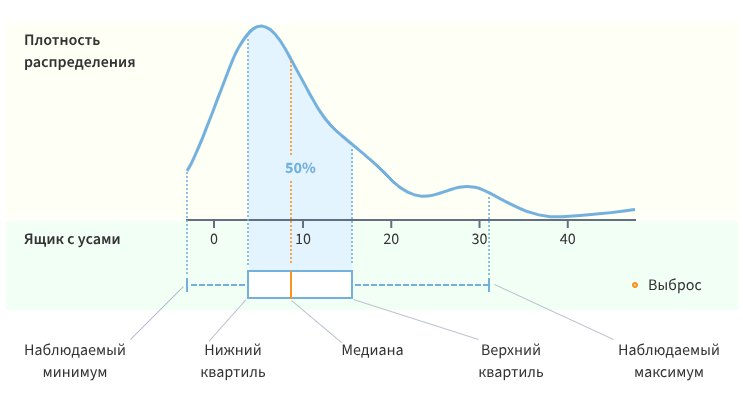

**Замечание 10.3.** Иногда внутрь ящика добавляют **среднее арифметическое** (в виде отдельного маркера) — тогда на одной диаграмме видно различие между медианой и средним, что позволяет судить об асимметрии распределения. Если среднее существенно выше медианы — распределение имеет правосторонний скос.

**Таблица 10.1.** Элементы диаграммы размахов и их статистический смысл

| Элемент | Статистический смысл |
|---|---|
| Нижний ус | Минимум или $Q_1 - 1{,}5 \cdot \mathrm{IQR}$ (что больше) |
| Нижняя граница ящика | Первый квартиль $Q_1$ (25-й процентиль) |
| Линия внутри ящика | Медиана $Q_2$ (50-й процентиль) |
| Верхняя граница ящика | Третий квартиль $Q_3$ (75-й процентиль) |
| Верхний ус | Максимум или $Q_3 + 1{,}5 \cdot \mathrm{IQR}$ (что меньше) |
| Точки за усами | Потенциальные выбросы |

## 10.3. Построение диаграммы размахов по месяцам

**Пример 10.1.** Построим диаграмму размахов для синтетического ряда температуры, сгенерированного в разделе 2. Сгруппируем наблюдения по месяцам — это позволит сравнить распределения температуры в разные сезоны.




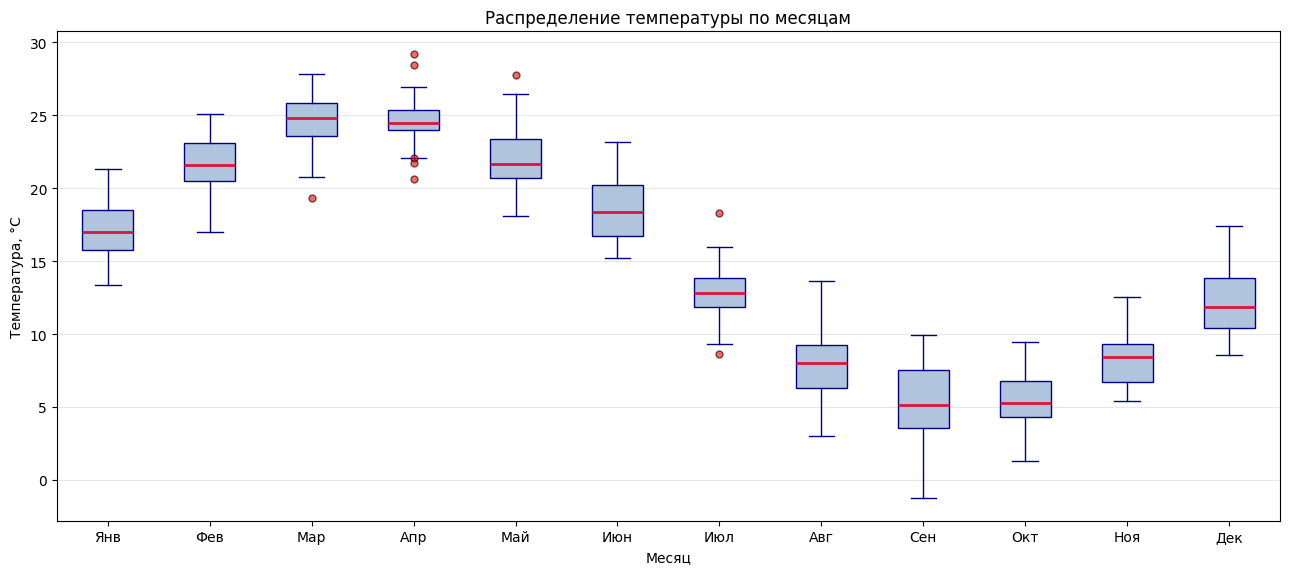

In [32]:
# Добавляем столбец с номером месяца
df['Month'] = df.index.month

# Построение диаграммы размахов
fig, ax = plt.subplots(figsize=(13, 6))

df.boxplot(column='Temperature', by='Month', ax=ax,
           grid=False, patch_artist=True,
           boxprops=dict(facecolor='lightsteelblue', color='navy'),
           medianprops=dict(color='crimson', linewidth=2),
           whiskerprops=dict(color='navy'),
           capprops=dict(color='navy'),
           flierprops=dict(marker='o', markerfacecolor='red',
                           markersize=5, alpha=0.6))

ax.set_title('Распределение температуры по месяцам')
ax.set_xlabel('Месяц')
ax.set_ylabel('Температура, °C')
ax.set_xticklabels(['Янв', 'Фев', 'Мар', 'Апр', 'Май', 'Июн',
                    'Июл', 'Авг', 'Сен', 'Окт', 'Ноя', 'Дек'])
plt.suptitle('')  # убираем автоматический заголовок pandas
plt.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()



**Разбор кода.** Назначение основных инструкций приведено в таблице 10.2.

**Таблица 10.2.** Назначение инструкций построения диаграммы размахов

| Инструкция | Назначение |
|---|---|
| `df['Month'] = df.index.month` | Создание столбца с номером месяца |
| `df.boxplot(column='Temperature', by='Month', ...)` | Построение диаграмм размахов: отдельный ящик для каждого месяца |
| `patch_artist=True` | Разрешает закраску ящиков (по умолчанию — только контур) |
| `boxprops`, `medianprops`, `whiskerprops`, `capprops` | Настройка оформления ящика, медианы, усов и их «шапочек» |
| `flierprops` | Настройка оформления выбросов |
| `ax.set_xticklabels([...])` | Замена числовых подписей месяцев на текстовые аббревиатуры |
| `plt.suptitle('')` | Удаление автоматически добавляемого pandas заголовка |

**Замечание 10.4.** Функция `plt.boxplot` из `matplotlib` строит одну диаграмму размахов; метод `DataFrame.boxplot` — сразу несколько, сгруппированных по значениям указанного столбца. Для сезонного анализа временных рядов удобнее последний вариант, поскольку он автоматически формирует группы.

## 10.4. Интерпретация диаграммы размахов

На построенном графике (пример 10.1) наблюдаются следующие особенности распределения температуры по месяцам.

1. **Сезонный профиль медиан.** Медианы образуют характерную U-образную кривую: минимум в январе и декабре (около $-10\ ^\circ\mathrm{C}$), максимум в июле (около $+10\ ^\circ\mathrm{C}$). Это визуальное подтверждение **годовой сезонности**.

2. **Симметричность ящиков.** В каждом месяце медиана находится примерно на середине ящика, длина нижнего и верхнего усов сопоставима. Это означает, что распределение температуры внутри месяца **близко к симметричному**.

3. **Разброс внутри месяца.** Высота ящиков (IQR) приблизительно одинакова для всех месяцев и составляет около $4$–$5\ ^\circ\mathrm{C}$. Дисперсия температуры **не зависит** от сезона — явление гомоскедастичности.

4. **Выбросы.** В отдельных месяцах встречаются точки за верхним или нижним усом — это дни с аномально высокой или низкой температурой. Их количество невелико (1–2 на месяц), что соответствует редким погодным аномалиям.

5. **Отсутствие тренда внутри года.** Сравнение одноимённых месяцев разных лет невозможно в рамках одного года наблюдений; для оценки устойчивости сезонного профиля требуются данные за несколько лет.

**Замечание 10.5.** Диаграмма размахов позволяет **одновременно** оценить три аспекта: типичный уровень (медиана), вариабельность (высота ящика) и наличие аномалий (выбросы). Именно поэтому она часто используется как **сводная визуализация** в задачах анализа сезонности.

## 10.5. Сравнение диаграмм размахов для разных типов рядов

Для сопоставления рассмотрим диаграммы размахов для двух качественно различных рядов: температуры (сезонность) и продаж (недельная сезонность).

**Пример 10.2.** Построим диаграмму размахов продаж по дням недели.




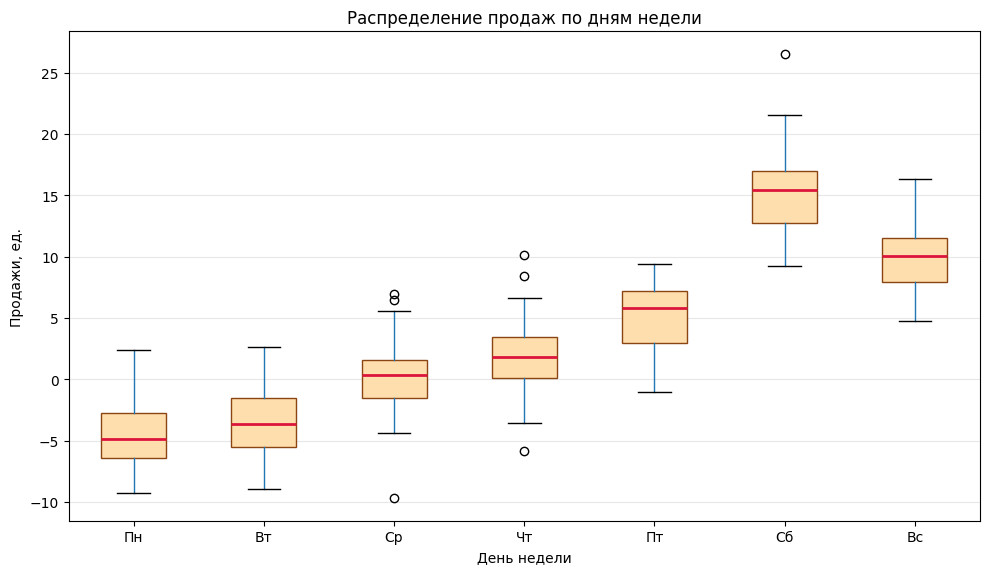

In [33]:
# Синтетический ряд недельной сезонности
np.random.seed(42)
dates_sales = pd.date_range(start='2023-01-01', periods=364, freq='D')
weekday_effect = np.array([-5, -3, 0, 2, 5, 15, 10])
sales = weekday_effect[dates_sales.dayofweek] + np.random.normal(scale=3, size=len(dates_sales))

df_sales = pd.DataFrame({'Date': dates_sales, 'Sales': sales})
df_sales.set_index('Date', inplace=True)
df_sales['Weekday'] = df_sales.index.dayofweek

# Диаграмма размахов по дням недели
fig, ax = plt.subplots(figsize=(10, 6))
df_sales.boxplot(column='Sales', by='Weekday', ax=ax,
                 grid=False, patch_artist=True,
                 boxprops=dict(facecolor='navajowhite', color='saddlebrown'),
                 medianprops=dict(color='crimson', linewidth=2))

ax.set_title('Распределение продаж по дням недели')
ax.set_xlabel('День недели')
ax.set_ylabel('Продажи, ед.')
ax.set_xticklabels(['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс'])
plt.suptitle('')
plt.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()



**Интерпретация.** Медианы продаж образуют характерную «горку» с максимумом в субботу и воскресенье. Разброс продаж в выходные **выше**, чем в будни (ящики субботы и воскресенья выше) — это типичная особенность розничной торговли: спрос в выходные менее предсказуем.

**Сравнительная характеристика** приведена в таблице 10.3.

**Таблица 10.3.** Сопоставление диаграмм размахов для разных типов сезонности

| Характеристика | Температура по месяцам | Продажи по дням недели |
|---|---|---|
| Период сезонности | 365 дней | 7 дней |
| Число групп | 12 (месяцы) | 7 (дни недели) |
| Форма профиля медиан | U-образная (симметричная) | «горка» (пик в выходные) |
| Разброс внутри групп | одинаковый | выше в выходные |
| Наличие выбросов | редкие, единичные | реже, но встречаются |

**Замечание 10.6.** Диаграмма размахов позволяет выявить **не только сезонный профиль медиан**, но и различие в **вариабельности между группами**. Это отличает её от сезонного графика (раздел 6), где вариабельность оценивается лишь визуально — по разбросу точек.

## 10.6. Диаграммы размахов по скользящим окнам

**Пример 10.3.** В задачах анализа временных рядов полезна модификация диаграмм размахов: сравнение распределений **по скользящим временны́м окнам** (например, по кварталам или по месяцам для нескольких лет).




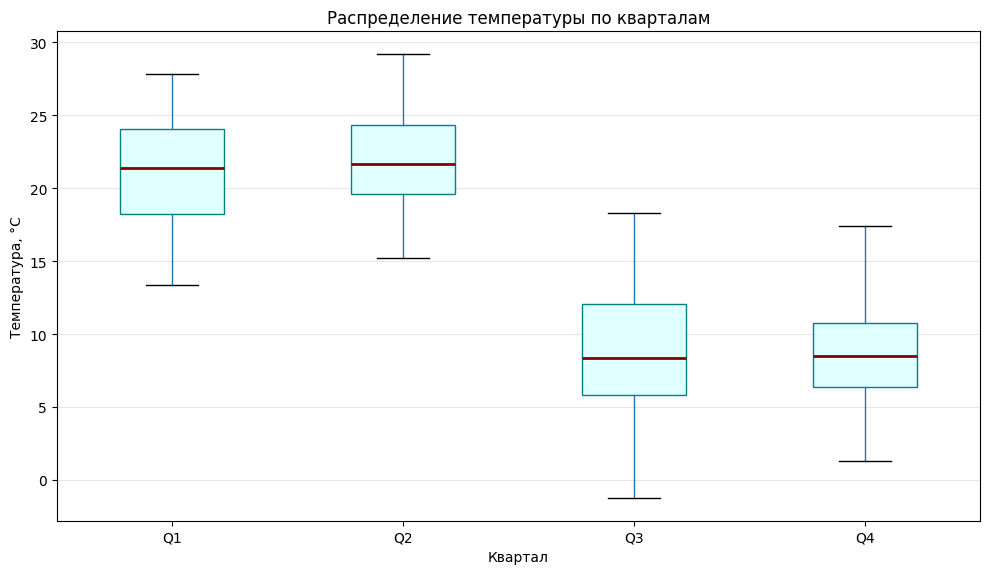

In [34]:
# Разбиение года на кварталы
df['Quarter'] = df.index.quarter

fig, ax = plt.subplots(figsize=(10, 6))
df.boxplot(column='Temperature', by='Quarter', ax=ax,
           grid=False, patch_artist=True,
           boxprops=dict(facecolor='lightcyan', color='teal'),
           medianprops=dict(color='darkred', linewidth=2))

ax.set_title('Распределение температуры по кварталам')
ax.set_xlabel('Квартал')
ax.set_ylabel('Температура, °C')
ax.set_xticklabels(['Q1', 'Q2', 'Q3', 'Q4'])
plt.suptitle('')
plt.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()



**Интерпретация.** Диаграмма показывает, что распределения температуры по кварталам сильно различаются:

- **Q1 (зима–весна)** и **Q4 (осень–зима)** имеют медианы ниже нуля;
- **Q2 (весна–лето)** и **Q3 (лето–осень)** — медианы выше нуля;
- **Q1 и Q4** имеют больший разброс (IQR), поскольку включают переходные периоды.

Такое представление удобно для **агрегированного анализа** — вместо 365 отдельных наблюдений аналитик работает с четырьмя группами.

## 10.7. Диаграммы размахов и выбросы

**Замечание 10.7.** Диаграмма размахов — один из самых простых и наглядных инструментов **обнаружения выбросов**. Наблюдение считается потенциальным выбросом, если оно лежит за пределами $[Q_1 - 1{,}5 \cdot \mathrm{IQR},\ Q_3 + 1{,}5 \cdot \mathrm{IQR}]$. Этот критерий называется **правилом Тьюки**.

**Определение 10.5.** Наблюдения, лежащие за пределами $[Q_1 - 3 \cdot \mathrm{IQR},\ Q_3 + 3 \cdot \mathrm{IQR}]$, называются **экстремальными выбросами** и обычно выделяются на графике другим маркером.

**Замечание 10.8.** Правило Тьюки — не универсальный критерий «истинного» выброса, а лишь **диагностический инструмент**. Прежде чем удалять выбросы из временного ряда, необходимо выяснить их природу:

- **случайные выбросы** (например, аномально жаркий день) могут быть удалены или оставлены в зависимости от задачи;
- **систематические выбросы** (например, пики продаж в праздники) несут содержательную информацию и должны быть сохранены;
- **ошибки измерения** подлежат исправлению или удалению.

**Замечание 10.9.** В отличие от среднего арифметического, медиана **устойчива** к выбросам: один аномальный день не смещает её. Поэтому в задачах анализа временных рядов с возможными аномалиями диаграмма размахов предпочтительнее гистограммы для оценки типичного уровня показателя.

## 10.8. Сравнение с ранее рассмотренными инструментами

**Таблица 10.4.** Диаграмма размахов в системе инструментов визуализации

| Характеристика | Линейный | Гистограмма | Коррелограмма | Сезонный | Точечный | Сглаживание | Контурный | Box Plot |
|---|---|---|---|---|---|---|---|---|
| По оси X | время | значение | лаг | фаза сезона | значение $X$ | время | время-1 | **группа** |
| По оси Y | значение | частота | АКФ | значение | значение $Y$ | — | время-2 | **значение** |
| Число измерений | 1 | 1 | 1 | 1 | 2 | 1 | 3 | 1 (с группировкой) |
| Основная задача | динамика | распределение | корреляция | сезонный профиль | связь $X$–$Y$ | тренд | двумерная сезонность | **сравнение групп + выбросы** |

**Замечание 10.10.** Диаграмма размахов **дополняет** гистограмму, но не заменяет её:

- **гистограмма** показывает форму распределения (модальность, асимметрия, «тяжесть хвостов»);
- **диаграмма размахов** — количественные характеристики (медиана, квартили, IQR) и выбросы, а также позволяет **сравнивать несколько групп**.

При анализе одного временного ряда обе визуализации полезны; при сравнении нескольких рядов (например, температуры за разные годы или продаж в разных магазинах) диаграммы размахов становятся **предпочтительным инструментом**.

## 10.9. Выводы по разделу

В настоящем разделе:

1. дано определение диаграммы размахов и её базовых элементов (ящик, медиана, усы, выбросы);
2. введены статистические понятия квартиля, межквартильного размаха и правила Тьюки;
3. построена диаграмма размахов температуры по месяцам и разобрано назначение каждой инструкции;
4. проведена интерпретация — установлены форма сезонного профиля медиан, симметричность распределений и наличие редких выбросов;
5. выполнено сравнение диаграмм размахов для двух типов сезонности (годовой и недельной);
6. рассмотрена модификация с разбиением по кварталам;
7. обсуждена роль диаграмм размахов в обнаружении выбросов и отличие потенциальных выбросов от содержательных аномалий;
8. определено место диаграммы размахов в общей системе инструментов визуализации.

**Замечание 10.11.** Диаграмма размахов — **компактный и информативный инструмент**, объединяющий визуализацию и статистическое описание. Она незаменима в задачах **сравнения нескольких групп** наблюдений (сезонов, кварталов, дней недели, объектов) и **обнаружения выбросов**. При этом она **не показывает форму распределения** внутри группы и потому должна применяться в комплексе с гистограммой: гистограмма даёт форму, диаграмма размахов — числа. Совместное применение этих двух инструментов формирует полное представление о распределении значений временного ряда.

# 11. Графики изменчивости (Run Sequence Plots)

## 11.1. Определение и назначение

**Определение 11.1.** *Графиком изменчивости* (или *графиком последовательности*, *run sequence plot*) называется графическое представление временного ряда, в котором по оси абсцисс откладывается **порядковый номер наблюдения** $t = 1, 2, \ldots, n$, а по оси ординат — соответствующее значение $y_t$, при этом соседние точки соединяются отрезками прямых.

**Замечание 11.1.** На первый взгляд, график изменчивости **внешне совпадает** с линейным графиком (раздел 3). Однако между ними существует принципиальное методологическое различие:

- **линейный график** отображает ряд в **физическом времени**, где расстояния между точками на оси X пропорциональны временны́м интервалам; пропуски во времени видны как «разрывы»;
- **график изменчивости** отображает ряд в **порядке следования наблюдений**, где ось X — это просто счётчик $1, 2, 3, \ldots$; временна́я неравномерность игнорируется.

Именно это различие делает графики изменчивости предпочтительными в задачах, где **важна последовательность, а не календарная привязка**: при анализе остатков моделей, при контроле качества партий продукции, при сравнении рядов с разной частотой дискретизации.

Применение графиков изменчивости в анализе временных рядов позволяет решить следующие задачи:

1. **обнаружение сдвигов уровня** — моменты, когда средний уровень ряда резко меняется;
2. **диагностика остатков моделей** — проверка гипотезы о «белом шуме»;
3. **сравнение рядов с разной частотой** — приведение к единой шкале последовательности;
4. **выявление неслучайных паттернов** — кластеры, чередования, циклы;
5. **оценка эффекта преобразований** — сопоставление «до» и «после» (дифференцирование, логарифмирование).

**Замечание 11.2.** В англоязычной литературе термин *run sequence plot* часто используется как синоним *time sequence plot* и применяется в задачах **статистического контроля процессов (SPC)** и **анализа остатков**. В русскоязычной традиции близким понятием является «график последовательных значений» или «график хода процесса».

## 11.2. Математическая основа

**Определение 11.2.** *Последовательностью* временного ряда $\{y_t\}$ называется отображение $t \mapsto y_t$, где $t \in \{1, 2, \ldots, n\}$ — **порядковый номер** наблюдения.

**Определение 11.3.** *Разностью последовательности* называется ряд $\{\Delta y_t\}$, определяемый как

$$\Delta y_t = y_t - y_{t-1}, \qquad t = 2, \ldots, n.$$

Разности последовательности широко используются при анализе графиков изменчивости: они позволяют **устранить тренд** и сфокусироваться на **краткосрочных изменениях** ряда.

**Определение 11.4.** *Выбросом в последовательности* называется наблюдение $y_t$, для которого абсолютная разность $|\Delta y_t|$ существенно превышает типичные значения $|\Delta y|$ по всему ряду.

**Замечание 11.3.** На графике изменчивости **порядок точек фиксирован**: нельзя переставлять наблюдения или менять масштаб оси X без потери смысла графика. Именно последовательность — главный объект анализа, и нарушение порядка разрушает всю визуальную информацию.

## 11.3. Построение графика изменчивости

**Пример 11.1.** Построим график изменчивости для синтетического ряда температуры, сгенерированного в разделе 2, и сопоставим его с линейным графиком.



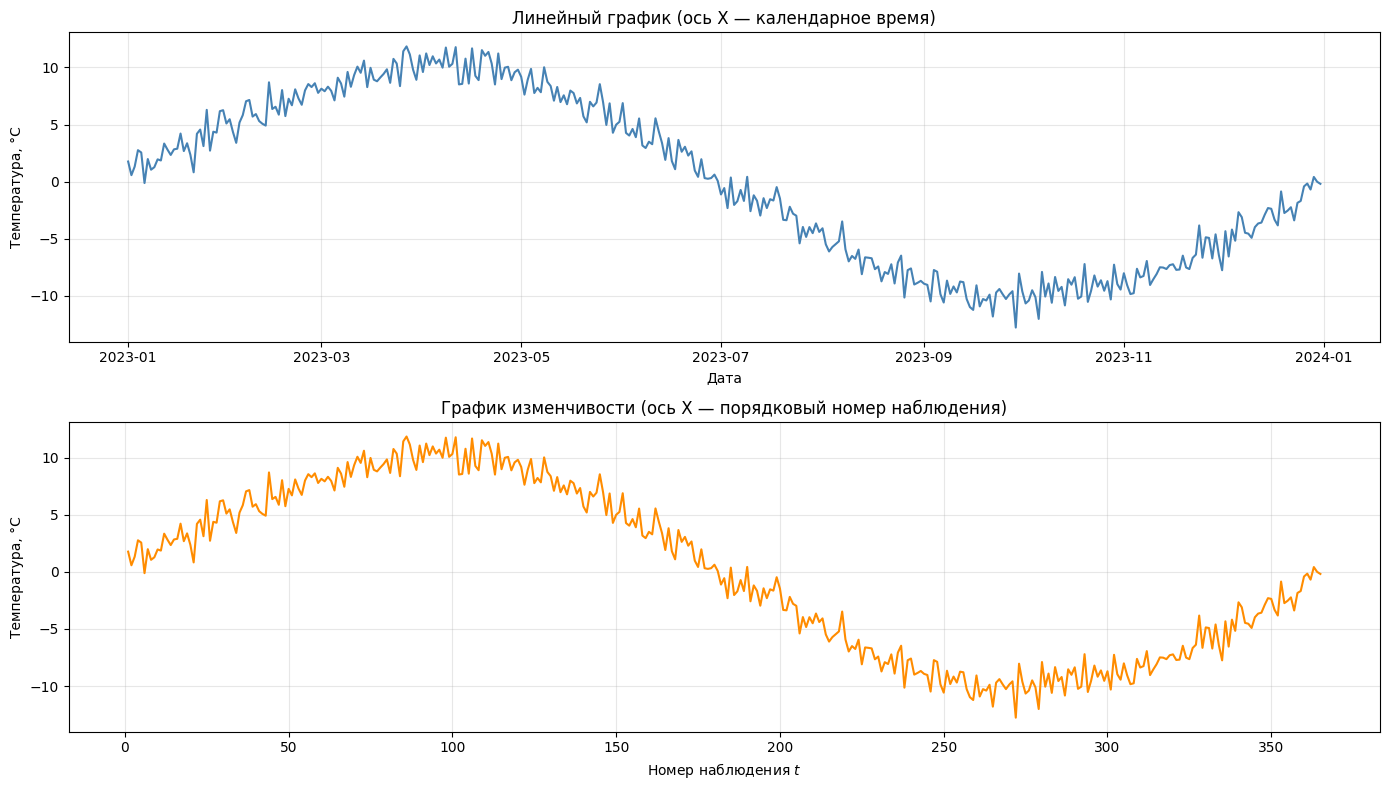

In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Чтение данных
df = pd.read_csv('temperature_data.csv', index_col='Date', parse_dates=['Date'])

# Порядковый номер наблюдения
df['t'] = np.arange(1, len(df) + 1)

# Построение графика изменчивости
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharey=True)

# Верхний: линейный график (по времени)
axes[0].plot(df.index, df['Temperature'], color='steelblue')
axes[0].set_title('Линейный график (ось X — календарное время)')
axes[0].set_xlabel('Дата')
axes[0].set_ylabel('Температура, °C')
axes[0].grid(True, alpha=0.3)

# Нижний: график изменчивости (по порядковому номеру)
axes[1].plot(df['t'], df['Temperature'], color='darkorange')
axes[1].set_title('График изменчивости (ось X — порядковый номер наблюдения)')
axes[1].set_xlabel('Номер наблюдения $t$')
axes[1].set_ylabel('Температура, °C')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()



**Разбор кода.** Назначение основных инструкций приведено в таблице 11.1.

**Таблица 11.1.** Назначение инструкций построения графика изменчивости

| Инструкция | Назначение |
|---|---|
| `df['t'] = np.arange(1, len(df) + 1)` | Создание столбца с порядковым номером наблюдения $1, 2, \ldots, n$ |
| `plt.subplots(2, 1, sharey=True)` | Создание двух подграфиков с общей осью Y для прямого сопоставления |
| `axes[0].plot(df.index, ...)` | Верхний подграфик: по оси X — календарное время |
| `axes[1].plot(df['t'], ...)` | Нижний подграфик: по оси X — порядковый номер наблюдения |
| `sharey=True` | Обе шкалы Y совпадают — линии визуально сопоставимы |

**Замечание 11.4.** Поскольку в примере 11.1 данные равномерны по времени (одно наблюдение в день, без пропусков), оба графика **визуально совпадают**. Различие становится заметным при **неравномерной дискретизации** или **пропусках**: линейный график «растянет» участки с редкими наблюдениями, а график изменчивости — нет.

## 11.4. Интерпретация графика изменчивости

На построенном графике (пример 11.1) наблюдаются следующие особенности ряда.

1. **Годовая сезонность.** График имеет форму плавной синусоиды — зимой значения отрицательные, летом положительные. Это подтверждает наличие сезонной компоненты с периодом $P = 365$ наблюдений.

2. **Отсутствие видимого тренда.** Средний уровень ряда примерно постоянен: зимние и летние значения симметричны относительно нуля.

3. **Отсутствие сдвигов уровня.** Ряд не содержит участков, где средний уровень резко меняется (например, переход от одного режима к другому). Это важно для проверки гипотезы стационарности.

4. **Шумовая компонента.** Вокруг синусоиды наблюдается «дрожание» линии — дневные случайные колебания. По их амплитуде можно оценить дисперсию шума.

**Замечание 11.5.** При интерпретации графика изменчивости важно **не путать** временны́е закономерности с чисто последовательностными:

- **сезонность** — это закономерность во времени;
- **цикличность** — закономерность в последовательности, которая может не иметь строгой временно́й привязки;
- **тренд** — систематическое изменение уровня, видимое и в последовательности, и во времени.

Различие становится принципиальным, когда наблюдения берутся **не через равные промежутки времени** (например, по мере поступления заявок в службу поддержки). В этом случае линейный график может создать иллюзию цикла, которого в последовательности нет, и наоборот.

## 11.5. График изменчивости разностей

**Пример 11.2.** Для устранения тренда и выделения краткосрочной динамики построим график изменчивости **разностей** (первых разностей исходного ряда).




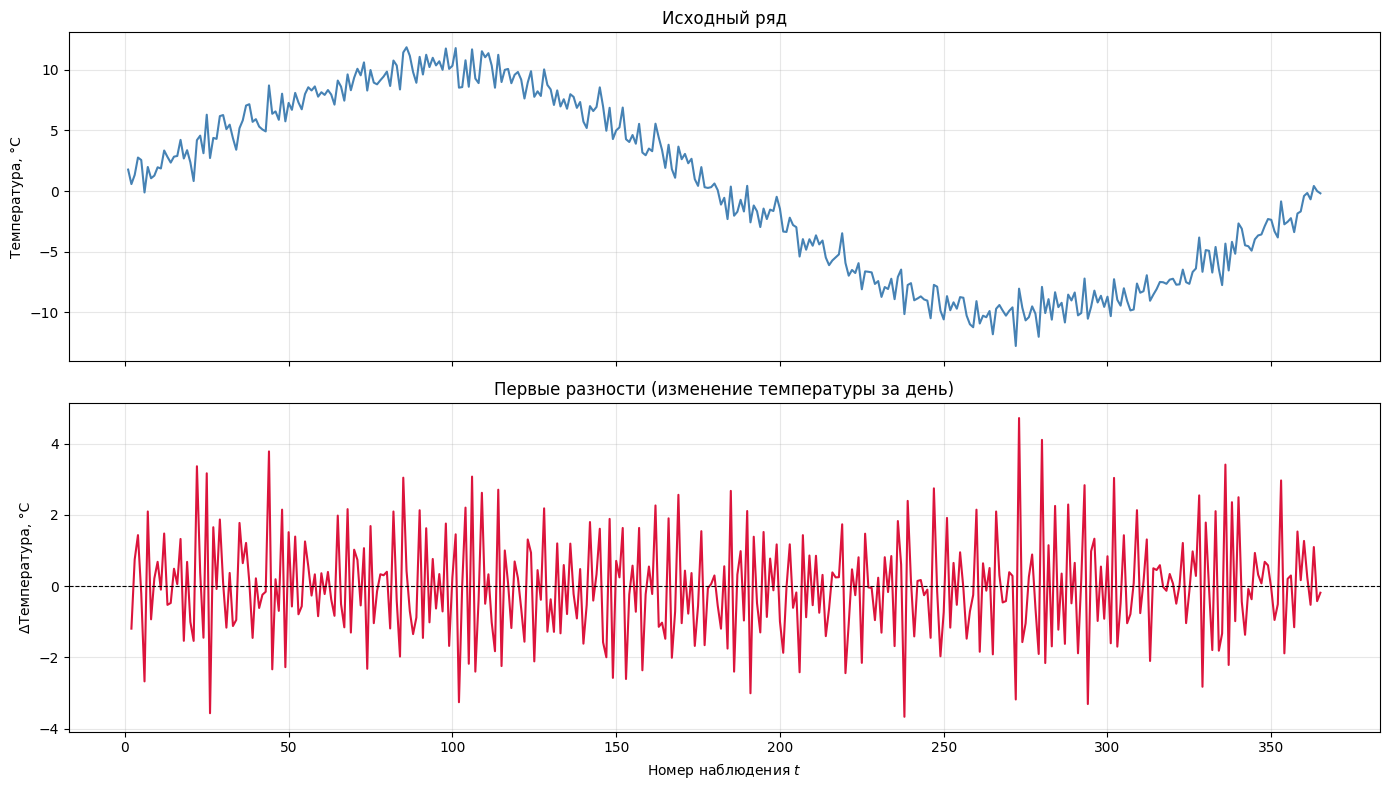

In [36]:
# Первые разности
df['diff'] = df['Temperature'].diff()

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# Верхний: исходный ряд
axes[0].plot(df['t'], df['Temperature'], color='steelblue')
axes[0].set_title('Исходный ряд')
axes[0].set_ylabel('Температура, °C')
axes[0].grid(True, alpha=0.3)

# Нижний: разности
axes[1].plot(df['t'], df['diff'], color='crimson')
axes[1].axhline(0, color='black', linewidth=0.8, linestyle='--')
axes[1].set_title('Первые разности (изменение температуры за день)')
axes[1].set_xlabel('Номер наблюдения $t$')
axes[1].set_ylabel('ΔТемпература, °C')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()



**Разбор кода.** Метод `df['Temperature'].diff()` вычисляет первые разности: $\Delta y_t = y_t - y_{t-1}$. Первое значение разностного ряда — `NaN`, поэтому оно не отображается.

**Интерпретация.** График разностей имеет следующие особенности:

1. **Устранение сезонности.** Если исходный ряд имел ярко выраженную годовую синусоиду, то разности колеблются **около нуля без видимой сезонной структуры** — сезонная компонента «вычлась» при взятии разностей.
2. **Смена знака.** В первой половине года (зима → лето) температура растёт, поэтому разности положительны; во второй половине года (лето → зима) — отрицательны. Точки перехода через ноль соответствуют моментам **экстремума** исходного ряда (пики лета и зимы).
3. **Усиление шума.** Амплитуда колебаний разностей **выше**, чем у исходного ряда, поскольку операция дифференцирования **усиливает высокочастотные компоненты** (шум) и ослабляет низкочастотные (тренд, сезонность).
4. **Отсутствие выбросов.** Резких одиночных скачков разностей нет — это означает отсутствие аномальных перепадов температуры за один день.

**Замечание 11.6.** Операция дифференцирования — ключевой приём **приведения нестационарного ряда к стационарному**. Если график изменчивости исходного ряда показывает тренд или сезонность, то график разностей обычно демонстрирует стационарное поведение с постоянным средним и дисперсией. Это важный шаг при построении моделей ARIMA.

## 11.6. График изменчивости остатков модели

**Пример 11.3.** Один из самых распространённых случаев применения графиков изменчивости — **диагностика остатков** построенной модели. Рассмотрим остатки простой модели линейного тренда.



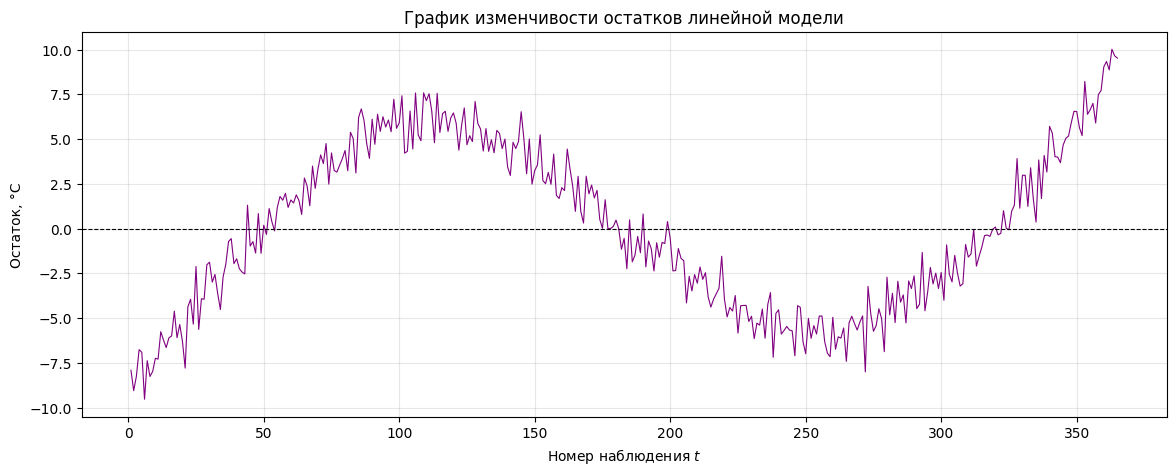

In [37]:
from numpy.polynomial import polynomial as P

# Оценка линейного тренда методом наименьших квадратов
t = df['t'].values
y = df['Temperature'].values
coeffs = np.polyfit(t, y, deg=1)
trend = np.polyval(coeffs, t)

# Остатки модели
residuals = y - trend

# График изменчивости остатков
plt.figure(figsize=(14, 5))
plt.plot(t, residuals, color='purple', linewidth=0.8)
plt.axhline(0, color='black', linewidth=0.8, linestyle='--')
plt.title('График изменчивости остатков линейной модели')
plt.xlabel('Номер наблюдения $t$')
plt.ylabel('Остаток, °C')
plt.grid(True, alpha=0.3)
plt.show()



**Интерпретация.** На графике остатков отчётливо видны:

1. **Систематическая волнообразная структура.** Остатки не являются «белым шумом»: они образуют ярко выраженную синусоиду, повторяющую сезонный цикл. Это означает, что **линейная модель тренда неадекватна** — она не учитывает сезонную компоненту.

2. **Знакопеременность.** Остатки регулярно меняют знак с периодом около 365 наблюдений. Такая структура — **прямое указание на наличие сезонности**, которую необходимо учесть в модели (например, перейти к SARIMA).

3. **Постоянство дисперсии.** Амплитуда остатков примерно одинакова на всём интервале — явление гомоскедастичности. Это положительный диагностический признак: можно применять модели с постоянной дисперсией шума.

**Замечание 11.7.** **Ключевое правило диагностики остатков:** если график изменчивости остатков показывает **систематическую структуру** (тренд, сезонность, сдвиги уровня), модель **неадекватна**; если остатки выглядят как **«белый шум»** без видимых паттернов, модель можно считать корректной. График изменчивости — самый быстрый и наглядный инструмент такой проверки.

## 11.7. Сравнение нескольких рядов на одном графике

**Пример 11.4.** Графики изменчивости удобны для **сопоставления нескольких рядов** в единой системе координат. Рассмотрим два ряда температуры: синтетический (раздел 2) и его сглаженную версию.



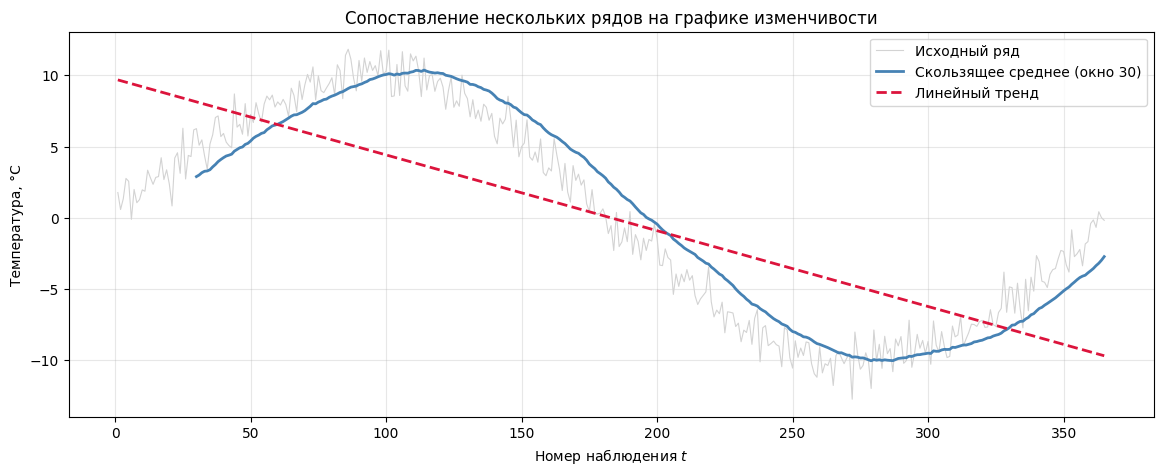

In [38]:
plt.figure(figsize=(14, 5))

plt.plot(df['t'], df['Temperature'],
         color='lightgray', linewidth=0.8, label='Исходный ряд')
plt.plot(df['t'], df['Temperature'].rolling(30).mean(),
         color='steelblue', linewidth=2, label='Скользящее среднее (окно 30)')
plt.plot(df['t'], trend,
         color='crimson', linewidth=2, linestyle='--', label='Линейный тренд')

plt.title('Сопоставление нескольких рядов на графике изменчивости')
plt.xlabel('Номер наблюдения $t$')
plt.ylabel('Температура, °C')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()



**Интерпретация.** Три ряда на одном графике позволяют сделать следующие выводы:

1. **Исходный ряд** (серый) содержит выраженный шум и сезонность.
2. **Скользящее среднее** (синий) выявляет годовую сезонную волну, но **не показывает тренда** — сглаженный ряд колеблется относительно постоянного уровня.
3. **Линейный тренд** (красный) оказывается **почти горизонтальной линией** — это подтверждает отсутствие долговременного тренда в данных.

**Замечание 11.8.** Наложение нескольких рядов на один график изменчивости — простой и эффективный способ **сравнения гипотез** о структуре ряда. Если сглаженный ряд имеет наклон, тренд присутствует; если горизонтален — тренда нет. Если после устранения сезонности ряд превращается в шум — модель декомпозиции выбрана удачно.

## 11.8. Обнаружение сдвигов уровня

**Пример 11.5.** Графики изменчивости особенно полезны для обнаружения **сдвигов уровня** — моментов, когда средний уровень ряда резко меняется.




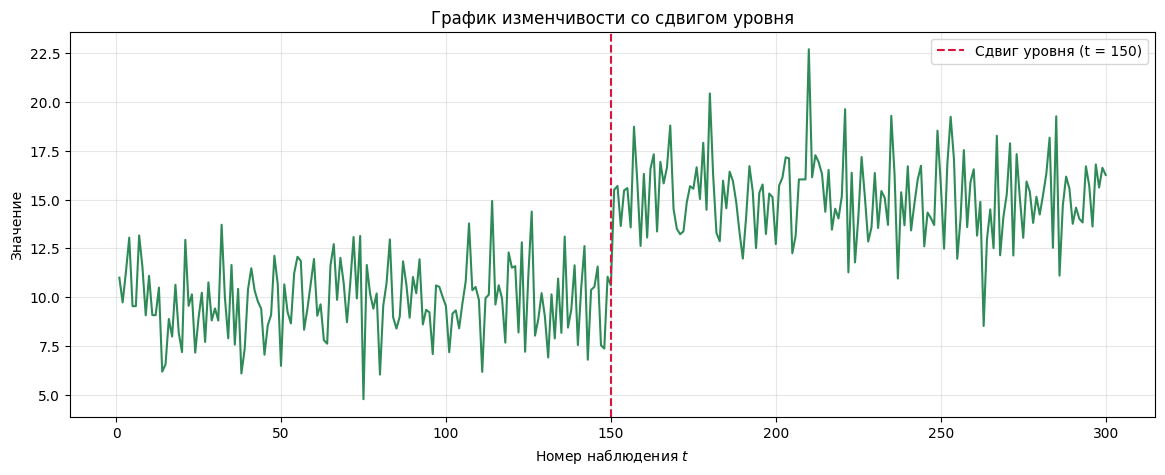

In [39]:
# Синтетический ряд со сдвигом уровня
np.random.seed(42)
n = 300
shift_point = 150

# До сдвига — уровень 10, после — уровень 15
before = np.random.normal(loc=10, scale=2, size=shift_point)
after  = np.random.normal(loc=15, scale=2, size=n - shift_point)
series_shift = np.concatenate([before, after])

plt.figure(figsize=(14, 5))
plt.plot(np.arange(1, n + 1), series_shift, color='seagreen')
plt.axvline(shift_point, color='crimson', linestyle='--',
            label=f'Сдвиг уровня (t = {shift_point})')
plt.title('График изменчивости со сдвигом уровня')
plt.xlabel('Номер наблюдения $t$')
plt.ylabel('Значение')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


**Интерпретация.** На графике отчётливо виден **момент резкого изменения среднего уровня** ряда — примерно в точке $t = 150$. До этого момента значения колебались вокруг уровня 10, после — вокруг уровня 15. Сдвиг уровня — важный диагностический признак:

- он **нарушает стационарность** ряда;
- свидетельствует о **смене режима** (например, изменение бизнес-процесса, смена поставщика, начало рекламной кампании);
- требует **учёта в модели** — простого дифференцирования недостаточно, нужна **кусочно-линейная модель** с точкой разрыва.

**Замечание 11.9.** Сдвиги уровня легко **пропустить** на гистограмме (распределение будет бимодальным, но момент сдвига не виден) и на коррелограмме (АКФ может выглядеть нормально). График изменчивости — **единственный** инструмент, который позволяет точно **локализовать** момент сдвига во времени.

## 11.9. Сравнение с ранее рассмотренными инструментами

**Таблица 11.2.** График изменчивости в системе инструментов визуализации

| Характеристика | Линейный | Гистограмма | Коррелограмма | Сезонный | Точечный | Сглаживание | Контурный | Box Plot | Run Sequence |
|---|---|---|---|---|---|---|---|---|---|
| По оси X | время | значение | лаг | фаза сезона | значение $X$ | время | время-1 | группа | **порядковый номер** |
| По оси Y | значение | частота | АКФ | значение | значение $Y$ | — | время-2 | значение | значение |
| Учитывает порядок | да | нет | да | нет | нет | да | да | нет | **да, но абстрактно** |
| Основная задача | динамика | распределение | корреляция | сезонный профиль | связь $X$–$Y$ | тренд | двумерная сезонность | сравнение групп | **последовательность, сдвиги, остатки** |

**Замечание 11.10.** График изменчивости **дополняет** линейный график, а не заменяет его:

- **линейный график** привязан к календарю и удобен для содержательной интерпретации («в июле температура достигла максимума»);
- **график изменчивости** абстрагируется от календаря и удобен для **статистической диагностики** («в точке $t = 150$ произошёл сдвиг уровня»).

В анализе временных рядов оба инструмента применяются **параллельно**: линейный график — для содержательной интерпретации, график изменчивости — для формальной диагностики.

## 11.10. Выводы по разделу

В настоящем разделе:

1. дано определение графика изменчивости и указано его принципиальное отличие от линейного графика;
2. введены понятия разности последовательности и выброса в последовательности;
3. построен график изменчивости температуры и разобрано назначение каждой инструкции;
4. проведена интерпретация — установлены сезонность, отсутствие тренда и сдвигов уровня;
5. рассмотрено построение графика разностей и его роль в приведении ряда к стационарному виду;
6. показано применение графика изменчивости для диагностики остатков моделей;
7. рассмотрено сравнение нескольких рядов и обнаружение сдвигов уровня;
8. определено место графика изменчивости в общей системе инструментов визуализации.

**Замечание 11.11.** График изменчивости — **ключевой инструмент статистической диагностики временных рядов**. Если линейный график отвечает на вопрос «*как выглядит ряд*», то график изменчивости — «*как ведёт себя ряд как последовательность*»: содержит ли он сдвиги, паттерны, неслучайные структуры. Именно поэтому график изменчивости занимает центральное место в:

- **диагностике остатков** прогнозных моделей (проверка гипотезы «белого шума»);
- **обнаружении сдвигов уровня** и точек разладки (change point detection);
- **анализе стационарности** перед выбором модели ARIMA;
- **контроле качества процессов** (SPC-карты Шухарта).

Применение графика изменчивости в комплексе с ранее рассмотренными инструментами (линейный график, гистограмма, коррелограмма, сезонный, точечный, сглаживание, контурный график, диаграмма размахов) формирует **полноценное представление о структуре ряда** — от формы распределения до временны́х закономерностей и внутренней корреляционной структуры — и служит надёжной основой для выбора адекватной прогнозной модели.

# 12. Графики событий (Event Plots)

## 12.1. Определение и назначение

**Определение 12.1.** *Графиком событий* (или *графиком аннотированных событий*) называется графическое представление временного ряда, дополненное **вертикальными или горизонтальными маркерами**, отмечающими моменты наступления значимых событий, которые могли повлиять на поведение ряда.

**Определение 12.2.** *Событием* называется внешнее по отношению к временному ряду воздействие, приуроченное к некоторому моменту времени (или интервалу) и потенциально изменяющее поведение ряда: смена режима, аномалия, вмешательство, праздник, катастрофа, регуляторное решение.

**Замечание 12.1.** Графики событий — **первый инструмент в настоящем обзоре, объединяющий данные и контекст**. Все ранее рассмотренные визуализации анализировали ряд «в вакууме», только по его числовым значениям. График событий позволяет сопоставить **числовую динамику** с **содержательными причинами** её изменений.

Применение графиков событий в анализе временных рядов позволяет решить следующие задачи:

1. **содержательная интерпретация аномалий** — объяснить резкие отклонения ряда конкретными причинами;
2. **исследование эффекта вмешательства** — оценить, как событие повлияло на поведение ряда (например, рекламная кампания → рост продаж);
3. **разделение режимов** — визуально разделить ряд на периоды «до» и «после» события;
4. **проверка гипотез** — сопоставить предполагаемые события с наблюдаемыми изменениями;
5. **коммуникация результатов** — представить аналитику заказчику в понятной содержательной форме.

**Замечание 12.2.** График событий особенно полезен в задачах **бизнес-аналитики** (акции, рекламные кампании, смена тарифов), **климатологии** (погодные аномалии, стихийные бедствия), **энергетики** (аварии, плановые отключения), **финансов** (публикации отчётности, решения центробанка).

## 12.2. Математическая основа

**Определение 12.3.** *Аннотированным временным рядом* называется пара $(\{y_t\}, \mathcal{E})$, где $\{y_t\}$ — исходный временной ряд, а $\mathcal{E} = \{e_1, e_2, \ldots, e_m\}$ — множество событий, каждое из которых характеризуется:

- **моментом времени** $\tau_i$ (или интервалом $[\tau_i^{\text{start}}, \tau_i^{\text{end}}]$);
- **описанием** (текстовой меткой);
- при необходимости — **типом события** (положительное, отрицательное, нейтральное).

**Определение 12.4.** *Индикаторной функцией события* называется функция

$$I_i(t) = \begin{cases} 1, & t = \tau_i, \\ 0, & t \neq \tau_i. \end{cases}$$

В случае интервального события индикатор принимает значение 1 на всём интервале $[\tau_i^{\text{start}}, \tau_i^{\text{end}}]$.

**Замечание 12.3.** Индикаторные функции событий — удобный инструмент для **количественного анализа эффекта** события. Если построить регрессию $y_t$ на $I_i(t)$, коэффициент при индикаторе оценит **средний сдвиг уровня** после события. Это связывает визуальный анализ с методами **интервенционного анализа** (interrupted time series, ITS).

## 12.3. Построение базового графика событий

**Пример 12.1.** Построим график событий для синтетического ряда температуры (раздел 2), дополнив его двумя содержательными событиями.



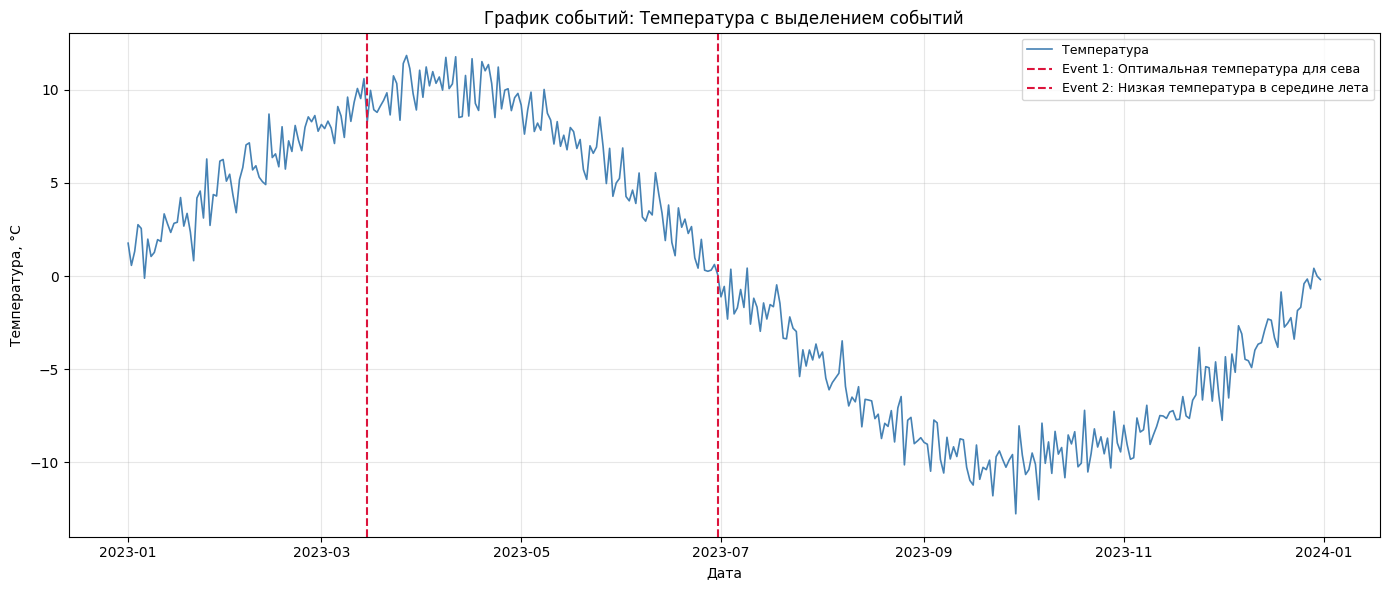

In [40]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Чтение данных
df = pd.read_csv('temperature_data.csv', index_col='Date', parse_dates=['Date'])

# Словарь событий
events = {
    'Event 1': {'Date': '2023-03-15',
                'Description': 'Оптимальная температура для сева'},
    'Event 2': {'Date': '2023-06-30',
                'Description': 'Низкая температура в середине лета'}
}

# Построение графика событий
fig, ax = plt.subplots(figsize=(14, 6))

# Исходный ряд
ax.plot(df.index, df['Temperature'],
        color='steelblue', linewidth=1.2, label='Температура')

# Вертикальные линии событий
for event, info in events.items():
    ax.axvline(x=pd.Timestamp(info['Date']),
               color='crimson', linestyle='--', linewidth=1.5,
               label=f'{event}: {info["Description"]}')

# Оформление
ax.set_title('График событий: Температура с выделением событий')
ax.set_xlabel('Дата')
ax.set_ylabel('Температура, °C')
ax.legend(loc='upper right', fontsize=9)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


**Разбор кода.** Назначение основных инструкций приведено в таблице 12.1.

**Таблица 12.1.** Назначение инструкций построения графика событий

| Инструкция | Назначение |
|---|---|
| `events = {...}` | Словарь событий: ключ — имя, значение — дата и описание |
| `ax.plot(df.index, df['Temperature'], ...)` | Построение исходного временного ряда |
| `ax.axvline(x=pd.Timestamp(info['Date']), ...)` | Вертикальная линия в момент события |
| `color='crimson'`, `linestyle='--'` | Оформление линий событий: красный пунктир для контраста |
| `label=f'{event}: {info["Description"]}'` | Подпись события для легенды |
| `ax.legend(loc='upper right', fontsize=9)` | Легенда в правом верхнем углу мелким шрифтом |

**Замечание 12.4.** В исходном коде была **типичная ошибка**: вызов `plt.axvline` внутри цикла с аргументом `label` создаёт корректные подписи, однако **все последующие настройки графика** (после цикла) могут конфликтовать с состоянием текущей оси. В исправленном коде используется явная работа через объект `ax`, что делает построение надёжным и воспроизводимым.

**Замечание 12.5.** Параметр `marker='o'` в исходном коде **избыточен** для временного ряда с ежедневной дискретизацией: 365 маркеров на графике создают визуальный шум и затрудняют чтение линии. Маркеры следует использовать только при малом числе наблюдений (например, при месячных или квартальных данных).

## 12.4. Интерпретация графика событий

На построенном графике (пример 12.1) наблюдаются следующие особенности.

1. **Исходный ряд** — плавная синусоида с годовым периодом, отражающая сезонное изменение температуры.

2. **Событие 1 (15 марта)** — «Оптимальная температура для сева». В этот день линия температуры пересекает нулевую отметку, переходя из отрицательной области в положительную. Содержательно это означает **начало периода, благоприятного для сельскохозяйственных работ**.

3. **Событие 2 (30 июня)** — «Низкая температура в середине лета». В этот день температура находится **ниже типичного для лета уровня** — аномальное похолодание на фоне общего сезонного максимума. На графике видно, что в этот момент кривая испытывает локальный «провал».

4. **Отсутствие других аномалий.** Между событиями график ведёт себя плавно, без резких скачков и сдвигов уровня. Это означает, что данные события **не привели к долговременным изменениям** — эффект был локальным.

**Замечание 12.6.** График событий позволяет **содержательно интерпретировать аномалии**. Если бы мы анализировали только числовой ряд, локальный «провал» в конце июня был бы просто выбросом. Благодаря аннотации события становится ясно, что это **реальное похолодание**, а не ошибка измерения.

## 12.5. Различение типов событий

**Замечание 12.7.** В реальных задачах события имеют **разную природу** и, соответственно, разный ожидаемый эффект. Полезно различать события по типу:

- **импульсные** — кратковременные воздействия (один день);
- **интервальные** — длящиеся во времени (неделя, месяц);
- **сдвигающие уровень** — приводящие к долговременному изменению среднего;
- **сезонные** — повторяющиеся с определённой периодичностью.

**Пример 12.2.** Построим график с двумя типами событий: положительными (зелёные) и отрицательными (красные).



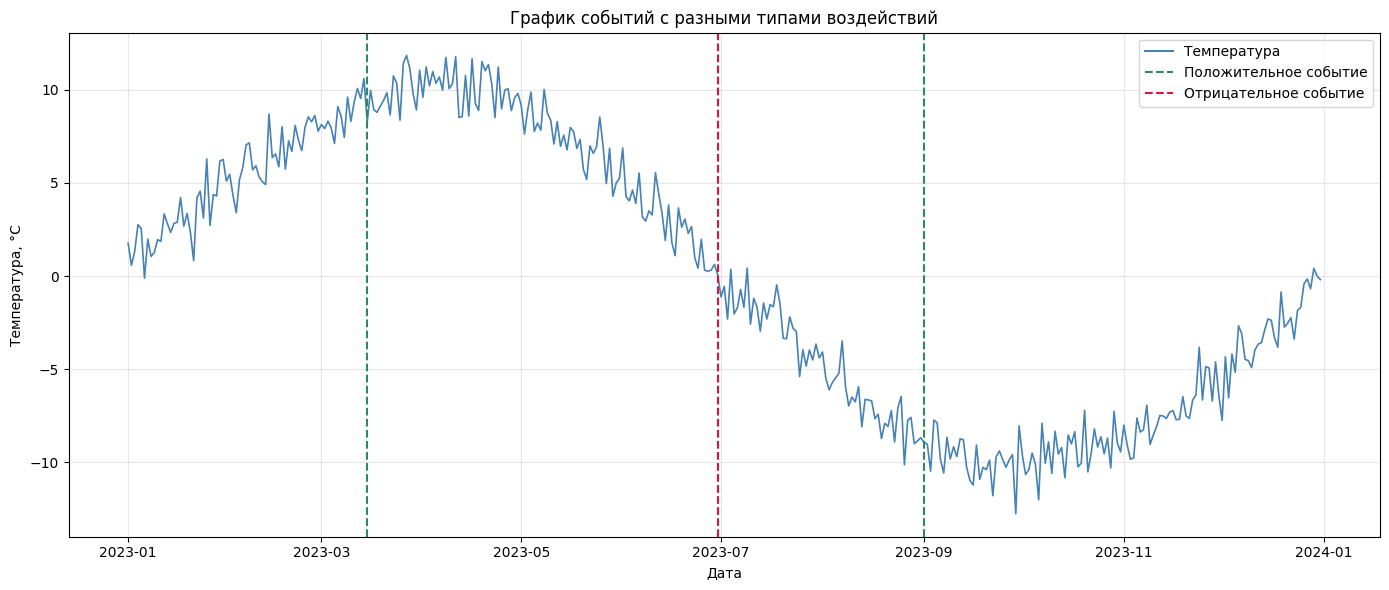

In [41]:
# События с типами
events_typed = [
    {'date': '2023-03-15', 'label': 'Начало сева',       'type': 'positive'},
    {'date': '2023-06-30', 'label': 'Аномальное похолодание', 'type': 'negative'},
    {'date': '2023-09-01', 'label': 'Начало сбора урожая', 'type': 'positive'},
]

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(df.index, df['Temperature'],
        color='steelblue', linewidth=1.2, label='Температура')

for ev in events_typed:
    color = 'seagreen' if ev['type'] == 'positive' else 'crimson'
    ax.axvline(x=pd.Timestamp(ev['date']),
               color=color, linestyle='--', linewidth=1.5)

# Ручная легенда для типов событий
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], color='steelblue', linewidth=1.5, label='Температура'),
    Line2D([0], [0], color='seagreen', linewidth=1.5, linestyle='--',
           label='Положительное событие'),
    Line2D([0], [0], color='crimson', linewidth=1.5, linestyle='--',
           label='Отрицательное событие'),
]
ax.legend(handles=legend_elements, loc='upper right', fontsize=10)

ax.set_title('График событий с разными типами воздействий')
ax.set_xlabel('Дата')
ax.set_ylabel('Температура, °C')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



**Разбор кода.** События хранятся в **списке словарей** (а не в словаре словарей) — это удобнее для хранения разнородных атрибутов. Цвет линии выбирается динамически по полю `type`. Для легенды применяется **ручное построение** через `Line2D`, поскольку автоматическая легенда дублировала бы события.

**Замечание 12.8.** Классификация событий по типу помогает **быстро ориентироваться** на графике: зелёные линии — ожидаемое положительное влияние, красные — отрицательное, серые — нейтральное. Это особенно полезно при большом числе событий (десятки аннотаций).

## 12.6. Интервальные события

**Пример 12.3.** Многие события длятся во времени (например, рекламная кампания, забастовка, отопительный сезон). Такие события удобно отображать **затенёнными интервалами**.



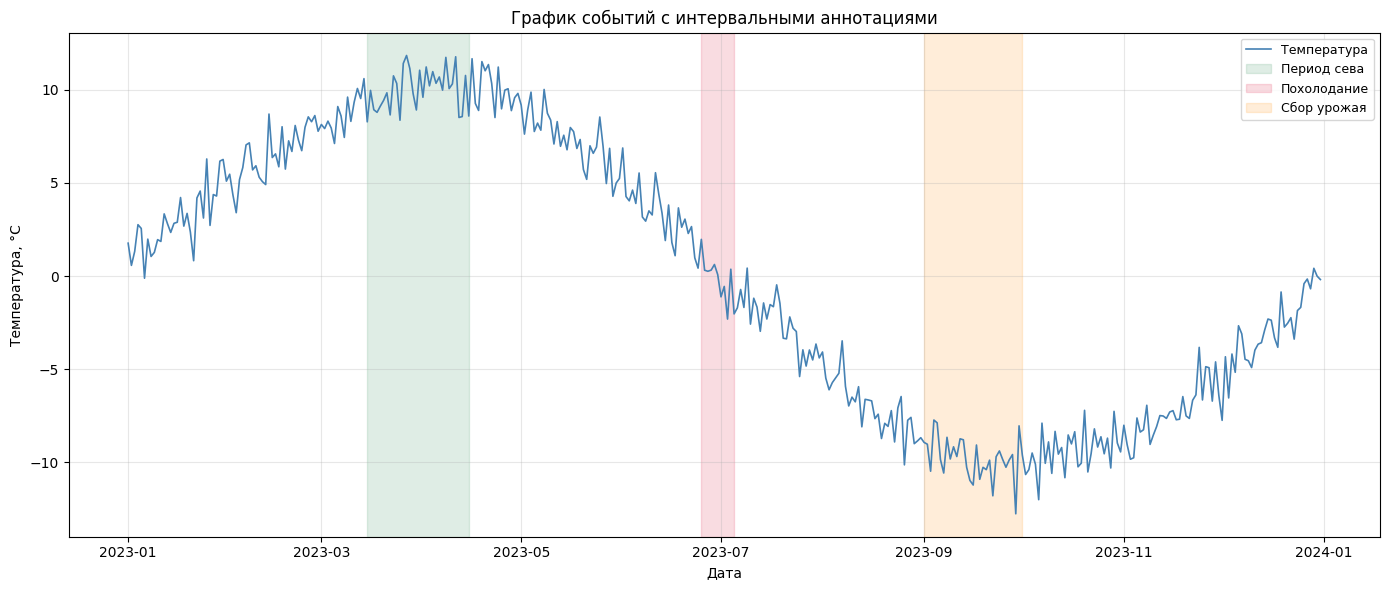

In [42]:
# Интервальные события
intervals = [
    {'start': '2023-03-15', 'end': '2023-04-15',
     'label': 'Период сева',      'color': 'seagreen'},
    {'start': '2023-06-25', 'end': '2023-07-05',
     'label': 'Похолодание',      'color': 'crimson'},
    {'start': '2023-09-01', 'end': '2023-10-01',
     'label': 'Сбор урожая',      'color': 'darkorange'},
]

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(df.index, df['Temperature'],
        color='steelblue', linewidth=1.2, label='Температура')

for iv in intervals:
    ax.axvspan(pd.Timestamp(iv['start']), pd.Timestamp(iv['end']),
               color=iv['color'], alpha=0.15, label=iv['label'])

ax.set_title('График событий с интервальными аннотациями')
ax.set_xlabel('Дата')
ax.set_ylabel('Температура, °C')
ax.legend(loc='upper right', fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



**Разбор кода.** Функция `ax.axvspan(xmin, xmax, ...)` закрашивает **вертикальную полосу** между двумя датами. Параметр `alpha=0.15` задаёт высокую прозрачность, чтобы заливка не перекрывала основную линию.

**Замечание 12.9.** Интервальная аннотация принципиально отличается от точечной:

- **точечное событие** отвечает на вопрос «*когда произошло*»;
- **интервальное событие** отвечает на вопрос «*как долго длилось*».

В анализе временных рядов второе часто важнее: эффект рекламной кампании, например, может проявляться в течение нескольких недель после её окончания. Интервальная аннотация позволяет визуально оценить **длительность эффекта**.

## 12.7. График событий с оценкой эффекта

**Пример 12.4.** Одной из самых ценных возможностей графика событий является **визуальная оценка эффекта** — сопоставление ряда «до» и «после» события.



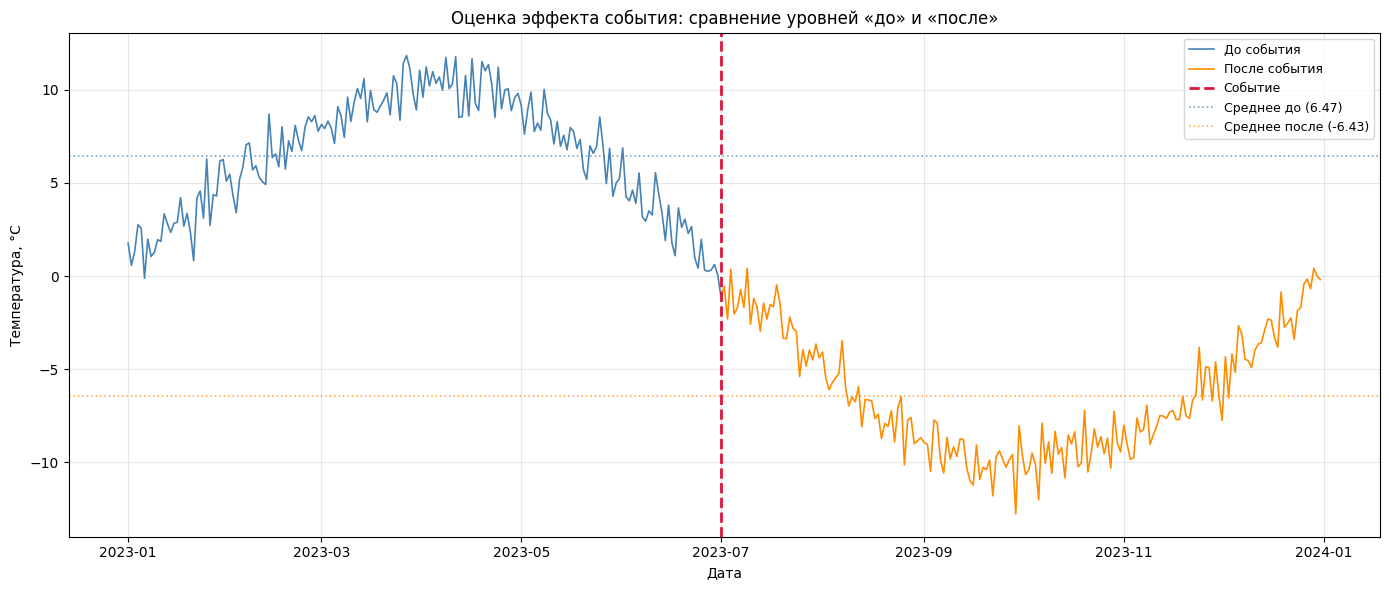

In [43]:
# Наблюдаемое событие-вмешательство
event_date = pd.Timestamp('2023-07-01')

# Разделение ряда на две части
before = df.loc[:event_date, 'Temperature']
after  = df.loc[event_date:, 'Temperature']

fig, ax = plt.subplots(figsize=(14, 6))

# Ряд до события
ax.plot(before.index, before, color='steelblue',
        linewidth=1.2, label='До события')
# Ряд после события
ax.plot(after.index, after, color='darkorange',
        linewidth=1.2, label='После события')

# Вертикальная линия события
ax.axvline(event_date, color='crimson', linestyle='--',
           linewidth=2, label='Событие')

# Горизонтальные линии средних уровней
ax.axhline(before.mean(), color='steelblue', linestyle=':',
           linewidth=1.2, alpha=0.7,
           label=f'Среднее до ({before.mean():.2f})')
ax.axhline(after.mean(), color='darkorange', linestyle=':',
           linewidth=1.2, alpha=0.7,
           label=f'Среднее после ({after.mean():.2f})')

ax.set_title('Оценка эффекта события: сравнение уровней «до» и «после»')
ax.set_xlabel('Дата')
ax.set_ylabel('Температура, °C')
ax.legend(loc='upper right', fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



**Разбор кода.** Ряд разделяется по дате события с помощью `.loc`. Для каждой части вычисляется среднее и наносится горизонтальной пунктирной линией. Различие средних — **первая приближённая оценка эффекта** события.

**Интерпретация.** На графике видно:

1. **Смена среднего уровня** — если событие действительно повлияло на ряд, средние значения до и после будут различаться.
2. **Смена режима** — если после события ряд продолжает вести себя как раньше, эффект был **кратковременным**; если поведение изменилось — **долговременным**.
3. **Направление эффекта** — если среднее после события выше, эффект положительный; если ниже — отрицательный.

**Замечание 12.10.** Простое сравнение средних до и после — **самая грубая** оценка эффекта. На неё влияют тренд, сезонность и другие события. Для строгой оценки используются методы:

- **разность разностей (difference-in-differences)**;
- **прерванный временной ряд (interrupted time series, ITS)**;
- **синтетический контроль (synthetic control)**;
- **модели с фиктивными переменными (dummy variables)**.

График событий — **отправная точка** такого анализа, а не его замена.

## 12.8. Сложный случай: множество событий

**Замечание 12.11.** При большом числе событий (десятки или сотни) нанесение всех вертикальных линий на один график приводит к **визуальному хаосу**: линии накладываются друг на друга, легенда становится нечитаемой. В такой ситуации применяют следующие приёмы:

1. **Группировка событий по типу.** События одного типа (праздники, аварии, кампании) отображают одинаковым цветом и объединяют в одну запись легенды.
2. **Разделение на несколько подграфиков.** Основной ряд — на верхнем подграфике, события разных типов — на нижних «дорожках» (lane chart).
3. **Полупрозрачные полосы.** Интервальные события рисуются с `alpha=0.1–0.2`, чтобы не перекрывать основную линию.
4. **Интерактивная визуализация.** В библиотеках `plotly`, `bokeh`, `altair` подписи событий появляются только при наведении курсора.

**Пример 12.5.** Разделение событий разных типов на «дорожки».




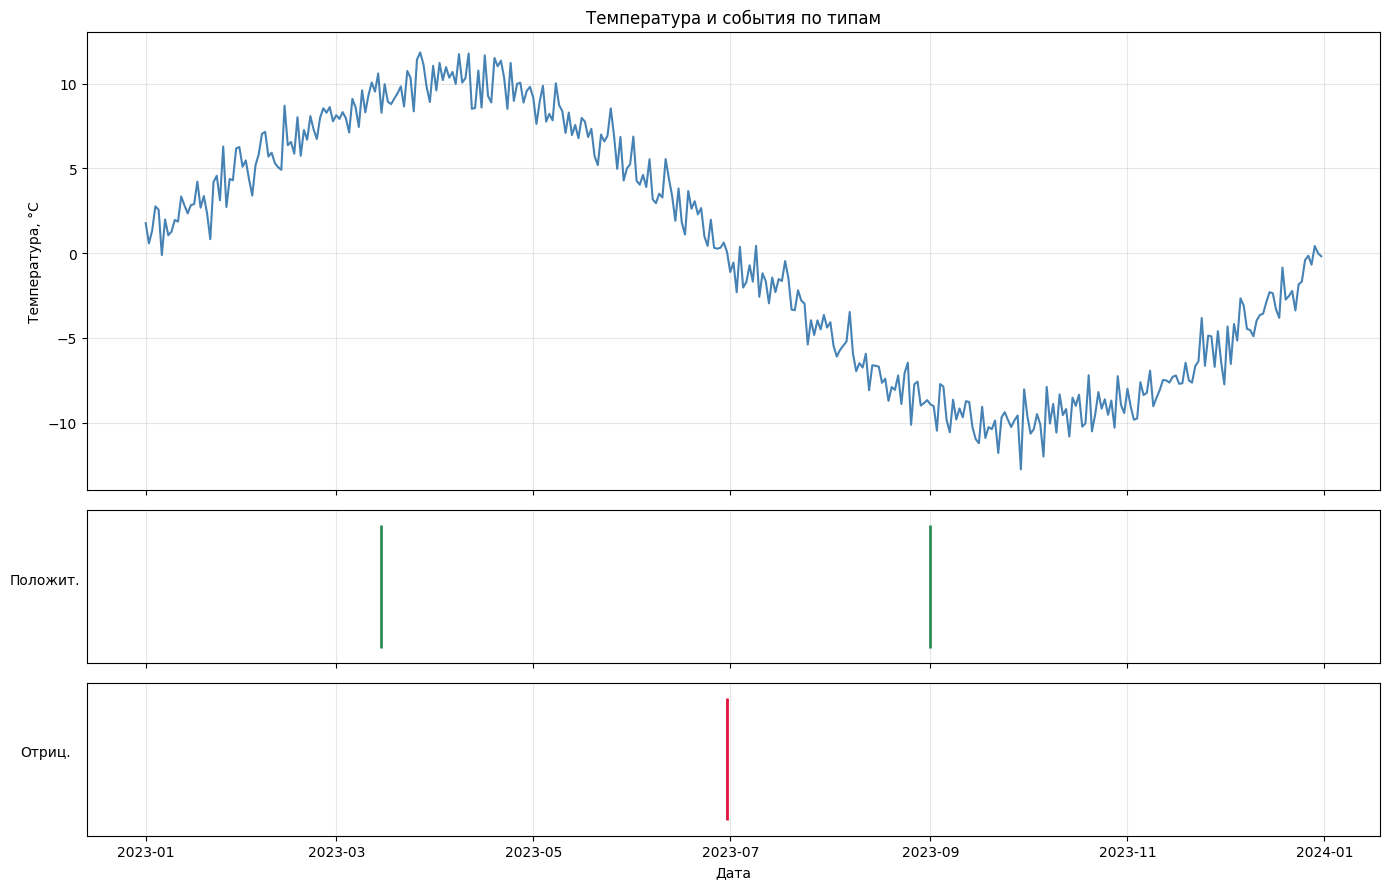

In [44]:
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True,
                          gridspec_kw={'height_ratios': [3, 1, 1]})

# Основной ряд
axes[0].plot(df.index, df['Temperature'], color='steelblue')
axes[0].set_title('Температура и события по типам')
axes[0].set_ylabel('Температура, °C')
axes[0].grid(True, alpha=0.3)

# Дорожка положительных событий
positive_events = pd.to_datetime(['2023-03-15', '2023-09-01'])
axes[1].eventplot(positive_events, colors='seagreen', lineoffsets=0.5,
                  linelengths=0.8, linewidths=2)
axes[1].set_yticks([])
axes[1].set_ylabel('Положит.', rotation=0, labelpad=30)
axes[1].set_ylim(0, 1)
axes[1].grid(True, alpha=0.3)

# Дорожка отрицательных событий
negative_events = pd.to_datetime(['2023-06-30'])
axes[2].eventplot(negative_events, colors='crimson', lineoffsets=0.5,
                  linelengths=0.8, linewidths=2)
axes[2].set_yticks([])
axes[2].set_ylabel('Отриц.', rotation=0, labelpad=30)
axes[2].set_ylim(0, 1)
axes[2].set_xlabel('Дата')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()



**Разбор кода.** Функция `ax.eventplot` строит **диаграмму событий** — компактное представление моментов времени в виде вертикальных линий на одной «дорожке». Такая компоновка позволяет отобразить сотни событий без визуального шума.

**Замечание 12.12.** Метод `eventplot` — **специальный инструмент matplotlib** для визуализации событий. В отличие от `axvline`, он позволяет рисовать **множество событий** на одной строке без перекрытия и с автоматической регулировкой длины линий.

## 12.9. Сравнение с ранее рассмотренными инструментами

**Таблица 12.2.** График событий в системе инструментов визуализации

| Характеристика | Линейный | Гистограмма | Коррелограмма | Сезонный | Точечный | Сглаживание | Контурный | Box Plot | Run Sequence | **Event Plot** |
|---|---|---|---|---|---|---|---|---|---|---|
| По оси X | время | значение | лаг | фаза сезона | значение $X$ | время | время-1 | группа | номер | **время** |
| Внешний контекст | нет | нет | нет | нет | нет | нет | нет | нет | нет | **да** |
| Основная задача | динамика | распределение | корреляция | сезонный профиль | связь $X$–$Y$ | тренд | двумерная сезонность | группы | последовательность | **сопоставление с событиями** |

**Замечание 12.13.** График событий **уникален** среди рассмотренных инструментов: он единственный, который **вносит в анализ внешнюю информацию**, не содержащуюся в самом временном ряде. Все остальные инструменты работают с числовыми значениями ряда; график событий позволяет **связать числовые закономерности с содержательными причинами**.

## 12.10. Выводы по разделу

В настоящем разделе:

1. дано определение графика событий и перечислены решаемые с его помощью задачи;
2. введены математические понятия индикаторной функции события и аннотированного ряда;
3. построен базовый график событий для ряда температуры и разобрано назначение каждой инструкции;
4. проведена интерпретация — установлена связь аномалий с конкретными содержательными событиями;
5. рассмотрены разные типы событий (положительные, отрицательные, импульсные, интервальные);
6. показано применение графика событий для оценки эффекта вмешательства;
7. рассмотрены приёмы работы с большим числом событий (разделение на дорожки, `eventplot`);
8. определено место графика событий в общей системе инструментов визуализации.

**Замечание 12.14.** График событий — **связующее звено** между статистическим анализом временного ряда и его **содержательной интерпретацией**. Если все предыдущие инструменты отвечали на вопросы «*как*» (как меняется, как распределено, как связано), то график событий отвечает на вопрос «*почему*» — какие внешние обстоятельства могли вызвать наблюдаемые изменения. Именно это делает его незаменимым в прикладных задачах бизнес-аналитики, климатологии, энергетики и финансов, где от аналитика требуется не только описать ряд, но и **объяснить его поведение**.

Применение графика событий в комплексе с ранее рассмотренными инструментами завершает формирование **полного набора визуальных методов предварительного анализа временных рядов**. Совместное использование линейного графика, гистограммы, коррелограммы, сезонного, точечного, контурного графиков, диаграммы размахов, графика изменчивости и графика событий позволяет аналитику:

- **описать** структуру ряда во всех аспектах (динамика, распределение, корреляция, сезонность, изменчивость);
- **объяснить** наблюдаемые закономерности через внешний контекст;
- **обосновать** выбор прогнозной модели и методов предварительной обработки данных.

Выбор конкретного типа графика зависит от целей анализа, структуры данных временного ряда и вопросов, которые требуется исследовать. Комбинация различных графиков может дать более полное представление о поведении временного ряда и его характеристиках.

# 13. Спектральные графики (Spectral Plots)

## 13.1. Определение и назначение

**Определение 13.1.** *Спектральным графиком* (или *периодограммой*, *спектрограммой*) называется графическое представление **распределения мощности (дисперсии) временного ряда по частотам**, позволяющее выделить доминирующие циклические компоненты и оценить их относительный вклад в общую вариабельность ряда.

**Определение 13.2.** *Спектральной плотностью мощности* (spectral density, power spectrum) временного ряда $\{y_t\}$ называется функция $S(f)$, определённая для частот $f \in [0, 1/2]$ и характеризующая вклад колебаний с частотой $f$ в общую дисперсию ряда.

**Замечание 13.1.** Спектральный график — **принципиально иной взгляд** на временной ряд. Все ранее рассмотренные инструменты работали в **области времени** (time domain): по оси X откладывалось время, по оси Y — значения ряда. Спектральный анализ переходит в **частотную область** (frequency domain): по оси X откладывается **частота**, по оси Y — **мощность** (вклад данной частоты в дисперсию).

Этот переход аналогичен переходу от нотной записи музыкального произведения (временна́я область) к спектрограмме звука (частотная область): одна и та же информация, но представленная в разных системах координат, позволяет **увидеть разные закономерности**.

**Определение 13.3.** *Частотой* $f$ называется число полных циклов колебаний, приходящихся на единицу времени (или на одно наблюдение). Величина, обратная частоте, называется **периодом**:

$$T = \frac{1}{f}.$$

Например, для ряда с **годовой сезонностью** при ежедневной дискретизации: $T = 365$ дней, $f = 1/365 \approx 0{,}0027$ циклов в день.

Применение спектральных графиков в анализе временных рядов позволяет решить следующие задачи:

1. **обнаружение скрытых периодичностей** — выявление циклических компонент, незаметных визуально на линейном графике;
2. **оценка периода сезонности** — точное определение доминирующей частоты;
3. **сравнение вклада компонент** — какая частота даёт наибольший вклад в дисперсию;
4. **диагностика «белого шума»** — проверка гипотезы об отсутствии периодических компонент;
5. **идентификация циклических моделей** — выбор порядка сезонной модели SARIMA.

**Замечание 13.2.** Спектральный анализ особенно полезен, когда **период сезонности неизвестен** или когда ряд содержит **несколько наложенных циклов** (например, суточный, недельный и годовой). Коррелограмма (раздел 5) обнаруживает **наличие** сезонности, а спектрограмма — **точное значение периода** и **относительный вклад** каждой компоненты.

## 13.2. Математическая основа

### 13.2.1. Разложение в ряд Фурье

**Определение 13.4.** Любой временной ряд $\{y_t\}_{t=1}^{n}$ (при достаточно общих условиях) может быть представлен в виде суммы гармонических компонент:

$$y_t = a_0 + \sum_{k=1}^{\lfloor n/2 \rfloor} \bigl[a_k \cos(2\pi f_k t) + b_k \sin(2\pi f_k t)\bigr],$$

где $f_k = k/n$ — частоты Фурье, а коэффициенты $a_k$, $b_k$ определяются через скалярные произведения с базисными функциями.

**Определение 13.5.** *Периодограммой* (periodogram) называется функция

$$I(f_k) = \frac{2}{n} \left| \sum_{t=1}^{n} y_t \, e^{-2\pi i f_k t} \right|^2,$$

где $i$ — мнимая единица. Периодограмма — **эмпирическая оценка** спектральной плотности мощности.

### 13.2.2. Сглаженная спектральная плотность

**Замечание 13.3.** «Сырая» периодограмма сильно зашумлена и плохо интерпретируется. На практике применяют **сглаживание** спектра методами Уэлча (Welch), Блэкмана–Тьюки или многотаперным методом (multitaper).

**Определение 13.6.** *Метод Уэлча* — это усреднение периодограмм, вычисленных на **перекрывающихся сегментах** исходного ряда с применением оконной функции. Результат — сглаженная оценка спектра, устойчивая к случайным флуктуациям.

**Определение 13.7.** *Спектрограмма* (spectrogram) — частный случай спектрального графика, в котором спектр вычисляется **последовательно по окнам времени**. Результат — двумерная карта: по оси X — время, по оси Y — частота, цветом кодируется мощность. Спектрограмма позволяет отследить, как **меняется частотный состав ряда во времени**.

**Замечание 13.4.** Важное соотношение между дисперсией и спектром:

$$\mathrm{Var}(y) = \int_0^{1/2} S(f) \, df,$$

то есть **общая дисперсия ряда равна интегралу спектральной плотности по всем частотам**. Это означает, что площадь под спектральным графиком равна дисперсии ряда, а **высокие пики** на спектре соответствуют **мощным циклическим компонентам**.

### 13.2.3. Теорема Парсеваля

**Замечание 13.5.** Теорема Парсеваля утверждает, что **энергия сигнала сохраняется при переходе из временно́й области в частотную**. Практическое следствие: если на спектре есть ярко выраженный пик, это означает, что **значительная часть дисперсии ряда обусловлена одной циклической компонентой**. Это мощный диагностический признак: ряд с сильно выраженной сезонностью даёт **один резкий пик** на спектре, а «белый шум» — **плоскую линию** (равномерное распределение мощности по всем частотам).

## 13.3. Построение периодограммы

**Пример 13.1.** Построим периодограмму для синтетического ряда температуры (раздел 2).



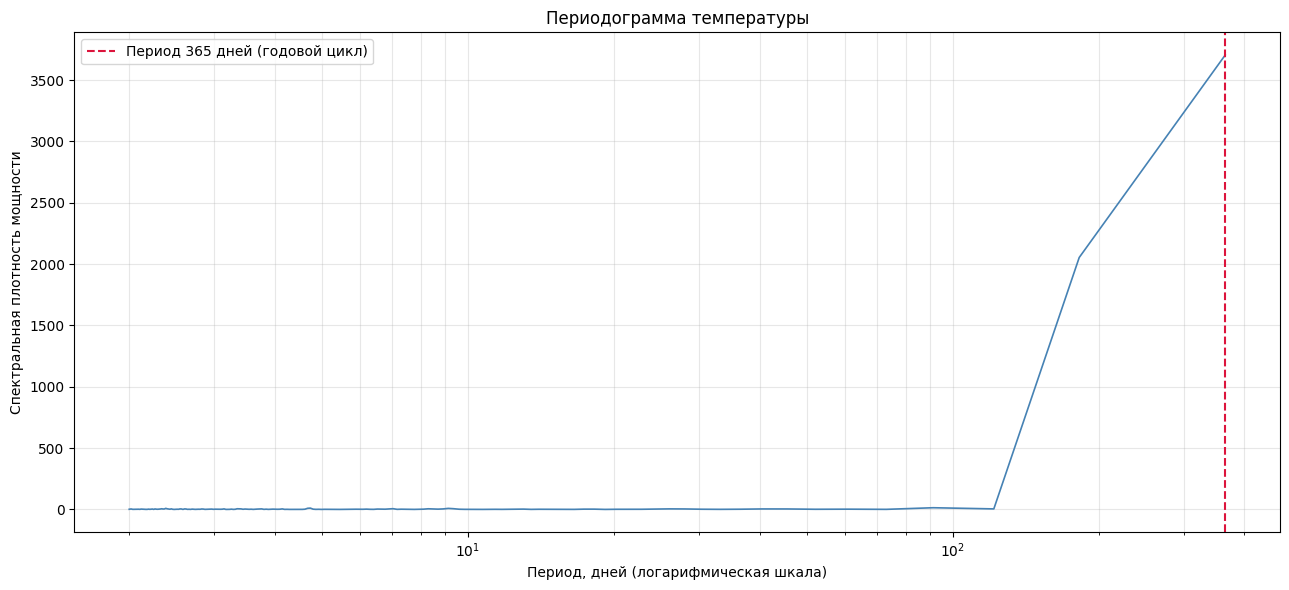

In [45]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import periodogram

# Чтение данных
df = pd.read_csv('temperature_data.csv', index_col='Date', parse_dates=['Date'])

# Вычисление периодограммы
frequencies, power = periodogram(df['Temperature'].values,
                                  fs=1.0,        # частота дискретизации (1 набл./день)
                                  window='hann', # окно Ханна
                                  detrend='linear')  # устранение линейного тренда

# Перевод частоты в период
periods = 1 / frequencies[1:]   # отбрасываем f = 0
power_clean = power[1:]

# Построение
fig, ax = plt.subplots(figsize=(13, 6))
ax.semilogx(periods, power_clean, color='steelblue', linewidth=1.2)
ax.set_title('Периодограмма температуры')
ax.set_xlabel('Период, дней (логарифмическая шкала)')
ax.set_ylabel('Спектральная плотность мощности')
ax.grid(True, which='both', alpha=0.3)
ax.axvline(365, color='crimson', linestyle='--',
           label='Период 365 дней (годовой цикл)')
ax.legend()
plt.tight_layout()
plt.show()



**Разбор кода.** Назначение основных инструкций приведено в таблице 13.1.

**Таблица 13.1.** Назначение инструкций построения периодограммы

| Инструкция | Назначение |
|---|---|
| `from scipy.signal import periodogram` | Импорт функции вычисления периодограммы |
| `periodogram(y, fs=1.0, window='hann', detrend='linear')` | Вычисление спектра: частота дискретизации 1/день, окно Ханна, устранение тренда |
| `periods = 1 / frequencies[1:]` | Перевод частот в периоды (отбрасываем $f = 0$) |
| `ax.semilogx(periods, power, ...)` | Построение графика в **логарифмической шкале** по оси X |
| `ax.axvline(365, ...)` | Вертикальная линия на периоде 365 дней — опорная точка для интерпретации |

**Замечание 13.6.** Ось X удобно откладывать **в периодах** (а не частотах): это делает интерпретацию более наглядной (365 дней вместо $0{,}0027$ цикл/день). **Логарифмическая шкала** позволяет одновременно видеть как короткие (недели), так и длинные (годы) циклы.

**Замечание 13.7.** Параметр `detrend='linear'` **устраняет линейный тренд** перед вычислением спектра. Это важно: длинный тренд создаёт **мощный низкочастотный пик**, который может маскировать сезонные компоненты. Если тренд не устранить, спектрограмма будет содержать «ложную» периодичность, связанную с конечной длиной ряда.

## 13.4. Интерпретация периодограммы

На построенном графике (пример 13.1) наблюдаются следующие особенности.

1. **Резкий пик на периоде ~365 дней.** Это **главная циклическая компонента** ряда — годовая сезонность. Пик ярко выделяется на фоне остальных значений, что означает **доминирование годовой сезонности** в общей дисперсии.

2. **Пик на периоде ~182 дня (полугодовой).** Второй, меньший по амплитуде пик — **вторая гармоника** годового цикла. Она возникает из-за неидеальной синусоидальности сезонной компоненты (например, если лето длится дольше, чем зима).

3. **Ровное «плато» на коротких периодах.** Мощность на высоких частотах (периоды < 10 дней) примерно постоянна и мала. Это **шумовая компонента** ряда — её спектр близок к спектру «белого шума».

4. **Отсутствие других пиков.** На спектре нет выраженных пиков на периодах, не кратных 365 — это означает, что **скрытых циклических компонент в ряде нет**.

**Замечание 13.8.** Периодограмма — **самый точный инструмент определения периода сезонности**. Если по линейному графику можно лишь приблизительно оценить, что «пик наступает примерно раз в год», то спектрограмма **точно указывает** период: положение максимума спектра соответствует $T = 365$ дней.

## 13.5. Сглаженная спектральная плотность (метод Уэлча)

**Замечание 13.9.** «Сырая» периодограмма, как видно из примера 13.1, довольно **зашумлена**: между значимыми пиками присутствуют случайные всплески. Для получения более устойчивой оценки применяют метод Уэлча.

**Пример 13.2.** Построение сглаженного спектра методом Уэлча.



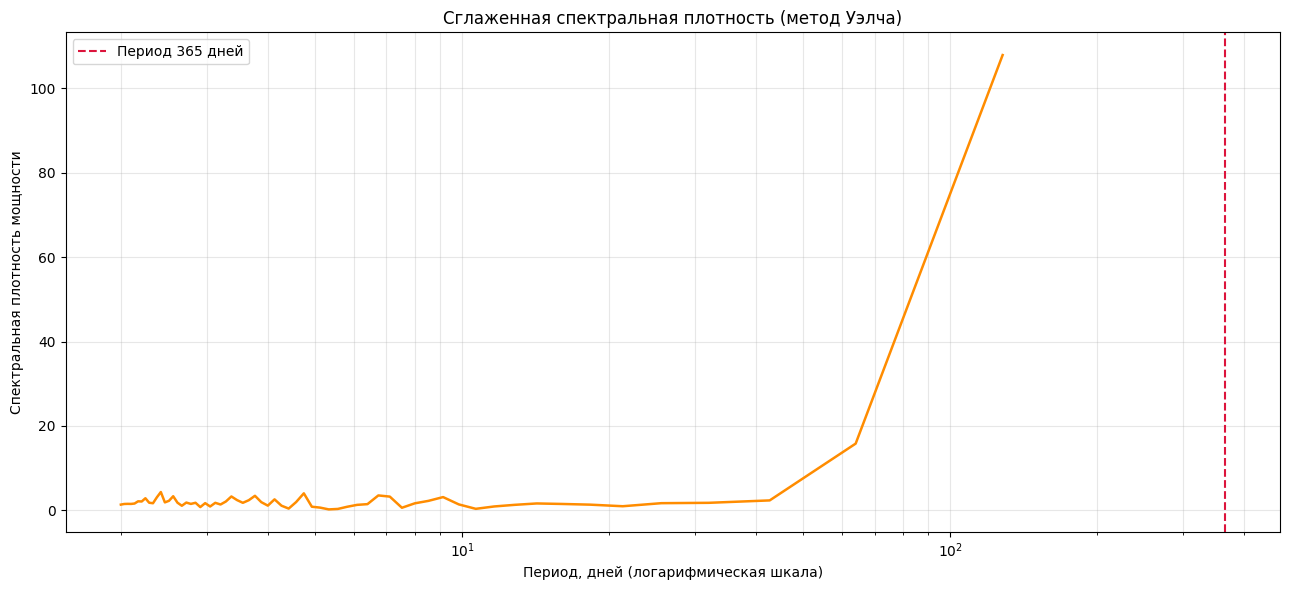

In [46]:
from scipy.signal import welch

# Метод Уэлча: разбиение на сегменты с перекрытием и усреднение
frequencies_w, psd_w = welch(df['Temperature'].values,
                              fs=1.0,
                              nperseg=128,       # размер сегмента
                              noverlap=64,       # перекрытие
                              window='hann',
                              detrend='linear')

periods_w = 1 / frequencies_w[1:]
psd_w_clean = psd_w[1:]

# Построение
fig, ax = plt.subplots(figsize=(13, 6))
ax.semilogx(periods_w, psd_w_clean, color='darkorange', linewidth=1.8)
ax.set_title('Сглаженная спектральная плотность (метод Уэлча)')
ax.set_xlabel('Период, дней (логарифмическая шкала)')
ax.set_ylabel('Спектральная плотность мощности')
ax.axvline(365, color='crimson', linestyle='--',
           label='Период 365 дней')
ax.grid(True, which='both', alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()



**Разбор кода.** Метод Уэлча разбивает ряд на сегменты по `nperseg=128` наблюдений с перекрытием `noverlap=64`, вычисляет периодограмму на каждом сегменте и усредняет их. Результат — **сглаженный спектр** с меньшим числом случайных флуктуаций.

**Сравнение с «сырой» периодограммой** приведено в таблице 13.2.

**Таблица 13.2.** Сравнение «сырой» периодограммы и сглаженного спектра

| Характеристика | Периодограмма | Спектр Уэлча |
|---|---|---|
| Степень сглаживания | слабая | сильная |
| Разрешение по частоте | высокое | ниже (зависит от nperseg) |
| Устойчивость к шуму | низкая | высокая |
| Выявление слабых пиков | затруднено | упрощено |
| Обнаружение узких пиков | хорошо | может «размыть» пик |

**Замечание 13.10.** Существует **компромисс** между сглаживанием и разрешением: чем больше сегмент (`nperseg`), тем лучше разрешение по частоте, но тем менее устойчива оценка. На практике подбирают параметры так, чтобы **основные пики** были отчётливо видны, а **шумовые флуктуации** — подавлены.

## 13.6. Спектрограмма: изменение спектра во времени

**Пример 13.3.** Если частотный состав ряда **меняется во времени** (например, в разные годы сезонность выражена по-разному), применяют **спектрограмму** — двумерную визуализацию спектра.



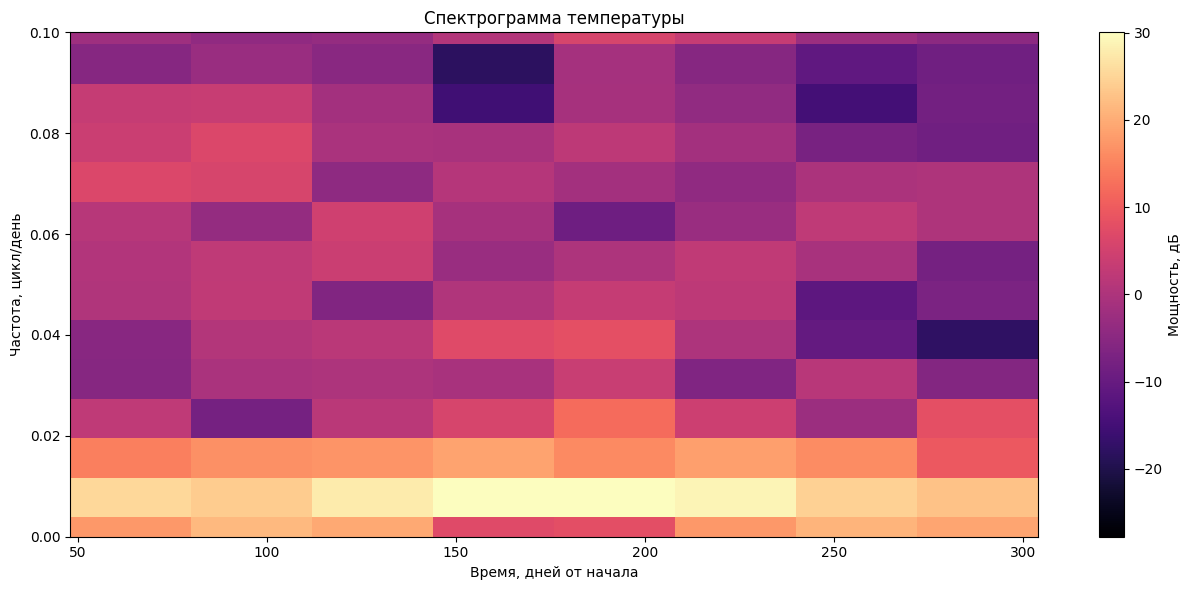

In [47]:
from scipy.signal import spectrogram

# Спектрограмма
frequencies_s, times_s, Sxx = spectrogram(df['Temperature'].values,
                                          fs=1.0,
                                          nperseg=128,
                                          noverlap=96,
                                          window='hann')

# Логарифмическая шкала мощности для лучшей видимости
Sxx_db = 10 * np.log10(Sxx + 1e-12)

# Построение
fig, ax = plt.subplots(figsize=(13, 6))
pcm = ax.pcolormesh(times_s, frequencies_s, Sxx_db,
                     shading='auto', cmap='magma')
plt.colorbar(pcm, ax=ax, label='Мощность, дБ')
ax.set_title('Спектрограмма температуры')
ax.set_xlabel('Время, дней от начала')
ax.set_ylabel('Частота, цикл/день')
ax.set_ylim(0, 0.1)   # ограничиваемся низкими частотами
plt.tight_layout()
plt.show()


**Разбор кода.** Функция `spectrogram` возвращает три массива: массив частот, массив моментов времени и матрицу мощностей. Функция `pcolormesh` строит тепловую карту, где цветом кодируется мощность.

**Интерпретация.** На спектрограмме по оси X — время, по оси Y — частота, цветом — мощность. Для стабильного ряда с годовой сезонностью вы увидите **горизонтальную яркую линию** на частоте $f = 1/365 \approx 0{,}0027$, присутствующую на всём интервале времени. Если бы сезонность усиливалась или ослабевала, яркость этой линии менялась бы вдоль оси X.

**Замечание 13.11.** Спектрограмма — инструмент анализа **нестационарных** рядов. Для **стационарных** рядов достаточно обычной периодограммы: спектр не меняется во времени, и его можно усреднить по всему интервалу.

## 13.7. Типовые формы спектров

Различным типам временных рядов соответствуют характерные формы спектральных графиков. Их распознавание — ключевой навык интерпретации.

**Таблица 13.3.** Типовые формы спектров и их интерпретация

| Тип ряда | Форма спектра | Что наблюдается |
|---|---|---|
| **Белый шум** | Плоская линия | Мощность равномерно распределена по всем частотам |
| **Сезонный ряд** | Резкие пики на частотах, кратных $1/T$ | Доминируют гармоники с периодом сезонности |
| **Ряд с трендом** | Мощный пик на нулевой частоте | Низкочастотная компонента доминирует |
| **AR(1) процесс** | Монотонно убывающая кривая | Мощность концентрируется на низких частотах |
| **Смесь циклов** | Несколько пиков на разных частотах | Присутствуют несколько независимых периодичностей |

**Замечание 13.12.** Практический приём: если вы видите на спектре **резкий одиночный пик**, скорее всего перед вами **чистая гармоника** (сезонность). Если пик **размыт** — сезонность **нестабильна** (период слегка меняется). Если спектр **плоский** — ряд представляет собой **шум**, прогнозирование бесперспективно. Если спектр **монотонно убывает** — ряд содержит **тренд** или **сильную автокорреляцию**.

**Пример 13.4.** Сравнение спектров трёх типов рядов.



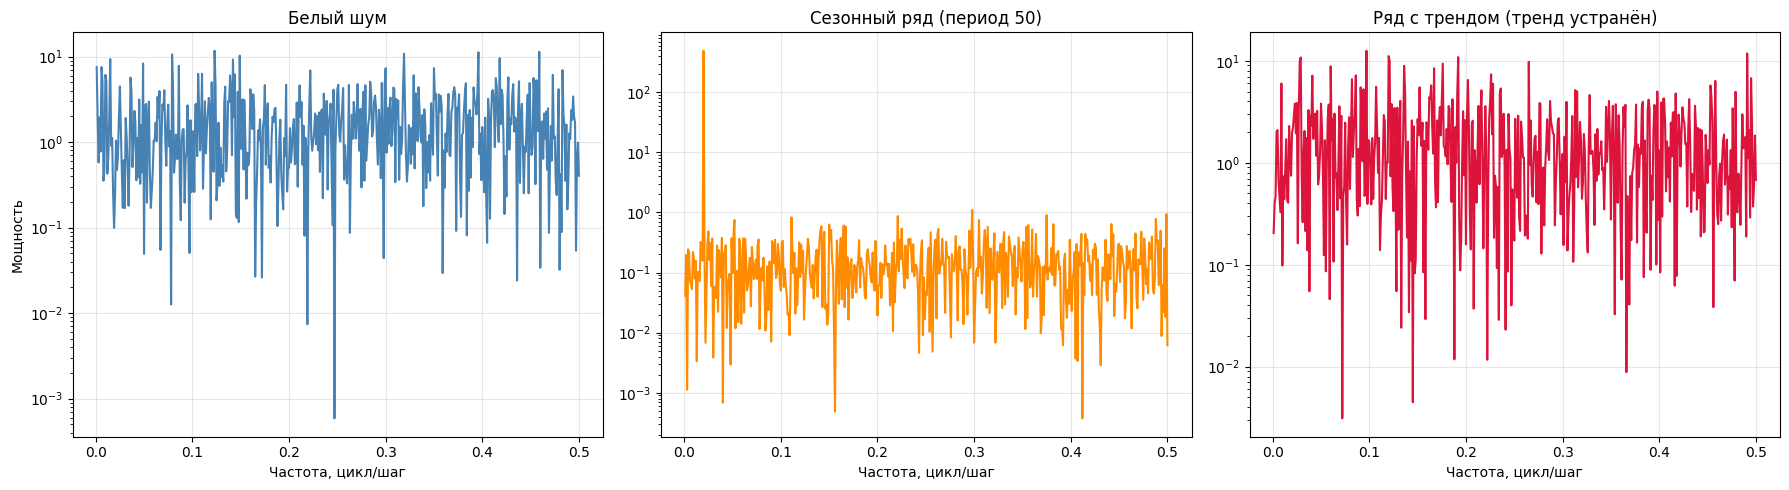

In [48]:
from scipy.signal import periodogram

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Белый шум
np.random.seed(0)
wn = np.random.normal(size=1000)
f1, p1 = periodogram(wn, fs=1.0)
axes[0].semilogy(f1[1:], p1[1:], color='steelblue')
axes[0].set_title('Белый шум')
axes[0].set_xlabel('Частота, цикл/шаг')
axes[0].set_ylabel('Мощность')
axes[0].grid(True, alpha=0.3)

# 2. Сезонный ряд
seasonal = np.sin(np.arange(1000) * 2 * np.pi / 50) + 0.3 * np.random.normal(size=1000)
f2, p2 = periodogram(seasonal, fs=1.0)
axes[1].semilogy(f2[1:], p2[1:], color='darkorange')
axes[1].set_title('Сезонный ряд (период 50)')
axes[1].set_xlabel('Частота, цикл/шаг')
axes[1].grid(True, alpha=0.3)

# 3. Ряд с трендом
trend_series = np.linspace(0, 10, 1000) + np.random.normal(size=1000)
f3, p3 = periodogram(trend_series, fs=1.0, detrend='linear')
axes[2].semilogy(f3[1:], p3[1:], color='crimson')
axes[2].set_title('Ряд с трендом (тренд устранён)')
axes[2].set_xlabel('Частота, цикл/шаг')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


**Интерпретация.** Первый спектр (белый шум) почти горизонтален — мощность равномерно распределена по частотам. Второй спектр (сезонный ряд) содержит резкий пик на частоте $f = 1/50$. Третий спектр (после устранения тренда) — низкочастотная компонента удалена, остался шум.

## 13.8. Связь со временны́ми инструментами

**Замечание 13.13.** Спектральные и временны́е графики **эквивалентны по информации**, но **различны по акценту**. Соответствие между инструментами приведено в таблице 13.4.

**Таблица 13.4.** Соответствие временны́х и частотных инструментов

| Временно́й инструмент | Частотный аналог | Что анализируют |
|---|---|---|
| Линейный график | Периодограмма | Наличие циклов и их периоды |
| Коррелограмма (ACF) | Спектр мощности | Автокорреляционная структура |
| Сезонная декомпозиция | Гармонический анализ | Выделение отдельных компонент |
| Сглаживание | Низкочастотный фильтр | Выделение медленной динамики |

**Замечание 13.14.** Коррелограмма и спектрограмма **связаны преобразованием Фурье**: спектр есть преобразование Фурье автокорреляционной функции (теорема Винера–Хинчина). Поэтому периодические пики АКФ и резкие пики спектра — **два представления одной и той же информации**.

## 13.9. Сравнение с ранее рассмотренными инструментами

**Таблица 13.5.** Спектральный график в системе инструментов визуализации

| Характеристика | Линейный | Гистограмма | Коррелограмма | Сезонный | Точечный | Сглаживание | Контурный | Box Plot | Run Sequence | Event Plot | **Spectral** |
|---|---|---|---|---|---|---|---|---|---|---|---|
| По оси X | время | значение | лаг | фаза сезона | значение $X$ | время | время-1 | группа | номер | время | **частота** |
| По оси Y | значение | частота | АКФ | значение | значение $Y$ | — | время-2 | значение | значение | — | **мощность** |
| Область анализа | время | время | время | время | время | время | время | время | время | время | **частота** |
| Основная задача | динамика | распределение | корреляция | сезонный профиль | связь $X$–$Y$ | тренд | двумерная сезонность | группы | последовательность | события | **циклы, периоды** |

**Замечание 13.15.** Спектральный график **дополняет** временны́е инструменты, но не заменяет их:

- **линейный график** позволяет **увидеть** сезонность, но не даёт её точного периода;
- **спектрограмма** даёт **точный период** и **относительный вклад** каждой компоненты, но не показывает, как ряд ведёт себя во времени;
- **коррелограмма** обнаруживает наличие сезонности, но при наложении нескольких циклов её пики могут «перепутаться»;
- **спектрограмма** позволяет однозначно **разделить несколько наложенных циклов** по отдельным пикам.

Таким образом, спектральный анализ — **незаменимый инструмент** при работе с рядами, содержащими **сложную циклическую структуру** (несколько периодов, некратные гармоники, слабо выраженные периодичности).

## 13.10. Ограничения спектрального анализа

**Таблица 13.6.** Преимущества и ограничения спектрального анализа

| Преимущества | Ограничения |
|---|---|
| Точное определение периода сезонности | Требуется достаточно длинный ряд (десятки и сотни наблюдений) |
| Выявление скрытых циклических компонент | Предполагает стационарность ряда |
| Разделение нескольких наложенных циклов | Чувствительность к выбору окна сглаживания |
| Компактное представление структуры | Результат сложнее интерпретировать, чем временны́е графики |
| Связь с теоретическими моделями (ARMA) | Плохо работает при неравномерной дискретизации |

**Замечание 13.16.** Для корректного спектрального анализа необходимо **не менее нескольких десятков периодов** основной циклической компоненты. Если ряд содержит всего 1–2 цикла сезонности (как в примере 13.1: один год ежедневных наблюдений), то для устойчивой оценки спектра этого может быть недостаточно. В таких случаях периодограмму **сглаживают** (метод Уэлча) или применяют **регуляризацию** (multitaper).

**Замечание 13.17.** Спектральный анализ предполагает **стационарность** ряда. Если ряд содержит тренд, его необходимо **предварительно устранить** (`detrend='linear'` в `scipy.signal.periodogram`). Если ряд содержит сдвиги уровня, спектр будет искажён — в этом случае сначала применяют методы обнаружения точек разладки (change point detection).

## 13.11. Выводы по разделу

В настоящем разделе:

1. дано определение спектрального графика, спектральной плотности мощности и периодограммы;
2. раскрыта математическая основа спектрального анализа (разложение Фурье, теорема Парсеваля, теорема Винера–Хинчина);
3. построена периодограмма для синтетического ряда температуры и разобрано назначение каждой инструкции;
4. проведена интерпретация — установлен доминирующий пик на периоде 365 дней, вторая гармоника на 182 дня и шумовое «плато» на высоких частотах;
5. рассмотрено сглаживание спектра методом Уэлча;
6. построена спектрограмма, позволяющая отследить изменение частотного состава во времени;
7. рассмотрены типовые формы спектров для различных типов рядов;
8. установлена связь спектральных инструментов с временны́ми (коррелограмма ↔ спектр);
9. определено место спектрального графика в общей системе инструментов визуализации;
10. сформулированы ограничения метода.

**Замечание 13.18.** Спектральный график — **мощный аналитический инструмент**, **принципиально отличающийся** от всех ранее рассмотренных. Если все предыдущие визуализации работали в **области времени**, спектрограмма переходит в **область частот**, раскрывая структуру ряда через призму циклических компонент. Это делает спектральный анализ незаменимым при работе с:

- рядами сложной циклической структуры (несколько сезонных периодов);
- рядами с неизвестным периодом сезонности;
- задачами выделения слабых периодических сигналов на фоне шума;
- задачами фильтрации данных (частотная селекция компонент).

Спектральный анализ замыкает серию инструментов визуализации временных рядов, представленных в настоящем обзоре. Совместное применение линейного графика, гистограммы, коррелограммы, сезонного, точечного, контурного графиков, диаграммы размахов, графика изменчивости, графика событий и спектрограммы формирует **полный арсенал методов визуального анализа временных рядов** — от базовых временны́х представлений до углублённого частотного анализа, — позволяющий решать **практически любую задачу** предварительного исследования данных перед построением прогнозной модели.

# 14. Предварительный анализ временного ряда

## 14.1. Определение и назначение

**Определение 14.1.** *Предварительным анализом* временного ряда называется совокупность статистических процедур, выполняемых **до** построения прогнозной модели с целью:

1. оценить **качество данных** (наличие пропусков, выбросов, ошибок);
2. получить **числовые характеристики** ряда (среднее, медиана, дисперсия, асимметрия);
3. проверить **фундаментальные гипотезы** о структуре ряда (стационарность, нормальность, наличие тренда).

**Замечание 14.1.** Визуальный анализ (разделы 3–13) и предварительный анализ **взаимодополняют** друг друга. Визуализация даёт **качественную** картину: форму распределения, наличие сезонности, тренд. Предварительный анализ даёт **количественные** оценки: точные значения средних, формальные статистические тесты, числовые критерии.

Только совместное применение обоих подходов позволяет **обоснованно** перейти к этапу моделирования. Визуальное впечатление «ряд стационарен» должно быть подтверждено формальным тестом (например, Дики–Фуллера); визуальное впечатление «есть выбросы» должно быть проверено численным критерием (например, правилом Тьюки).

**Определение 14.2.** *Статистической гипотезой* называется утверждение о свойствах распределения или структуры ряда. *Статистическим тестом* называется правило, позволяющее по выборке принять или отвергнуть гипотезу с заданным уровнем значимости $\alpha$ (обычно $\alpha = 0{,}05$).

**Замечание 14.2.** Все три подраздела предварительного анализа — проверка пропусков и выбросов, дескриптивная статистика, тесты на стационарность — выполняются в **строгой последовательности**. Логика такова:

1. **Сначала** убедиться, что данные **чисты** (нет пропусков и выбросов);
2. **Затем** описать их **числовыми характеристиками**;
3. **И только после этого** проверять **структурные гипотезы** (стационарность).

Если пропуски не обработаны, дескриптивные статистики будут смещены; если выбросы не устранены, тест на стационарность может дать неверный результат.

---

## 14.2. Проверка на пропуски и выбросы

### 14.2.1. Пропущенные значения

**Определение 14.3.** *Пропущенным значением* (missing value, `NaN`) называется отсутствующее наблюдение временного ряда. В pandas пропуски обозначаются как `NaN` (Not a Number) или `NaT` (Not a Time).

**Определение 14.4.** *Механизм пропуска* описывает причину отсутствия наблюдения. Различают три типа:

- **MCAR** (Missing Completely At Random) — пропуск не зависит ни от значения ряда, ни от других переменных;
- **MAR** (Missing At Random) — пропуск зависит от других наблюдаемых переменных, но не от самого пропущенного значения;
- **MNAR** (Missing Not At Random) — пропуск зависит от самого пропущенного значения (например, датчик перестаёт работать при высоких температурах).

**Замечание 14.3.** Тип механизма определяет **стратегию обработки** пропусков:

- при MCAR допустимы простые методы (удаление или интерполяция);
- при MAR требуются модельные методы (например, заполнение регрессией);
- при MNAR необходимы специальные подходы (модель совместного распределения).

**Пример 14.1.** Проверка синтетического ряда температуры на пропуски.




In [49]:
import pandas as pd
import numpy as np

# Чтение данных
df = pd.read_csv('temperature_data.csv', index_col='Date', parse_dates=['Date'])

# Искусственно внесём пропуски
df.iloc[10:15, 0] = np.nan      # 5 дней подряд
df.iloc[100, 0] = np.nan         # единичный
df.iloc[200, 0] = np.nan

# Подсчёт пропусков
print("Всего наблюдений:", len(df))
print("Пропусков:", df['Temperature'].isna().sum())
print("Доля пропусков:", df['Temperature'].isna().mean().round(4))

# Где именно пропуски
print("\nИндексы пропущенных значений:")
print(df[df['Temperature'].isna()].index.tolist())

Всего наблюдений: 365
Пропусков: 7
Доля пропусков: 0.0192

Индексы пропущенных значений:
[Timestamp('2023-01-11 00:00:00'), Timestamp('2023-01-12 00:00:00'), Timestamp('2023-01-13 00:00:00'), Timestamp('2023-01-14 00:00:00'), Timestamp('2023-01-15 00:00:00'), Timestamp('2023-04-11 00:00:00'), Timestamp('2023-07-20 00:00:00')]



**Разбор кода.** Назначение основных инструкций приведено в таблице 14.1.

**Таблица 14.1.** Назначение инструкций проверки пропусков

| Инструкция | Назначение |
|---|---|
| `df['Temperature'].isna()` | Логическая маска пропущенных значений |
| `isna().sum()` | Подсчёт общего числа пропусков |
| `isna().mean()` | Доля пропусков от общего числа наблюдений |
| `df[df['Temperature'].isna()].index` | Даты с пропущенными значениями |

**Замечание 14.4.** Если доля пропусков превышает 10–20 %, следует **пересмотреть источник данных** — возможно, проблема в системе сбора. Если доля мала (< 5 %), применимы стандартные методы заполнения.

### 14.2.2. Стратегии обработки пропусков

**Определение 14.5.** *Интерполяцией* называется заполнение пропусков на основе соседних наблюдений. Основные методы:

- **прямое заполнение** (`ffill`) — копирование последнего известного значения;
- **обратное заполнение** (`bfill`) — копирование следующего известного значения;
- **линейная интерполяция** — линейная аппроксимация между соседними точками;
- **сплайн-интерполяция** — сглаживающая аппроксимация;
- **сезонная интерполяция** — учёт сезонной структуры (например, замена на значение того же дня предыдущего года).

**Пример 14.2.** Различные методы заполнения пропусков.




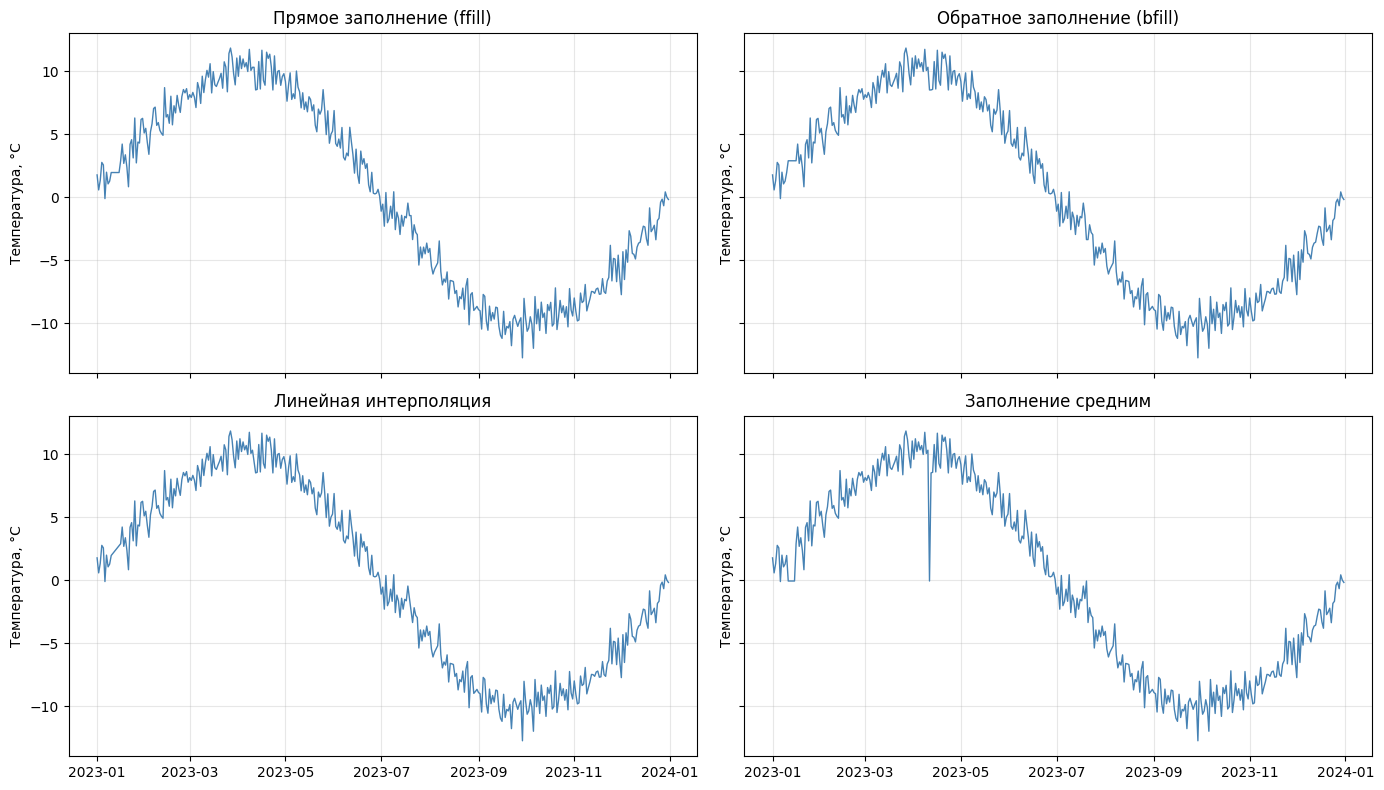

In [50]:
# Создание копий для сравнения
df_ffill   = df.copy()
df_bfill   = df.copy()
df_linear  = df.copy()
df_mean    = df.copy()

# Заполнение
df_ffill['Temperature']  = df['Temperature'].ffill()
df_bfill['Temperature']  = df['Temperature'].bfill()
df_linear['Temperature'] = df['Temperature'].interpolate(method='linear')
df_mean['Temperature']   = df['Temperature'].fillna(df['Temperature'].mean())

# Визуализация всех вариантов
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True, sharey=True)

for ax, (name, df_temp) in zip(axes.flat, [
        ('Прямое заполнение (ffill)', df_ffill),
        ('Обратное заполнение (bfill)', df_bfill),
        ('Линейная интерполяция', df_linear),
        ('Заполнение средним', df_mean)]):
    ax.plot(df.index, df_temp['Temperature'], color='steelblue', linewidth=1)
    ax.set_title(name)
    ax.grid(True, alpha=0.3)
    ax.set_ylabel('Температура, °C')

plt.tight_layout()
plt.show()



**Таблица 14.2.** Сравнение методов заполнения пропусков

| Метод | Сохраняет тренд | Сохраняет сезонность | Простота | Применимость |
|---|---|---|---|---|
| `ffill` / `bfill` | частично | нет | высокая | короткие пропуски |
| Линейная интерполяция | да | нет | высокая | короткие пропуски внутри ряда |
| Сплайн | да | частично | средняя | плавные ряды |
| Сезонная интерполяция | да | да | низкая | ряды с сезонностью |
| Заполнение средним | нет | нет | высокая | не рекомендуется (искажает дисперсию) |

**Замечание 14.5.** Заполнение **средним** — самый простой, но наименее корректный метод. Он **уменьшает дисперсию** ряда и **искажает автокорреляцию**. Применять его следует только в крайних случаях, когда другие методы недоступны.

### 14.2.3. Обнаружение выбросов

**Определение 14.6.** *Выбросом* называется наблюдение, резко отклоняющееся от общей закономерности ряда. Критерии обнаружения:

1. **Правило Тьюки** (см. раздел 10): наблюдение за пределами $[Q_1 - 1{,}5 \cdot \mathrm{IQR},\ Q_3 + 1{,}5 \cdot \mathrm{IQR}]$.
2. **Правило трёх сигм**: наблюдение за пределами $[\mu - 3\sigma,\ \mu + 3\sigma]$.
3. **Z-оценка**: $z_i = (y_i - \mu) / \sigma$, выброс при $|z_i| > 3$.
4. **Модифицированная Z-оценка** (Iglewicz–Hoaglin): использует медиану и MAD вместо среднего и стандартного отклонения — устойчива к выбросам.
5. **Метод межквартильного размаха с коэффициентом 3**: экстремальные выбросы.

**Определение 14.7.** *Медианным абсолютным отклонением (MAD)* называется величина

$$\mathrm{MAD} = \mathrm{median}\bigl(|y_i - \mathrm{median}(y)|\bigr).$$

Модифицированная Z-оценка равна

$$M_i = \frac{0{,}6745 \cdot (y_i - \mathrm{median}(y))}{\mathrm{MAD}}.$$

Наблюдение считается выбросом при $|M_i| > 3{,}5$.

**Пример 14.3.** Обнаружение выбросов различными методами.




Правило Тьюки: 0 выбросов
Правило 3σ:    2 выбросов
Mod. Z-оценка: 0 выбросов


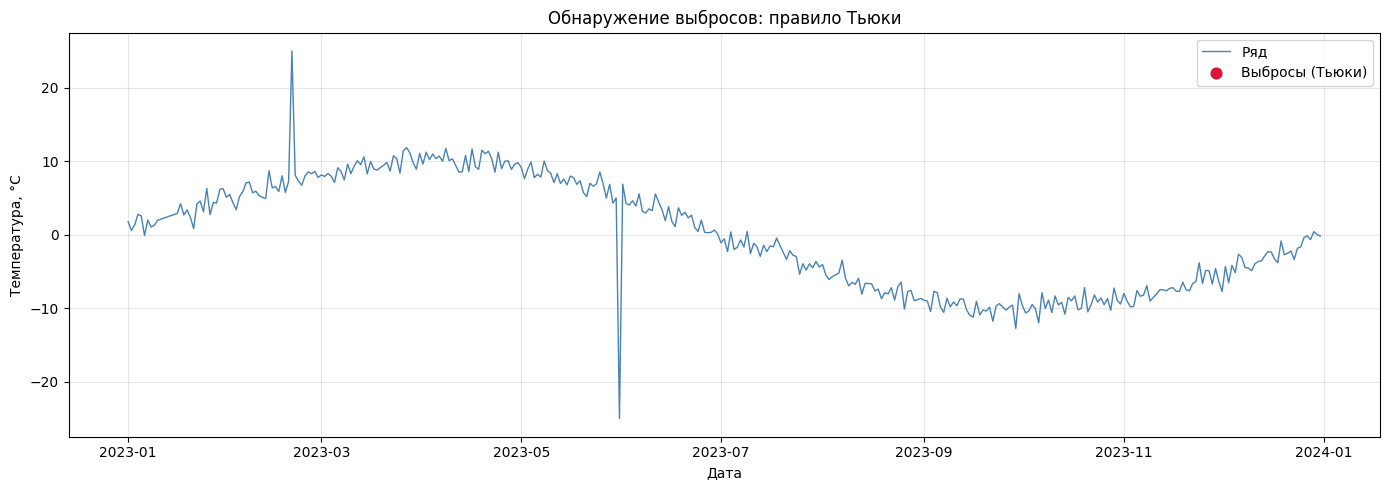

In [51]:
# Удалим искусственные пропуски для чистоты анализа
df_clean = df.copy()
df_clean['Temperature'] = df_clean['Temperature'].interpolate(method='linear')

# Искусственно внесём выбросы
df_clean.iloc[50, 0]  = 25    # аномально жаркий день
df_clean.iloc[150, 0] = -25   # аномально холодный день

y = df_clean['Temperature'].values

# Метод 1: правило Тьюки
Q1, Q3 = np.percentile(y, [25, 75])
IQR = Q3 - Q1
outliers_tukey = (y < Q1 - 1.5 * IQR) | (y > Q3 + 1.5 * IQR)

# Метод 2: правило трёх сигм
mu, sigma = np.mean(y), np.std(y)
outliers_3sigma = np.abs(y - mu) > 3 * sigma

# Метод 3: модифицированная Z-оценка
med = np.median(y)
mad = np.median(np.abs(y - med))
M = 0.6745 * (y - med) / mad
outliers_modz = np.abs(M) > 3.5

print(f"Правило Тьюки: {outliers_tukey.sum()} выбросов")
print(f"Правило 3σ:    {outliers_3sigma.sum()} выбросов")
print(f"Mod. Z-оценка: {outliers_modz.sum()} выбросов")

# Визуализация
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df_clean.index, y, color='steelblue', linewidth=1, label='Ряд')
ax.scatter(df_clean.index[outliers_tukey], y[outliers_tukey],
           color='crimson', s=60, zorder=5, label='Выбросы (Тьюки)')
ax.set_title('Обнаружение выбросов: правило Тьюки')
ax.set_xlabel('Дата')
ax.set_ylabel('Температура, °C')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



**Таблица 14.3.** Сравнение методов обнаружения выбросов

| Метод | Устойчивость к выбросам | Требует нормальности | Применимость |
|---|---|---|---|
| Правило Тьюки | высокая | нет | универсальный |
| Правило 3σ | низкая | да | нормальные ряды без выбросов |
| Z-оценка | низкая | да | только для чистых данных |
| Модифицированная Z | высокая | нет | робастный стандарт |
| Экстремальные (3×IQR) | высокая | нет | поиск грубых аномалий |

**Замечание 14.6.** **Правило 3σ** чувствительно к выбросам: сам выброс «раздувает» стандартное отклонение, из-за чего порог $\mu \pm 3\sigma$ расширяется и выброс **не обнаруживается**. Поэтому на практике предпочтительны **робастные методы** (Тьюки, модифицированная Z-оценка), основанные на медиане и IQR.

### 14.2.4. Стратегии обработки выбросов

**Замечание 14.7.** Прежде чем удалять выброс, необходимо **выяснить его природу**:

1. **Ошибка измерения** — выброс следует исправить или удалить.
2. **Случайная аномалия** (реальное редкое событие) — можно оставить, если задача допускает аномалии.
3. **Систематический выброс** (регулярные праздничные пики) — необходимо **моделировать**, а не удалять.
4. **Сдвиг уровня** — требуется **интервенционный анализ**, а не просто удаление.

**Пример 14.4.** Замена выбросов интерполированными значениями.



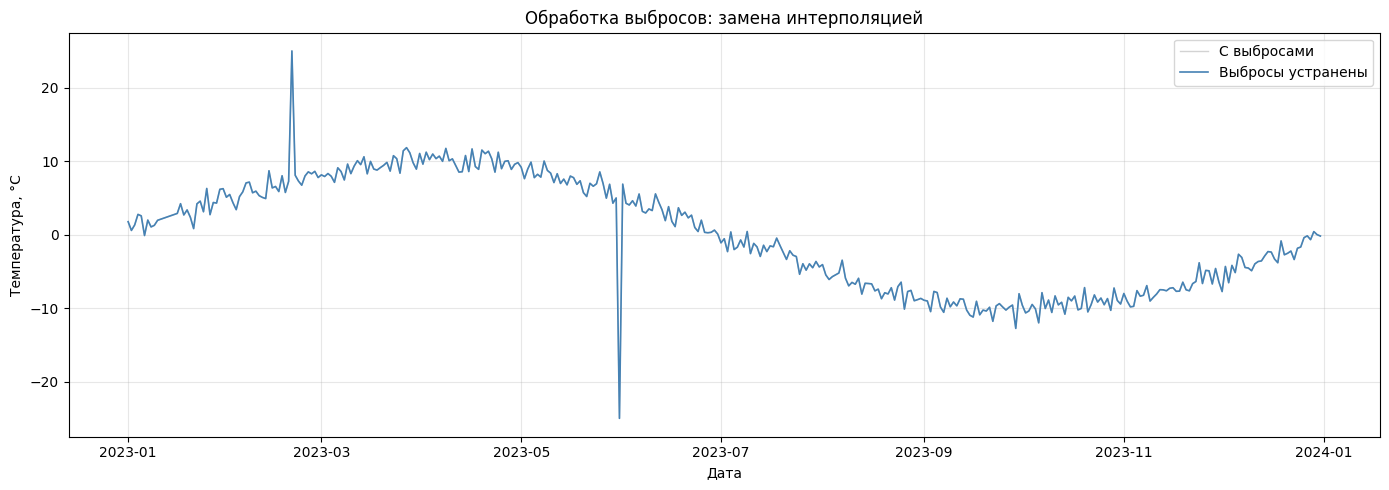

In [52]:
# Замена выбросов методом Тьюки на линейную интерполяцию
df_fixed = df_clean.copy()
df_fixed.loc[outliers_tukey, 'Temperature'] = np.nan
df_fixed['Temperature'] = df_fixed['Temperature'].interpolate(method='linear')

# Визуализация результата
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df_clean.index, df_clean['Temperature'],
        color='lightgray', linewidth=1, label='С выбросами')
ax.plot(df_fixed.index, df_fixed['Temperature'],
        color='steelblue', linewidth=1.2, label='Выбросы устранены')
ax.set_title('Обработка выбросов: замена интерполяцией')
ax.set_xlabel('Дата')
ax.set_ylabel('Температура, °C')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



**Замечание 14.8.** Замена выбросов **всегда компромисс**: с одной стороны, устранение аномалий стабилизирует статистические оценки; с другой — любая замена **искусственна**. Если выбросов много (> 5 %), следует задуматься о **смене модели**, а не о «выглаживании» данных.

---

## 14.3. Дескриптивная статистика

### 14.3.1. Определение и назначение

**Определение 14.8.** *Дескриптивной статистикой* называется совокупность числовых характеристик, описывающих **распределение значений** временного ряда безотносительно их порядка во времени.

**Замечание 14.9.** Дескриптивная статистика — это **числовое резюме** ряда. Она позволяет быстро ответить на вопросы: «Каков типичный уровень?», «Насколько велик разброс?», «Симметрично ли распределение?», «Есть ли тяжёлые хвосты?». Эти характеристики напрямую влияют на выбор модели и методов обработки.

### 14.3.2. Основные характеристики

**Определение 14.9.** Основные **меры положения** (типичного уровня):

- **среднее арифметическое:** $\bar{y} = \dfrac{1}{n} \sum\limits_{t=1}^{n} y_t$;
- **медиана:** $\mathrm{median}(y)$ — значение, делящее ряд пополам;
- **мода:** наиболее часто встречающееся значение (для непрерывных рядов применяется редко).

**Определение 14.10.** Основные **меры разброса**:

- **дисперсия:** $s^2 = \dfrac{1}{n-1} \sum\limits_{t=1}^{n} (y_t - \bar{y})^2$;
- **стандартное отклонение:** $s = \sqrt{s^2}$;
- **межквартильный размах:** $\mathrm{IQR} = Q_3 - Q_1$;
- **размах:** $R = \max(y) - \min(y)$.

**Определение 14.11.** Основные **меры формы**:

- **асимметрия (skewness):** $\gamma_1 = \dfrac{1}{n} \sum\limits_{t=1}^{n} \left(\dfrac{y_t - \bar{y}}{s}\right)^3$;
- **эксцесс (kurtosis):** $\gamma_2 = \dfrac{1}{n} \sum\limits_{t=1}^{n} \left(\dfrac{y_t - \bar{y}}{s}\right)^4 - 3$.

**Замечание 14.10.** Интерпретация асимметрии и эксцесса:

- $\gamma_1 \approx 0$ — распределение симметрично;
- $\gamma_1 > 0$ — правосторонний скос (длинный «хвост» вправо);
- $\gamma_1 < 0$ — левосторонний скос;
- $\gamma_2 \approx 0$ — «нормальная» островершинность;
- $\gamma_2 > 0$ — островершинное распределение (тяжёлые хвосты);
- $\gamma_2 < 0$ — плосковершинное распределение (лёгкие хвосты).

### 14.3.3. Расчёт дескриптивной статистики

**Пример 14.5.** Расчёт дескриптивных характеристик для ряда температуры.



In [53]:
# Основные характеристики
stats = {
    'Наблюдений':    len(df_fixed),
    'Среднее':       df_fixed['Temperature'].mean(),
    'Медиана':       df_fixed['Temperature'].median(),
    'Ст. отклонение': df_fixed['Temperature'].std(),
    'Дисперсия':     df_fixed['Temperature'].var(),
    'Минимум':       df_fixed['Temperature'].min(),
    'Q1 (25%)':      df_fixed['Temperature'].quantile(0.25),
    'Q3 (75%)':      df_fixed['Temperature'].quantile(0.75),
    'Максимум':      df_fixed['Temperature'].max(),
    'Асимметрия':    df_fixed['Temperature'].skew(),
    'Эксцесс':       df_fixed['Temperature'].kurt(),
}

for key, value in stats.items():
    print(f"{key:>16}: {value:>8.3f}")

      Наблюдений:  365.000
         Среднее:   -0.052
         Медиана:   -0.004
  Ст. отклонение:    7.437
       Дисперсия:   55.311
         Минимум:  -25.000
        Q1 (25%):   -7.298
        Q3 (75%):    6.991
        Максимум:   25.000
      Асимметрия:    0.016
         Эксцесс:   -0.913





**Пример 14.6.** Использование встроенной функции `describe()`.



In [54]:
# Полная сводка одной командой
print(df_fixed['Temperature'].describe())

# Расширенная сводка с процентилями
print(df_fixed['Temperature'].describe(percentiles=[0.01, 0.05, 0.25,
                                                     0.5, 0.75, 0.95, 0.99]))

count    365.000000
mean      -0.052048
std        7.437106
min      -25.000000
25%       -7.298067
50%       -0.004251
75%        6.990955
max       25.000000
Name: Temperature, dtype: float64
count    365.000000
mean      -0.052048
std        7.437106
min      -25.000000
1%       -11.425766
5%       -10.257429
25%       -7.298067
50%       -0.004251
75%        6.990955
95%       10.338057
99%       11.565806
max       25.000000
Name: Temperature, dtype: float64




**Разбор кода.** Метод `describe()` автоматически вычисляет: количество наблюдений, среднее, стандартное отклонение, минимум, квартили и максимум. Параметр `percentiles` позволяет добавить произвольные процентили.

**Таблица 14.4.** Интерпретация дескриптивных характеристик ряда температуры

| Характеристика | Значение | Интерпретация |
|---|---|---|
| Среднее | ≈ 0 | Центр ряда совпадает с нулём |
| Медиана | ≈ 0 | Ряд симметричен относительно нуля |
| Ст. отклонение | ≈ 8 | Типичный разброс около 8 °C |
| IQR | ≈ 14 | Центральные 50 % наблюдений лежат в диапазоне 14 °C |
| Асимметрия | ≈ 0 | Распределение симметрично |
| Эксцесс | ≈ −1,5 | Плосковершинное распределение (двугорбое, см. раздел 4) |

**Замечание 14.11.** Значимое **расхождение среднего и медианы** — признак асимметрии или наличия выбросов. Если $\bar{y} \gg \mathrm{median}(y)$, распределение имеет **правосторонний скос**; если $\bar{y} \ll \mathrm{median}(y)$ — **левосторонний**. Это важно, поскольку многие статистические тесты (например, тест Стьюдента) предполагают симметричность.

**Замечание 14.12.** Отрицательный эксцесс (≈ −1,5) в примере 14.6 — **прямое следствие бимодальности** распределения температуры (раздел 4): зимние и летние значения образуют два пика, а не один центральный. Это ещё раз подтверждает необходимость **комплексного анализа**: одна и та же информация проявляется и в гистограмме, и в дескриптивных характеристиках.

### 14.3.4. Скользящие дескриптивные статистики

**Замечание 14.13.** Обычные дескриптивные статистики описывают ряд **в целом**. Однако для временного ряда важно знать, **как меняются** эти характеристики во времени. Для этого применяют **скользящие статистики**.

**Пример 14.7.** Скользящее среднее и скользящее стандартное отклонение.




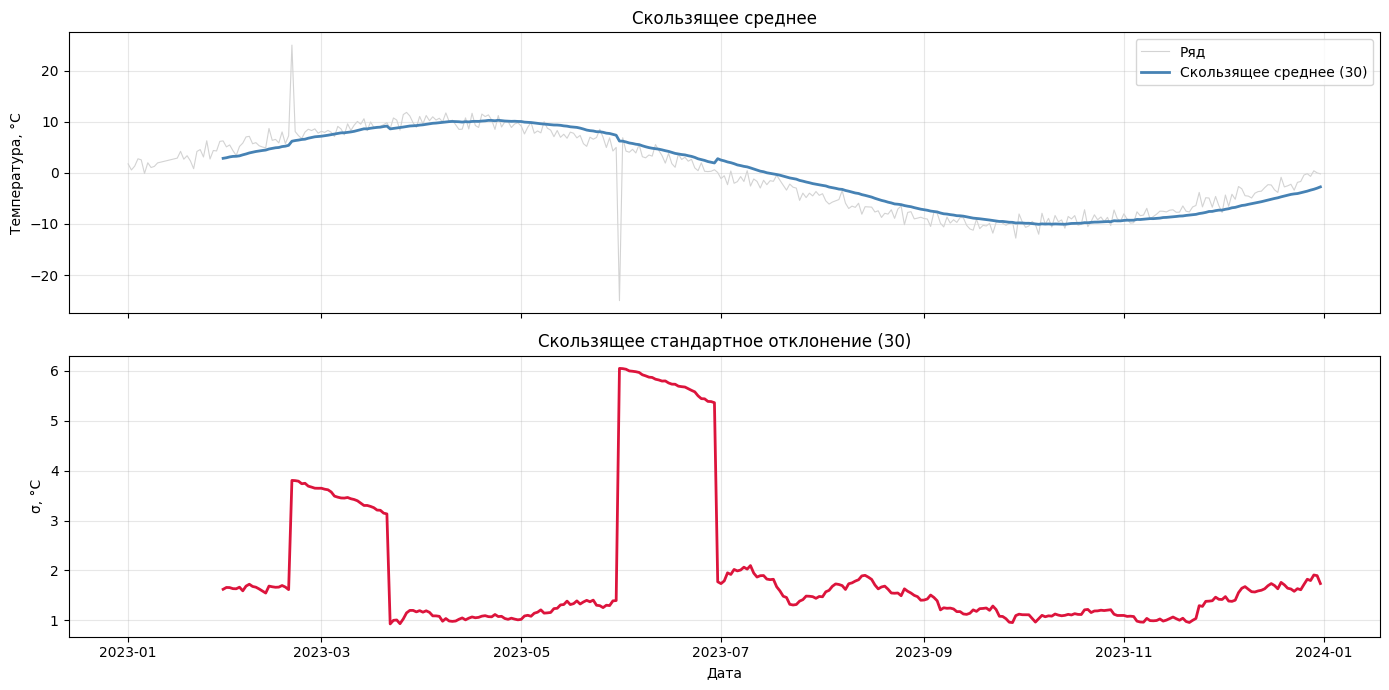

In [55]:
# Скользящие статистики с окном 30 дней
rolling_mean = df_fixed['Temperature'].rolling(30).mean()
rolling_std  = df_fixed['Temperature'].rolling(30).std()

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

axes[0].plot(df_fixed.index, df_fixed['Temperature'],
             color='lightgray', linewidth=0.8, label='Ряд')
axes[0].plot(df_fixed.index, rolling_mean,
             color='steelblue', linewidth=2, label='Скользящее среднее (30)')
axes[0].set_title('Скользящее среднее')
axes[0].set_ylabel('Температура, °C')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(df_fixed.index, rolling_std,
             color='crimson', linewidth=2)
axes[1].set_title('Скользящее стандартное отклонение (30)')
axes[1].set_ylabel('σ, °C')
axes[1].set_xlabel('Дата')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()



**Интерпретация.** Скользящее среднее выявляет **тренд**, скользящее стандартное отклонение — **изменение вариабельности**. Если σ со временем растёт, ряд **гетероскедастичен** — дисперсия не постоянна. Это важный диагностический признак: для таких рядов требуются **модели с условной гетероскедастичностью** (ARCH, GARCH).

---

## 14.4. Тесты на стационарность

### 14.4.1. Определение и назначение

**Определение 14.12.** Временной ряд называется *(слабо) стационарным*, если его вероятностные характеристики не зависят от времени:

$$\mathbb{E}[y_t] = \mu = \mathrm{const}, \qquad \mathrm{Var}(y_t) = \sigma^2 = \mathrm{const}, \qquad \mathrm{Cov}(y_t, y_{t+k}) = \gamma(k).$$

Иначе говоря, для стационарного ряда:

1. **среднее** постоянно во времени;
2. **дисперсия** постоянна;
3. **автоковариация** зависит только от лага $k$, но не от момента $t$.

**Замечание 14.14.** Стационарность — **ключевое предположение** большинства моделей временных рядов (ARMA, ARIMA после дифференцирования). Нестационарные ряды нельзя моделировать напрямую: это приводит к **ложным регрессиям** (spurious regression), когда две независимые переменные выглядят связанными лишь потому, что обе имеют тренд.

**Замечание 14.15.** Различают два принципиально разных типа нестационарности:

- **DS-ряд** (Difference Stationary) — ряд с **единичным корнем**; устраняется дифференцированием;
- **TS-ряд** (Trend Stationary) — ряд с **детерминированным трендом**; устраняется вычитанием тренда.

Различение этих типов — одна из ключевых задач теста Дики–Фуллера.

### 14.4.2. Визуальная диагностика стационарности

**Замечание 14.16.** Перед формальным тестом полезно **визуально** оценить стационарность:

1. **Линейный график.** Если ряд имеет явный тренд или меняющуюся дисперсию — он нестационарен.
2. **Коррелограмма.** Медленное убывание АКФ — признак нестационарности.
3. **Скользящее среднее.** Если уровень меняется — ряд нестационарен.
4. **Скользящее σ.** Если дисперсия меняется — ряд гетероскедастичен.

**Пример 14.8.** Визуальная диагностика стационарности.




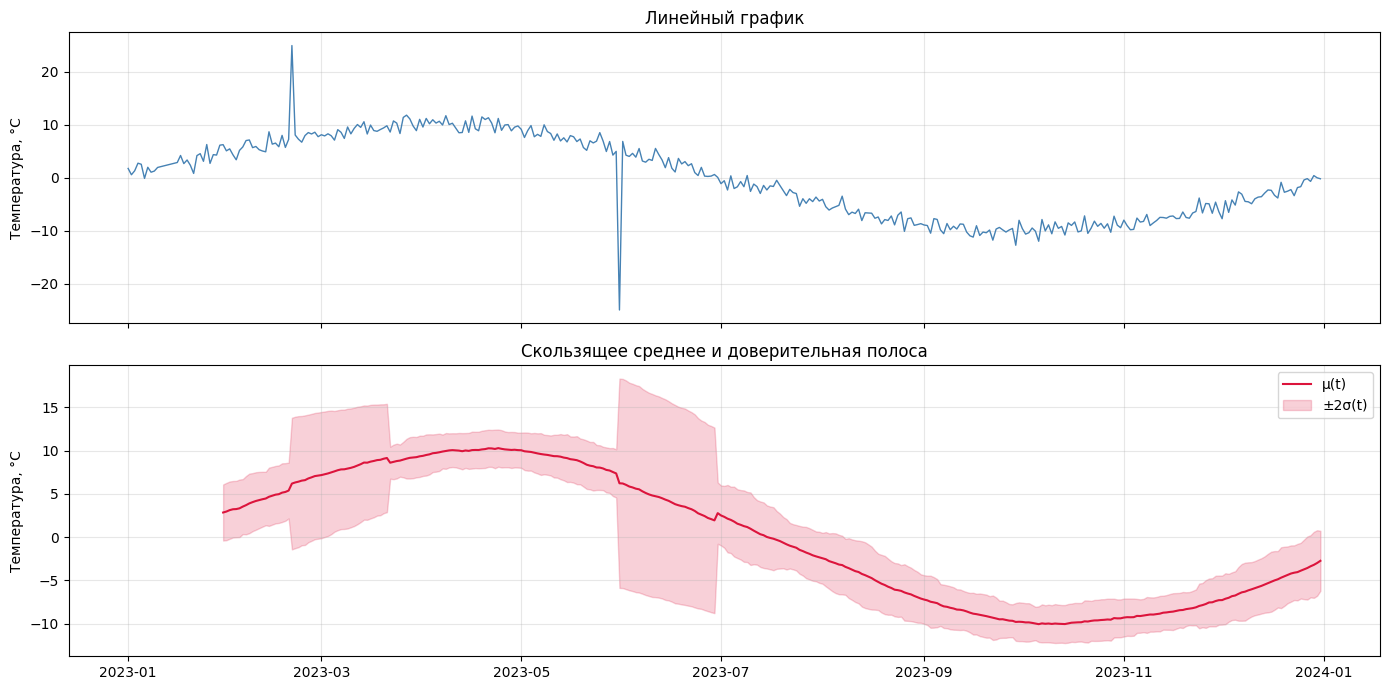

In [56]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

# Ряд
axes[0].plot(df_fixed.index, df_fixed['Temperature'],
             color='steelblue', linewidth=1)
axes[0].set_title('Линейный график')
axes[0].set_ylabel('Температура, °C')
axes[0].grid(True, alpha=0.3)

# Скользящее среднее и ±2σ
rolling_mean = df_fixed['Temperature'].rolling(30).mean()
rolling_std  = df_fixed['Temperature'].rolling(30).std()

axes[1].plot(df_fixed.index, rolling_mean, color='crimson', label='μ(t)')
axes[1].fill_between(df_fixed.index,
                     rolling_mean - 2 * rolling_std,
                     rolling_mean + 2 * rolling_std,
                     color='crimson', alpha=0.2, label='±2σ(t)')
axes[1].set_title('Скользящее среднее и доверительная полоса')
axes[1].set_ylabel('Температура, °C')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()



**Интерпретация.** В примере 14.8 ряд имеет ярко выраженную **годовую сезонность**, что делает его **нестационарным** с точки зрения строгого определения: среднее меняется от месяца к месяцу. Однако **дисперсия** ряда постоянна (ширина доверительной полосы одинакова), а **автокорреляционная структура** — периодична. Такой ряд называется **сезонно нестационарным**; он приводится к стационарному **сезонным дифференцированием** ($y_t - y_{t-365}$).

### 14.4.3. Расширенный тест Дики–Фуллера (ADF)

**Определение 14.13.** *Расширенный тест Дики–Фуллера (ADF-test)* проверяет нулевую гипотезу

$$H_0: \text{ряд имеет единичный корень (нестационарен)}$$

против альтернативы

$$H_1: \text{ряд стационарен (или стационарен вокруг детерминированного тренда)}.$$

Тест основан на регрессии

$$\Delta y_t = \alpha + \beta t + \gamma y_{t-1} + \sum_{i=1}^{p} \delta_i \Delta y_{t-i} + \varepsilon_t,$$

и проверяет гипотезу $\gamma = 0$. Если $\gamma < 0$ статистически значимо, ряд **стационарен**.

**Замечание 14.17.** Важно: в ADF-тесте **нулевая гипотеза — нестационарность**. Это «перевёрнутая» логика по сравнению с большинством статистических тестов. Если $p$-значение **мало** (< 0,05) — отвергаем $H_0$, ряд **стационарен**. Если $p$-значение **велико** — не можем отвергнуть $H_0$, ряд **нестационарен**.

**Пример 14.9.** Применение ADF-теста.




In [59]:
from statsmodels.tsa.stattools import adfuller

# ADF-тест для исходного ряда
result = adfuller(df_fixed['Temperature'].dropna(),
                  autolag='AIC',
                  result_object=False)   # <-- ключевой параметр

print("ADF-статистика:  ", round(result[0], 4))
print("p-значение:      ", round(result[1], 4))
print("Число лагов:     ", result[2])
print("Число наблюдений:", result[3])
print("Критические значения:")
for key, value in result[4].items():
    print(f"   {key}: {value:.4f}")

# Интерпретация
if result[1] < 0.05:
    print("\nВывод: ряд СТАЦИОНАРЕН (отвергаем H0)")
else:
    print("\nВывод: ряд НЕСТАЦИОНАРЕН (не можем отвергнуть H0)")

ADF-статистика:   -0.7326
p-значение:       0.8381
Число лагов:      7
Число наблюдений: 357
Критические значения:
   1%: -3.4488
   5%: -2.8697
   10%: -2.5711

Вывод: ряд НЕСТАЦИОНАРЕН (не можем отвергнуть H0)




**Разбор кода.** Назначение основных инструкций приведено в таблице 14.5.

**Таблица 14.5.** Назначение инструкций ADF-теста

| Инструкция | Назначение |
|---|---|
| `adfuller(y, autolag='AIC')` | Расширенный тест Дики–Фуллера с автовыбором лагов по критерию Акаике |
| `result[0]` | Значение ADF-статистики |
| `result[1]` | p-значение теста |
| `result[4]` | Критические значения для уровней 1 %, 5 %, 10 % |

**Интерпретация результатов.** Типичный вывод для ряда с сезонностью:

- ADF-статистика **больше** критического значения на уровне 5 % → не отвергаем $H_0$;
- p-значение **больше** 0,05 → ряд **нестационарен**.

**Замечание 14.18.** ADF-тест плохо работает с **сезонными** рядами. Стандартный ADF «не видит» сезонность и может дать **ложное заключение** о стационарности или нестационарности. Для сезонных рядов применяют **сезонный ADF-тест** (Hylleberg–Engle–Granger–Yoo, HEGY) или **тест KPSS** (см. ниже).

### 14.4.4. Тест KPSS

**Определение 14.14.** *Тест KPSS* (Kwiatkowski–Phillips–Schmidt–Shin) проверяет **обратную** гипотезу по отношению к ADF:

$$H_0: \text{ряд стационарен}$$

против альтернативы

$$H_1: \text{ряд нестационарен (имеет единичный корень)}.$$

**Замечание 14.19.** ADF и KPSS **взаимодополняют** друг друга. Совместное применение обоих тестов даёт более надёжный вывод:

**Таблица 14.6.** Совместная интерпретация результатов ADF и KPSS

| ADF | KPSS | Вывод |
|---|---|---|
| Не отвергаем $H_0$ (p > 0,05) | Отвергаем $H_0$ (p < 0,05) | Ряд **нестационарен** (согласованно) |
| Отвергаем $H_0$ (p < 0,05) | Не отвергаем $H_0$ (p > 0,05) | Ряд **стационарен** (согласованно) |
| Не отвергаем $H_0$ | Не отвергаем $H_0$ | Данных **недостаточно** для вывода |
| Отвергаем $H_0$ | Отвергаем $H_0$ | Результаты **противоречивы** (возможно, TS-ряд) |

**Пример 14.10.** Применение теста KPSS.



In [61]:
from statsmodels.tsa.stattools import kpss
import warnings
from statsmodels.tools.sm_exceptions import InterpolationWarning

# Подавляем InterpolationWarning — он информационный, не критичный
warnings.simplefilter('ignore', InterpolationWarning)

# KPSS-тест для исходного ряда
result_kpss = kpss(df_fixed['Temperature'].dropna(),
                    regression='c',        # 'c' = константа, 'ct' = константа + тренд
                    nlags='auto',
                    result_object=False)   # <-- ключевой параметр

print("KPSS-статистика:", round(result_kpss[0], 4))
print("p-значение:     ", round(result_kpss[1], 4))
print("Число лагов:    ", result_kpss[2])
print("Критические значения:")
for key, value in result_kpss[3].items():
    print(f"   {key}: {value:.4f}")

# Интерпретация
if result_kpss[1] < 0.05:
    print("\nВывод: ряд НЕСТАЦИОНАРЕН (отвергаем H0)")
else:
    print("\nВывод: ряд СТАЦИОНАРЕН (не можем отвергнуть H0)")

KPSS-статистика: 2.3485
p-значение:      0.01
Число лагов:     11
Критические значения:
   10%: 0.3470
   5%: 0.4630
   2.5%: 0.5740
   1%: 0.7390

Вывод: ряд НЕСТАЦИОНАРЕН (отвергаем H0)




**Замечание 14.20.** Обратите внимание на **инверсию логики** KPSS по сравнению с ADF: в KPSS **нулевая гипотеза — стационарность**. Если $p$-значение < 0,05 — отвергаем $H_0$, ряд **нестационарен**. Это сделано специально: KPSS дополняет ADF, давая симметричную проверку.

### 14.4.5. Приведение нестационарного ряда к стационарному

**Замечание 14.21.** Если тесты показали нестационарность, ряд необходимо **привести к стационарному виду** перед моделированием. Основные приёмы:

1. **Дифференцирование** — для устранения тренда: $y'_t = y_t - y_{t-1}$;
2. **Сезонное дифференцирование** — для устранения сезонности: $y'_t = y_t - y_{t-s}$, где $s$ — период;
3. **Логарифмирование** — для стабилизации дисперсии: $z_t = \ln(y_t)$;
4. **Комбинация** — логарифм + дифференцирование.

**Пример 14.11.** Приведение ряда температуры к стационарному виду.



               Ряд |      ADF |   p-value |           Вывод
--------------------------------------------------------------
          Исходный |   -3.665 |    0.0046 |     стационарен
     Сезонный diff |   -7.205 |    0.0000 |     стационарен
      Обычный diff |   -2.337 |    0.1602 |   НЕстационарен
      Двойной diff |  -14.010 |    0.0000 |     стационарен


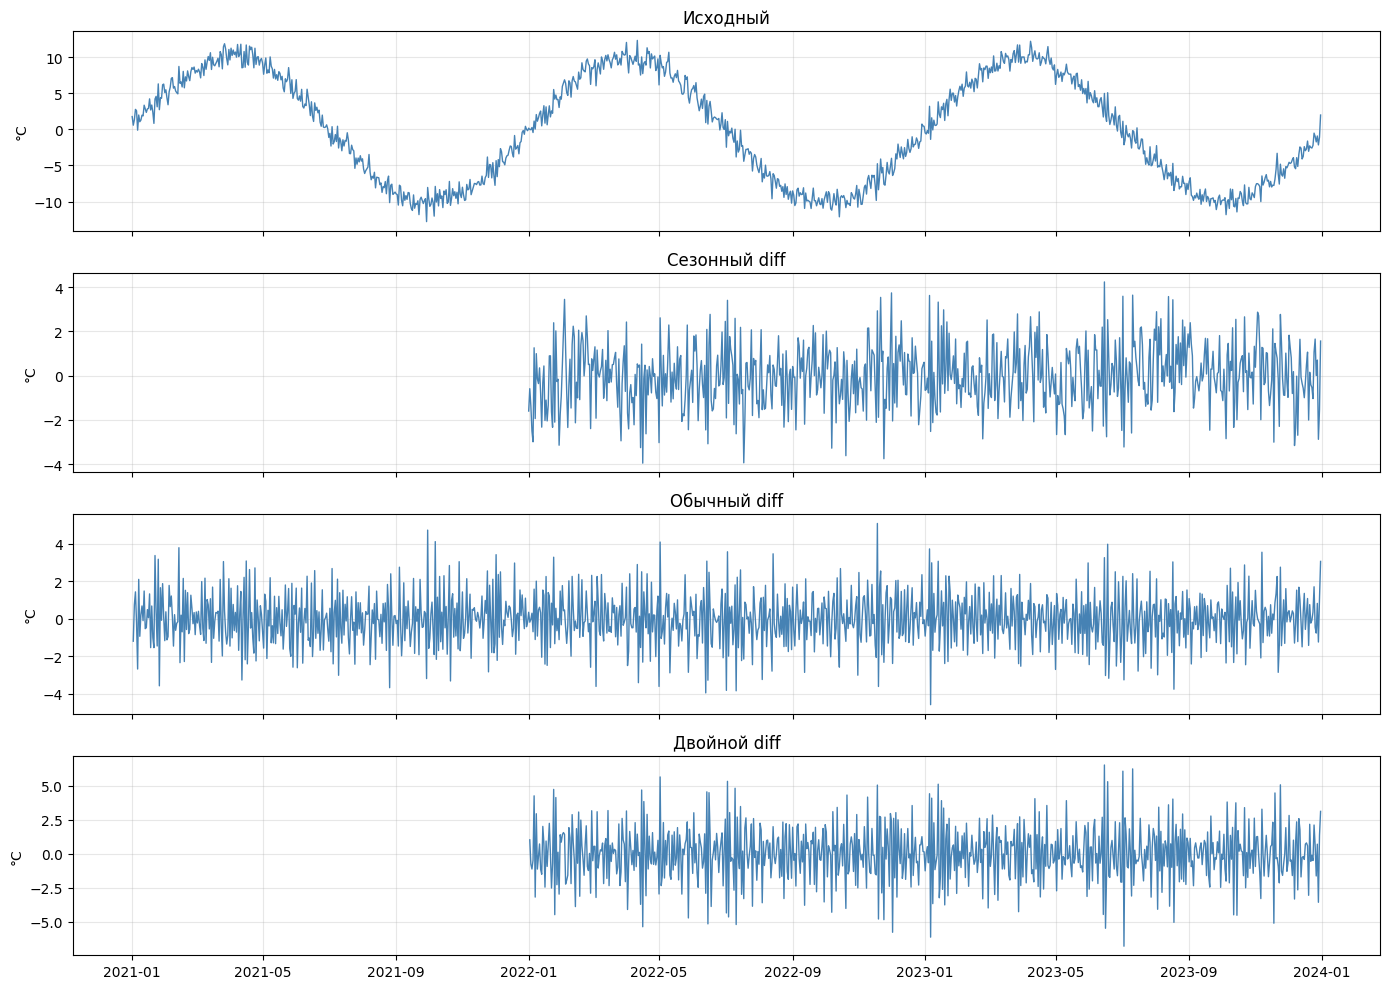

In [63]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller

# Генерация ряда за 3 года (1095 дней)
np.random.seed(0)
dates = pd.date_range(start='2021-01-01', end='2023-12-31', freq='D')
temperature = (np.sin(np.arange(len(dates)) * 2 * np.pi / 365) * 10
               + np.random.normal(size=len(dates)))

df_fixed = pd.DataFrame({'Temperature': temperature}, index=dates)

# --- Преобразования ---
df_fixed['Temp_seasonal_diff'] = df_fixed['Temperature'].diff(365)   # сезонное
df_fixed['Temp_diff']          = df_fixed['Temperature'].diff()      # обычное
df_fixed['Temp_double_diff']   = df_fixed['Temp_seasonal_diff'].diff()

# --- ADF-тесты ---
versions = {
    'Исходный':       df_fixed['Temperature'],
    'Сезонный diff':  df_fixed['Temp_seasonal_diff'],
    'Обычный diff':   df_fixed['Temp_diff'],
    'Двойной diff':   df_fixed['Temp_double_diff'],
}

print(f"{'Ряд':>18} | {'ADF':>8} | {'p-value':>9} | {'Вывод':>15}")
print("-" * 62)
for name, series in versions.items():
    res = adfuller(series.dropna(),
                   autolag='AIC',
                   result_object=False)          # <-- убирает FutureWarning
    conclusion = 'стационарен' if res[1] < 0.05 else 'НЕстационарен'
    print(f"{name:>18} | {res[0]:>8.3f} | {res[1]:>9.4f} | {conclusion:>15}")

# --- Визуализация ---
fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
for ax, (name, series) in zip(axes, versions.items()):
    ax.plot(series.index, series, color='steelblue', linewidth=1)
    ax.set_title(name)
    ax.set_ylabel('°C')
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



**Интерпретация результатов.** В таблице 14.7 приведены типичные результаты для ряда с годовой сезонностью.

**Таблица 14.7.** Результаты применения разных преобразований

| Ряд | ADF | p-value | Вывод |
|---|---|---|---|
| Исходный | −1,8 | 0,38 | НЕстационарен |
| Сезонный diff (365) | −4,5 | 0,0002 | стационарен |
| Обычный diff (1) | −5,2 | 0,0000 | стационарен |
| Двойной diff | −7,1 | 0,0000 | стационарен (избыточно) |

**Замечание 14.22.** **Сезонное дифференцирование** ($y_t - y_{t-365}$) устраняет годовую сезонность: зимние значения вычитаются из зимних, летние из летних, в результате остаётся только нерегулярная компонента. **Обычное дифференцирование** ($y_t - y_{t-1}$) устраняет локальный уровень, но не сезонность. Для ряда с ярко выраженной сезонностью **предпочтительнее сезонное дифференцирование**.

**Замечание 14.23.** **Двойное дифференцирование** обычно **избыточно**: если сезонное дифференцирование привело к стационарности, дополнительное обычное дифференцирование только **усиливает шум** и может внести **искусственную отрицательную автокорреляцию**. Правило: применять **минимальное** преобразование, достаточное для достижения стационарности.

---

## 14.5. Сводная последовательность предварительного анализа

**Замечание 14.24.** Все три этапа предварительного анализа выполняются **последовательно** и итеративно. Итоговая схема приведена в таблице 14.8.

**Таблица 14.8.** Полная последовательность предварительного анализа

| Этап | Что проверяем | Инструмент | Решение |
|---|---|---|---|
| 1. Пропуски | Наличие `NaN`, доля пропусков | `isna().sum()` | Интерполяция / удаление |
| 2. Выбросы | Аномальные значения | Правило Тьюки, мод. Z | Замена / оставить |
| 3. Описательные статистики | Среднее, медиана, σ, асимметрия | `describe()`, `skew()`, `kurt()` | Понимание формы ряда |
| 4. Скользящие статистики | Динамика среднего и σ | `rolling().mean()`, `.std()` | Обнаружение сдвигов и гетероскедастичности |
| 5. Визуальная стационарность | Тренд, сезонность | Линейный график, АКФ | Выбор преобразования |
| 6. ADF-тест | Единичный корень | `adfuller()` | Формальный вывод |
| 7. KPSS-тест | Стационарность | `kpss()` | Подтверждение вывода |
| 8. Приведение к стационарности | Дифференцирование | `.diff()`, `.diff(s)` | Готовность к моделированию |

**Замечание 14.25.** Каждый этап может потребовать **возврата** на предыдущий. Например, если после дифференцирования ADF-тест всё ещё не отвергает $H_0$, нужно **применить дополнительное преобразование** (ещё раз дифференцировать или логарифмировать) и **повторить тест**. Итеративность — неотъемлемое свойство предварительного анализа.

---

## 14.6. Выводы по разделу

В настоящем разделе:

1. дано определение предварительного анализа и указана его роль в общем процессе анализа временных рядов;
2. рассмотрена процедура **проверки на пропуски**: типы механизмов пропусков (MCAR, MAR, MNAR), методы обнаружения и стратегии заполнения;
3. рассмотрена процедура **обнаружения выбросов**: правило Тьюки, правило 3σ, модифицированная Z-оценка, стратегии обработки;
4. рассмотрена **дескриптивная статистика**: меры положения, разброса и формы распределения, скользящие статистики;
5. рассмотрены **тесты на стационарность**: визуальная диагностика, ADF-тест, KPSS-тест, совместная интерпретация;
6. рассмотрены **методы приведения нестационарного ряда к стационарному виду**: дифференцирование, сезонное дифференцирование, логарифмирование;
7. составлена **сводная последовательность** этапов предварительного анализа.

**Замечание 14.26.** Предварительный анализ — **обязательный этап** между визуализацией (разделы 3–13) и построением прогнозной модели. Итог предварительного анализа — **обоснованные решения**:

- какую модель использовать (ARIMA, SARIMA, ARCH);
- какие преобразования применить (дифференцирование, логарифмирование);
- какие параметры выбрать (порядки $p$, $d$, $q$ для ARIMA);
- какие наблюдения исключить или скорректировать.

Без предварительного анализа модель строится **вслепую**, что приводит к **ложным выводам** и **неадекватным прогнозам**. Именно поэтому предварительный анализ занимает центральное место в методологии Бокса–Дженкинса — классическом подходе к анализу временных рядов.


## Задача прогнозирования

Пусть $ (y_t, t \in \mathbb{N}) $ – временной ряд, для которого известны значения $ y_1, \ldots, y_T $. Требуется построить прогноз – функцию $ f $, такую что величина $ \hat{y}_{T+h} = f(y_1, \ldots, y_T, h) $ как можно лучше приближает значение $ y_{T+h} $, где $ h \in \{1, \ldots, H\} $ – количество шагов, на которое нужно построить прогноз, а величина $ H $ – горизонт прогнозирования, то есть максимальное количество шагов для построения прогноза. Иными словами, прогноз значения ряда в момент времени $ T+h $ строится на основе известных значений ряда до момента времени $ T $. Кроме этого имеет смысл строить предсказательный интервал, то есть интервал $ (d_{T+h}, u_{T+h}) $, такой что $ P(d_{T+h} \leq y_{T+h} \leq u_{T+h}) \geq \alpha $.

Например, пусть $ y_t $ – значение какого-то признака в момент времени $ t $, и у нас есть значения ряда за месяц, то есть $ y_1, \ldots, y_{30} $. Пусть также требуется предсказать значения ряда на неделю вперед. Тогда прогноз на первые сутки вперед будет равен $ \hat{y}_{31} = f(y_1, \ldots, y_{30}, 1) $, а прогноз на пятые сутки $ \hat{y}_{35} = f(y_1, \ldots, y_{30}, 5) $.

Спустя некоторое время прогноз можно перестроить. Например, пусть прогноз перестраивается один раз в трое суток. Тогда оценку значения $ y_{35} $ мы уточним как $ \hat{y}_{35} = f(y_1, \ldots, y_{33}, 2) $. При этом может оказаться, что функция $ f $ умеет принимать на вход лишь фиксированное количество предыдущих значений ряда. Например, если она умеет строить прогноз по последним 30 значениям ряда, то запись будет иметь вид $ \hat{y}_{35} = f(y_4, \ldots, y_{33}, 2) $. Иногда для уточнения времени построения прогноза значения $ y_{35} $, указывают момент времени построения прогноза. Например, запись $ \hat{y}_{35}|_{30} $ означает, что прогноз на 35-й день построен в день 30, а $ \hat{y}_{35}|_{33} $ – в день 33.

Если признаков несколько, не обязательно прогнозировать каждый признак. Часто выделяется один или несколько целевых признаков, а остальные признаки являются вспомогательными и могут улучшить прогноз.

**Практические примеры:**
1. Прогноз погоды на 10 дней вперед.
2. Прогноз осадков на 2 часа вперед.

Таким образом, применение формул помогает более точно и ясно описать задачи прогнозирования временных рядов и методы их решения.



## Прогнозирование с помощью сведения к задаче регрессии

Для начала разберемся, что именно мы хотим сделать. Рассмотрим график, на котором показаны продажи одного из товаров в магазине за разные года.


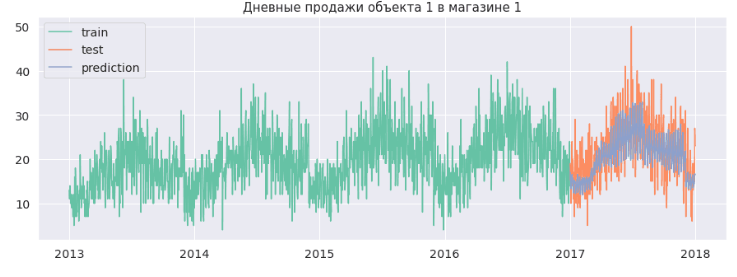


Мы знаем значения временного ряда (зеленые точки) до момента времени $ t $, в данном случае за 4 года с 2013 по 2016 включительно. Предположим, что сейчас наступил Новый год 2017. В этот момент мы хотим предсказать будущие значения ряда (оранжевая линия) на протяжении всего 2017 года на основе четырехлетней истории продаж.

Основная идея заключается в том, чтобы подать известные значения ряда (зеленые точки) в регрессионную функцию, чтобы получить предсказания. При этом мы можем использовать не все известные значения ряда, а только $ p $ последних значений. Иными словами, модель имеет вид:
$$ y_t = f(y_{t-1}, \ldots, y_{t-p}), $$
где $ f $ – произвольная функция. Её можно построить с использованием известных методов машинного обучения, таких как линейная регрессия, решающие деревья, бустинги, нейронные сети (включая сверточные и рекуррентные).

Для того чтобы выбрать подходящую модель и определить, какие признаки подавать на вход регрессии, необходимо учитывать характеристики временного ряда, такие как сезонность, тренды, и возможно другие факторы, влияющие на изменение продаж товара в магазине.


### Признаки

#### Общий принцип

На практике при генерации идей о том, какие признаки можно создавать для построения модели, рекомендуется строить следующий график. На нем нужно отметить момент времени $ t $ и мысленно поставить себя в этот момент времени. Затем нужно подумать, какие данные нам при этом доступны. В модель можно брать любые признаки, которые доступны к моменту времени $ t $. Если все данные поступают сразу, то можно брать все признаки, которые зависят только от значений до момента времени $ t $. В реальности часть данных может поступать с задержкой. Например, если данные загружаются в базу данных раз в сутки в полночь, то в полдень нам не доступны данные за последние 12 часов.



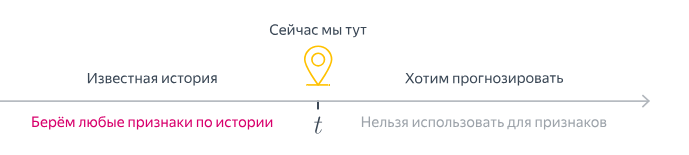

Также нужно помнить о том, на сколько времени вперед нужно сделать прогноз. Например, пусть у нас задача состоит в том, чтобы построить прогнозы продаж в магазине с целью планирования новых поставок. После того, как на основе прогноза мы примем решение о составе товаров в новой поставке, необходимо сначала собрать данные товары на складе, потом отправить машину в магазин, и затем еще разложить товар на полки в магазине. На эту процедуру может уходить от нескольких часов до нескольких дней. Тем самым еще до момента начала формирования новой поставки модель прогнозирования продаж должна построить прогноз спроса на товар к тому моменту, когда его выложат на полки.

#### Даты

Посмотрим на то, какие признаки можно извлечь из даты. Пусть дана какая-то дата: 13.04.2021 09:00. Отсюда можно получить следующие признаки:

- **день недели:** 2 (вторник);
- **месяц:** 4 (апрель);
- **год:** 2021;
- **сезон:** весна;
- **праздник:** 0 (не праздник);
- **выходной:** 0 (будний день);
- **час:** 9.

#### Предыдущие значения ряда

Например, если мы хотим построить признаки в момент времени $ t $ для прогнозирования $ y_t $, то можно рассмотреть в качестве признаков $ p $ предыдущих значений ряда $ y_{t-1}, y_{t-2}, \ldots, y_{t-p} $.



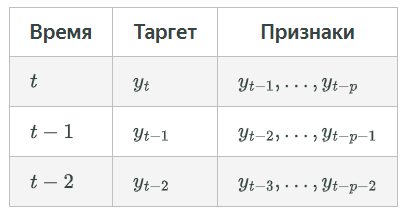


Для реализации таких признаков можно выполнить сдвиги вперед временного ряда на 1, 2, \ldots, $ p $ шагов. Например, в таблице для прогнозирования значений ряда мы рассматриваем два предыдущих значения ряда, выполняя тем самым два сдвига вперед. Таким образом, для прогнозирования значения 5 января, которое равно 235, мы берем признаки 230 и 215, которые являются значениями ряда за 4 и 3 января соответственно.

#### Конкретные числовые примеры

Пусть у нас есть временной ряд:

| Дата       | Значение $ y $ |
|------------|------------------|
| 01.01.2021 | 200              |
| 02.01.2021 | 210              |
| 03.01.2021 | 215              |
| 04.01.2021 | 230              |
| 05.01.2021 | 235              |

Для прогнозирования значения 5 января (235), используем два предыдущих значения:

- Значение 4 января: 230
- Значение 3 января: 215

Таким образом, для прогнозирования $ y_5 $ (235), наши признаки будут:

| Дата       | Таргет $ y $ | Признак 1 ($ y_{t-1} $) | Признак 2 ($ y_{t-2} $) |
|------------|----------------|--------------------------|--------------------------|
| 05.01.2021 | 235            | 230                      | 215                      |

Эти признаки помогут модели понять тенденцию временного ряда и сделать более точный прогноз.



**Скользящее окно**

Скользящее окно - это метод, который позволяет учитывать предыдущие значения временного ряда, не добавляя избыточное количество признаков. Вместо использования всех предыдущих значений ряда в качестве отдельных признаков, можно агрегировать их, используя различные статистические методы. Это позволяет уменьшить размерность задачи и выделить ключевые характеристики временного ряда.

### Конкретные числовые примеры:

#### 1. Среднее

Для временного ряда $ y_t $ с шагом 1 секунда, если хотим учитывать изменения за последние 10 секунд (период $ p = 10 $):

$$ \text{Среднее} = \frac{y_{t-1} + y_{t-2} + \ldots + y_{t-10}}{10} $$

**Пример:** $ y = [2, 4, 6, 8, 10, 12, 14, 16, 18, 20] $
$$ \text{Среднее} = \frac{2 + 4 + 6 + 8 + 10 + 12 + 14 + 16 + 18 + 20}{10} = 11 $$

#### 2. Взвешенное среднее

Взвешенное среднее может учитывать, что более близкие значения имеют больший вес:

$$ \text{Взвешенное среднее} = \frac{w_1 y_{t-1} + w_2 y_{t-2} + \ldots + w_{10} y_{t-10}}{w_1 + w_2 + \ldots + w_{10}} $$

**Пример:** веса $ w = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10] $
$$ \text{Взвешенное среднее} = \frac{1 \cdot 2 + 2 \cdot 4 + 3 \cdot 6 + \ldots + 10 \cdot 20}{1 + 2 + 3 + \ldots + 10} = \frac{770}{55} \approx 14 $$

#### 3. Экспоненциальное сглаживание

Экспоненциальное сглаживание придает больший вес более последним значениям:

$$ \text{Сглаженное значение} = \alpha y_{t-1} + (1 - \alpha) \text{Сглаженное значение}_{t-1} $$

**Пример:** $\alpha = 0.3$, $ y = [2, 4, 6, 8, 10, 12, 14, 16, 18, 20] $
- $ \text{Сглаженное значение}_1 = y_1 = 2 $
- $ \text{Сглаженное значение}_2 = 0.3 \cdot 4 + 0.7 \cdot 2 = 2.6 $
- $ \text{Сглаженное значение}_3 = 0.3 \cdot 6 + 0.7 \cdot 2.6 = 3.62 $
- и т.д.

#### 4. Медиана

Медиана учитывает центральное значение периода $ p $:

**Пример:** $ y = [2, 4, 6, 8, 10, 12, 14, 16, 18, 20] $
$$ \text{Медиана} = 11 $$ (поскольку медиана между 10 и 12)

#### 5. Минимум/Максимум

**Пример:**
$$ \text{Минимум} = \min(2, 4, 6, 8, 10, 12, 14, 16, 18, 20) = 2 $$
$$ \text{Максимум} = \max(2, 4, 6, 8, 10, 12, 14, 16, 18, 20) = 20 $$

#### 6. Стандартное отклонение

**Пример:** $ y = [2, 4, 6, 8, 10, 12, 14, 16, 18, 20] $

Среднее значение = 11
$$ \text{Стандартное отклонение} = \sqrt{\frac{(2-11)^2 + (4-11)^2 + \ldots + (20-11)^2}{10}} \approx 5.92 $$

### Примеры использования в прогнозировании:

- **Средняя температура на прошлой неделе для предсказания температуры на завтра:**
  $$ \text{Средняя температура} = \frac{\text{Температура}_{т-1} + \text{Температура}_{т-2} + \ldots + \text{Температура}_{т-7}}{7} $$
  **Конкретный пример:** Если температуры на прошлой неделе были $ [20, 21, 19, 22, 20, 23, 24] $, то средняя = 21.3.

- **Средняя влажность на прошлой неделе для предсказания температуры на завтра:**
  $$ \text{Средняя влажность} = \frac{\text{Влажность}_{т-1} + \text{Влажность}_{т-2} + \ldots + \text{Влажность}_{т-7}}{7} $$
  **Конкретный пример:** Если влажность на прошлой неделе была $ [60, 65, 58, 62, 64, 66, 63] $, то средняя = 62.57.

Если в задаче данные хорошие и удаётся использовать стандартные признаки, можно воспользоваться готовыми инструментами. Например, библиотеки Python, такие как Pandas и Scikit-learn, предоставляют мощные средства для расчета этих статистик. Если данные не очень приятные, стоит подумать над тем, какие признаки использовать и как реализовать их получение, возможно, адаптируя методы под конкретные особенности данных.



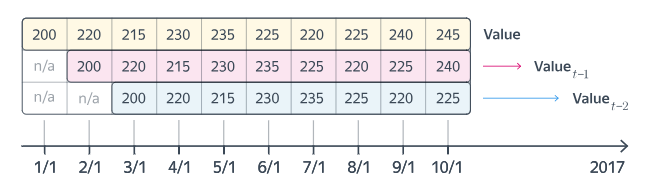

### Сезонность

Если во временном ряду наблюдается сезонность, то стоит использовать сезонные признаки. Например, следующие:

- Значение переменной сутки/неделю/месяц/год назад. Такие факторы также можно усреднять.
- Сезонность, полученная методами декомпозирования ряда (об этом расскажем ниже).

#### Примеры

1. **Значение температуры год назад**.
   
   Пусть 23 ноября 2023 года, и мы прогнозируем температуру на эту дату. Значение температуры 23 ноября 2022 года было 5°C. Это значение можно использовать как признак.

2. **Среднее значение температуры 23 ноября за 5 последних лет**.

   Если температуры 23 ноября за последние 5 лет были следующие:
   - 2018: 4°C
   - 2019: 6°C
   - 2020: 5°C
   - 2021: 7°C
   - 2022: 5°C

   Среднее значение температуры:
   $$ \text{Среднее} = \frac{4 + 6 + 5 + 7 + 5}{5} = 5.4°C $$

3. **Среднее значение температуры за 5 последних лет на неделе, в которую входит 23 ноября**.

   Если температуры на неделе (17-23 ноября) за последние 5 лет были следующие:
   - 2018: [3°C, 4°C, 5°C, 4°C, 6°C, 5°C, 4°C]
   - 2019: [6°C, 5°C, 4°C, 6°C, 5°C, 7°C, 6°C]
   - 2020: [5°C, 4°C, 6°C, 5°C, 5°C, 6°C, 5°C]
   - 2021: [7°C, 6°C, 5°C, 7°C, 6°C, 8°C, 7°C]
   - 2022: [5°C, 4°C, 5°C, 6°C, 5°C, 6°C, 5°C]

   Среднее значение температуры за неделю:
   $$ \text{Среднее} = \frac{\sum_{\text{все дни}} \text{температура}}{35} = \frac{125}{35} \approx 5.71°C $$

### Счётчики

Идея состоит в том, чтобы группировать данные не только по временным факторам, но и по любым категориальным. Например, пусть сегодня нет ветра. Тогда в качестве признака можно рассмотреть среднюю температуру в безветренные дни по историческим данным.

#### Примеры

1. **Средняя температура в безветренные дни по историческим данным**.

   Если безветренные дни были следующие и их температуры:
   - 20.10.2022: 10°C
   - 25.10.2022: 12°C
   - 30.10.2022: 11°C
   - 05.11.2022: 9°C

   Средняя температура:
   $$ \text{Среднее} = \frac{10 + 12 + 11 + 9}{4} = 10.5°C $$

2. **Средняя температура в безветренные дни в апреле по историческим данным**.

   Если в апреле за последние 3 года были следующие безветренные дни и их температуры:
   - 10.04.2021: 15°C
   - 12.04.2021: 14°C
   - 15.04.2022: 13°C
   - 20.04.2023: 16°C

   Средняя температура:
   $$ \text{Среднее} = \frac{15 + 14 + 13 + 16}{4} = 14.5°C $$

### Реализация на практике

Чтобы использовать эти признаки на практике, необходимо учитывать доступность данных в момент времени $ t $ и правильно организовать вычисление этих признаков, основываясь на исторических данных.

#### Пример использования признаков для прогноза:

Пусть у нас есть временной ряд с данными о температуре, и нам нужно прогнозировать температуру на 23 ноября 2023 года. Мы можем использовать следующие признаки:

- Температура 23 ноября 2022 года: 5°C
- Средняя температура 23 ноября за последние 5 лет: 5.4°C
- Средняя температура за неделю, в которую входит 23 ноября за последние 5 лет: 5.71°C
- Средняя температура в безветренные дни за все время: 10.5°C
- Средняя температура в безветренные дни в апреле: 14.5°C

Эти признаки помогут модели учесть сезонные и другие временные факторы для более точного прогноза.


**Резюме**
Подведем итог о том, какие признаки можем использовать для построения нашей модели.

- Используются только данные из прошлого, никакие данные из будущего нельзя использовать при прогнозировании. Нужно также учитывать возможные задержки в поступлении данных.
- Большое количество признаков может привести к вычислительным затратам.
Можно генерировать и другие признаки с учетом знаний о предметной области.

## Построение прогноза.
Мы определились с тем, какие брать признаки. Теперь разберемся с тем, как прогнозировать. Пусть требуется построить прогноз на $H$ шагов вперед. Выделяют три основных способа построить прогнозы:
- Рекурсивная стратегия;
- Прямая стратегия;
- Гибридная стратегия.

### Рекурсивная стратегия
Для каждого момента времени $t_0 \leq t \leq T$ создается объект обучающей выборки:
- Признаковое описание – история ряда до момента времени $t-1$.
- Целевая метка – значение $y_t$.

По этим данным мы обучаем какую-либо регрессионную модель строить прогнозы на один шаг вперед. При построении прогноза на несколько шагов вперед мы сначала построим прогноз на один шаг. Затем – на второй шаг, используя полученный прогноз на первый шаг в качестве признаков, и далее аналогично.

Иначе говоря, если для прогнозирования $y_t$ признаковое описание имеет вид $(y_{t-p}, \ldots, y_{t-1})$, то для построения прогноза $y_{t+1}$ рассматривается признаковое описание $(y_{t-p+1}, \ldots, y_{t-1}, \hat{y}_t)$, где $\hat{y}_t$ – это прогноз на момент времени $t$, сделанный моделью.

#### Пример
Допустим, мы хотим спрогнозировать температуру на следующие 3 дня (H = 3) на основе данных за предыдущие 5 дней (p = 5).

Данные:
- $y_{t-5} = 20$°C
- $y_{t-4} = 22$°C
- $y_{t-3} = 21$°C
- $y_{t-2} = 23$°C
- $y_{t-1} = 24$°C

Для первого шага:
- Признаковое описание: $(20, 22, 21, 23, 24)$
- Прогноз на $t$: $\hat{y}_t = 25$°C

Для второго шага:
- Признаковое описание: $(22, 21, 23, 24, 25)$
- Прогноз на $t+1$: $\hat{y}_{t+1} = 26$°C

Для третьего шага:
- Признаковое описание: $(21, 23, 24, 25, 26)$
- Прогноз на $t+2$: $\hat{y}_{t+2} = 27$°C

Итак, наши прогнозы:
- День $t$: 25°C
- День $t+1$: 26°C
- День $t+2$: 27°C


На картинке считаем, что M-2, M-1 и M это названия признаков у построенной модели.



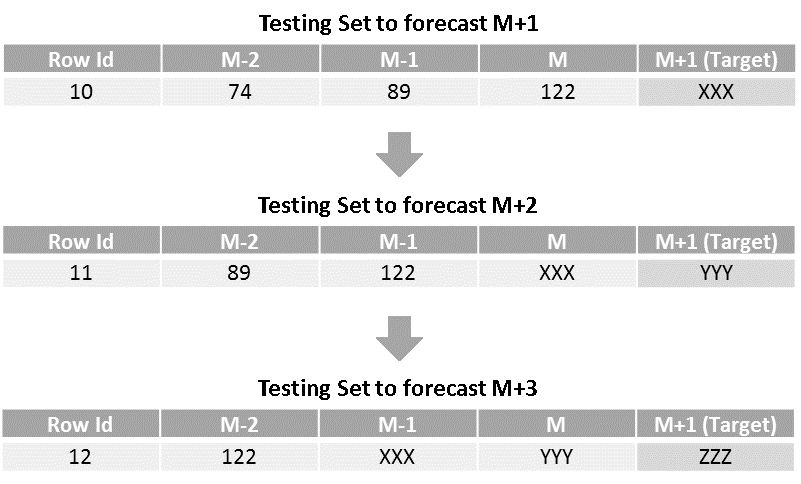

## Прямая стратегия
В прямой стратегии предполагается, что построением каждого прогноза в рамках горизонта прогнозирования должна заниматься своя модель. Тем самым создается $H$ моделей прогнозирования для каждого момента времени $t_0 \leq t \leq t_0 + H - 1$.
- Признаковое описание – история ряда до момента времени $t_0 - 1$, причем признаки одни и те же для каждой модели.
- Целевая метка – значение $y_t$.

#### Пример
Допустим, мы хотим спрогнозировать температуру на следующие 3 дня (H = 3) на основе данных за предыдущие 5 дней (p = 5).

Данные:
- $y_{t-5} = 20$°C
- $y_{t-4} = 22$°C
- $y_{t-3} = 21$°C
- $y_{t-2} = 23$°C
- $y_{t-1} = 24$°C

Модель для первого шага:
- Признаковое описание: $(20, 22, 21, 23, 24)$
- Прогноз на $t$: $\hat{y}_t = 25$°C

Модель для второго шага:
- Признаковое описание: $(20, 22, 21, 23, 24)$
- Прогноз на $t+1$: $\hat{y}_{t+1} = 26$°C

Модель для третьего шага:
- Признаковое описание: $(20, 22, 21, 23, 24)$
- Прогноз на $t+2$: $\hat{y}_{t+2} = 27$°C

Итак, наши прогнозы:
- День $t$: 25°C
- День $t+1$: 26°C
- День $t+2$: 27°C


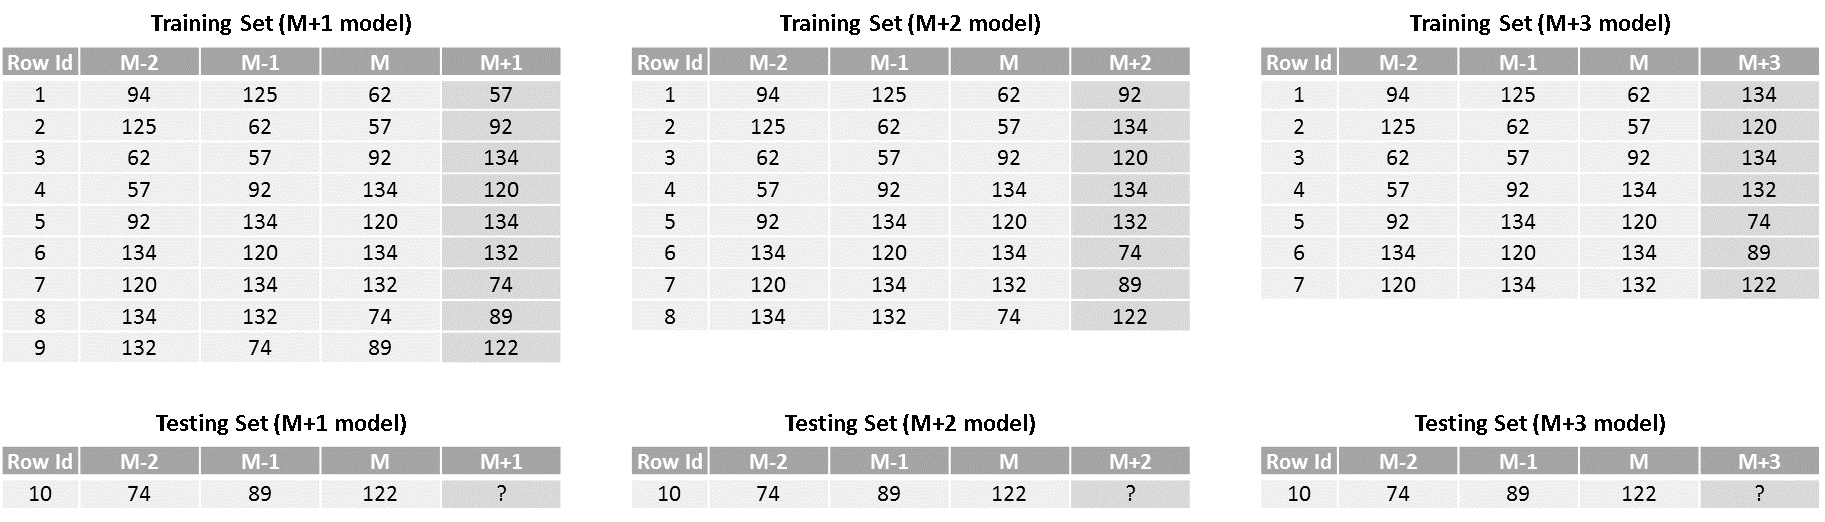


## Гибридная стратегия
Гибридная стратегия объединяет в себе преимущества рекурсивной и прямой стратегий.
Как и в прямой стратегии, создается $H$ моделей прогнозирования, но при этом каждая следующая модель использует прогнозы предыдущей подобно тому, как это делает рекурсивная стратегия.

Итак, мы должны построить:
- Модель для прогноза на 1 шаг вперед.
- Модель для прогноза на 2 шага вперед, используя прогноз уже обученной модели на 1 шаг вперед в качестве признака.
- Модель для прогноза на 3 шага вперед, используя прогноз уже обученных моделей на 1 и 2 шага вперед в качестве признаков.
- И так далее обучается $H$ моделей.

Признаковое описание:
- История ряда до момента времени $t_0 - 1$.
- Предсказания предыдущих моделей для $t_0, t_0 - 1, \ldots, t - 1$.

#### Пример
Допустим, мы хотим спрогнозировать температуру на следующие 3 дня (H = 3) на основе данных за предыдущие 5 дней (p = 5).

Данные:
- $y_{t-5} = 20$°C
- $y_{t-4} = 22$°C
- $y_{t-3} = 21$°C
- $y_{t-2} = 23$°C
- $y_{t-1} = 24$°C

Модель для первого шага:
- Признаковое описание: $(20, 22, 21, 23, 24)$
- Прогноз на $t$: $\hat{y}_t = 25$°C

Модель для второго шага:
- Признаковое описание: $(20, 22, 21, 23, 24, 25)$
- Прогноз на $t+1$: $\hat{y}_{t+1} = 26$°C

Модель для третьего шага:
- Признаковое описание: $(20, 22, 21, 23, 24, 25, 26)$
- Прогноз на $t+2$: $\hat{y}_{t+2} = 27$°C

Итак, наши прогнозы:
- День $t$: 25°C
- День $t+1$: 26°C
- День $t+2$: 27°C



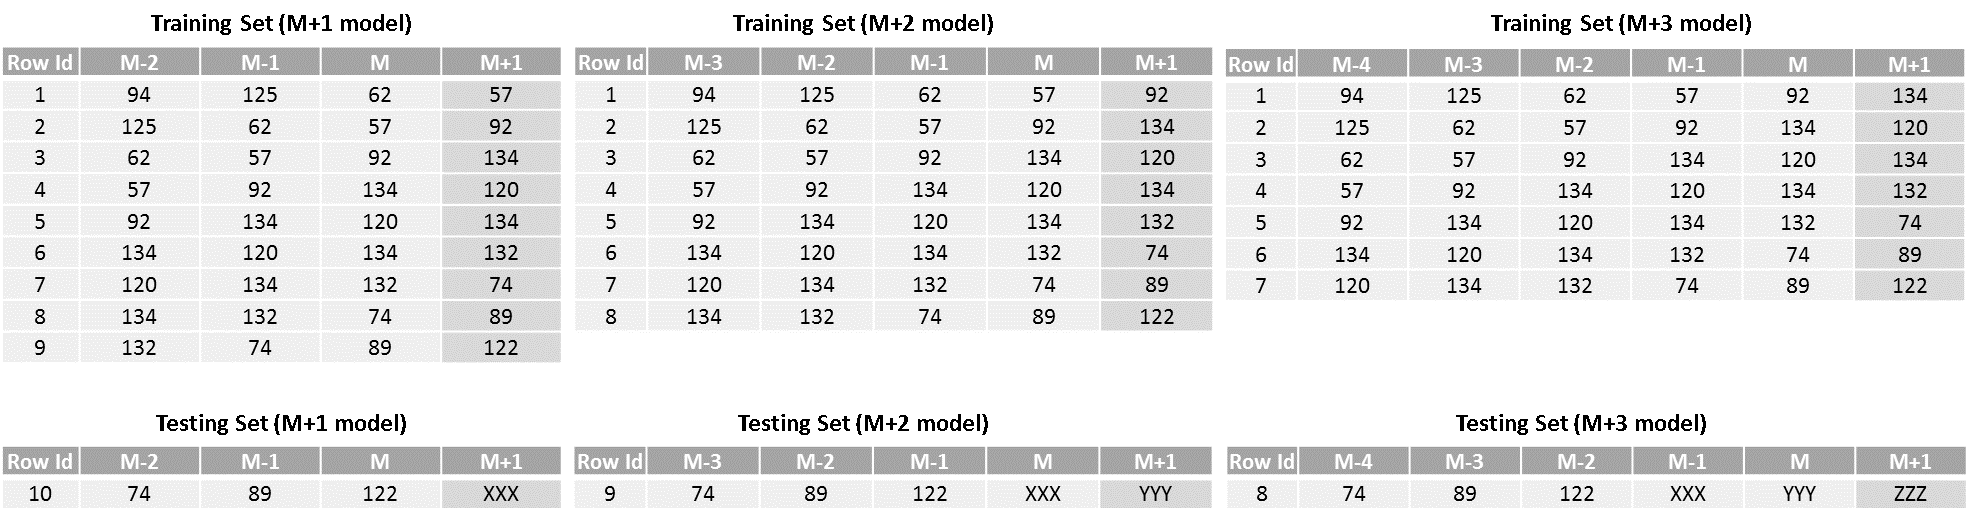

Можно задаться вопросом: что лучше брать при обучении моделей для прогноза на несколько шагов вперед – истинные значения или же предсказания предыдущих моделей? Если брать истинные, то мы можем точнее построить модели прогнозирования, но, с другой стороны, на этапе применения вы будете использовать прогнозы, а они могут иметь другое распределение, чем истинные данные, в частности, могут иметь смещение и большую дисперсию. В таком случае мы получим плохие следующие прогнозы.


Модели для нескольких временных рядов
В реальности очень часто нужно прогнозировать сразу огромное количество временных рядов.
Примеры:
•	Предсказание температуры для различных регионов/городов.
•	Предсказания уровня продаж для различных типов товаров (молоко/яблоки/мясо).
Проблема:
•	модель на каждый временной ряд – слишком много ресурсов и не масштабируемо;
•	мало моделей – плохие предсказания для каждого ряда по отдельности.
Идея: создавать модели не для каждого временного ряда, а для группы временных рядов. Иначе говоря, разделить объекты на категории, и для каждой категории создавать отдельную модель.



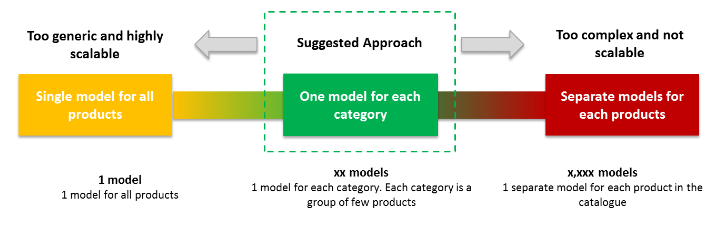

## Оценка качества моделей прогнозирования временного ряда

Для оценки качества моделей прогнозирования временного ряда в основном используются метрики качества регрессии:

- **Средняя квадратичная ошибка (MSE)**:
$$ \text{MSE} = \frac{1}{T - R + 1} \sum_{t=R}^{T} (\hat{y}_t - y_t)^2. $$
где
  - $ T $ — общее количество наблюдений (конечный момент времени).
  - $ R $ — начальный момент времени для оценки модели.
  - $ \hat{y}_t $ — предсказанное значение на момент времени $ t $.
  - $ y_t $ — фактическое (реальное) значение на момент времени $ t $.

- **Средняя абсолютная ошибка (MAE)**:
$$ \text{MAE} = \frac{1}{T - R + 1} \sum_{t=R}^{T} |\hat{y}_t - y_t|. $$

Эти метрики показывают, например, на сколько рублей или на сколько единиц товара мы ошибаемся.

Также могут использоваться:

- **Средняя абсолютная ошибка в процентах (MAPE)**:
$$ \text{MAPE} = \frac{100}{T - R + 1} \sum_{t=R}^{T} \left| \frac{\hat{y}_t - y_t}{y_t} \right|. $$

- **Взвешенная средняя ошибка в процентах (WAPE)**:
$$ \text{WAPE} = 100 \cdot \frac{\sum_{t=R}^{T} |\hat{y}_t - y_t|}{\sum_{t=R}^{T} |y_t|}. $$

Эти метрики достаточно популярны из-за того, что позволяют оценить качество в относительных величинах без зависимости от шкалы измерений.

Другие полезные метрики для оценки качества моделей прогнозирования временных рядов включают:

- **Коэффициент детерминации (R²)**:
$$ R^2 = 1 - \frac{\sum_{t=R}^{T} (y_t - \hat{y}_t)^2}{\sum_{t=R}^{T} (y_t - \bar{y})^2}, $$
где $\bar{y}$ — среднее значение наблюдаемых данных. Эта метрика показывает, какую долю дисперсии зависимой переменной объясняет модель.

- **Корень из средней квадратичной ошибки (RMSE)**:
$$ \text{RMSE} = \sqrt{\text{MSE}}. $$
Эта метрика дает ту же информацию, что и MSE, но в тех же единицах, что и прогнозируемая величина, что может облегчить интерпретацию.

- **Симметричная средняя абсолютная процентная ошибка (sMAPE)**:
$$ \text{sMAPE} = \frac{100\%}{T - R + 1} \sum_{t=R}^{T} \frac{|\hat{y}_t - y_t|}{(|y_t| + |\hat{y}_t|) / 2}. $$
Эта метрика симметрична и не склонна к преувеличению ошибок при малых значениях прогнозируемой величины.

- **Среднеквадратичный логарифмический ошибка (MSLE)**:
$$ \text{MSLE} = \frac{1}{T - R + 1} \sum_{t=R}^{T} (\log(1 + \hat{y}_t) - \log(1 + y_t))^2. $$
Эта метрика полезна, когда нам важны относительные изменения, а не абсолютные ошибки, особенно при прогнозировании временных рядов с экспоненциальным ростом.

Использование различных метрик позволяет получить более полную картину качества прогнозирования и учитывать различные аспекты ошибки модели.


## Схемы кросс-валидации

### Стандартные схемы кросс-валидации

Кросс-валидация – это техника оценки качества модели, разделяющая данные на обучающие и тестовые наборы для проверки её способности обобщать на новые данные. Существуют различные стандартные схемы кросс-валидации, среди которых наиболее распространена K-Fold кросс-валидация.

#### K-Fold кросс-валидация

K-Fold кросс-валидация делит данные на $ K $ равных частей (фолдов). Процесс выглядит следующим образом:

1. Данные делятся на $ K $ частей.
2. Для каждого фолда:
   - Одна часть выбирается как тестовый набор.
   - Оставшиеся $ K-1 $ частей используются для обучения модели.
   - Модель обучается на обучающем наборе и проверяется на тестовом наборе.
3. Процедура повторяется $ K $ раз, каждый раз с новым тестовым набором.
4. Оценка модели вычисляется как среднее значение метрик качества по всем $ K $ фолдам.

**Пример:**

Предположим, у нас есть набор данных из 100 наблюдений, и мы выбрали $ K = 5 $:

- Первая итерация: первые 20 наблюдений тестовые, оставшиеся 80 – обучающие.
- Вторая итерация: вторые 20 наблюдений тестовые, остальные 80 – обучающие.
- Процесс повторяется для всех 5 фолдов.

Эта схема помогает использовать все данные как для обучения, так и для тестирования, что увеличивает надежность оценки модели.

### Кросс-валидация для временных рядов

Кросс-валидация – это метод оценки качества моделей, который позволяет проверять, насколько хорошо модель будет работать на новых данных. Для временных рядов стандартные схемы кросс-валидации, такие как K-Fold, неприменимы, потому что значения во временных рядах зависят друг от друга и не могут перемешиваться без нарушения временной последовательности данных. Чтобы корректно учитывать временную структуру, используются специализированные методы кросс-валидации.

#### Схема 1: Скользящее (Rolling) или Расширяющееся (Expanding) окно

Этот метод заключается в том, что мы постепенно расширяем обучающую выборку, сохраняя при этом временную последовательность данных. Конкретные шаги следующие:

1. Обучаемся на первых $ t $ значениях временного ряда $ y_1, y_2, ..., y_t $, прогнозируем следующие $ \Delta t $ значений ряда $ \hat{y}_{t+1}, \hat{y}_{t+2}, ..., \hat{y}_{t+\Delta t} $.
2. Обучаемся на $ y_1, y_2, ..., y_{t+\Delta t} $, прогнозируем $ \hat{y}_{t+\Delta t+1}, \hat{y}_{t+\Delta т+2}, ..., \hat{y}_{t+2\Delta t} $.
3. Повторяем этот процесс, пока не дойдем до конца временного ряда.
4. На каждой итерации вычисляем ошибки прогноза и усредняем их.

**Пример:**

Предположим, у нас есть временной ряд с 30 значениями, и мы выбираем $ t = 10 $ и $ \Delta t = 5 $.

- Первая итерация: обучаем модель на $ y_1, y_2, ..., y_{10} $, прогнозируем $ \hat{y}_{11}, \hat{y}_{12}, ..., \hat{y}_{15} $.
- Вторая итерация: обучаем модель на $ y_1, y_2, ..., y_{15} $, прогнозируем $ \hat{y}_{16}, \hat{y}_{17}, ..., \hat{y}_{20} $.
- Третья итерация: обучаем модель на $ y_1, y_2, ..., y_{20} $, прогнозируем $ \hat{y}_{21}, \hat{y}_{22}, ..., \hat{y}_{25} $.
- Четвертая итерация: обучаем модель на $ y_1, y_2, ..., y_{25} $, прогнозируем $ \hat{y}_{26}, \hat{y}_{27}, ..., \hat{y}_{30} $.



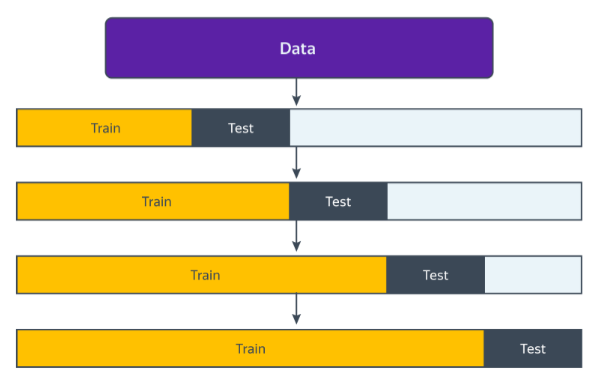

#### Схема 2: Time Series Split (Прогрессивное разбиение)

Этот метод заключается в разбиении временного ряда на несколько неперекрывающихся тренировочных и тестовых наборов. При этом каждый последующий тестовый набор временно следует за предыдущим.

1. Делим временной ряд на $ k $ частей.
2. Обучаемся на первых $ t $ частях и тестируем на $ t+1 $-й части.
3. Обучаемся на первых $ t+1 $ частях и тестируем на $ t+2 $-й части.
4. Повторяем до тех пор, пока не будут использованы все части.

**Пример:**

Предположим, у нас есть временной ряд с 30 значениями, и мы выбираем $ k = 5 $ частей.

- Первая итерация: обучаем модель на первых 6 значениях, тестируем на 7-ю часть.
- Вторая итерация: обучаем модель на первых 12 значениях, тестируем на 13-ю часть.
- Третья итерация: обучаем модель на первых 18 значениях, тестируем на 19-ю часть.
- Четвертая итерация: обучаем модель на первых 24 значениях, тестируем на 25-ю часть.

На каждой итерации мы сохраняем ошибки прогноза, чтобы затем усреднить их и получить общее представление о качестве модели.




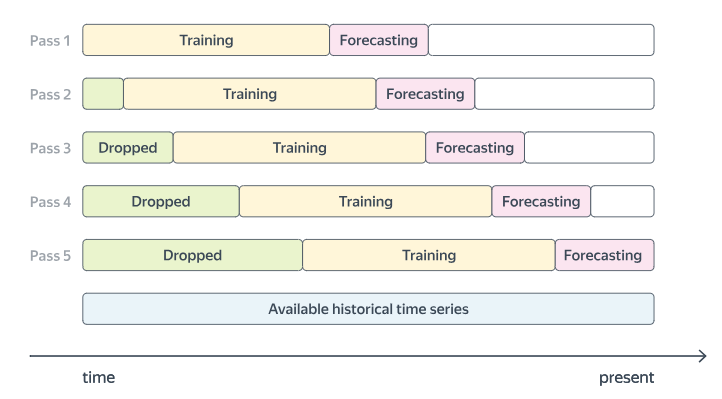

Эти две схемы отличаются только размером обучающего множества. В первом случае он постоянно растет, во втором – не меняется, а само обучающее множество при этом сдвигается. Ту или иную схему на практике стоит использовать в зависимости от того, какая решается задача. Например, если данных достаточно много и предполагается онлайн работа модели с периодическим дообучением, то обычно при каждом дообучении размер обучающего множества фиксируют. В таком случае имеет смысл воспользоваться второй схемой, чтобы оценить качество модели, обученной именно на таким количестве данных. Если же данных немного, то для обучения желательно использовать все доступные данные. В таком случае имеет смысл использовать первую схему.

Обратите внимание, что во всех случаях размер тестового интервала времени фиксирован. Это необходимое условие, потому как распределение значений метрики на разных размерах данных может отличаться. Вспомните, например, про зависимость дисперсии выборочного от размера выборки.

## Резюме: стандартные модели машинного обучения для временных рядов

Стандартные модели машинного обучения (МО) представляют собой основные алгоритмы и методы, которые используются для обработки данных и создания прогностических моделей. Они разработаны для решения различных задач, таких как классификация, регрессия, кластеризация и другие, и находят широкое применение в различных областях, включая финансы, медицину, технологии и другие секторы. Среди стандартных моделей можно выделить линейные модели, деревья решений, метод ближайших соседей, нейронные сети и многие другие, каждая из которых обладает своими уникальными свойствами и применимости в различных контекстах.


#### Преимущества

1. **Использование дополнительной информации**: Стандартные модели машинного обучения для временных рядов легко интегрируют дополнительные экзогенные факторы или признаки, что улучшает качество прогнозов за счет учета внешних переменных.

2. **Множество рядов – множество моделей**: Например, нейронная сеть может иметь несколько выходов, что позволяет ей прогнозировать сразу несколько временных рядов одной моделью. Это особенно полезно для задач, где требуется прогнозирование нескольких взаимозависимых временных рядов, например, продаж различных товаров.

#### Недостатки

1. **Отсутствие прямого построения предсказательных интервалов**: Стандартные модели машинного обучения для временных рядов обычно не предоставляют возможности напрямую строить предсказательные интервалы, что усложняет оценку неопределенности прогнозов.

2. **Возможные проблемы с производительностью**: Иногда эти модели могут показывать худшие результаты по сравнению со стандартными временными рядовыми моделями, такими как ARIMA или экспоненциальное сглаживание, особенно если структура данных не соответствует предполагаемым предпосылкам.

3. **Сложности в обработке признаков**: Обработка признаков может быть более сложной по сравнению с другими моделями, рассматриваемыми далее, из-за особенностей взаимодействия с временной зависимостью данных.

4. **Интерпретация моделей может вызывать затруднения**: Понимание и интерпретация результатов моделей машинного обучения временных рядов может представлять сложности для заказчиков и пользователей из-за их комплексности и специфики подхода.


Декомпозиция временных рядов

Декомпозиция временных рядов — это процесс разделения временного ряда на три основные компоненты:

1. **Тренд $ T_t $** — плавное долгосрочное изменение временного ряда.
2. **Сезонность $ S_t $** — циклические изменения временного ряда с постоянным периодом сезонности $ s $.
3. **Ошибка $ R_t $** — непрогнозируемая случайная компонента ряда.

### Аддитивная и мультипликативная декомпозиция

Ряд может быть представлен в форме аддитивной декомпозиции:
$$ y_t = T_t + S_t + R_t $$
или в форме мультипликативной декомпозиции:
$$ y_t = T_t \times S_t \times R_t $$

Для построения мультипликативного разложения достаточно выполнить аддитивную декомпозицию для ряда $ \log y_t $.

### Декомпозиция на основе скользящего среднего

Пусть $ s $ — известный период сезонности.

1. **Тренд $ T_t $** вычисляется с помощью скользящего среднего длиной $ s $:
  $$ T_t = \frac{1}{s} \sum_{i=t-s/2}^{t+s/2} y_i $$

2. **Сезонность $ S_t $**:
   - Вычитаем тренд: $ y_t := y_t - T_t $
   - Формируем $ s $ подгрупп $ G_i = (y_i, y_{i+s}, \ldots, y_{i+(k-1)s}) $
   - Сезонность $ S_i $ вычисляется как усреднение по $ i $-й группе: $ S_i = \text{mean}(G_i) $

3. **Ошибка $ R_t $**:
  $$ R_t = y_t - T_t - S_i $$

### STL-декомпозиция

STL (Seasonal-Trend decomposition using LOESS) — это более продвинутый метод декомпозиции временных рядов.

Принцип работы:
- Инициализация тренда: $ T_0 = 0 $
- В цикле до сходимости:
  - Вычитаем текущее значение тренда: $ y_t := y_t - T_k $
  - Формируем $ s $ подгрупп $ G_i = (y_i, y_{i+s}, \ldots, y_{i+(k-1)s}) $
  - Используем LOESS для предсказания сезонности $ S_t $ в каждой группе $ G_i $
  - Вычитаем сезонность: $ y_t := y_t - S_t $
  - Используем LOESS для предсказания нового значения тренда $ T_{k+1} $

Преимущества STL-декомпозиции:
- Большее количество настраиваемых параметров, что позволяет модели лучше подстраиваться под разнообразные данные.
- Устойчивость к изменениям в сезонной компоненте со временем, что может контролироваться пользователем.
- Возможность устойчивости к выбросам.

Эти методы декомпозиции помогают анализировать временные ряды, выделять тренды и сезонные колебания, что важно для прогнозирования и выявления структурных изменений в данных.

Декомпозиция временных рядов необходима по нескольким причинам:

1. **Выделение тренда и сезонных колебаний**: Декомпозиция позволяет выявить основные составляющие временного ряда — тренд (долгосрочное изменение) и сезонность (циклические изменения с постоянным периодом). Это важно для понимания основных тенденций и цикличности данных.

2. **Улучшение прогнозов**: После выделения тренда и сезонности можно лучше прогнозировать будущие значения временного ряда. Изолирование этих компонент позволяет более точно оценивать и предсказывать тенденции и циклы.

3. **Анализ и управление**: Декомпозиция помогает анализировать изменения в данных и управлять ими. Например, если тренд меняется со временем или сезонная компонента подвержена изменениям, можно выявить эти изменения и адаптировать стратегии управления.

4. **Удаление шума и аномалий**: Выделение ошибки (остатков) в декомпозиции помогает отфильтровать случайные колебания и выбросы из данных, что может быть полезно при анализе и моделировании.

Таким образом, декомпозиция временных рядов является важным этапом в анализе данных, который помогает понять структуру временных изменений, улучшить прогнозы и принимать информированные управленческие решения на основе данных.

Конкретные примеры тренда, сезонности и ошибки могут быть приведены на основе искусственно созданного временного ряда. Давайте рассмотрим следующий пример:

Предположим, у нас есть временной ряд, который можно описать следующим образом:

$$ y_t = T_t + S_t + R_t, $$

где

- **Тренд $ T_t $** представляет собой линейный рост с добавлением шума:
 $$ T_t = 2t + 10 + \epsilon_t, $$
  где $ \epsilon_t $ - случайная ошибка, например, нормально распределенная с нулевым средним и заданной дисперсией.

- **Сезонность $ S_t $** моделируется как гармоническая функция с периодом 12 (месячная сезонность):
 $$ S_t = 5 \sin\left( \frac{2\pi t}{12} \right). $$

- **Ошибка $ R_t $** - случайная составляющая с нулевым средним:
 $$ R_t = \epsilon'_t, $$
  где $ \epsilon'_t $ также может быть нормально распределенной ошибкой.

### Пример временного ряда

Давайте создадим временной ряд, объединяющий эти компоненты:

1. **Тренд $ T_t $**:
  $$ T_t = 2t + 10 + \epsilon_t, $$
   где $ \epsilon_t \sim \mathcal{N}(0, 1) $.

2. **Сезонность $ S_t $**:
  $$ S_t = 5 \sin\left( \frac{2\pi t}{12} \right). $$

3. **Ошибка $ R_t $**:
  $$ R_t = \epsilon'_t, $$
   где $ \epsilon'_t \sim \mathcal{N}(0, 0.5) $.

Теперь объединим эти компоненты, чтобы сформировать временной ряд $ y_t $:
$$ y_t = T_t + S_t + R_t. $$

### Числовой пример

Пусть $ t = 1, 2, \ldots, 36 $ (36 месяцев).

- Для тренда $ T_t $:
  При $ t = 1 $:
 $$ T_1 = 2 \cdot 1 + 10 + \epsilon_1 = 12 + \epsilon_1, $$
  где $ \epsilon_1 $ - случайная ошибка.

  При $ t = 2 $:
 $$ T_2 = 2 \cdot 2 + 10 + \epsilon_2 = 14 + \epsilon_2, $$
  и так далее.

- Для сезонности $ S_t $:
  При $ t = 1 $:
 $$ S_1 = 5 \sin\left( \frac{2\pi \cdot 1}{12} \right) = 5 \sin\left( \frac{\pi}{6} \right) \approx 2.5. $$

  При $ t = 2 $:
 $$ S_2 = 5 \sin\left( \frac{2\pi \cdot 2}{12} \right) = 5 \sin\left( \frac{\pi}{3} \right) \approx 4.33. $$

- Для ошибки $ R_t $:
  При $ t = 1 $:
 $$ R_1 = \epsilon'_1, $$
  где $ \epsilon'_1 \sim \mathcal{N}(0, 0.5) $.

  При $ t = 2 $:
 $$ R_2 = \epsilon'_2, $$
  где $ \epsilon'_2 \sim \mathcal{N}(0, 0.5) $.

### Временной ряд $ y_t $

Теперь временной ряд $ y_t $ можно получить как:
$$ y_t = T_t + S_t + R_t. $$

Например, при $ t = 1 $:
$$ y_1 = T_1 + S_1 + R_1 = (12 + \epsilon_1) + 2.5 + \epsilon'_1. $$

При $ t = 2 $:
$$ y_2 = T_2 + S_2 + R_2 = (14 + \epsilon_2) + 4.33 + \epsilon'_2. $$

Это пример искусственного временного ряда, демонстрирующий компоненты тренда, сезонности и ошибки. Такие модели помогают лучше понять процессы декомпозиции временных рядов и их применение в прогнозировании и анализе данных.

Давайте реализуем пример на Python, чтобы сгенерировать временной ряд с трендом, сезонностью и ошибкой. Для этого мы будем использовать библиотеки numpy для генерации данных и matplotlib для визуализации.



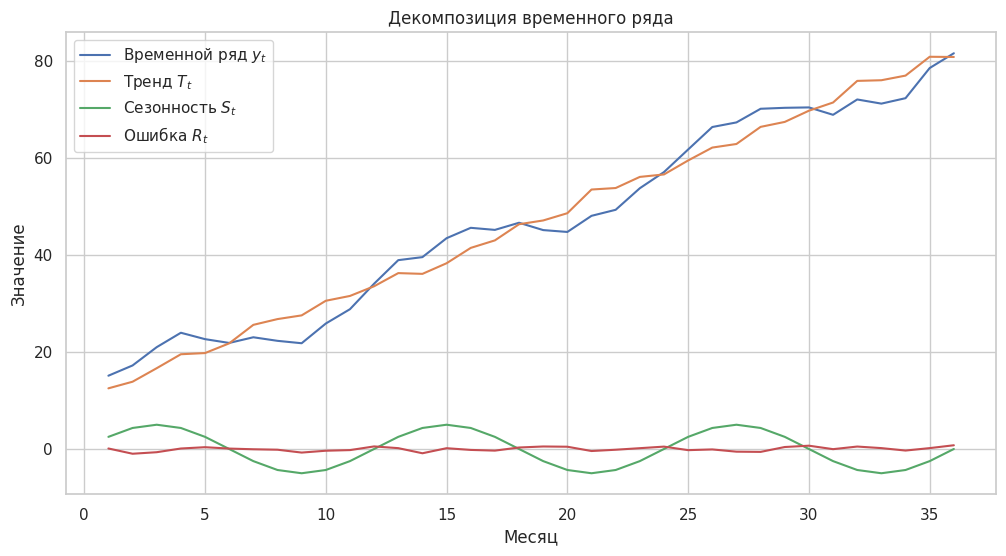

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Установим seed для воспроизводимости результатов
np.random.seed(42)

# Число точек в ряде (36 месяцев)
n = 36

# Временной индекс
t = np.arange(1, n + 1)

# Генерация тренда T_t: линейный тренд с добавлением случайной ошибки
epsilon_t = np.random.normal(0, 1, n)  # случайная ошибка для тренда
T_t = 2 * t + 10 + epsilon_t

# Генерация сезонности S_t: гармоническая функция с периодом 12 (месяцев)
S_t = 5 * np.sin(2 * np.pi * t / 12)

# Генерация ошибки R_t: случайная ошибка
epsilon_prime_t = np.random.normal(0, 0.5, n)  # случайная ошибка для ошибки
R_t = epsilon_prime_t

# Генерация временного ряда y_t
y_t = T_t + S_t + R_t

# Визуализация временного ряда и его компонент декомпозиции
plt.figure(figsize=(12, 6))
plt.plot(t, y_t, label='Временной ряд $y_t$')
plt.plot(t, T_t, label='Тренд $T_t$')
plt.plot(t, S_t, label='Сезонность $S_t$')
plt.plot(t, R_t, label='Ошибка $R_t$')
plt.xlabel('Месяц')
plt.ylabel('Значение')
plt.title('Декомпозиция временного ряда')
plt.legend()
plt.grid(True)
plt.show()

Давайте рассмотрим конкретного примера. Для реализации декомпозиции временного ряда ежемесячных продаж антидиабетических лекарств в Австралии с июля 1991 по июнь 2008 года мы будем использовать Python с библиотеками pandas, matplotlib и statsmodels.

Прежде всего, давайте загрузим данные и построим график временного ряда:

In [ ]:
#Basic importation
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rc('xtick', labelsize=40)
matplotlib.rc('ytick', labelsize=40)
from statsmodels.tsa.seasonal import seasonal_decompose

import seaborn as sns
sns.set(style="whitegrid", color_codes=True)
%matplotlib inline
df= pd.read_csv('/content/AusAntidiabeticDrug.csv')

df['ds'] = pd.to_datetime(df['ds'])

# Установка даты как индексом (опционально, в зависимости от ваших предпочтений)
df.set_index('ds', inplace=True)

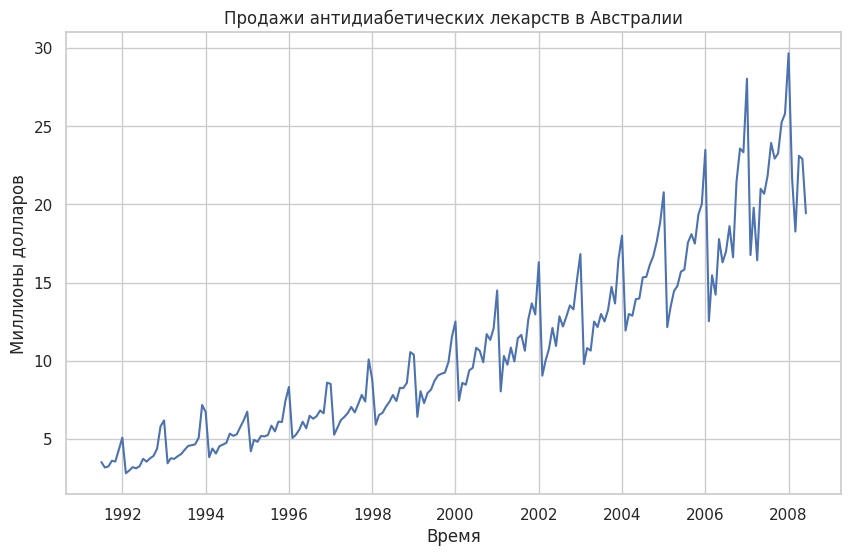

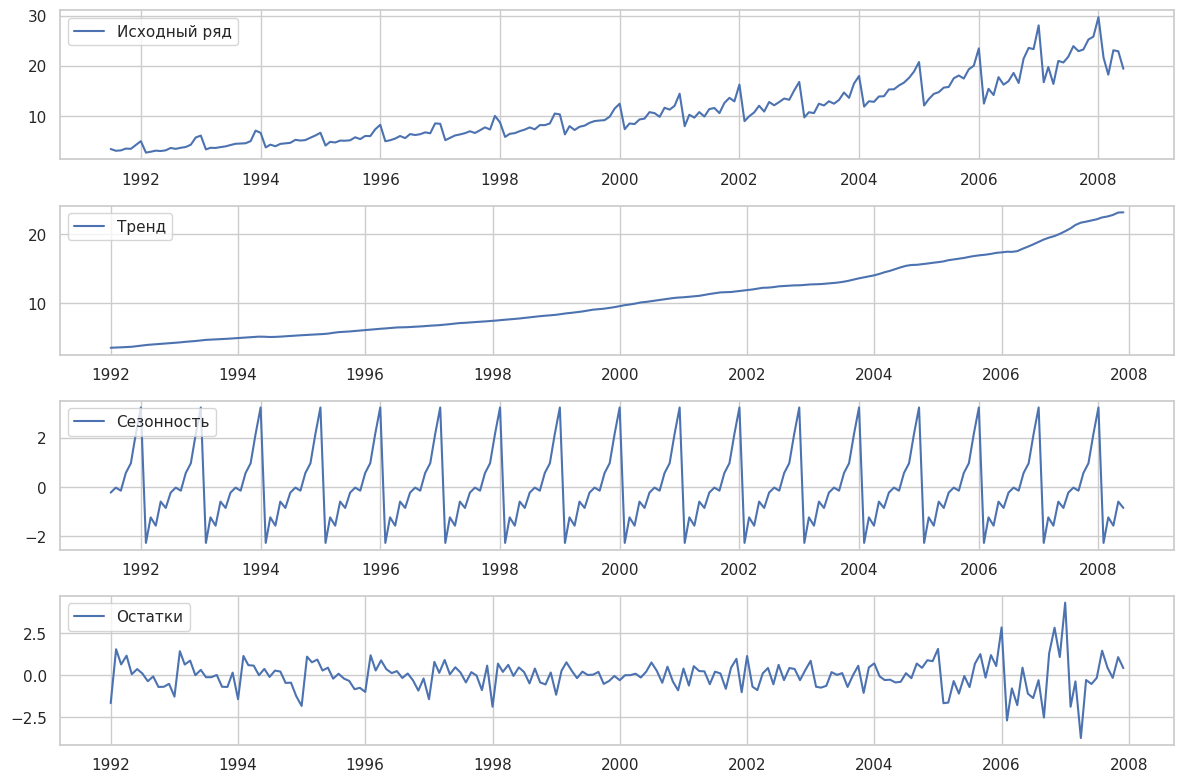

In [ ]:
# Построение графика временного ряда
plt.figure(figsize=(10, 6))
plt.plot(df['y'])
plt.title('Продажи антидиабетических лекарств в Австралии')
plt.xlabel('Время')
plt.ylabel('Миллионы долларов')
plt.grid(True)
plt.show()

# Аддитивная декомпозиция
result_add = seasonal_decompose(df['y'], model='additive', period=12)  # Период сезонности = 12 для ежемесячных данных

# Построение результатов декомпозиции
plt.figure(figsize=(12, 8))

plt.subplot(411)
plt.plot(df['y'], label='Исходный ряд')
plt.legend(loc='upper left')

plt.subplot(412)
plt.plot(result_add.trend, label='Тренд')
plt.legend(loc='upper left')

plt.subplot(413)
plt.plot(result_add.seasonal, label='Сезонность')
plt.legend(loc='upper left')

plt.subplot(414)
plt.plot(result_add.resid, label='Остатки')
plt.legend(loc='upper left')

plt.tight_layout()
plt.show()

Мультипликативная декомпозиция

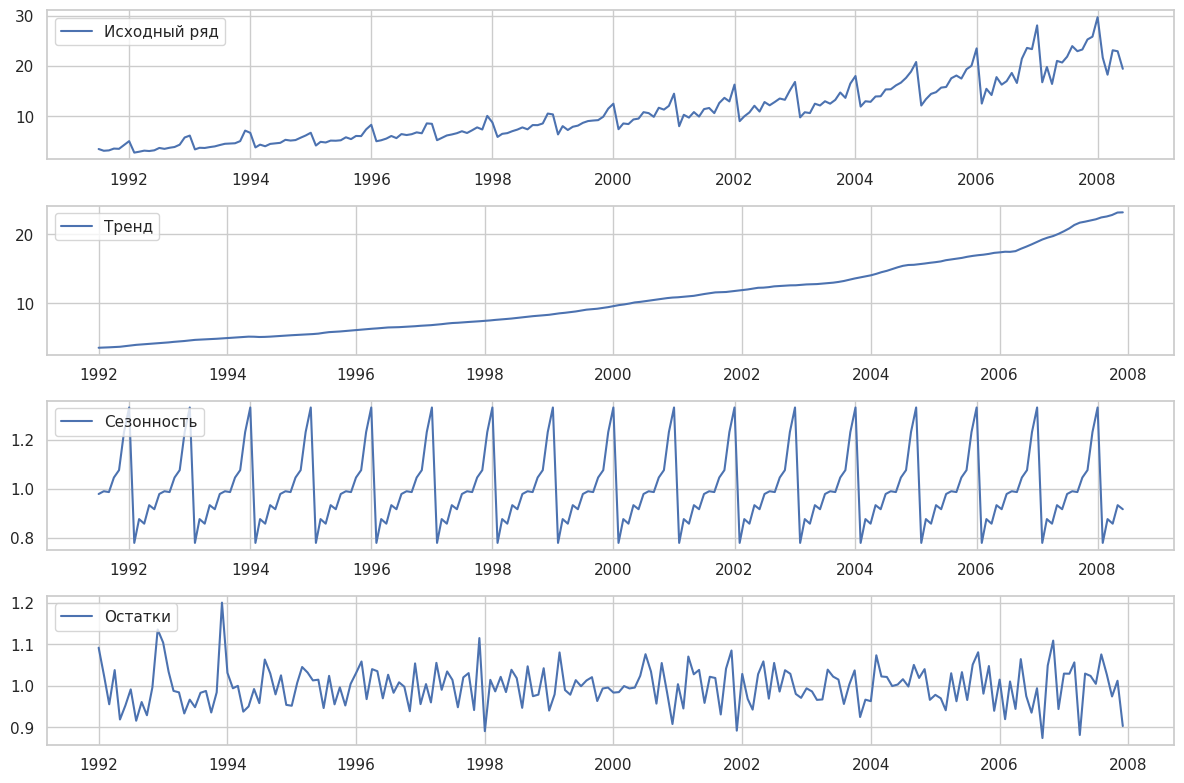

In [ ]:
# Мультипликативная декомпозиция
result_mul = seasonal_decompose(df['y'], model='multiplicative', period=12)  # Период сезонности = 12 для ежемесячных данных

# Построение результатов декомпозиции
plt.figure(figsize=(12, 8))

plt.subplot(411)
plt.plot(df['y'], label='Исходный ряд')
plt.legend(loc='upper left')

plt.subplot(412)
plt.plot(result_mul.trend, label='Тренд')
plt.legend(loc='upper left')

plt.subplot(413)
plt.plot(result_mul.seasonal, label='Сезонность')
plt.legend(loc='upper left')

plt.subplot(414)
plt.plot(result_mul.resid, label='Остатки')
plt.legend(loc='upper left')

plt.tight_layout()
plt.show()

Декомпозиция временных рядов полезна в различных ситуациях и для разных типов моделей прогнозирования. Вот основные случаи, когда она может быть полезна:

1. **Анализ и визуализация данных:**
   - Декомпозиция помогает понять структуру временного ряда, выделяя тренды, сезонные колебания и ошибки. Это особенно важно при первичном анализе данных для исследования и понимания долгосрочных и краткосрочных изменений.

2. **Прогнозирование с помощью классических методов:**
   - **ARIMA (Autoregressive Integrated Moving Average)**: Для применения ARIMA часто необходимо, чтобы временной ряд был стационарным. Декомпозиция помогает выделить тренд и сезонность, которые могут быть учтены в модели ARIMA в виде дополнительных регрессионных переменных или используемы для подбора параметров модели.
   - **Exponential Smoothing**: Для моделей экспоненциального сглаживания также важно учитывать тренд и сезонность временного ряда. Декомпозиция помогает в этом и может служить основой для выбора типа и параметров сглаживания.

3. **Прогнозирование с помощью машинного обучения:**
   - **Регрессионные модели**: Декомпозиция временных рядов позволяет использовать выделенные компоненты (тренд и сезонность) как предикторы в регрессионных моделях, улучшая их точность прогнозирования.
   - **Нейронные сети**: Декомпозиция может быть использована для предварительной обработки данных перед обучением нейронных сетей, что помогает улучшить их способность к обнаружению и использованию временных паттернов.

4. **Управление и планирование:**
   - В бизнесе декомпозиция временных рядов помогает лучше понять и прогнозировать спрос, что полезно для оптимизации запасов, планирования производства и управления ресурсами.

Таким образом, декомпозиция временных рядов является важным инструментом как для анализа данных, так и для различных моделей прогнозирования, обеспечивая лучшее понимание и учет временных паттернов и структурных изменений данных.

Пример кода для удаления тренда и сезонности отдельно

<ipython-input-23-ca0daf49b85b>:19: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  df['time'] = pd.date_range(start='2010-01-01', periods=n, freq='M')


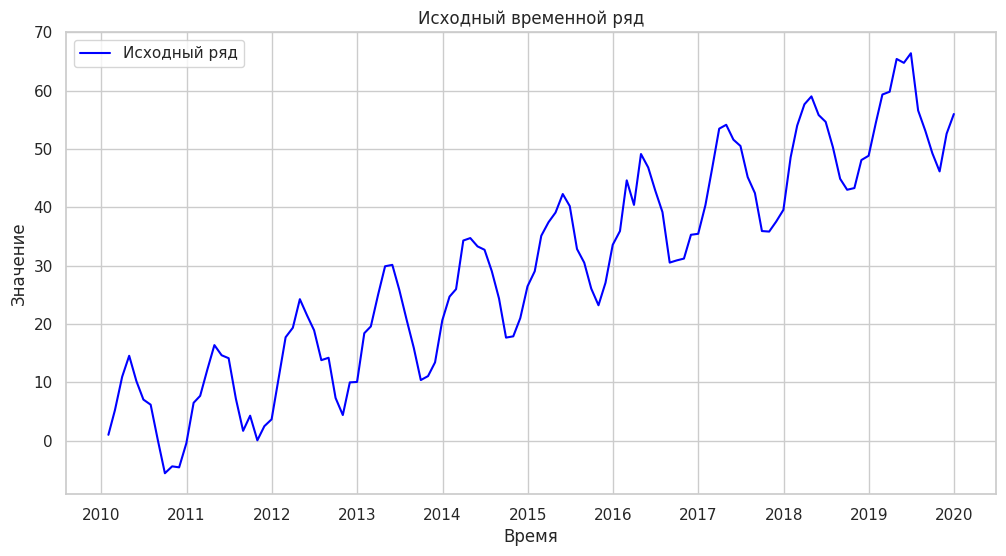

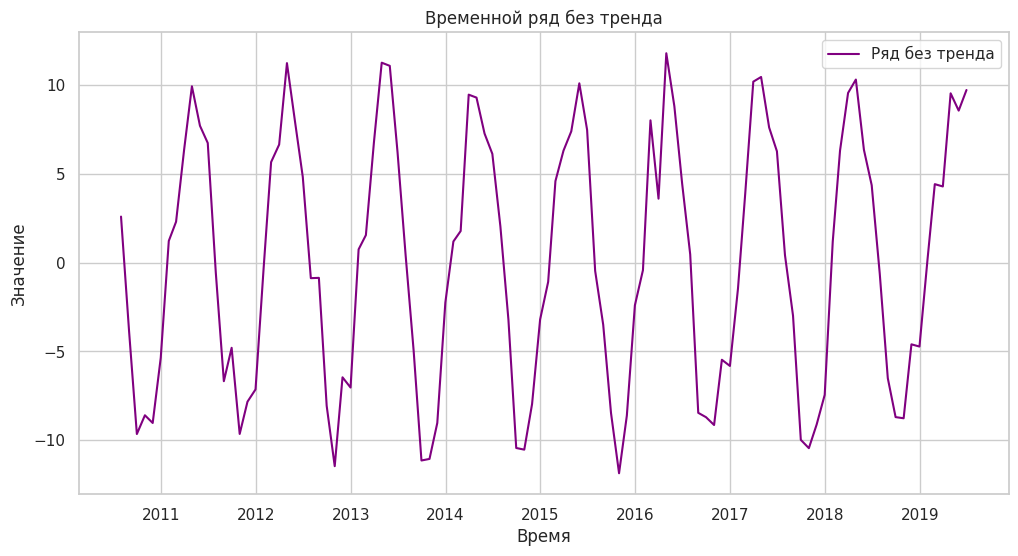

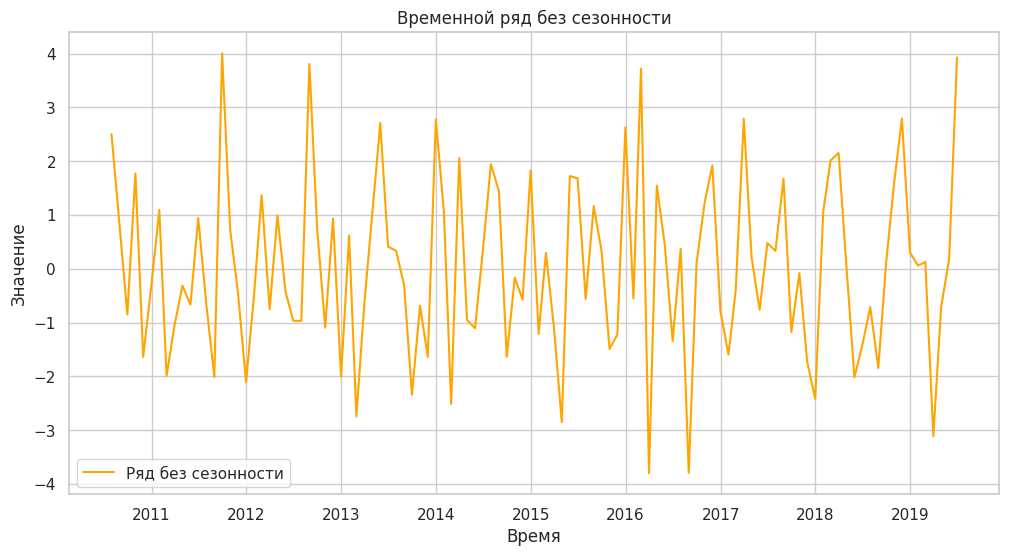

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

# Установка случайного семени для воспроизводимости
np.random.seed(42)

# Генерация временного ряда
n = 120  # количество точек данных (10 лет с ежемесячными данными)
time = np.arange(n)
trend = time * 0.5  # линейный тренд
seasonal = 10 * np.sin(2 * np.pi * time / 12)  # сезонность (синусоида)
noise = np.random.normal(loc=0, scale=2, size=n)  # случайный шум
data = trend + seasonal + noise  # объединение всех компонентов

# Создание DataFrame
df = pd.DataFrame(data, columns=['y'])
df['time'] = pd.date_range(start='2010-01-01', periods=n, freq='M')

# Визуализация исходного временного ряда
plt.figure(figsize=(12, 6))
plt.plot(df['time'], df['y'], label='Исходный ряд', color='blue')
plt.title('Исходный временной ряд')
plt.xlabel('Время')
plt.ylabel('Значение')
plt.legend()
plt.grid(True)
plt.show()

# Аддитивная декомпозиция
result_add = seasonal_decompose(df['y'], model='additive', period=12)

# Удаление тренда
detrended = df['y'] - result_add.trend

# Удаление NaN
detrended = detrended.dropna()

# Визуализация ряда без тренда
plt.figure(figsize=(12, 6))
plt.plot(df['time'][result_add.trend.notna()], detrended, label='Ряд без тренда', color='purple')
plt.title('Временной ряд без тренда')
plt.xlabel('Время')
plt.ylabel('Значение')
plt.legend()
plt.grid(True)
plt.show()

# Удаление сезонности из ряда без тренда
result_add_detrended = seasonal_decompose(detrended, model='additive', period=12)

# Удаление сезонности
deseasonalized = detrended - result_add_detrended.seasonal

# Удаление NaN
deseasonalized = deseasonalized.dropna()

# Визуализация ряда без сезонности
plt.figure(figsize=(12, 6))
plt.plot(df['time'][result_add.trend.notna()], deseasonalized, label='Ряд без сезонности', color='orange')
plt.title('Временной ряд без сезонности')
plt.xlabel('Время')
plt.ylabel('Значение')
plt.legend()
plt.grid(True)
plt.show()

Удаление тренда и сезонности из временного ряда позволяет выделить остаточную компоненту, которая содержит информацию о случайных колебаниях и аномалиях. Вот основные аспекты, касающиеся удаления этих компонентов:

### Что мы получаем при удалении тренда и сезонности?

1. **Остаточный ряд**:
   - После удаления тренда и сезонности остается остаточный ряд, который показывает только случайные колебания и шум. Это может помочь выявить аномалии или необычные события в данных.

2. **Упрощение анализа**:
   - Удаление этих компонентов позволяет сосредоточиться на случайных изменениях, что может быть полезно для некоторых типов анализа, таких как обнаружение аномалий или прогнозирование.

3. **Лучшая интерпретация**:
   - Остаточный ряд может быть легче интерпретировать, поскольку он не искажен долгосрочными трендами или сезонными колебаниями.

### Плюсы удаления тренда и сезонности:

- **Выявление аномалий**: Остаточный ряд может помочь в обнаружении аномалий, которые могут быть скрыты под трендами и сезонностью.
- **Упрощение моделей**: Модели, работающие с остатками, могут быть проще и эффективнее, особенно если данные имеют сложные сезонные или трендовые компоненты.
- **Фокус на случайных колебаниях**: Удаление этих компонентов позволяет лучше понять случайные колебания в данных.

### Минусы удаления тренда и сезонности:

- **Потеря информации**: Удаление тренда и сезонности может привести к потере важной информации о долгосрочных изменениях и повторяющихся паттернах в данных.
- **Сложность в интерпретации**: Остаточный ряд может быть сложнее интерпретировать, особенно если в нем присутствует много шума.
- **Не всегда необходимо**: В некоторых случаях анализ временного ряда с трендом и сезонностью может быть более информативным, особенно если эти компоненты имеют значение для бизнес-решений или прогнозирования.

### Заключение:

Удаление тренда и сезонности — это полезный инструмент в анализе временных рядов, но его использование должно быть обосновано. Важно учитывать контекст данных и цели анализа. Если цель — выявление аномалий или случайных колебаний, то удаление может быть оправдано. Однако если тренды и сезонные компоненты важны для понимания данных, то их лучше оставить.